# **FINAL PROJECT**
TEAM BETA:
- Salsa
- Arief
- Rakha

## **Hotel Reservation Order: Analisis Pembatalan Booking City Hotel & Resort Hotel**


Dataset *Hotel Booking Demand*: 119.390 booking untuk kedatangan Juli 2015 sampai Agustus 2017.

---

## **Daftar Isi**
- Background Story (dengan Ringkasan Eksekutif)
1. Import Library & Data
2. Data Understanding
3. Data Cleaning
4. EDA: Exploratory Data Analysis
5. Insight & Recommendation
- Simulasi Dampak (dengan Peta Peluang dan Kartu Target per Hotel)
- Export Data untuk Dashboard
- Batasan Analisis
- Pertanyaan yang Mungkin Muncul
- Referensi

## **Background Story**

Dua hotel di Portugal, City Hotel (Lisbon) dan Resort Hotel (Algarve), mencatat 119.390 booking untuk kedatangan Juli 2015 sampai Agustus 2017. Datanya berumur sekitar sembilan tahun, jadi angka di notebook ini menggambarkan pola, bukan kondisi hotel hari ini. Di data mentah, **37% booking tercatat batal**. Setiap pembatalan membuat kamar yang sudah terjual kembali kosong, dan semakin mepet pembatalannya, semakin sedikit waktu untuk menjual kamar itu lagi.

Hotel tidak bisa melarang tamu membatalkan, tetapi hotel bisa mengatur siapa yang mendapat kebijakan pembatalan longgar, berapa kamar yang aman di-*overbook*, dan channel mana yang layak dipertahankan. Semua keputusan itu butuh pola pembatalan per segmen, channel, dan waktu, dan polanya diukur dengan revenue, karena booking yang batal tidak sama nilainya.

**Stakeholder**
- **Primary decision-maker: Revenue Manager** kedua hotel. Revenue Manager menentukan harga (ADR), kebijakan deposit dan pembatalan, batas overbooking, serta porsi kamar yang dijual lewat tiap channel. Semua keputusan itu bergantung langsung pada pola pembatalan.
- **Pihak yang perlu diajak koordinasi:** Reservation Manager (konfirmasi booking sebelum kedatangan), Sales & Distribution (kontrak dengan agent dan perusahaan), Marketing (program tamu repeat dan promosi per negara), dan IT/Data (pencatatan data booking).

**Problem statement**

Segmen booking dan periode kedatangan mana yang perlu kebijakan deposit, pembatalan, dan overbooking yang berbeda, agar revenue yang hilang karena pembatalan bisa ditekan?

Saat ini kebijakan tersebut berlaku seragam untuk semua booking (98,7% booking tanpa deposit), padahal risiko pembatalan sangat berbeda antarsegmen, channel, agent, dan waktu.

**Pertanyaan dan jawaban dari analisis**

Bagian yang menjawab ada di dalam tanda kurung

- A. Seberapa besar kerugian akibat pembatalan, kapan pembatalan terjadi, dan apakah makin parah? (4.B)
- B. Booking seperti apa yang batal, setelah variabel perancu dikontrol? (4.C) 
- C. Kolom mana yang tidak valid untuk menjelaskan pembatalan? (4.D)
- D. Kapan volume dan pembatalan naik atau turun, apa pendorongnya, bagaimana efek libur, dan berapa kamar yang hilang menjelang kedatangan? (4.E)
- E. Di agent dan segmen mana kerugian menumpuk, dan kelompok mana yang menjadi sasaran kebijakan? (4.F)
- F. Segmen mana yang paling bernilai setelah dikurangi pembatalan? (4.G)
- G. Sebelum kebijakan disusun: siapa yang akan terkena, segmen mana yang harus dijaga, kapan hotel penuh atau kosong, berapa kamar batal yang masih bisa dijual ulang, dan bagaimana harga terbentuk? (4.I)
- H. Kapan dan dari siapa pemasukan datang: bagaimana pola rata-rata, tertinggi, dan terendah per malam, bulan, segmen, dan tipe kamar di tiap hotel? (dari mentoring) (4.J)
- I. Kelompok tamu mana (negara, segmen, agent, dan lainnya) yang besar, bernilai, dan tumbuh, apa kebiasaan tiap segmen dan negara, dan kapan bulan serta tanggal teramai tiap hotel? (4.L)
- J. Agent dan perusahaan mana yang paling bernilai, masih aktif, dan menanggung revenue hilang? (4.M)
- K. Apakah selisih yang menjadi dasar rekomendasi (cancel rate segmen risiko tinggi, revenue masuk per booking Direct vs Online TA) bisa terjadi karena kebetulan? (4.N)

**Metode yang digunakan:** analisis memakai pandas, numpy, matplotlib, seaborn, dan scipy. Ukuran utama tiap variabel adalah revenue loss rate (revenue hilang ÷ potensi revenue kelompok itu), dengan cancel rate sebagai pembanding. Hubungan antarvariabel kategori dianalisis dengan crosstab dan pivot table. Uji ANOVA satu arah (f_oneway) dipakai di 3.G untuk mengecek apakah harga tiap jenis kamar berbeda sebelum disederhanakan menjadi tier. Peringkat kelompok tamu di 4.L memakai adaptasi LRFM (Modul D22) dengan skor berbasis aturan, dan 4.M memakai RFM per agent dan per perusahaan. Di 4.N, selisih yang menjadi dasar rekomendasi diuji dengan confidence interval untuk proporsi (D11) dan Welch t-test (ttest_ind, D12).

### **Ringkasan eksekutif**

**Jawaban singkat.** Kebijakan deposit, pembatalan, dan overbooking perlu dibedakan untuk tiga kelompok: booking Online TA yang dibuat lebih dari 90 hari sebelum kedatangan, agent 9 (City) dan 240 (Resort), dan malam yang diperkirakan penuh. Booking lain tetap memakai kebijakan fleksibel

| Temuan | City Hotel | Resort Hotel | Bagian |
|---|---|---|---|
| Revenue hilang karena batal (26 bulan) | €6,42 juta (34,2% potensi revenue) | €4,82 juta (30,7%) | 4.B.1 |
| Porsi revenue hilang hotel dari segmen risiko tinggi (Online TA, lead time > 90 hari) | 40,0% | 48,0% | 4.F.2 |
| Cancel rate segmen risiko vs booking lain (95% CI segmen risiko) | 44,7% (43,8-45,6%) vs 25,7% | 49,8% (48,5-51,1%) vs 18,0% | 4.N.1 |
| Agent dengan revenue hilang terbesar | Agent 9: €5,13 juta, revenue loss rate 44,1% | Agent 240: €3,25 juta, 48,1% | 4.F.1 |
| Kamar batal yang jatuh di malam yang masih kosong | €2,81 juta | €1,31 juta | 4.I.4 |
| Segmen yang dijaga | Direct: €44,6 per booking di atas Online TA (95% CI €36,8-€52,5) | Offline TA/TO €441,6 per booking, Direct €92,4 di atas Online TA (95% CI €77,9-€106,8) | 4.I.2, 4.N.2 |
| Malam penuh untuk buffer overbooking | 33 malam, terutama Juli-Agustus, sekitar 10 kamar hilang di 7 hari terakhir | 121 malam, Mei-September, sekitar 5 kamar | 4.I.4 |
| RevPAR proxy (batas atas) dan RevPAR gap jual ulang | €70,8, gap €16,4 per kamar tersedia per malam | €73,6, gap €9,0 | 4.I.4 |

**Tiga tindakan dengan sasaran terbesar** (bagian 5, kartu target per hotel): deposit ringan untuk segmen risiko tinggi dan booking lebih dari 7 malam (rekomendasi 1), laporan *pickup* harian dan penjualan ulang kamar yang dilepas (rekomendasi 2), serta syarat pembatalan khusus untuk agent 9 dan 240 (rekomendasi 3). Kalau 10% berhasil, deposit menyelamatkan sekitar €225 ribu per tahun dan penjualan ulang sekitar €190 ribu per tahun. Sasarannya sebagian tumpang tindih, jadi kedua angka tidak dijumlahkan (Simulasi). Urutan pelaksanaannya ada di tabel KPI bagian 5

**Cara membaca notebook.** Analisis disusun dalam enam babak: konteks dan data, masalah dan penyebab, waktu, sasaran dan nilai, pemasukan dan kelompok, lalu bukti dan keputusan. Setiap babak diawali kotak pendek yang menyebut bagian 4.A-4.N mana saja yang termasuk di dalamnya

> **Babak 1 dari 6: Konteks dan data** (bagian 1-3 dan 4.A)
>
> Data disiapkan dan dibersihkan, lalu tamu dan booking kedua hotel dikenali satu kolom demi satu kolom. Hasilnya menjadi pembanding untuk semua babak berikutnya

## **1. Import Library & Data**
Sebelum melakukan keseluruhan proses, import library dan dataset yang dibutuhkan terlebih dahulu.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from scipy.stats import f_oneway, ttest_ind
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 40)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['axes.titleweight'] = 'bold'

In [2]:
# Path relatif dari folder notebook (output/AI) ke folder Dataset
df_raw = pd.read_csv('../../Dataset/hotel_bookings.csv')
df_raw.shape

(119390, 32)

Dataset ini berisi **119.390 Baris dan 32 Kolom.**

Warna dibuat konsisten di semua grafik: City Hotel selalu biru, Resort Hotel selalu oranye, abu-abu untuk data pembanding, dan merah hanya untuk menyorot poin utama.

In [3]:
WARNA_HOTEL = {'City Hotel': '#2E5EAA', 'Resort Hotel': '#E08E45'}
ABU   = '#BFBFBF'   # warna netral
SOROT = '#C0392B'   # warna sorotan untuk poin utama

## **2. Data Understanding**
Tujuan: mengenal isi dataset sebelum mengubah apa pun, lalu mengklasifikasikan tiap kolom supaya statistik dan grafik yang dipakai sesuai dengan tipenya.

### **A. Data profiling**
.info() untuk tipe data dan jumlah non-null, .head() untuk contoh isi, .describe() untuk ringkasan statistik kolom numerik dan kategori.

In [4]:
# Tampilkan df_raw.info(): tipe data dan jumlah non-null tiap kolom
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

.head() untuk menunjukkan 5 baris pertama.

In [5]:
df_raw.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


Setelah itu kita lihat secara ringkas statistik kolom numerik dan object

In [6]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


In [7]:
df_raw.describe(include='object').T

,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


- Ada **20 kolom numerik** dan **12 kolom object**.
- children, country, agent, dan company punya nilai kosong (dibahas di 3.C).
- adr punya nilai minimum **-6,38** dan maksimum **5.400**. Harga negatif tidak mungkin, dan 5.400 jauh di atas nilai lain (dibahas di 3.F).
- adults minimum 0, jadi perlu dicek apakah ada booking dengan total tamu 0.
- agent dan company tersimpan sebagai angka, padahal isinya ID. Rata-rata kedua kolom itu tidak punya makna.
- reservation_status_date masih bertipe object dan perlu diubah ke datetime.
- lead_time dan adr punya mean jauh di atas median, artinya distribusinya miring ke kanan.

### **B. Kamus data**
 Sumber penjelasan dari kolom: Antonio, Almeida & Nunes (2019), *Hotel booking demand datasets*, Data in Brief 22.

| Kolom | Penjelasan | 
|---|---|
| hotel | Jenis hotel (City / Resort) |
| is_canceled | 1 = booking batal, 0 = tidak |
| lead_time | Jumlah hari antara booking dibuat dan tanggal kedatangan |
| arrival_date_year | Tahun kedatangan |
| arrival_date_month | Bulan kedatangan |
| arrival_date_week_number | Minggu ke- dalam tahun (penomorannya tidak sama dengan minggu standar ISO, jadi tidak dipakai) |
| arrival_date_day_of_month | Tanggal kedatangan |
| stays_in_weekend_nights | Jumlah malam Sabtu/Minggu |
| stays_in_week_nights | Jumlah malam Senin-Jumat |
| adults | Jumlah tamu dewasa |
| children | Jumlah anak |
| babies | Jumlah bayi |
| meal | Paket makan: BB = Bed & Breakfast, HB = Half Board, FB = Full Board, SC/Undefined = tanpa paket |
| country | Negara asal tamu (kode ISO 3; kode 2 huruf 'CN' diseragamkan menjadi CHN dan kode lama 'TMP' diganti TLS, lihat 3.E) |
| market_segment | Segmen pasar (TA = Travel Agent, TO = Tour Operator) 
| distribution_channel | Channel distribusi booking |
| is_repeated_guest | 1 = tamu pernah menginap sebelumnya |
| previous_cancellations | Jumlah booking sebelumnya yang dibatalkan |
| previous_bookings_not_canceled | Jumlah booking sebelumnya yang tidak dibatalkan |
| reserved_room_type | Tipe kamar yang dipesan (kode disamarkan) |
| assigned_room_type | Tipe kamar yang diberikan saat check-in |
| booking_changes | Jumlah perubahan booking sampai check-in atau batal |
| deposit_type | No Deposit / Non Refund (bayar penuh, tidak bisa refund) / Refundable |
| agent | ID travel agent |
| company | ID perusahaan yang membayar booking |
| days_in_waiting_list | Hari di waiting list sebelum dikonfirmasi |
| customer_type | Transient / Contract / Group / Transient-Party (berbeda dengan segmen 'Groups' di market_segment) |
| adr | Average Daily Rate = total biaya menginap ÷ jumlah malam |
| required_car_parking_spaces | Jumlah tempat parkir yang diminta |
| total_of_special_requests | Jumlah permintaan khusus (kasur tambahan, lantai tinggi, dll.) |
| reservation_status | Status akhir: Check-Out / Canceled / No-Show |
| reservation_status_date | Tanggal status terakhir berubah |

### **C. Nilai unik kolom kategori**
Dilakukan untuk menemukan label yang tidak konsisten sebelum cleaning.

In [8]:
# Simpan nama kolom kategori ke list kolom_kategori
# Untuk tiap kolom (for loop): print jumlah nilai unik (.nunique()) dan isinya (.unique())
kolom_kategori = ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel',
                  'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status']
for kolom in kolom_kategori:
    print(kolom, '-', df_raw[kolom].nunique(), 'nilai unik')
    print(df_raw[kolom].unique())
    print()

hotel - 2 nilai unik
['Resort Hotel' 'City Hotel']

arrival_date_month - 12 nilai unik
['July' 'August' 'September' 'October' 'November' 'December' 'January'
 'February' 'March' 'April' 'May' 'June']

meal - 5 nilai unik
['BB' 'FB' 'HB' 'SC' 'Undefined']

country - 177 nilai unik
['PRT' 'GBR' 'USA' 'ESP' 'IRL' 'FRA' nan 'ROU' 'NOR' 'OMN' 'ARG' 'POL'
 'DEU' 'BEL' 'CHE' 'CN' 'GRC' 'ITA' 'NLD' 'DNK' 'RUS' 'SWE' 'AUS' 'EST'
 'CZE' 'BRA' 'FIN' 'MOZ' 'BWA' 'LUX' 'SVN' 'ALB' 'IND' 'CHN' 'MEX' 'MAR'
 'UKR' 'SMR' 'LVA' 'PRI' 'SRB' 'CHL' 'AUT' 'BLR' 'LTU' 'TUR' 'ZAF' 'AGO'
 'ISR' 'CYM' 'ZMB' 'CPV' 'ZWE' 'DZA' 'KOR' 'CRI' 'HUN' 'ARE' 'TUN' 'JAM'
 'HRV' 'HKG' 'IRN' 'GEO' 'AND' 'GIB' 'URY' 'JEY' 'CAF' 'CYP' 'COL' 'GGY'
 'KWT' 'NGA' 'MDV' 'VEN' 'SVK' 'FJI' 'KAZ' 'PAK' 'IDN' 'LBN' 'PHL' 'SEN'
 'SYC' 'AZE' 'BHR' 'NZL' 'THA' 'DOM' 'MKD' 'MYS' 'ARM' 'JPN' 'LKA' 'CUB'
 'CMR' 'BIH' 'MUS' 'COM' 'SUR' 'UGA' 'BGR' 'CIV' 'JOR' 'SYR' 'SGP' 'BDI'
 'SAU' 'VNM' 'PLW' 'QAT' 'EGY' 'PER' 'MLT' 'MWI' 'ECU' 'MDG' 'ISL

- meal punya Undefined dan SC yaitu Self Catering. Menurut dokumentasi dataset keduanya berarti *tanpa paket makan*, jadi akan disatukan.
- market_segment dan distribution_channel punya kategori Undefined.
- country berisi **177 kode negara** ditambah nilai kosong. Ada kode CN (2 huruf) di samping CHN.
- arrival_date_month berupa nama bulan (teks), jadi urutannya perlu diatur manual supaya grafik tidak urut abjad.

### **D. Kondisi awal target**

In [9]:
# value_counts() untuk is_canceled, jumlah dan persen (normalize=True)
# value_counts() untuk reservation_status
print(df_raw['is_canceled'].value_counts())
print(df_raw['is_canceled'].value_counts(normalize=True).mul(100).round(2))
print(df_raw['reservation_status'].value_counts())

is_canceled
0    75166
1    44224
Name: count, dtype: int64
is_canceled
0    62.96
1    37.04
Name: proportion, dtype: float64
reservation_status
Check-Out    75166
Canceled     43017
No-Show       1207
Name: count, dtype: int64


Sebelum cleaning, **37,04%** booking (44.224) tercatat batal: 43.017 Canceled dan 1.207 No-Show.

## **3. Data Cleaning**
Setiap langkah mencatat jumlah baris dan alasan keputusannya. Urutannya: duplikat dicek paling awal, sebelum kolom apa pun diubah, supaya definisi "baris identik" memakai 32 kolom asli.

### **A. Backup data**
Membuat copy supaya dataset asli tidak ikut berubah kalau ada kesalahan di proses selanjutnya.

In [10]:
# Copy df_raw ke variabel df
df = df_raw.copy()
print('Jumlah baris awal:', len(df))

Jumlah baris awal: 119390


### **B. Duplicate checking**
Dataset hotel tidak punya kolom ID booking, sehingga baris yang identik di **seluruh 32 kolom** bisa berarti data tercatat ganda, atau booking grup yang isinya memang sama persis (tanggal, kamar, harga, dan agent sama). Sebelum memutuskan, cek dulu jumlah dan profilnya. duplicated() menandai baris yang sama persis dengan baris sebelumnya.

In [11]:
# Simpan df.duplicated() ke variabel dup (True = baris duplikat)
# Pisahkan: baris_duplikat = df[dup == True], baris_lainnya = df[dup == False]
# Print jumlah dan persentase duplikat, lalu cancel rate kedua kelompok

dup = df.duplicated()                      # True = baris duplikat
baris_duplikat = df[dup == True]
baris_lainnya = df[dup == False]

print('Jumlah baris duplikat      :', dup.sum())
print(f"Persentase                 : {dup.mean():.2%}")
print(f"Cancel rate baris duplikat : {baris_duplikat['is_canceled'].mean():.2%}")
print(f"Cancel rate baris lainnya  : {baris_lainnya['is_canceled'].mean():.2%}")


Jumlah baris duplikat      : 31994
Persentase                 : 26.80%
Cancel rate baris duplikat : 63.13%
Cancel rate baris lainnya  : 27.49%


Setelah sudah terlihat berapa duplikatnya sekarang dilakukan pemeriksaan duplikat pada kolom-kolom lain.

Hitung jumlah booking Non Refund di df, lalu berapa yang ada di baris_duplikat, dan persentasenya

In [12]:
nr_total = (df['deposit_type'] == 'Non Refund').sum()
nr_dup = (baris_duplikat['deposit_type'] == 'Non Refund').sum()
print(f"Non Refund: {nr_total} baris, {nr_dup} di antaranya duplikat ({nr_dup / nr_total:.1%})")

Non Refund: 14587 baris, 13549 di antaranya duplikat (92.9%)


Selanjutnya, pemeriksaan duplikat berdasarkan tahunnya untuk melihat apakah persebarannya merata atau tidak.

In [13]:
pd.crosstab([df['hotel'], df['arrival_date_year']], dup, normalize='index').mul(100).round(1)

col_0                           False  True 
hotel        arrival_date_year              
City Hotel   2015                47.9   52.1
             2016                70.2   29.8
             2017                73.1   26.9
Resort Hotel 2015                81.3   18.7
             2016                84.2   15.8
             2017                87.8   12.2

Ditemukan bahwa persentase duplikat terbanyak pada **City Hotel tahun 2015.**

Selanjutnya, pemeriksaan apakah ada baris yang muncul terus-menerus?

In [14]:
muncultrs= df_raw.fillna('kosong').groupby(list(df_raw.columns)).size()
print('Baris unik yang punya salinan      :', (muncultrs > 1).sum())
print('Baris unik yang salinannya lebih dari 11x :', (muncultrs >= 11).sum())
print('Salinan terbanyak untuk satu baris:', muncultrs.max())


Baris unik yang punya salinan      : 8171
Baris unik yang salinannya lebih dari 11x : 791
Salinan terbanyak untuk satu baris: 180


Ternyata banyak baris yang sama persis serta muncul berkali-kali dengan max 1 baris nya sebanyak 180 kali

Informasi yang didapat dari pembersihan duplikat di sini adalah sebagai berikut:
- Ada **31.994 baris duplikat (26,80%)**.
- Duplikat tidak tersebar acak: 63,13% di antaranya batal, dibanding 27,49% pada baris lainnya.
- **13.549 dari 14.587 booking Non Refund (92,9%) adalah duplikat.**
- Duplikat paling banyak ada di **City Hotel 2015 (52,1%)**, jauh di atas City 2016-2017 (sekitar 27-30%) dan Resort (12-19%). Setelah dihapus, data City 2015 menjadi sangat tipis, jadi **perbandingan antartahun yang memakai City 2015 tidak bisa dipercaya** (dipakai di 4.B.4).
- Satu baris bisa muncul berkali-kali: 8.171 baris unik punya salinan, 791 di antaranya muncul 11 kali atau lebih, dan satu baris muncul sampai **180 kali**.

**Keputusan: duplikat dihapus.** Tanpa ID booking, baris yang identik tidak bisa dibedakan antara booking berbeda yang isinya sama persis dan data yang tercatat lebih dari sekali. Kalau dipertahankan, satu baris yang muncul 180 kali ikut terhitung 180 kali di semua cancel rate. Konsekuensinya: analisis ini membaca pola per booking unik, dan temuan tentang Non Refund harus dibaca dengan catatan ini.

In [15]:
# Hapus duplikat dengan drop_duplicates(), lalu print sisa baris
df=df.drop_duplicates()
print('sisa baris:', len(df))


sisa baris: 87396


Setelah duplikat dihapus, baris yang tersisa sebanyak **87.396 baris.**

### **C. Missing values**
Cek jumlah dan persentase nilai kosong

In [16]:
# Hitung isna().sum() dan persentasenya, tampilkan hanya kolom yang punya null (urut dari terbanyak)
na = df.isna().sum()
na = pd.DataFrame({'jumlah_null': na, 'persen': (na / len(df) * 100).round(2)})
na[na['jumlah_null'] > 0].sort_values('jumlah_null', ascending=False)

,jumlah_null,persen
company,82137,93.98
agent,12193,13.95
country,452,0.52
children,4,0.00


Sebelum mengisi, cek pola kekosongannya: kosong pada booking seperti apa?

In [17]:
# Booking yang agent-nya kosong: segmen apa?
print(df.loc[df['agent'].isna(), 'market_segment'].value_counts(normalize=True).mul(100).round(1).head(4), '\n')


market_segment
Direct           46.0
Corporate        30.2
Groups           13.1
Complementary     4.9
Name: proportion, dtype: float64 



In [18]:
# Booking yang company-nya TERISI: segmen apa?
print(df.loc[df['company'].notna(), 'market_segment'].value_counts(normalize=True).mul(100).round(1).head(4), '\n')

market_segment
Corporate        68.3
Groups           15.7
Complementary     5.5
Aviation          3.9
Name: proportion, dtype: float64 



In [19]:
# Booking yang country-nya kosong: hotel apa, dan berapa cancel rate-nya?
print(df.loc[df['country'].isna(), 'hotel'].value_counts())
print('Cancel rate country kosong:', round(df.loc[df['country'].isna(), 'is_canceled'].mean() * 100, 1), '%')

hotel
Resort Hotel    446
City Hotel        6
Name: count, dtype: int64
Cancel rate country kosong: 7.5 %


Berdasarkan hasil di atas didapatkan informasi bahwa:

| Kolom | Null | Penjelasan |
|---|---|---|
| company | 82.137 (93,98%) | Kosong karena booking tidak dibayar perusahaan. Yang terisi 68% segmen Corporate, sehingga akan dibuat flag has_company (Ya/Tidak) lalu pengisian ID **0 = tanpa perusahaan** dan disimpan untuk RFM perusahaan |
| agent | 12.193 (13,95%) | Kosong karena booking mandiri tidak lewat agent: 46% Direct, 30% Corporate. Isi **0 = tanpa agent** |
| country | 452 (0,52%) | 446 dari 452 ada di Resort Hotel, cancel rate-nya 7,5%. Kosongnya terkait variabel lain akan diisi 'Unknown' untuk menghindari menjawab dengan asumsi |
| children | 4 (0,00%) | Hanya 4 baris, tanpa pola. Isi 0 (modus) |

Langkah yang akan dilakukan selanjutnya:
- Isi nilai kosong sesuai keputusan di atas: children 0, country 'Unknown', agent 0 (0 = booking tanpa agent) 
- Buat kolom has_company ('Ya'/'Tidak') dengan np.where(kondisi, nilai_jika_benar, nilai_jika_salah) company diisi 0 (0 = tanpa perusahaan); ID perusahaan disimpan untuk RFM perusahaan
- Cek total null tersisa

In [20]:
# Kolom df yang dibuat atau diubah: children, country, agent, has_company, company
df['children'] = df['children'].fillna(0)
df['country'] = df['country'].fillna('Unknown')
df['agent'] = df['agent'].fillna(0)                      # 0 = booking tanpa agent

# np.where(kondisi, nilai_jika_benar, nilai_jika_salah)
df['has_company'] = np.where(df['company'].notna(), 'Ya', 'Tidak')
df['company'] = df['company'].fillna(0)        # ID perusahaan disimpan untuk RFM perusahaan (4.M); 0 = tanpa perusahaan
print('Total null tersisa:', df.isna().sum().sum())

Total null tersisa: 0


Setelah perlakuan di atas tidak ada null yang tersisa.

### **D. Standardisasi tipe data**

Tipe data akan di standardisasi:
- children dan agent menjadi integer (jumlah orang dan ID tidak punya desimal).
- reservation_status_date menjadi datetime.

In [21]:
df['children'] = df['children'].astype(int)
df['agent'] = df['agent'].astype(int)

Mengubah tanggal kedatangan digabung dari 3 kolom menjadi satu kolom arrival_date.

In [22]:
df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'])

Lalu nomor bulan arrival_month (1-12) dibuat supaya grafik bulanan mengikuti kalender bukan abjad.

In [23]:
# contoh hasil gabungan teks: '2015-July-1' -> diubah jadi tanggal
df['arrival_date'] = pd.to_datetime(
    df['arrival_date_year'].astype(str) + '-' + df['arrival_date_month'] + '-' +
    df['arrival_date_day_of_month'].astype(str), format='%Y-%B-%d')
df['arrival_month'] = df['arrival_date'].dt.month

Pemeriksaan hasil setelah standardisasi data.

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 87396 entries, 0 to 119389
Data columns (total 35 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   hotel                           87396 non-null  object        
 1   is_canceled                     87396 non-null  int64         
 2   lead_time                       87396 non-null  int64         
 3   arrival_date_year               87396 non-null  int64         
 4   arrival_date_month              87396 non-null  object        
 5   arrival_date_week_number        87396 non-null  int64         
 6   arrival_date_day_of_month       87396 non-null  int64         
 7   stays_in_weekend_nights         87396 non-null  int64         
 8   stays_in_week_nights            87396 non-null  int64         
 9   adults                          87396 non-null  int64         
 10  children                        87396 non-null  int64         
 11  babies

Setelah data sudah terstandardisasi, akan dilihat untuk tanggal kedatangan pertama dan terakhir pada dataset.

In [25]:
# tanggal kedatangan paling awal (.min()) dan paling akhir (.max())
print('Kedatangan pertama :', df['arrival_date'].min())
print('Kedatangan terakhir:', df['arrival_date'].max())

Kedatangan pertama : 2015-07-01 00:00:00
Kedatangan terakhir: 2017-08-31 00:00:00


Data mencakup **1 Juli 2015 sampai 31 Agustus 2017 (26 bulan)**, dikarenakan data tahunannya tidak lengkap perbandingan data per tahun tidak bisa dilakukan sehingga perbandingan akan dilakukan berdasarkan bulan.

### **E. Fixing inconsistency errors**
Pada kolom meal terdapat 'Undefined' dan 'SC', di sini 'SC' berarti 'Self Catering' yang dapat disimpulkan keduanya tanpa paket makan yang akan disatukan menjadi 'SC'.

In [26]:
# replace 'Undefined' menjadi 'SC' di kolom meal
# Cek value_counts meal, dan 3 kategori terkecil di market_segment dan distribution_channel (.tail(3))
# Kolom df yang dibuat atau diubah: meal
df['meal'] = df['meal'].replace('Undefined', 'SC')
print(df['meal'].value_counts())

meal
BB    67978
SC     9973
HB     9085
FB      360
Name: count, dtype: int64

Pemeriksaan 3 kategori terkecil pada market_segment dan juga distribution_channel.

In [27]:
print(df['market_segment'].value_counts().tail(3))


market_segment
Complementary    702
Aviation         227
Undefined          2
Name: count, dtype: int64


In [28]:
print(df['distribution_channel'].value_counts().tail(3))

distribution_channel
Corporate    5081
GDS           181
Undefined       5
Name: count, dtype: int64


Hasil dari perlakuan di atas adalah, sebagai berikut:
- meal sekarang tinggal 4 label: BB, HB, SC, FB.
- 'Undefined' di market_segment (2 baris) dan distribution_channel (5 baris) dibiarkan. Jumlahnya terlalu kecil untuk memengaruhi hasil, dan grafik cancel rate nanti hanya menampilkan kategori dengan minimal 100 booking.

Kode negara juga dicek. Dataset memakai kode ISO 3 huruf, tetapi ada kode CN (2 huruf) di samping CHN (China) akan dibandingkan dahulu antara keduanya.

In [29]:
# Sebelum disatukan: bandingkan booking berkode CN dan CHN (for loop)
# Untuk tiap kode: jumlah booking, % di Resort, median lead time, cancel rate, % lewat Online TA
for kode in ['CN', 'CHN']:
    x = df[df['country'] == kode]
    print(f"{kode}: {len(x)} booking | di Resort {(x['hotel'] == 'Resort Hotel').mean():.1%} | median lead time {x['lead_time'].median():.0f} hari | "
          f"cancel rate {x['is_canceled'].mean():.1%} | lewat Online TA {(x['market_segment'] == 'Online TA').mean():.1%}")


CN: 1093 booking | di Resort 55.1% | median lead time 89 hari | cancel rate 20.6% | lewat Online TA 60.5%
CHN: 816 booking | di Resort 12.4% | median lead time 31 hari | cancel rate 48.0% | lewat Online TA 88.4%


Setelah melakukan riset, berdasarkan ISO alphacode 2 huruf CN adalah milik China, sehingga akan di-merge ke CHN.

In [30]:
# CN adalah kode ISO 2 huruf untuk China; kode negara lain memakai format ISO 3 huruf (CHN)
print('Sebelum:', (df['country'] == 'CN').sum(), 'booking CN dan', (df['country'] == 'CHN').sum(), 'booking CHN')
df['country'] = df['country'].replace('CN', 'CHN')
print('Sesudah:', (df['country'] == 'CHN').sum(), 'booking CHN | kode 2 huruf tersisa:', (df['country'].str.len() == 2).sum())

Sebelum: 1093 booking CN dan 816 booking CHN


Sesudah: 1909 booking CHN | kode 2 huruf tersisa: 0


Selanjutnya, pada data kode negara terdapat TMP yang merupakan alphacode lama milik Timor Leste, akan di-update mengikuti ISO yang baru yaitu TLS.

In [31]:
print('Booking berkode TMP:', (df['country'] == 'TMP').sum())
df['country'] = df['country'].replace('TMP', 'TLS')
print('Sesudah: TMP tersisa:', (df['country'] == 'TMP').sum(), '| TLS:', (df['country'] == 'TLS').sum())

Booking berkode TMP: 3
Sesudah: TMP tersisa: 0 | TLS: 3


Berdasarkan perlakuan di atas:
- CN dan CHN di-merge dikarenakan merupakan China jika merujuk pada standar ISO.
- Dikarenakan alphacode TMP sudah tidak berlaku akan diubah ke TLS yang mana merupakan alphacode baru milik Timor Leste berdasarkan ISO terbaru.

### **F. Anomali & outlier**
Dua pendekatan:
1. **Aturan bisnis** untuk nilai yang mustahil: dihapus.
2. **IQR fence** (Q1 − 1,5·IQR dan Q3 + 1,5·IQR) untuk mendeteksi nilai ekstrem. Nilai ekstrem belum tentu salah, jadi IQR dipakai untuk *menemukan*, sedangkan keputusan hapus tetap berdasarkan logika bisnis.

Untuk memeriksa anomali dan juga outlier akan dilakukan langkah berikut:
- Hitung total_tamu (adults + children + babies) dan total_malam (weekend + week nights)
- memeriksa booking tanpa tamu, ADR yang negatif, ADR > 1000, ADR = 0, dan total malam = 0

In [32]:
# Hitung total_tamu (adults + children + babies)
total_tamu = df['adults'] + df['children'] + df['babies']

# Total_malam (weekend + week nights)
total_malam = df['stays_in_weekend_nights'] + df['stays_in_week_nights']

print('Booking tanpa tamu :', (total_tamu == 0).sum())
print('ADR negatif        :', (df['adr'] < 0).sum())
print('ADR > 1.000        :', (df['adr'] > 1000).sum())
print('ADR = 0            :', (df['adr'] == 0).sum())
print('Total malam = 0    :', (total_malam == 0).sum())

Booking tanpa tamu : 166
ADR negatif        : 1
ADR > 1.000        : 1
ADR = 0            : 1778
Total malam = 0    : 651


Pemeriksaan ADR tertinggi

In [33]:
print('3 ADR tertinggi:')
print(df['adr'].sort_values(ascending=False).head(3))

3 ADR tertinggi:
48515     5400.0
111403     510.0
15083      508.0
Name: adr, dtype: float64


Selanjutnya, menghitung sisa setelah dilakukan penghapusan nilai anomali.

In [34]:
sebelum = len(df)
df = df[(df['adults'] + df['children'] + df['babies']) > 0]
df = df[(df['adr'] >= 0) & (df['adr'] < 5000)]
print(f'Dihapus: {sebelum - len(df)} baris | sisa: {len(df)} baris')

Dihapus: 168 baris | sisa: 87228 baris


Dengan penghapusan 168 baris, **menyisakan 87.228 baris.** Kemudian akan dilakukan pemeriksaan nilai outlier dengan IQR fence

In [35]:
def iqr_fence(kolom):
    q1 = df[kolom].quantile(0.25)
    q3 = df[kolom].quantile(0.75)
    iqr = q3 - q1
    bawah = q1 - 1.5 * iqr
    atas = q3 + 1.5 * iqr
    jumlah_outlier = ((df[kolom] < bawah) | (df[kolom] > atas)).sum()
    print(f"{kolom}: Q1={q1}, Q3={q3}, IQR={iqr:.2f}, batas bawah={bawah:.2f}, batas atas={atas:.2f}, outlier={jumlah_outlier}")

iqr_fence('adr')
iqr_fence('lead_time')
print('ADR = 0 (sisa)        :', (df['adr'] == 0).sum())
print('Total malam = 0 (sisa):', ((df['stays_in_weekend_nights'] + df['stays_in_week_nights']) == 0).sum())

adr: Q1=72.25, Q3=134.1, IQR=61.85, batas bawah=-20.52, batas atas=226.88, outlier=2507
lead_time: Q1=11.0, Q3=125.0, IQR=114.00, batas bawah=-160.00, batas atas=296.00, outlier=2394
ADR = 0 (sisa)        : 1643
Total malam = 0 (sisa): 591


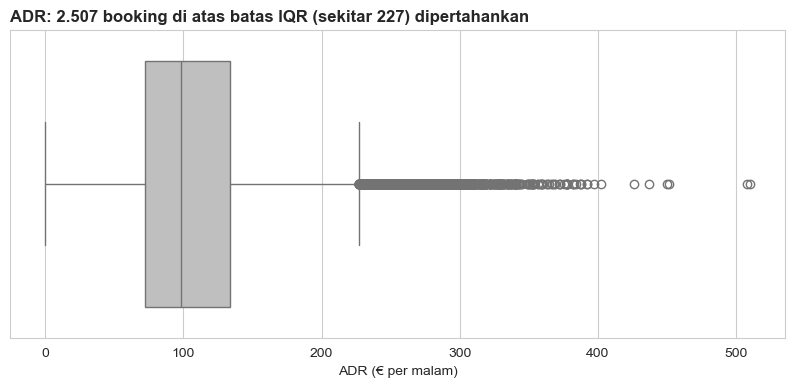

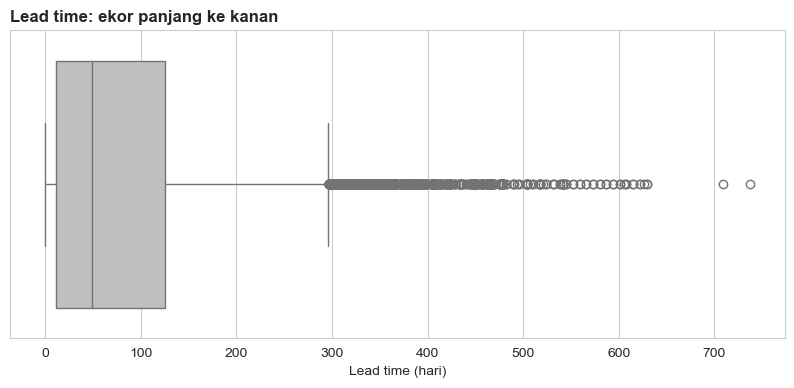

In [36]:
sns.boxplot(x=df['adr'], color=ABU)
plt.title('ADR: 2.507 booking di atas batas IQR (sekitar 227) dipertahankan', loc='left')
plt.xlabel('ADR (€ per malam)')
plt.show()

sns.boxplot(x=df['lead_time'], color=ABU)
plt.title('Lead time: ekor panjang ke kanan', loc='left')
plt.xlabel('Lead time (hari)')
plt.show()

Selain itu, ada beberapa nilai yang janggal tetapi jumlahnya kecil. Pemeriksaan nilai akan dilakukan terhadap:
- booking tanpa tamu dewasa, 5 dewasa atau lebih (dan cancel rate-nya), 9 bayi atau lebih
- 8 tempat parkir, ADR di atas 0 tetapi di bawah 10

In [37]:
print('Booking tanpa tamu dewasa (anak saja) :', (df['adults'] == 0).sum())
print('Booking dengan 5 orang dewasa atau lebih:', (df['adults'] >= 5).sum())
print('   cancel rate-nya                      :', df[df['adults'] >= 5]['is_canceled'].mean())
print('Booking dengan 9 bayi atau lebih        :', (df['babies'] >= 9).sum())
print('Permintaan 8 tempat parkir              :', (df['required_car_parking_spaces'] >= 8).sum())
print('ADR di atas 0 tapi di bawah 10          :', ((df['adr'] > 0) & (df['adr'] < 10)).sum())

Booking tanpa tamu dewasa (anak saja) : 219
Booking dengan 5 orang dewasa atau lebih: 16
   cancel rate-nya                      : 1.0
Booking dengan 9 bayi atau lebih        : 2
Permintaan 8 tempat parkir              : 2
ADR di atas 0 tapi di bawah 10          : 205


Selanjutnya, dilakukan pemeriksaan tipe kamar yang dipesan dan juga diberikan.

In [38]:
print('Tipe kamar dipesan :', sorted(df['reserved_room_type'].unique()))
print('Tipe kamar diberi  :', sorted(df['assigned_room_type'].unique()))

Tipe kamar dipesan : ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'L']
Tipe kamar diberi  : ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L']


Tipe kamar yang hanya ada check in akan diperiksa sebanyak apa

In [39]:
print('Kamar I atau K     :', df['assigned_room_type'].isin(['I', 'K']).sum())

Kamar I atau K     : 538


Selanjutnya, pemeriksaan profil yang memiliki nilai di atas normal atau rata-rata (IQR):
- ADR tinggi di atas 226,9, booking pada Resort antara Juni-Sept serta tipe kamar A
- Lead time di atas 296 hari
- ADR = 0
- tanpa orang dewasa


In [40]:
malam = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
adr_tinggi = df[df['adr'] > 226.9]

In [41]:
print(f"ADR > 226,9               : {len(adr_tinggi)} booking")
print(f"Resort                    : {(adr_tinggi['hotel'] == 'Resort Hotel').mean():.1%} (semua booking {(df['hotel'] == 'Resort Hotel').mean():.1%})")
print(f"Kedatangan Juni-September : {adr_tinggi['arrival_date'].dt.month.isin([6, 7, 8, 9]).mean():.1%} (semua booking {df['arrival_date'].dt.month.isin([6, 7, 8, 9]).mean():.1%})")
print(f"Tipe kamar A              : {(adr_tinggi['reserved_room_type'] == 'A').mean():.1%} (semua booking {(df['reserved_room_type'] == 'A').mean():.1%})")

ADR > 226,9               : 2507 booking
Resort                    : 68.8% (semua booking 38.9%)
Kedatangan Juni-September : 87.5% (semua booking 41.0%)
Tipe kamar A              : 12.6% (semua booking 64.7%)


Kesimpulan dari ADR tinggi:
- Resort: porsi normalnya 38,9%, tetapi di kelompok ADR tinggi naik ke 68,8%. Jumlah aslinya 1.725, hampir dua kali lipat dari 976 yang diharapkan. ADR tinggi lebih sering muncul di Resort.
- Juni–September: porsi normalnya 41,0%, tetapi di kelompok ADR tinggi naik ke 87,5%. Jumlah aslinya 2.193, sekitar dua kali lipat dari 1.027. ADR tinggi berkumpul di musim panas.
- Kamar A: arahnya terbalik. Porsi normalnya 64,7%, tetapi di kelompok ADR tinggi turun ke 12,6%. Jumlah aslinya 317, sekitar seperlima dari 1.622 yang diharapkan. Kamar standar jarang dihargai setinggi itu, jadi ADR tinggi kebanyakan berasal dari kamar yang lebih besar.

In [42]:
lead_panjang = df[df['lead_time'] > 296]
print(f"Lead time > 296           : {len(lead_panjang)} booking")
print(f"Online TA                 : {(lead_panjang['market_segment'] == 'Online TA').mean():.1%} (semua booking {(df['market_segment'] == 'Online TA').mean():.1%})")
print(f"Groups                    : {(lead_panjang['market_segment'] == 'Groups').mean():.1%} (semua booking {(df['market_segment'] == 'Groups').mean():.1%})")
print(f"Offline TA/TO             : {(lead_panjang['market_segment'] == 'Offline TA/TO').mean():.1%} (semua booking {(df['market_segment'] == 'Offline TA/TO').mean():.1%})")

Lead time > 296           : 2394 booking
Online TA                 : 37.5% (semua booking 59.1%)
Groups                    : 29.0% (semua booking 5.6%)
Offline TA/TO             : 28.4% (semua booking 15.9%)


Pada lead time panjang terlihat bahwa pola ini cocok dengan blok kamar grup dan tour operator yang memang dipesan jauh hari.

In [43]:
adr_nol = df[df['adr'] == 0]
print(f"ADR = 0                   : {len(adr_nol)} booking")
print(f"Complementary             : {(adr_nol['market_segment'] == 'Complementary').mean():.1%} (semua booking {(df['market_segment'] == 'Complementary').mean():.1%})")
print(f"Day-use (0 malam)         : {(malam[adr_nol.index] == 0).mean():.1%} (semua booking {(malam == 0).mean():.1%})")

ADR = 0                   : 1643 booking
Complementary             : 38.3% (semua booking 0.8%)
Day-use (0 malam)         : 36.0% (semua booking 0.7%)


ADR 0, menjelaskan bahwa complementary dan juga memang 0 night spent jadi dapat dipertahankan.

In [44]:
tanpa_dewasa = df[df['adults'] == 0]
print(f"Tanpa tamu dewasa         : {len(tanpa_dewasa)} booking")
print(f"Median ADR                : €{tanpa_dewasa['adr'].median():.1f} (semua booking €{df['adr'].median():.1f})")
print(f"Median malam              : {malam[tanpa_dewasa.index].median():.0f} (semua booking {malam.median():.0f})")

Tanpa tamu dewasa         : 219 booking
Median ADR                : €87.1 (semua booking €98.2)
Median malam              : 3 (semua booking 3)


In [45]:
adr_kecil = df[(df['adr'] > 0) & (df['adr'] < 10)]
print(f"ADR di atas 0, di bawah 10: {len(adr_kecil)} booking ({len(adr_kecil) / len(df):.1%} data)")
print(f"Direct                    : {(adr_kecil['market_segment'] == 'Direct').mean():.1%} (semua booking {(df['market_segment'] == 'Direct').mean():.1%})")
print(f"Online TA                 : {(adr_kecil['market_segment'] == 'Online TA').mean():.1%} (semua booking {(df['market_segment'] == 'Online TA').mean():.1%})")
print(f"Groups                    : {(adr_kecil['market_segment'] == 'Groups').mean():.1%} (semua booking {(df['market_segment'] == 'Groups').mean():.1%})")
print(f"Offline TA/TO             : {(adr_kecil['market_segment'] == 'Offline TA/TO').mean():.1%} (semua booking {(df['market_segment'] == 'Offline TA/TO').mean():.1%})")
print(f"Complementary             : {(adr_kecil['market_segment'] == 'Complementary').mean():.1%} (semua booking {(df['market_segment'] == 'Complementary').mean():.1%})")

ADR di atas 0, di bawah 10: 205 booking (0.2% data)
Direct                    : 24.4% (semua booking 13.5%)
Online TA                 : 21.0% (semua booking 59.1%)
Groups                    : 19.0% (semua booking 5.6%)
Offline TA/TO             : 17.1% (semua booking 15.9%)
Complementary             : 13.2% (semua booking 0.8%)


Ringkasan keputusan:

| Temuan | Jumlah | Penjelasan |
|---|---|---|
| Total tamu = 0 | 166 | akan dihapus karena tidak ada tamu yang menempati kamar |
| ADR negatif | 1 | akan dihapus karena harga kamar tidak bisa negatif |
| ADR 5.400 | 1 | akan dihapus karena sekitar 10 kali ADR tertinggi berikutnya (510) |
| ADR di atas batas IQR (> 226,9) | 2.507 | akan dipertahankan dikarenakan terkumpul pada: 87,5% kedatangan Juni-September, 68,8% di Resort, dan hanya 12,6% tipe kamar A (semua booking 64,7%) |
| Lead time di atas batas IQR (> 296 hari) | 2.394 | akan dipertahankan karena tersebar di Online TA (37,5%), Groups (29,0%), dan Offline TA/TO (28,4%) |
| ADR = 0 | 1.643 | akan dipertahankan karena merupakan Complementary 38,3% dan day-use 36,0%; tetap booking yang tercatat |
| Total malam = 0 | 591 | akan dipertahankan karena Day-use; revenue-nya akan tetap tercatat 0 |
| Anak tanpa tamu dewasa | 219 | akan dipertahankan dikarenakan median ADR (€87,1) dan lama menginap (3 malam) setara booking lain (€98,2; 3 malam) |
| 5-55 orang dewasa dalam 1 booking | 16 | akan dipertahankan dikarenakan semuanya batal dan juga terlalu sedikit untuk memengaruhi hasil |
| 9-10 bayi / 8 tempat parkir | 2 / 2 | akan dipertahankan karena terlalu sedikit untuk memengaruhi hasil |
| ADR di atas 0 tapi di bawah €10 | 205 | akan dipertahankan karena persebaran di Direct, Online TA, Groups, dan Offline TA/TO (0,2% data) |
| Kamar tipe I dan K | 538 | akan dipertahankan karena kamar tidak pernah dipesan, hanya muncul sebagai tipe kamar yang diberikan saat check-in, bisa kemungkinan upgrade |

### **G. Feature engineering**
Pembuatan kolom baru untuk mempermudah analisis:
- total_nights, total_guests
- revenue = adr × total_nights: estimasi nilai booking (potensi revenue), bukan pembayaran aktual.
- revenue_hilang: nilai booking batal yang tidak dibayar. Booking Non Refund yang batal tetap membayar penuh, jadi nilainya masuk kolom terpisah, forfeited_deposit_revenue (**Forfeited Deposit Revenue**). Revenue masuk (booking check-out) + revenue hilang + Forfeited Deposit Revenue = potensi revenue.
- lead_bin: kelompok lead time
- guest_type: Solo / Pasangan / Keluarga / Grup 3+ dewasa
- stay_type: Weekend saja / Weekday saja / Campuran
- arrival_weekday: hari kedatangan
- room_changed: tipe kamar saat check-in berbeda dari yang dipesan
- room_tier: jenis kamar yang disederhanakan menjadi 4 tier (dibahas setelah kode di bawah)

Total night dan total guests

In [46]:
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['total_guests'] = df['adults'] + df['children'] + df['babies']

Lalu pembuatan kolom revenue dari total night x adr.

In [47]:
df['revenue'] = df['adr'] * df['total_nights']

Pembuatan revenue yang hilang dan juga revenue dari forfeited deposit.

In [48]:
df['revenue_hilang'] = 0.0
df.loc[(df['is_canceled'] == 1) & (df['deposit_type'] != 'Non Refund'), 'revenue_hilang'] = df['revenue']

df['forfeited_deposit_revenue'] = 0.0
df.loc[(df['is_canceled'] == 1) & (df['deposit_type'] == 'Non Refund'), 'forfeited_deposit_revenue'] = df['revenue']

Cek hasil dari keseluruhan pembuatan kolom baru di atas:

In [49]:
print(f"Revenue masuk (check-out)  : €{df[df['is_canceled'] == 0]['revenue'].sum():,.0f}")
print(f"Revenue hilang             : €{df['revenue_hilang'].sum():,.0f}")
print(f"Forfeited Deposit Revenue  : €{df['forfeited_deposit_revenue'].sum():,.0f}")
print(f"Jumlah ketiganya           : €{df[df['is_canceled'] == 0]['revenue'].sum() + df['revenue_hilang'].sum() + df['forfeited_deposit_revenue'].sum():,.0f}")
print(f"Potensi revenue            : €{df['revenue'].sum():,.0f}")

Revenue masuk (check-out)  : €22,967,612
Revenue hilang             : €11,241,286
Forfeited Deposit Revenue  : €237,357
Jumlah ketiganya           : €34,446,255
Potensi revenue            : €34,446,255


Selanjutnya untuk mempermudah pengelompokan waktu booking akan dibagi menjadi beberapa bins dengan pd.cut

In [50]:
df['lead_bin'] = pd.cut(df['lead_time'], bins=[-1, 7, 30, 90, 180, 365, 800],
                        labels=['0-7', '8-30', '31-90', '91-180', '181-365', '>365'])

Pengelompokan tipe-tipe tamu:

In [51]:
df['guest_type'] = 'Grup 3+ dewasa'
df.loc[df['adults'] == 2, 'guest_type'] = 'Pasangan'
df.loc[df['adults'] == 1, 'guest_type'] = 'Solo'
df.loc[(df['children'] + df['babies']) > 0, 'guest_type'] = 'Keluarga'

Tipe menginap (weekend, weekday, campuran).

In [52]:
df['stay_type'] = 'Campuran'
df.loc[df['stays_in_weekend_nights'] == 0, 'stay_type'] = 'Weekday saja'
df.loc[df['stays_in_week_nights'] == 0, 'stay_type'] = 'Weekend saja'

Pengelompokan berdasarkan hari kedatangan serta apakah kamar yang diberikan sesuai booking atau tidak.

In [53]:
df['arrival_weekday'] = df['arrival_date'].dt.day_name()
df['room_changed'] = np.where(df['reserved_room_type'] != df['assigned_room_type'], 'Ya', 'Tidak')

Cek keseluruhan kolom baru.

In [54]:
df[['total_nights', 'total_guests', 'revenue', 'lead_bin', 'guest_type', 'stay_type',
    'arrival_weekday', 'room_changed']].head()

,total_nights,total_guests,revenue,lead_bin,guest_type,stay_type,arrival_weekday,room_changed
0,0,2,0.0,181-365,Pasangan,Weekend saja,Wednesday,Tidak
1,0,2,0.0,>365,Pasangan,Weekend saja,Wednesday,Tidak
2,1,1,75.0,0-7,Solo,Weekday saja,Wednesday,Ya
3,1,1,75.0,8-30,Solo,Weekday saja,Wednesday,Tidak
4,2,2,196.0,8-30,Pasangan,Weekday saja,Wednesday,Tidak


Selanjutnya, dikarenakan ada terlalu banyak tipe kamar maka akan diperiksa dengan menggunakan uji hipotesis oneway ANOVA, dengan hipotesis sebagai berikut:
- **H0:** rata-rata ADR semua tipe kamar sama.
- **H1:** minimal satu tipe kamar punya rata-rata ADR yang berbeda.
- **α = 0,05**, dihitung terpisah untuk City dan Resort.

Dikarenakan ADR tidak berdistribusi normal (condong ke kanan). Uji ini bersandar pada jumlah data yang besar (Central Limit Theorem), jadi median ADR tiap tipe kamar juga ditampilkan sebagai pembanding.

In [55]:
harga = df[df['adr'] > 0]

# Uji ANOVA per hotel: apakah rata-rata ADR tiap tipe kamar sama? (p-value < 0.05 = H0 ditolak)
for hotel in ['City Hotel', 'Resort Hotel']:
    data_hotel = harga[harga['hotel'] == hotel]

    # Mengumpulkan ADR setiap tipe kamar ke dalam satu list
    grup = []
    for tipe in data_hotel['reserved_room_type'].unique():
        grup.append(data_hotel[data_hotel['reserved_room_type'] == tipe]['adr'])

    # Tanda * memasukkan setiap isi list sebagai data terpisah ke f_oneway()
    stat, p = f_oneway(*grup)
    print(f"{hotel} : F = {stat:.1f}, p-value = {p:.4f}")

City Hotel : F = 5126.0, p-value = 0.0000


Resort Hotel : F = 1056.5, p-value = 0.0000


Median ADR tiap tipe kamar dijadikan pembanding dikarenakan ADR condong ke kanan.

In [56]:
print(harga.pivot_table(index='reserved_room_type', columns='hotel', values='adr', aggfunc='median').round(1))

hotel               City Hotel  Resort Hotel
reserved_room_type                          
A                         96.3          62.0
B                         88.8         110.0
C                        104.0         165.6
D                        132.6          86.0
E                        162.0         100.0
F                        189.9         123.2
G                        227.2         159.3
H                          NaN         185.0
L                          NaN         143.0


Dari pengujian oneway ANOVA didapatkan kesimpulan:
p-value di kedua hotel di bawah 0,05 (F = 5.126,0 di City dan 1.056,5 di Resort), jadi H0 ditolak: rata-rata ADR minimal satu tipe kamar berbeda dari yang lain. Median ADR juga berjauhan, dari €88,8 (tipe B) sampai €227,2 (tipe G) di City, dan dari €62,0 (tipe A) sampai €185,0 (tipe H) di Resort. Selanjutnya diperiksa apakah jenis kamar bisa dibuat lebih simple, dengan memperhatikan beberapa perbedaannya:
- Apakah harga antar tipe kamar saling bersinggungan atau berjauhan?
- Siapa yang memesan: apakah ada anak, dan berapa orang yang menginap?

In [57]:
# Menandai booking yang membawa anak atau bayi (jumlah tamu sudah ada di kolom total_guests)
df['bawa_anak'] = (df['children'] + df['babies']) > 0

# Tabel bukti: satu baris untuk setiap tipe kamar di tiap hotel
bukti = pd.DataFrame()
bukti['jumlah'] = df.groupby(['hotel', 'reserved_room_type'])['adr'].count()             # jumlah booking
bukti['rata_tamu'] = df.groupby(['hotel', 'reserved_room_type'])['total_guests'].mean()  # rata-rata tamu per booking
bukti['pct_anak'] = df.groupby(['hotel', 'reserved_room_type'])['bawa_anak'].mean()      # porsi booking yang membawa anak (0-1)

# Cek hasilnya
bukti

jumlah  rata_tamu  pct_anak
hotel        reserved_room_type                             
City Hotel   A                    37834   1.847915  0.063091
             B                      993   2.156093  0.338369
             C                       13   1.769231  0.076923
             D                    10745   2.245137  0.044114
             E                     1457   2.393960  0.185999
             F                     1754   3.650513  0.855758
             G                      477   3.333333  0.553459
Resort Hotel A                    18600   1.816237  0.044086
             B                        3   2.000000  0.000000
             C                      901   3.419534  0.763596
             D                     6631   2.029407  0.058815
             E                     4579   2.008954  0.051103
             F                     1066   2.066604  0.084428
             G                     1573   3.408137  0.739352
             H                      596   3.708054  0.812081
             L                        6   2.166667  0.000000

Pembuatan booking pembanding yaitu 2 dewasa, tanpa anak, dan ADR di atas 0

In [58]:
# supaya jumlah tamu tidak ikut mempengaruhi harga
dua_dewasa = df[(df['adults'] == 2) & (df['bawa_anak'] == False) & (df['adr'] > 0)]

# Harga patokan: median ADR kamar A di hotel, tahun, dan bulan yang sama
acuan = dua_dewasa[dua_dewasa['reserved_room_type'] == 'A'].groupby(['hotel', 'arrival_date_year', 'arrival_date_month'])['adr'].median().reset_index()
acuan.columns = ['hotel', 'arrival_date_year', 'arrival_date_month', 'adr_kamar_a']

# Menempelkan harga acuan ke setiap booking, lalu menghitung rasionya
# rasio 1.2 artinya 20% lebih mahal dari kamar A di bulan yang sama, jadi pengaruh musim hilang
dua_dewasa = dua_dewasa.merge(acuan, on=['hotel', 'arrival_date_year', 'arrival_date_month'], how='left')
dua_dewasa['rasio_harga'] = dua_dewasa['adr'] / dua_dewasa['adr_kamar_a']

# Median rasio harga untuk setiap tipe kamar, dimasukkan ke tabel bukti
bukti['rasio_harga'] = dua_dewasa.groupby(['hotel', 'reserved_room_type'])['rasio_harga'].median()

# Cek hasilnya
bukti.sort_values(['hotel', 'rasio_harga'])

jumlah  rata_tamu  pct_anak  rasio_harga
hotel        reserved_room_type                                          
City Hotel   B                      993   2.156093  0.338369     0.944444
             A                    37834   1.847915  0.063091     1.000000
             D                    10745   2.245137  0.044114     1.210929
             C                       13   1.769231  0.076923     1.250000
             E                     1457   2.393960  0.185999     1.461831
             F                     1754   3.650513  0.855758     1.809344
             G                      477   3.333333  0.553459     2.073535
Resort Hotel A                    18600   1.816237  0.044086     1.000000
             D                     6631   2.029407  0.058815     1.123077
             B                        3   2.000000  0.000000     1.192595
             L                        6   2.166667  0.000000     1.246989
             C                      901   3.419534  0.763596     1.319444
             E                     4579   2.008954  0.051103     1.328139
             F                     1066   2.066604  0.084428     1.507463
             G                     1573   3.408137  0.739352     1.836957
             H                      596   3.708054  0.812081     1.982718

Selanjutnya, dengan menjadikan kamar A menjadi acuan, perbandingan harga dan penentuan tier akan dilakukan.

In [59]:
bukti['room_tier'] = 'Standard'                                            # setara kamar A (kurang dari 10% lebih mahal)
bukti.loc[bukti['rasio_harga'] >= 1.10, 'room_tier'] = 'Deluxe'          # 10% - 30% lebih mahal
bukti.loc[bukti['rasio_harga'] >= 1.30, 'room_tier'] = 'Suite'           # 30% - 70% lebih mahal
bukti.loc[bukti['rasio_harga'] >= 1.70, 'room_tier'] = 'Presidential'    # 70% lebih mahal atau lebih

# untuk kamar dengan pemesanan kurang dari 100 akan ditandai sebagai data_sedikit
bukti['data_sedikit'] = bukti['jumlah'] < 100

# Cek hasilnya
bukti.sort_values(['hotel', 'room_tier'])

jumlah  rata_tamu  pct_anak  rasio_harga  \
hotel        reserved_room_type                                             
City Hotel   C                       13   1.769231  0.076923     1.250000   
             D                    10745   2.245137  0.044114     1.210929   
             F                     1754   3.650513  0.855758     1.809344   
             G                      477   3.333333  0.553459     2.073535   
             A                    37834   1.847915  0.063091     1.000000   
             B                      993   2.156093  0.338369     0.944444   
             E                     1457   2.393960  0.185999     1.461831   
Resort Hotel B                        3   2.000000  0.000000     1.192595   
             D                     6631   2.029407  0.058815     1.123077   
             L                        6   2.166667  0.000000     1.246989   
             G                     1573   3.408137  0.739352     1.836957   
             H                      596   3.708054  0.812081     1.982718   
             A                    18600   1.816237  0.044086     1.000000   
             C                      901   3.419534  0.763596     1.319444   
             E                     4579   2.008954  0.051103     1.328139   
             F                     1066   2.066604  0.084428     1.507463   

                                    room_tier  data_sedikit  
hotel        reserved_room_type                              
City Hotel   C                         Deluxe          True  
             D                         Deluxe         False  
             F                   Presidential         False  
             G                   Presidential         False  
             A                       Standard         False  
             B                       Standard         False  
             E                          Suite         False  
Resort Hotel B                         Deluxe          True  
             D                         Deluxe         False  
             L                         Deluxe          True  
             G                   Presidential         False  
             H                   Presidential         False  
             A                       Standard         False  
             C                          Suite         False  
             E                          Suite         False  
             F                          Suite         False

Lalu untuk data kamar yang datanya mencukupi yaitu di atas 100 booking akan dibandingkan harganya
batas harga harus berada pada celah yang kosong, batas harga sebagai berikut:
- 1.10
- 1.30
- 1.70

In [60]:
cek = bukti[bukti['data_sedikit'] == False]
cek.sort_values(['hotel', 'rasio_harga'])

jumlah  rata_tamu  pct_anak  rasio_harga  \
hotel        reserved_room_type                                             
City Hotel   B                      993   2.156093  0.338369     0.944444   
             A                    37834   1.847915  0.063091     1.000000   
             D                    10745   2.245137  0.044114     1.210929   
             E                     1457   2.393960  0.185999     1.461831   
             F                     1754   3.650513  0.855758     1.809344   
             G                      477   3.333333  0.553459     2.073535   
Resort Hotel A                    18600   1.816237  0.044086     1.000000   
             D                     6631   2.029407  0.058815     1.123077   
             C                      901   3.419534  0.763596     1.319444   
             E                     4579   2.008954  0.051103     1.328139   
             F                     1066   2.066604  0.084428     1.507463   
             G                     1573   3.408137  0.739352     1.836957   
             H                      596   3.708054  0.812081     1.982718   

                                    room_tier  data_sedikit  
hotel        reserved_room_type                              
City Hotel   B                       Standard         False  
             A                       Standard         False  
             D                         Deluxe         False  
             E                          Suite         False  
             F                   Presidential         False  
             G                   Presidential         False  
Resort Hotel A                       Standard         False  
             D                         Deluxe         False  
             C                          Suite         False  
             E                          Suite         False  
             F                          Suite         False  
             G                   Presidential         False  
             H                   Presidential         False

Setelah pemeriksaan, jenis-jenis kamar akan dimasukkan ke dalam tier yang sudah ditentukan.

In [61]:
tier_map = bukti[['room_tier']].reset_index()
df = df.merge(tier_map, on=['hotel', 'reserved_room_type'], how='left')

# Cek hasilnya
print('Jumlah baris          :', len(df))
print('Room tier yang kosong :', df['room_tier'].isna().sum())
print(df['room_tier'].value_counts())

Jumlah baris          : 87228
Room tier yang kosong : 0
room_tier
Standard        57427
Deluxe          17398
Suite            8003
Presidential     4400
Name: count, dtype: int64


Tier ditentukan dari harga terhadap kamar A di bulan yang sama, dengan batas yang jatuh di celah kosong antartipe kamar. Hasilnya 4 tier:
- Standard: setara harga kamar A (kurang dari 10% lebih mahal)
- Deluxe: 10-30% lebih mahal dari kamar A
- Suite: 30-70% lebih mahal dari kamar A
- Presidential: 70% atau lebih di atas kamar A

*Kolom bawa_anak hanya dipakai untuk memilih booking pembanding (2 dewasa tanpa anak) supaya rasio harga tidak naik karena biaya tambahan anak, jadi tidak ikut menentukan tier.*

### **H. Cleaning verification**
Dilakukan untuk memastikan cleaning sudah benar dan tidak ada yang terlewat.

In [62]:
print('Jumlah baris              :', len(df))
print('Null tersisa              :', df.isna().sum().sum())
print('ADR min                   :', df['adr'].min())
print('ADR max                   :', df['adr'].max())
print('Booking tanpa tamu        :', (df['total_guests'] == 0).sum())
print('Label meal                :', df['meal'].unique())
print(f"Cancel rate setelah clean : {df['is_canceled'].mean():.2%}")
print(f"Porsi data dipertahankan  : {len(df) / len(df_raw):.2%}")

Jumlah baris              : 87228
Null tersisa              : 0
ADR min                   : 0.0
ADR max                   : 510.0
Booking tanpa tamu        : 0
Label meal                : ['BB' 'FB' 'HB' 'SC']
Cancel rate setelah clean : 27.52%
Porsi data dipertahankan  : 73.06%


Selanjutnya, tanggal juga dicek, karena analisis waktu pembatalan dan buffer overbooking bergantung pada kolom tanggal.
maka pembuatan selisih antara booking dengan waktu kedatangan akan dilakukan.

In [63]:
selisih_hari = (df['reservation_status_date'] - df['arrival_date']).dt.days

Pembuatan variabel dari tiap-tiap status reservasi apakah sampai checkout atau tidak hadir atau cancel.

In [64]:
checkout = df['reservation_status'] == 'Check-Out'
noshow = df['reservation_status'] == 'No-Show'
batal = df['reservation_status'] == 'Canceled'

Pemeriksaan keseluruhan

In [65]:
# Check-out: tanggal status seharusnya = tanggal kedatangan + jumlah malam
print(f"Check-out                              : {checkout.sum()} booking")
print(f"   tanggal status = kedatangan + malam : {(selisih_hari[checkout] == df['total_nights'][checkout]).mean():.2%}")
print(f"   pulang lebih awal                   : {(selisih_hari[checkout] < df['total_nights'][checkout]).sum()} booking")

Check-out                              : 63220 booking
   tanggal status = kedatangan + malam : 99.96%
   pulang lebih awal                   : 23 booking


In [66]:
# No-show: tanggal status seharusnya = tanggal kedatangan
print(f"No-show                                : {noshow.sum()} booking")
print(f"   tanggal status = kedatangan         : {(selisih_hari[noshow] == 0).sum()} booking")
print(f"   tanggal status berbeda              : {(selisih_hari[noshow] != 0).sum()} booking")

No-show                                : 1013 booking
   tanggal status = kedatangan         : 1012 booking
   tanggal status berbeda              : 1 booking


In [67]:
# Canceled: jarak batal ke kedatangan tidak boleh lebih panjang dari lead time (artinya batal sebelum booking dibuat)
print(f"Canceled                               : {batal.sum()} booking")
print(f"   batal sebelum booking dibuat        : {((0 - selisih_hari[batal]) > df['lead_time'][batal]).sum()} booking")

Canceled                               : 22995 booking
   batal sebelum booking dibuat        : 0 booking


Dari proses di atas, didapatkan kesimpulan yaitu:
- Untuk tamu check-out, tanggal status sama dengan tanggal kedatangan + jumlah malam di **99,96%** booking. Sisanya 23 tamu pulang lebih awal.
- Tanggal status no-show sama dengan tanggal kedatangan (1.012 dari 1.013).
- Tidak ada pembatalan yang tercatat sebelum booking dibuat.

Kolom tanggal konsisten, jadi aman dipakai untuk menghitung waktu pembatalan.

### **DESCRIPTIVE INSIGHT**

Dari 119.390 booking, cleaning menyisakan **87.228 unique booking (73,06%)**, dan booking inilah yang dipakai di analisis selanjutnya.

1. **Duplikat:** 31.994 baris (**26,80%**) identik di 32 kolom dan 63% di antaranya batal, sehingga cancel rate turun dari **37,04%** menjadi **27,52%** setelah duplikat dihapus.

2. **Non Refund:** 92,9% barisnya duplikat. Setelah dibersihkan tinggal 1.037 booking (1,2% data), jadi pola "Non Refund paling sering batal" perlu dibaca hati-hati (4.C).

3. **Nilai kosong:** company (94%) dan agent (14%) kosong karena booking tidak lewat perusahaan atau agent. Data yang hilang hanya country (452) dan children (4).

4. **Nilai rusak:** hanya 168 baris (0,19%) yang dihapus karena mustahil (tanpa tamu, ADR negatif, ADR 5.400). Outlier ADR dan lead time dipertahankan karena terkumpul di kelompok tertentu, misalnya 87,5% ADR tinggi datang di Juni-September.

5. **City 2015:** 52,1% barisnya duplikat, jadi perbandingan antartahun memakai Januari-Agustus 2016 vs 2017.

6. **Kolom yang perlu diperhatikan:** CN diseragamkan menjadi CHN, arrival_date_week_number tidak mengikuti minggu standar, dan anomali kecil (219 booking anak tanpa dewasa, 16 booking berisi 5-55 orang dewasa) tetap disimpan. Logika tanggal sudah dicek dan konsisten.

## **4. EDA: Exploratory Data Analysis**
Tujuan:
1. Memahami distribusi tiap kolom secara mandiri (univariate)
2. Mengukur seberapa besar masalah pembatalan (uang dan waktu)
3. Mencari faktor pembatalan, lalu mengontrol variabel perancu dengan pivot 2 dimensi per hotel
4. Memecah kapan dan mengapa volume serta pembatalan naik-turun, lalu menyusun sasaran kebijakan

Mulai 4.B, ukuran utama tiap variabel adalah **revenue loss rate** (revenue hilang ÷ potensi revenue kelompok itu). Cancel rate dari jumlah booking tetap ditampilkan sebagai pembanding.

**Alur cerita EDA**

| Babak | Bagian | Pertanyaan | Hasilnya dipakai untuk |
|---|---|---|---|
| 1. Konteks dan data | 4.A | Seperti apa tamu dan booking-nya? | Pembanding untuk semua bagian |
| 2. Masalah dan penyebab | 4.B | Seberapa besar kerugiannya, dan apakah makin parah? | Menunjukkan urgensi |
| | 4.C | Booking seperti apa yang batal? | Ciri kandidat kebijakan |
| | 4.D | Kolom mana yang tidak bisa dipercaya? | Menyaring ciri |
| 3. Waktu | 4.E | Kapan volume dan pembatalan naik-turun, dan apa pendorongnya? | Jendela waktu kebijakan dan buffer overbooking |
| 4. Sasaran dan nilai | 4.F | Di mana kerugian menumpuk? | Sasaran kebijakan |
| | 4.G | Segmen mana yang paling bernilai? | Segmen yang harus dijaga |
| | 4.H | Adakah satu faktor yang dominan? | Pengecekan |
| | 4.I | Konteks sebelum kebijakan disusun | Menyesuaikan rekomendasi |
| 5. Pemasukan dan kelompok | 4.J | Kapan dan dari siapa pemasukan datang? | Pola kedatangan dan segmen pengisi hari sepi |
| | 4.K | Ringkasan sementara 4.B-4.J | Penyesuaian rekomendasi |
| | 4.L | Kelompok mana yang besar, bernilai, dan tumbuh, apa kebiasaannya, dan kapan hotel paling ramai? | Prioritas per kelompok, promosi per negara, dan jadwal staf |
| | 4.M | Agent dan perusahaan mana yang paling bernilai, masih aktif, dan menanggung revenue hilang? | Syarat kontrak agent dan akun perusahaan |
| 6. Bukti dan keputusan | 4.N | Apakah selisih yang dipakai di rekomendasi bisa terjadi karena kebetulan? | Dasar statistik untuk rekomendasi 1 dan 6 |

Setiap grafik diberi judul berupa insight (*action title*) dan diikuti observasi. Grafik dipilih sesuai tujuannya: bar untuk perbandingan, line untuk tren, histogram/boxplot untuk distribusi, heatmap untuk tabel 2 dimensi. Pie chart dan secondary axis tidak dipakai.

Selanjutnya dibuat 3 fungsi bantu yang dipakai berulang kali di bagian ini:
- cancel_rate(data, kolom): tabel revenue loss rate, cancel rate (%), dan jumlah booking per kategori.
- plot_cancel_rate(tabel, judul): bar horizontal revenue loss rate dengan baseline nol, bar tertinggi berwarna merah, dan garis putus-putus sebagai rata-rata semua booking. Kategori dengan kurang dari 100 booking disembunyikan supaya angka dari sampel kecil tidak menyesatkan.
- loss_rate_pivot(data, baris, kolom): tabel revenue loss rate 2 dimensi untuk heatmap.

Sebelum itu akan dibuat dulu revenue loss rate dari semua booking.

In [68]:
rata_rugi = df['revenue_hilang'].sum() / df['revenue'].sum() * 100

Pembuatan helper function cancel_rate:

In [69]:
def cancel_rate(data, kolom):
    tabel = data.groupby(kolom)['is_canceled'].agg(['mean', 'count'])
    tabel.columns = ['cancel_rate', 'jumlah_booking']
    tabel['cancel_rate'] = (tabel['cancel_rate'] * 100).round(1)
    # ukuran utama: revenue loss rate = revenue hilang ÷ potensi revenue kelompok itu
    tabel['potensi_revenue'] = data.groupby(kolom)['revenue'].sum()
    tabel['revenue_hilang'] = data.groupby(kolom)['revenue_hilang'].sum()
    tabel['revenue_loss_rate'] = (tabel['revenue_hilang'] / tabel['potensi_revenue'] * 100).round(1)
    tabel = tabel[['revenue_loss_rate', 'cancel_rate', 'jumlah_booking', 'revenue_hilang', 'potensi_revenue']]
    return tabel

cancel_rate di sini berisi tabel per kategori berisi revenue loss rate (revenue hilang ÷ potensi revenue kelompok itu), cancel rate, jumlah booking, revenue hilang, dan potensi revenue. Revenue loss rate menjadi ukuran utama karena nilai booking yang batal berbeda-beda, sedangkan cancel rate ditampilkan sebagai pembanding.

Lalu selanjutnya plot_cancel_rate:

In [70]:
def plot_cancel_rate(tabel, judul, urut=True):
    # hanya kategori dengan minimal 100 booking dan potensi revenue di atas 0
    t = tabel[(tabel['jumlah_booking'] >= 100) & (tabel['potensi_revenue'] > 0)]

    # urut=True  -> diurutkan dari revenue loss rate terkecil
    # urut=False -> urutan kategori asli dipertahankan (misalnya lead time 0-7, 8-30, ...), kategori pertama di atas
    if urut:
        t = t.sort_values('revenue_loss_rate')
    else:
        t = t.sort_index(ascending=False)

    # bar dengan revenue loss rate tertinggi berwarna merah, sisanya abu-abu
    warna = np.where(t['revenue_loss_rate'] == t['revenue_loss_rate'].max(), SOROT, ABU)

    plt.figure(figsize=(9, len(t) * 0.45 + 1.5))
    bar = plt.barh(t.index.astype(str), t['revenue_loss_rate'], color=warna)
    plt.bar_label(bar, fmt='%.1f%%', padding=3)          # tulis angka di ujung tiap bar
    plt.axvline(rata_rugi, color='black', linestyle='--', label=f'Rata-rata {rata_rugi:.1f}%')
    plt.xlim(0, max(t['revenue_loss_rate'].max(), rata_rugi) * 1.2)
    plt.title(judul, loc='left')
    plt.xlabel('Revenue loss rate (%): revenue hilang ÷ potensi revenue')
    plt.legend(loc='best')
    plt.show()

plot_cancel_rate di sini berfungsi:
- membuat bar horizontal revenue loss rate per kategori, dengan bar tertinggi berwarna merah dan garis putus-putus sebagai rata-rata semua booking. 
- Kategori dengan kurang dari 100 booking dan kategori dengan potensi revenue 0 tidak dihitung.
- urut=True mengurutkan bar dari loss rate terkecil, sedangkan urut=False mempertahankan urutan asli kategori (misalnya lead time 0-7, 8-30, dan seterusnya).

Lalu selanjutnya pembuatan loss_rate_pivot yang berfungsi dalam pembuatan heatmap.

In [71]:
def loss_rate_pivot(data, baris, kolom):
    # revenue loss rate untuk tabel 2 dimensi: revenue hilang ÷ potensi revenue di tiap sel
    hilang = data.pivot_table(index=baris, columns=kolom, values='revenue_hilang', aggfunc='sum')
    potensi = data.pivot_table(index=baris, columns=kolom, values='revenue', aggfunc='sum')
    return hilang / potensi * 100 

loss_rate_pivot berfungsi untuk: 
- revenue loss rate untuk tabel 2 dimensi (heatmap).
- Revenue hilang dan potensi revenue dijumlahkan dulu di tiap sel, baru dibagi, agar booking yang nilainya lebih besar juga berbobot lebih besar.

### **A. Univariate: distribusi tiap kolom**
Sebelum fokus ke cancellation, perlu dipahami seperti apa tamu dan bookingnya, agar dapat dilakukan perbandingan ke semua bagian. 

Karena kolom numerik yang miring (skewed) diringkas dengan median dan IQR, bukan mean karena mean tidak menggambarkan keseluruhan dari booking

Kolom kategori diringkas dengan proporsi



#### **1. Status reservasi**

In [72]:
# value_counts reservation_status (jumlah dan persen)
# % potensi revenue per status: groupby reservation_status, sum revenue / total revenue x 100
print(df['reservation_status'].value_counts())
print(df['reservation_status'].value_counts(normalize=True).mul(100).round(2))
print('% potensi revenue per status:')
print((df.groupby('reservation_status')['revenue'].sum() / df['revenue'].sum() * 100).round(2))

reservation_status
Check-Out    63220
Canceled     22995
No-Show       1013
Name: count, dtype: int64
reservation_status
Check-Out    72.48
Canceled     26.36
No-Show       1.16
Name: proportion, dtype: float64
% potensi revenue per status:
reservation_status
Canceled     32.14
Check-Out    66.68
No-Show       1.18
Name: revenue, dtype: float64


**72,48%** booking check-out, **26,36%** Canceled, dan **1,16%** No-Show. No-Show ikut dihitung batal (is_canceled = 1), jadi cancel rate keseluruhan **27,52%**. Dalam nilai, Canceled membawa **32,14%** potensi revenue dan No-Show 1,18%, lebih besar dari porsi jumlahnya karena booking yang batal rata-rata lebih lama dan lebih mahal (4.B.1). Bagian ini hanya berisi beberapa angka, jadi cukup ditulis tanpa grafik.

#### **2. Hotel**

In [73]:
# value_counts hotel (jumlah dan persen)
# % potensi revenue per hotel
print(df['hotel'].value_counts())
print(df['hotel'].value_counts(normalize=True).mul(100).round(2))
print('% potensi revenue per hotel:')
print((df.groupby('hotel')['revenue'].sum() / df['revenue'].sum() * 100).round(2))

hotel
City Hotel      53273
Resort Hotel    33955
Name: count, dtype: int64
hotel
City Hotel      61.07
Resort Hotel    38.93
Name: proportion, dtype: float64
% potensi revenue per hotel:
hotel
City Hotel      54.46
Resort Hotel    45.54
Name: revenue, dtype: float64


City Hotel **53.273 booking (61,07%)**, Resort Hotel **33.955 (38,93%)**. Dalam nilai selisihnya lebih kecil: City membawa **54,46%** potensi revenue dan Resort **45,54%**. Analisis selalu dipisah per hotel supaya pola Resort tidak tertutup oleh City.

#### **3. Lead time**

                count  mean   std  min   25%   50%    75%    max
hotel                                                           
City Hotel    53273.0  77.8  82.1  0.0  14.0  51.0  118.0  629.0
Resort Hotel  33955.0  83.4  91.8  0.0   8.0  47.0  138.0  737.0


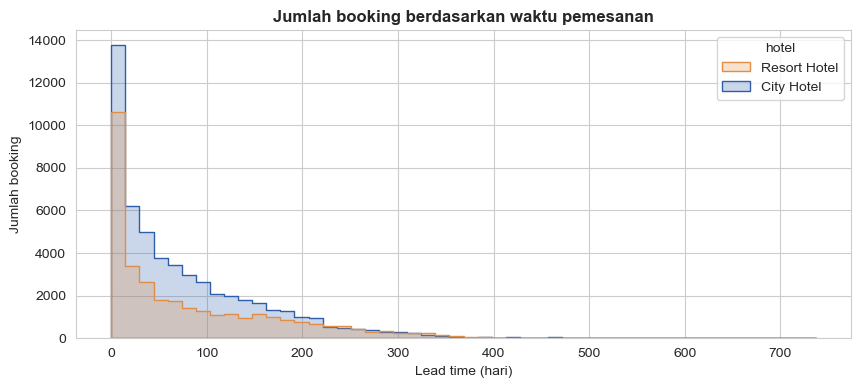

In [74]:
# describe() lead_time per hotel
print(df.groupby('hotel')['lead_time'].describe().round(1))

sns.histplot(data=df, x='lead_time', hue='hotel', bins=50, palette=WARNA_HOTEL, element='step')
plt.title('Jumlah booking berdasarkan waktu pemesanan', loc='center')
plt.xlabel('Lead time (hari)'); plt.ylabel('Jumlah booking')
plt.show()

- Distribusi lead time miring ke kanan: median **49 hari**, tetapi ada booking hingga 737 hari.
- City: median 51 hari (IQR 14-118). Resort: median 47 hari (IQR 8-138). Resort lebih bervariasi, dengan lebih banyak booking mendadak sekaligus lebih banyak booking yang sangat jauh hari.

#### **4. ADR (harga per malam)**

                count   mean   std  min   25%    50%    75%    max
hotel                                                             
City Hotel    53273.0  111.2  42.0  0.0  84.2  105.3  134.1  510.0
Resort Hotel  33955.0   99.1  63.8  0.0  51.5   79.5  134.1  508.0


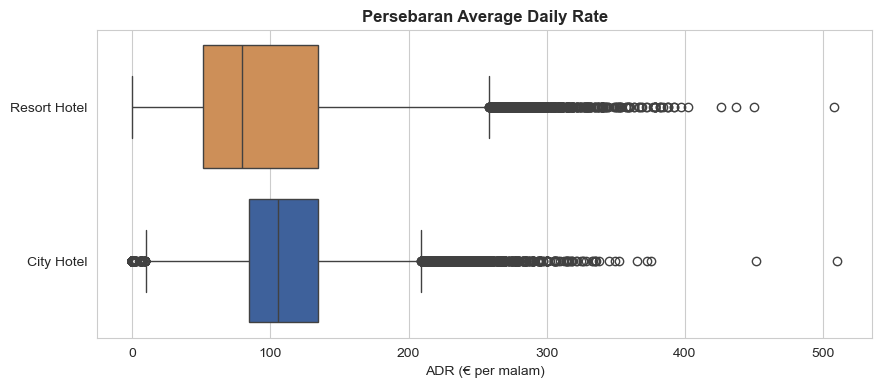

In [75]:
# describe() adr per hotel
print(df.groupby('hotel')['adr'].describe().round(1))

sns.boxplot(data=df, x='adr', y='hotel', palette=WARNA_HOTEL)
plt.title('Persebaran Average Daily Rate', loc='center')
plt.xlabel('ADR (€ per malam)'); plt.ylabel('')
plt.show()

- City: median **€105,3** (IQR 84,2-134,1).
- Resort: median **€79,5** (IQR 51,5-134,1).
- Batas atas IQR keduanya sama, tetapi Resort punya batas bawah jauh lebih rendah. Harga Resort sangat bergantung musim.

#### **5. Lama menginap**

                count  mean  std  min  25%  50%  75%   max
hotel                                                     
City Hotel    53273.0   3.1  2.0  0.0  2.0  3.0  4.0  48.0
Resort Hotel  33955.0   4.4  3.4  0.0  2.0  4.0  7.0  69.0
stay_type     Campuran  Weekday saja  Weekend saja
hotel                                             
City Hotel        49.9          43.0           7.0
Resort Hotel      59.0          34.0           7.0


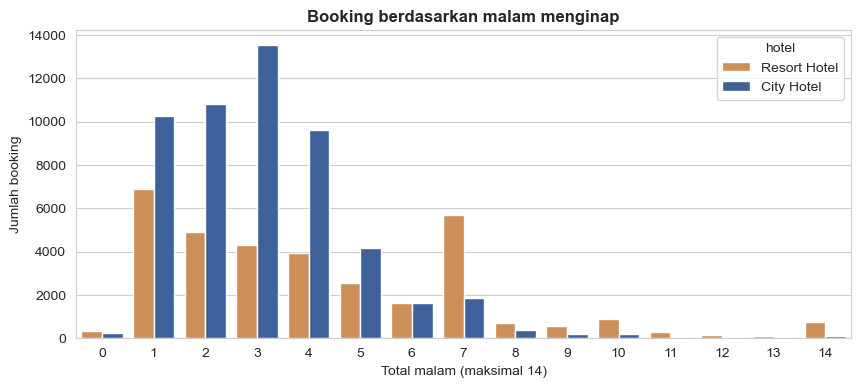

In [76]:
# describe() total_nights per hotel
# pd.crosstab hotel x stay_type (normalize='index')
# Grafik jumlah booking per total_nights (maksimal 14 malam) per hotel (sns.countplot)
print(df.groupby('hotel')['total_nights'].describe().round(1))
print(pd.crosstab(df['hotel'], df['stay_type'], normalize='index').mul(100).round(1))

sns.countplot(data=df[df['total_nights'] <= 14], x='total_nights', hue='hotel', palette=WARNA_HOTEL)
plt.title('Booking berdasarkan malam menginap', loc='center')
plt.xlabel('Total malam (maksimal 14)'); plt.ylabel('Jumlah booking')
plt.show()

- City: median 3 malam, 75% booking ≤ 4 malam.
- Resort: median 4 malam, dengan lonjakan di **7 malam (16,7% booking)**.
- Sekitar separuh booking menginap di weekday dan weekend sekaligus (City 49,9%, Resort 59,0%). Booking "weekend saja" hanya 7% di kedua hotel.

#### **6. Komposisi tamu**

In [77]:
# value_counts guest_type
# % potensi revenue per tipe tamu per hotel: pd.crosstab(hotel, guest_type, values=revenue, aggfunc='sum', normalize='index')
# % booking per tipe tamu per hotel: pd.crosstab(hotel, guest_type, normalize='index')
print(df['guest_type'].value_counts())
print('% potensi revenue per tipe tamu, per hotel:')
print(pd.crosstab(df['hotel'], df['guest_type'], values=df['revenue'], aggfunc='sum', normalize='index').mul(100).round(1), '\n')
pd.crosstab(df['hotel'], df['guest_type'], normalize='index').mul(100).round(1)

guest_type
Pasangan          56580
Solo              16068
Keluarga           9103
Grup 3+ dewasa     5477
Name: count, dtype: int64
% potensi revenue per tipe tamu, per hotel:
guest_type    Grup 3+ dewasa  Keluarga  Pasangan  Solo
hotel                                                 
City Hotel              12.4      13.8      60.6  13.1
Resort Hotel             5.3      19.6      68.5   6.6 



guest_type,Grup 3+ dewasa,Keluarga,Pasangan,Solo
hotel,,,,
City Hotel,8.4,9.8,62.7,19.1
Resort Hotel,3.0,11.4,68.2,17.4


**Pasangan** mendominasi (63% booking di City, 68% di Resort). Solo 19% / 17%, Keluarga 10% / 11%. Grup 3+ dewasa lebih banyak di City (8%) dibanding Resort (3%). Dalam nilai, keluarga lebih besar dari porsi jumlahnya (13,8% potensi revenue City, 19,6% Resort), sedangkan tamu solo lebih kecil (13,1% dan 6,6%).

#### **7. Paket makan**

In [78]:
# % potensi revenue per paket makan per hotel (crosstab dengan values=revenue, aggfunc='sum')
# % booking per paket makan per hotel
print('% potensi revenue per paket makan, per hotel:')
print(pd.crosstab(df['hotel'], df['meal'], values=df['revenue'], aggfunc='sum', normalize='index').mul(100).round(1), '\n')
pd.crosstab(df['hotel'], df['meal'], normalize='index').mul(100).round(1)

% potensi revenue per paket makan, per hotel:
meal            BB   FB    HB    SC
hotel                              
City Hotel    78.7  0.0   7.2  14.1
Resort Hotel  65.6  1.9  30.6   1.9 



meal,BB,FB,HB,SC
hotel,,,,
City Hotel,77.3,0.0,5.2,17.5
Resort Hotel,78.8,1.0,18.5,1.7


Bed & Breakfast dominan di kedua hotel (77-79% booking). Bedanya: **tanpa paket makan (SC) 17,5% di City** vs 1,7% di Resort, sedangkan **Half Board 18,5% di Resort** vs 5,2% di City. Dalam nilai, Half Board membawa 30,6% potensi revenue Resort.

#### **8. Negara asal**
Negara asal dihitung hanya dari booking yang check-out.

Pertama akan dilihat terlebih dahulu ada berapa keseluruhan jumlah negara.

In [79]:
print('Jumlah negara (semua booking):', df['country'].nunique())

Jumlah negara (semua booking): 177


% booking check-out:
country
PRT    27.8
GBR    13.3
FRA    11.2
ESP     8.5
DEU     6.9
IRL     3.7
ITA     3.1
BEL     2.6
NLD     2.5
USA     2.2
Name: proportion, dtype: float64 

% revenue masuk:
country
PRT    21.1
GBR    16.2
FRA    11.9
ESP     8.8
DEU     7.1
IRL     5.1
ITA     3.2
BEL     3.0
NLD     2.5
CHE     2.2
Name: revenue, dtype: float64


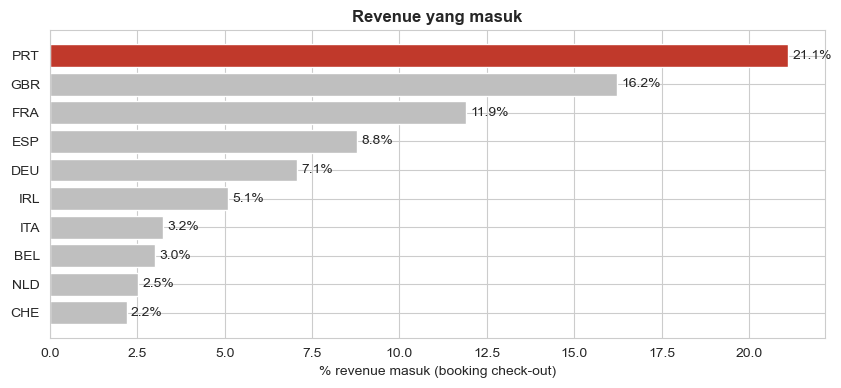

In [80]:
co = df[df['is_canceled'] == 0] # untuk exclude yang canceled
# ukuran utama: porsi revenue masuk (booking check-out); porsi jumlah booking dicetak sebagai pendamping
top_negara = (co.groupby('country')['revenue'].sum() / co['revenue'].sum() * 100).sort_values(ascending=False).head(10).sort_values()
print('% booking check-out:')
print(co['country'].value_counts(normalize=True).mul(100).head(10).round(1), '\n')
print('% revenue masuk:')
print(top_negara.sort_values(ascending=False).round(1))

warna = np.where(top_negara.index == 'PRT', SOROT, ABU)     # Portugal merah, lainnya abu-abu
bar = plt.barh(top_negara.index, top_negara, color=warna)
plt.bar_label(bar, fmt='%.1f%%', padding=3)
plt.title('Revenue yang masuk', loc='center')
plt.xlabel('% revenue masuk (booking check-out)')
plt.show()

Dari revenue yang masuk (booking check-out), Portugal **21,1%**, Inggris 16,2%, Prancis 11,9%, Spanyol 8,8%, dan Jerman 7,1%. Lima negara ini membawa **65,1%** revenue yang masuk. Dari jumlah booking, porsi Portugal lebih besar (27,8%) karena tamu Portugal menginap lebih singkat dan membayar lebih murah. Inggris dan Irlandia sebaliknya: Inggris 13,3% booking tetapi 16,2% revenue, Irlandia 3,7% booking tetapi 5,1% revenue.

#### **9. Market segment & distribution channel**

% potensi revenue:
market_segment
Complementary     0.0
Undefined         0.0
Aviation          0.2
Corporate         1.7
Groups            3.6
Direct           14.1
Offline TA/TO    15.7
Online TA        64.6
Name: revenue, dtype: float64 

% booking:
market_segment
Online TA        59.1
Offline TA/TO    15.9
Direct           13.5
Groups            5.6
Corporate         4.8
Complementary     0.8
Aviation          0.3
Undefined         0.0
Name: proportion, dtype: float64 

distribution_channel
TA/TO        79.1
Direct       14.8
Corporate     5.8
GDS           0.2
Undefined     0.0
Name: proportion, dtype: float64


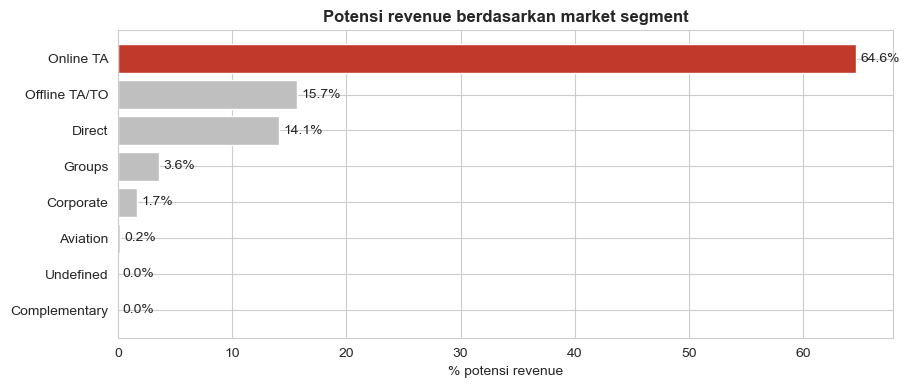

In [81]:
# ukuran utama: porsi potensi revenue; porsi jumlah booking dicetak sebagai pendamping
seg = (df.groupby('market_segment')['revenue'].sum() / df['revenue'].sum() * 100).round(1).sort_values()
print('% potensi revenue:')
print(seg, '\n')
print('% booking:')
print(df['market_segment'].value_counts(normalize=True).mul(100).round(1), '\n')
print(df['distribution_channel'].value_counts(normalize=True).mul(100).round(1))

warna = np.where(seg.index == 'Online TA', SOROT, ABU)
bar = plt.barh(seg.index, seg, color=warna)
plt.bar_label(bar, fmt='%.1f%%', padding=3)
plt.title('Potensi revenue berdasarkan market segment', loc='center')
plt.xlabel('% potensi revenue')
plt.show()

**Online TA membawa 64,6% potensi revenue** (59,1% booking), Offline TA/TO 15,7%, Direct 14,1%, Groups 3,6%, dan Corporate 1,7%. Groups dan Corporate lebih kecil dalam nilai daripada dalam jumlah booking (5,6% dan 4,8%). Dari sisi channel, TA/TO membawa **79,1%** booking. Hotel sangat bergantung pada perantara.

#### **10. Customer type & deposit type**

In [82]:
# Customer type: jumlah booking, porsi booking, dan porsi potensi revenue
tabel_customer = pd.DataFrame()
tabel_customer['jumlah_booking'] = df.groupby('customer_type')['customer_type'].count()
tabel_customer['%_booking'] = (tabel_customer['jumlah_booking'] / len(df) * 100).round(2)
tabel_customer['%_potensi_revenue'] = (df.groupby('customer_type')['revenue'].sum() / df['revenue'].sum() * 100).round(2)
print(tabel_customer.sort_values('jumlah_booking', ascending=False))

                 jumlah_booking  %_booking  %_potensi_revenue
customer_type                                                
Transient                 71861      82.38              84.87
Transient-Party           11691      13.40               9.97
Contract                   3135       3.59               4.77
Group                       541       0.62               0.39


Dari setiap 100 pesanan, sekitar 82 berasal dari tamu yang memesan sendiri, dan kelompok ini menyumbang sedikit lebih banyak uang (85%) dibanding jumlah pesanannya. Transient-Party sebaliknya. Jumlah pesanannya 13%, tetapi uangnya hanya 10%, karena kamarnya lebih murah atau menginapnya lebih singkat.

In [83]:
# Deposit type: jumlah booking, porsi booking, dan porsi potensi revenue
tabel_deposit = pd.DataFrame()
tabel_deposit['jumlah_booking'] = df.groupby('deposit_type')['deposit_type'].count()
tabel_deposit['%_booking'] = (tabel_deposit['jumlah_booking'] / len(df) * 100).round(2)
tabel_deposit['%_potensi_revenue'] = (df.groupby('deposit_type')['revenue'].sum() / df['revenue'].sum() * 100).round(2)
print(tabel_deposit.sort_values('jumlah_booking', ascending=False))

              jumlah_booking  %_booking  %_potensi_revenue
deposit_type                                              
No Deposit             86084      98.69              99.18
Non Refund              1037       1.19               0.72
Refundable               107       0.12               0.09


Hampir semua tamu, 99 dari 100, booking tanpa membayar apa pun di depan. Mereka bisa membatalkan kapan saja tanpa rugi, sedangkan hotel sudah book kamar untuk mereka. Jadi hampir seluruh risiko pembatalan ditanggung hotel.

*Note: Transient dan Transient-Party adalah booking yang dilakukan secara perorangan, untuk transient-party adalah tamu perorangan yang pesanannya terhubung dengan pesanan lain, misalnya beberapa keluarga yang datang bersama.*

#### **11. Tipe kamar**

In [84]:
kamar = df.groupby('reserved_room_type')['adr'].agg(['count', 'median'])
kamar['persen'] = (kamar['count'] / kamar['count'].sum() * 100).round(1)
kamar['%_potensi_revenue'] = (df.groupby('reserved_room_type')['revenue'].sum() / df['revenue'].sum() * 100).round(1)
kamar

,count,median,persen,%_potensi_revenue
reserved_room_type,,,,
A,56434,89.100,64.7,50.5
B,996,86.800,1.1,0.9
C,914,163.280,1.0,2.1
D,17376,122.735,19.9,25.0
E,6036,115.535,6.9,10.3
F,2820,177.300,3.2,5.2
G,2050,176.930,2.4,4.7
H,596,184.250,0.7,1.4
L,6,143.000,0.0,0.0


Tipe A **64,7%** booking dan **50,5%** potensi revenue; D 19,9% booking dan 25,0% potensi revenue. Kode kamar disamarkan, jadi yang bisa dibaca hanya tingkat harganya: A median €89, D €123, sedangkan F/G/H sekitar €177-184.

In [85]:
# % potensi revenue per tier per hotel (crosstab values=revenue), urutan Standard, Deluxe, Suite, Presidential
# % booking per tier per hotel (crosstab normalize='index')
tier = pd.crosstab(df['hotel'], df['room_tier'], normalize='index').mul(100).round(1)
print('% potensi revenue per tier, per hotel:')
print(pd.crosstab(df['hotel'], df['room_tier'], values=df['revenue'], aggfunc='sum', normalize='index').mul(100).round(1)[['Standard', 'Deluxe', 'Suite', 'Presidential']], '\n')
print('% booking per tier, per hotel:')
tier[['Standard', 'Deluxe', 'Suite', 'Presidential']]

% potensi revenue per tier, per hotel:
room_tier     Standard  Deluxe  Suite  Presidential
hotel                                              
City Hotel        61.8    26.3    4.3           7.7
Resort Hotel      39.0    23.4   26.6          11.0 

% booking per tier, per hotel:


room_tier,Standard,Deluxe,Suite,Presidential
hotel,,,,
City Hotel,72.9,20.2,2.7,4.2
Resort Hotel,54.8,19.6,19.3,6.4


Setelah disederhanakan menjadi tier, Standard mencakup **72,9%** booking City (61,8% potensi revenue) dan **54,8%** booking Resort (39,0%). Di Resort, Suite dan Presidential membawa 37,6% potensi revenue (26,6% dan 11,0%), jauh di atas City (4,3% dan 7,7%).

#### **12. Riwayat tamu**

Pemeriksaan apakah tamu pernah menginap sebelumnya.

In [86]:
# Print % tamu repeat, % pernah membatalkan (previous_cancellations > 0), % pernah menginap tanpa batal
print(f"Tamu repeat                   : {df['is_repeated_guest'].mean():.2%}")
print(f"Pernah membatalkan sebelumnya : {(df['previous_cancellations'] > 0).mean():.2%}")
print(f"Pernah menginap tanpa batal   : {(df['previous_bookings_not_canceled'] > 0).mean():.2%}")


Tamu repeat                   : 3.86%
Pernah membatalkan sebelumnya : 1.93%
Pernah menginap tanpa batal   : 4.05%


Hanya **3,86%** tamu repeat. Hotel hampir sepenuhnya bergantung pada tamu baru.

In [87]:
# apakah kolom-kolom riwayat ini konsisten satu sama lain?
print('Tamu repeat tanpa riwayat booking sama sekali :',
      ((df['is_repeated_guest'] == 1) & (df['previous_cancellations'] == 0) & (df['previous_bookings_not_canceled'] == 0)).sum())
print('Bukan tamu repeat tapi punya riwayat menginap :',
      ((df['is_repeated_guest'] == 0) & (df['previous_bookings_not_canceled'] > 0)).sum())

Tamu repeat tanpa riwayat booking sama sekali : 462


Bukan tamu repeat tapi punya riwayat menginap : 743


Setelah proses di atas inilah temuannya:
- Bertanda tamu repeat, tetapi riwayatnya kosong. Kalau benar tamu lama, minimal satu kolom riwayat harus berisi angka. Hasilnya 462 booking.
- Punya riwayat menginap, tetapi tidak bertanda repeat. Kalau pernah datang, seharusnya ditandai sebagai tamu lama. Hasilnya 743 booking.

#### **13. Special request, parkir, perubahan booking, waiting list**

Mencari special request booking:

In [88]:
print(df['total_of_special_requests'].value_counts(normalize=True).sort_index().mul(100).round(1))


total_of_special_requests
0    50.2
1    33.2
2    13.5
3     2.7
4     0.4
5     0.0
Name: proportion, dtype: float64


Separuh booking (**50,2%**) tanpa special request.

In [89]:
print(df['required_car_parking_spaces'].value_counts(normalize=True).sort_index().mul(100).round(1))

required_car_parking_spaces
0    91.6
1     8.3
2     0.0
3     0.0
8     0.0
Name: proportion, dtype: float64


91,6% dari booking tidak meminta parkir

In [90]:
print(f"Tidak pernah mengubah booking : {(df['booking_changes'] == 0).mean():.2%}")

Tidak pernah mengubah booking : 81.88%


Sebanyak **81,9%** tidak pernah mengubah booking

In [91]:
print(f"Pernah masuk waiting list     : {(df['days_in_waiting_list'] > 0).mean():.2%}")

Pernah masuk waiting list     : 0.98%


Secara keseluruhan booking hanya **0,98%** yang pernah masuk waiting list.

> **Babak 2 dari 6: Masalah dan penyebab** (4.B-4.D)
>
> Berapa revenue yang hilang dan apakah makin parah (4.B), booking seperti apa yang kehilangan nilai setelah variabel perancu dikontrol di tiap hotel (4.C), dan kolom mana yang tidak boleh dipakai sebagai penyebab (4.D).

### **B. Besar masalahnya?** (pertanyaan A)
Profil di 4.A menunjukkan 98,7% booking tanpa deposit, jadi risiko pembatalan hampir seluruhnya ditanggung hotel. Pertanyaan pertama: seberapa besar kerugiannya?

Cancel rate saja belum menunjukkan kerugian. Bagian ini mengubah pembatalan menjadi uang, waktu, dan tren. Mulai bagian ini, ukuran utama tiap variabel adalah **revenue loss rate**: revenue hilang ÷ potensi revenue kelompok itu. Cancel rate (dari jumlah booking) tetap ditampilkan di kolom kedua. Booking Non Refund yang batal tetap membayar, jadi nilainya dicatat terpisah sebagai **Forfeited Deposit Revenue** dan tidak dihitung sebagai revenue hilang (3.G).

#### **1. Revenue dan room-night yang hilang**

Pembuatan ringkasan untuk menghitung revenue dan room-night yang hilang dari booking yang cancel.

In [92]:
# booking_batal = booking dengan is_canceled == 1
booking_batal = df[df['is_canceled'] == 1]
# Tabel ringkas per hotel (pd.DataFrame kosong, isi kolom satu per satu):
ringkas = pd.DataFrame()
ringkas['potensi_revenue'] = df.groupby('hotel')['revenue'].sum()
ringkas['revenue_hilang'] = booking_batal.groupby('hotel')['revenue_hilang'].sum()
ringkas['forfeited_deposit_revenue'] = booking_batal.groupby('hotel')['forfeited_deposit_revenue'].sum()
ringkas['total_room_night'] = df.groupby('hotel')['total_nights'].sum()
ringkas['room_night_hilang'] = booking_batal.groupby('hotel')['total_nights'].sum()
ringkas.loc['Total'] = ringkas.sum()          # tambah baris total di bawah
ringkas

,potensi_revenue,revenue_hilang,forfeited_deposit_revenue,total_room_night,room_night_hilang
hotel,,,,,
City Hotel,18759633.36,6420194.58,188861.05,167383.0,56239.0
Resort Hotel,15686621.57,4821090.97,48496.38,149123.0,40007.0
Total,34446254.93,11241285.55,237357.43,316506.0,96246.0


Karena masih dalam bentuk angka saja tanpa persentase, selanjutnya akan dibuat persentase nya agar lebih mudah dipahami seberapa besar persentasenya.

In [93]:
ringkas['%_revenue_hilang'] = ringkas['revenue_hilang'] / ringkas['potensi_revenue'] * 100
ringkas['%_room_night_hilang'] = ringkas['room_night_hilang'] / ringkas['total_room_night'] * 100
ringkas['%_forfeited'] = ringkas['forfeited_deposit_revenue'] / ringkas['potensi_revenue'] * 100
ringkas.round(1)

,potensi_revenue,revenue_hilang,forfeited_deposit_revenue,total_room_night,room_night_hilang,%_revenue_hilang,%_room_night_hilang,%_forfeited
hotel,,,,,,,,
City Hotel,18759633.4,6420194.6,188861.0,167383.0,56239.0,34.2,33.6,1.0
Resort Hotel,15686621.6,4821091.0,48496.4,149123.0,40007.0,30.7,26.8,0.3
Total,34446254.9,11241285.6,237357.4,316506.0,96246.0,32.6,30.4,0.7


- Booking yang batal tanpa membayar bernilai **€11,24 juta dari potensi €34,45 juta (revenue loss rate 32,6%)** dalam 26 bulan. City kehilangan 34,2%, Resort 30,7%.
- Booking Non Refund yang batal tetap membayar, jadi €0,24 juta (0,7% potensi revenue) dicatat sebagai **Forfeited Deposit Revenue**: City €0,19 juta, Resort €0,05 juta.
- Room-night yang hilang **30,4%** (City 33,6%, Resort 26,8%). Angka ini menghitung semua booking batal, termasuk Non Refund, karena kamarnya tetap kosong.

Persentasenya sudah dapat dilihat, selanjutnya kita akan membuat perbandingan antara City dan juga Resort.

In [94]:
banding = pd.DataFrame()
banding['% booking batal'] = df.groupby('hotel')['is_canceled'].mean() * 100
banding['% revenue hilang'] = ringkas['%_revenue_hilang']     # baris 'Total' otomatis tidak ikut
print(banding.round(1))


              % booking batal  % revenue hilang
hotel                                          
City Hotel               30.1              34.2
Resort Hotel             23.5              30.7


Revenue loss rate lebih besar dari cancel rate (City 30,1%, Resort 23,5%), karena booking yang batal rata-rata lebih lama (4,0 vs 3,5 malam) dan lebih mahal (€117,6 vs €102,2).

Karena sudah terlihat persentase antar kedua hotel, lalu akan divisualisasikan

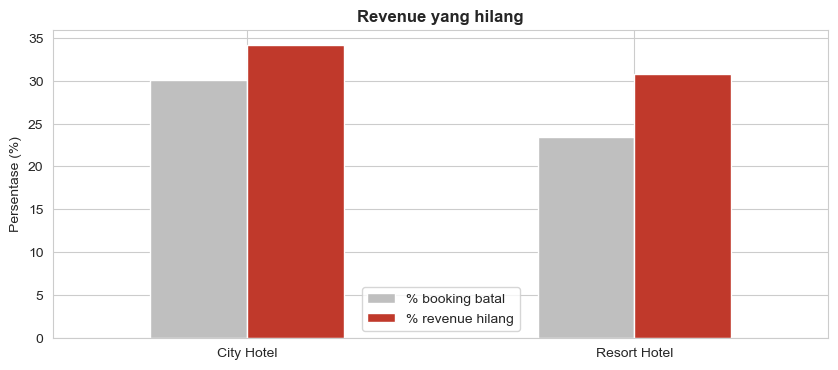

             total_nights     adr
is_canceled                      
0                    3.48  102.22
1                    4.01  117.63


In [95]:
banding.plot.bar(color=[ABU, SOROT])
plt.title('Revenue yang hilang', loc='center')
plt.xticks(rotation=0)
plt.ylabel('Persentase (%)'); plt.xlabel('')
plt.show()

print(df.groupby('is_canceled')[['total_nights', 'adr']].mean().round(2))

"Revenue hilang" di atas adalah nilai kotor booking yang batal dan tidak membayar. Berapa jumlah malam yang masih bisa dijual akan dijelaskan nanti.

#### **2. Kapan pembatalan terjadi?**
Pembatalan jauh hari masih memberi waktu untuk menjual ulang kamar. Pembatalan mepet hanya menyisakan sedikit waktu.

In [96]:
# pembuatan variabel cxl = booking berstatus 'Canceled' (.copy())
cxl = df[df['reservation_status'] == 'Canceled'].copy()


Selanjutnya akan dilakukan penghitungan jarak hari antara tanggal pembatalan dengan tanggal kedatangan.

In [97]:
cxl['days_before_arrival'] = (cxl['arrival_date'] - cxl['reservation_status_date']).dt.days
print(cxl['days_before_arrival'].describe().round(1))
print('Median hari setelah booking dibuat:', (cxl['lead_time'] - cxl['days_before_arrival']).median())

count    22995.0
mean        66.1
std         72.6
min          0.0
25%         13.0
50%         38.0
75%         97.0
max        526.0
Name: days_before_arrival, dtype: float64
Median hari setelah booking dibuat: 13.0


Median pembatalan terjadi **38 hari sebelum kedatangan**, atau **13 hari setelah booking dibuat**. Separuh pembatalan terjadi dalam 13 hari pertama setelah booking dibuat. Lalu untuk mempermudah pengelompokan waktu pembatalan akan dibuat labelling.

In [98]:
cxl['waktu_batal'] = pd.cut(cxl['days_before_arrival'], bins=[-1, 0, 7, 30, 90, 1000],
                            labels=['Hari-H', '1-7 hari', '8-30 hari', '31-90 hari', '>90 hari'])

Setelah pembuatan label akan dihitung persentase batal dan persentase revenue-nya

In [99]:
persen_batal = cxl['waktu_batal'].value_counts(normalize=True).sort_index().mul(100).round(1)
persen_revenue = (cxl.groupby('waktu_batal')['revenue_hilang'].sum() / cxl['revenue_hilang'].sum() * 100).round(1)
print(persen_batal, '\n')
print(persen_revenue)

waktu_batal
Hari-H         3.3
1-7 hari      13.0
8-30 hari     27.9
31-90 hari    28.8
>90 hari      27.0
Name: proportion, dtype: float64 

waktu_batal
Hari-H         1.7
1-7 hari       9.6
8-30 hari     26.2
31-90 hari    30.1
>90 hari      32.3
Name: revenue_hilang, dtype: float64


**16,2% pembatalan terjadi ≤ 7 hari sebelum kedatangan** (3,3% di Hari-H), tetapi nilainya hanya **11,3% revenue hilang** dari pembatalan.

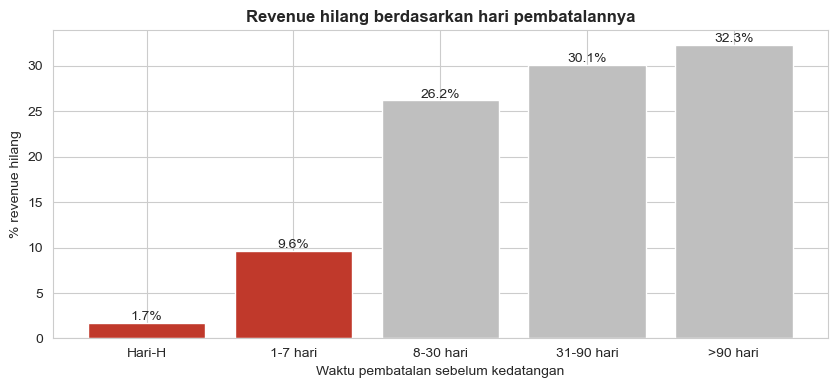

In [100]:
warna = [SOROT, SOROT, ABU, ABU, ABU]        # Hari-H dan 1-7 hari diberi warna merah
bar = plt.bar(persen_revenue.index.astype(str), persen_revenue, color=warna)
plt.bar_label(bar, fmt='%.1f%%')
plt.title('Revenue hilang berdasarkan hari pembatalannya', loc='center')
plt.xlabel('Waktu pembatalan sebelum kedatangan'); plt.ylabel('% revenue hilang')
plt.show()

Sisanya, **88,7%** revenue hilang dari pembatalan, dilepas lebih dari 7 hari sebelum kedatangan. Kamar ini masih punya waktu untuk dijual lagi.

#### **3. Market segment mana yang membatalkan last minute?**

In [101]:
cxl['lastminute'] = cxl['days_before_arrival'] <= 7        # True = batal 7 hari atau kurang sebelum datang
lastminute = cxl.groupby('market_segment')['lastminute'].agg(['count', 'mean'])
lastminute.columns = ['jumlah_batal', 'persen_lastminute']
lastminute['persen_lastminute'] = (lastminute['persen_lastminute'] * 100).round(1)
lastminute = lastminute[lastminute['jumlah_batal'] >= 100].sort_values('persen_lastminute')
print(lastminute)


                jumlah_batal  persen_lastminute
market_segment                                 
Online TA              17711               12.2
Offline TA/TO           1881               18.0
Groups                  1296               21.0
Direct                  1557               37.6
Corporate                440               64.8


**Corporate: 64,8%** pembatalannya mepet. Direct 37,6%, sedangkan **Online TA hanya 12,2%**. Lalu akan divisualisasikan untuk persentasenya.

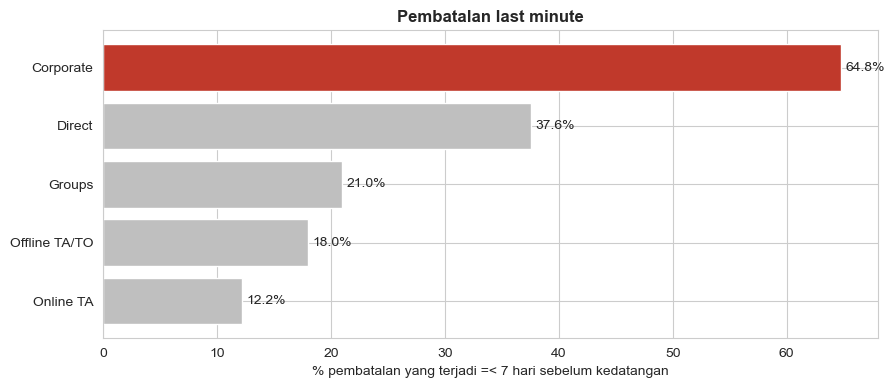

In [102]:
warna = np.where(lastminute['persen_lastminute'] == lastminute['persen_lastminute'].max(), SOROT, ABU)
bar = plt.barh(lastminute.index, lastminute['persen_lastminute'], color=warna)
plt.bar_label(bar, fmt='%.1f%%', padding=3)
plt.title('Pembatalan last minute')
plt.xlabel('% pembatalan yang terjadi =< 7 hari sebelum kedatangan')
plt.show()

Dari grafik di atas terlihat bahwa Online TA sering batal tetapi jauh hari; Corporate jarang batal tetapi hampir selalu last minute. Selanjutnya setelah pembatalan last minute, no show booking juga akan diperiksa.

No-show adalah pembatalan paling mepet: booking tetap ada sampai hari kedatangan, lalu tamunya tidak datang. Segment mana yang paling sering no-show?

In [103]:
# df['no_show'] = 1 kalau reservation_status 'No-Show', selain itu 0 (np.where)
df['no_show'] = np.where(df['reservation_status'] == 'No-Show', 1, 0)

# pemeriksaan persentase no show dari keseluruhan bookings
print(f"No-show dari seluruh booking: {df['no_show'].mean():.2%}")

No-show dari seluruh booking: 1.16%


No-show hanya **1,16%** dari seluruh booking, tetapi kamarnya tidak punya waktu sama sekali untuk dijual lagi.

Lalu setelah sudah ditentukan variabel no-show-nya, akan diperiksa per market_segment: jumlah booking dan % no-show; ambil market segment >= 100 booking

In [104]:

noshow_seg = df.groupby('market_segment')['no_show'].agg(['count', 'mean'])
noshow_seg.columns = ['jumlah_booking', 'persen_no_show']
noshow_seg['persen_no_show'] = (noshow_seg['persen_no_show'] * 100).round(2)
noshow_seg = noshow_seg[noshow_seg['jumlah_booking'] >= 100].sort_values('persen_no_show')
noshow_seg

,jumlah_booking,persen_no_show
market_segment,,
Groups,4921,0.73
Online TA,51553,1.03
Offline TA/TO,13854,1.26
Direct,11780,1.53
Complementary,692,1.59
Corporate,4200,1.64
Aviation,226,4.87


Lalu dibandingkan median booking dari booking no show dan juga keseluruhan booking.

In [105]:
print(f"Median lead time booking no-show : {df[df['no_show'] == 1]['lead_time'].median()} hari")
print(f"Median lead time semua booking   : {df['lead_time'].median()} hari")

Median lead time booking no-show : 27.0 hari
Median lead time semua booking   : 49.0 hari


Booking no-show dibuat lebih last minute: median lead time **27 hari**, dibanding 49 hari untuk semua booking.

Setelah semuanya sudah berhasil didapatkan, kita visualisasikan agar proses analisis lebih mudah dilakukan.

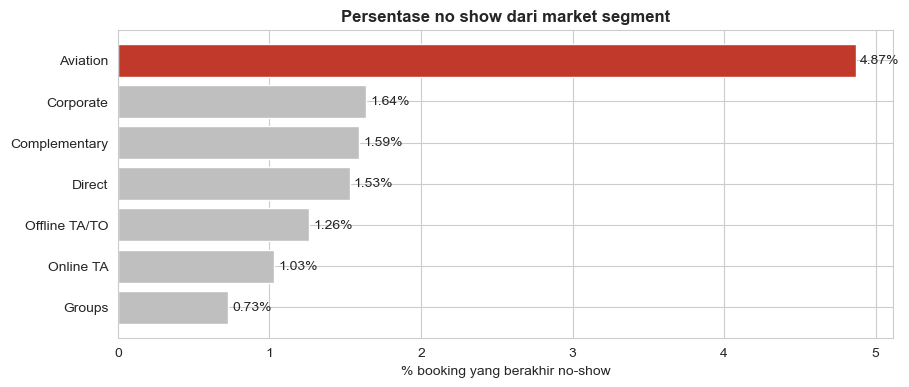

In [106]:
warna = np.where(noshow_seg['persen_no_show'] == noshow_seg['persen_no_show'].max(), SOROT, ABU)
bar = plt.barh(noshow_seg.index, noshow_seg['persen_no_show'], color=warna)
plt.bar_label(bar, fmt='%.2f%%', padding=3)
plt.title('Persentase no show dari market segment')
plt.xlabel('% booking yang berakhir no-show')
plt.show()

Urutannya berbeda dari cancel rate. **Aviation 4,87%**, Corporate 1,64%, dan Direct 1,53% berada di atas rata-rata. **Online TA hanya 1,03%**, padahal cancel rate-nya paling tinggi (35,4%)

#### **4. Apakah masalahnya makin parah?**
Tahun yang lengkap hanya 2016, jadi perbandingan memakai **Januari-Agustus 2016 vs 2017** (8 bulan yang tersedia di kedua tahun). Tahun 2015 tidak dipakai karena data City 2015 didominasi duplikat (52,1%).

In [107]:
jan_agu = df[(df['arrival_month'] <= 8) & (df['arrival_date_year'].isin([2016, 2017]))]

Pembuatan variabel tren untuk mencari revenue loss.

In [108]:
tren_rugi = loss_rate_pivot(jan_agu, 'arrival_date_year', 'hotel')

Selanjutnya, perhitungan revenue loss rate (%), Jumlah Bookingnya, Rata-rata ADR nya, Potensi Revenue dalam euro, Revenue masuk dalam euro, Porsi Online TA (%)

In [109]:
print('Revenue loss rate (%)')
print(tren_rugi.round(1))

Revenue loss rate (%)
hotel              City Hotel  Resort Hotel
arrival_date_year                          
2016                     32.2          29.6
2017                     38.0          37.0


Revenue loss rate naik di kedua hotel: City dari **32,2% ke 38,0%** (+5,8 poin) dan Resort dari **29,6% ke 37,0%** (+7,4 poin). Cancel rate naik searah, City dari 27,8% ke 34,1% dan Resort dari 21,9% ke 28,3%.

In [110]:
print('Cancel rate (%)')
print((jan_agu.pivot_table(index='arrival_date_year', columns='hotel', values='is_canceled', aggfunc='mean') * 100).round(1))

Cancel rate (%)
hotel              City Hotel  Resort Hotel
arrival_date_year                          
2016                     27.8          21.9
2017                     34.1          28.3


Cancel rate naik searah (City 27,8% ke 34,1%, Resort 21,9% ke 28,3%)

In [111]:
print('Rata-rata ADR (€)')
print(jan_agu.pivot_table(index='arrival_date_year', columns='hotel', values='adr', aggfunc='mean').round(1))

Rata-rata ADR (€)
hotel              City Hotel  Resort Hotel
arrival_date_year                          
2016                    106.8          98.3
2017                    122.3         113.1


Rata-rata ADR naik dari €106,8 ke €122,3 (City) dan dari €98,3 ke €113,1 (Resort).

In [112]:
print('Potensi revenue (€)')
print(jan_agu.pivot_table(index='arrival_date_year', columns='hotel', values='revenue', aggfunc='sum').round(0), '\n')

Potensi revenue (€)
hotel              City Hotel  Resort Hotel
arrival_date_year                          
2016                5784648.0     4701536.0
2017                8015588.0     6266188.0 



Karena booking dan harga sama-sama naik, potensi revenue City naik **38,6%** dan Resort **33,3%**. Revenue yang masuk hanya naik **26,0%** (City) dan **19,5%** (Resort), jadi sebagian pertumbuhan hilang karena pembatalan.

In [113]:
print('Revenue masuk (€)')
print(jan_agu[jan_agu['is_canceled'] == 0].pivot_table(index='arrival_date_year', columns='hotel', values='revenue', aggfunc='sum').round(0))

Revenue masuk (€)
hotel              City Hotel  Resort Hotel
arrival_date_year                          
2016                3881685.0     3290986.0
2017                4891075.0     3931306.0


Revenue masuk naik (City +26,0%, Resort +19,5%), tetapi kalah cepat dari potensi revenue, sehingga porsi yang lolos dari pembatalan turun (City dari 67,1% ke 61,0%, Resort dari 70,0% ke 62,7%).

In [114]:
print('Porsi Online TA (%)')
print(jan_agu.groupby('arrival_date_year')['market_segment'].apply(lambda x: (x == 'Online TA').mean() * 100).round(1))

Porsi Online TA (%)
arrival_date_year
2016    59.6
2017    65.0
Name: market_segment, dtype: float64


Porsi Online TA naik dari 59,6% ke 65,0%. Segmen ini yang paling banyak kehilangan nilai, jadi perubahan komposisi ini mungkin ikut mendorong kenaikan pembatalan.

Selanjutnya memvisualisasikan revenue loss rate agar proses analisis menjadi lebih mudah.

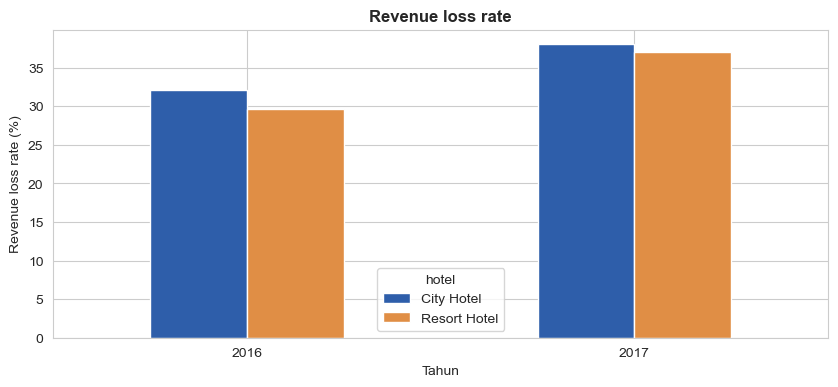

In [115]:
tren_rugi.plot.bar(color=[WARNA_HOTEL['City Hotel'], WARNA_HOTEL['Resort Hotel']])
plt.title('Revenue loss rate')
plt.xticks(rotation=0)
plt.xlabel('Tahun')
plt.ylabel('Revenue loss rate (%)')
plt.show()

Dapat dilihat dari grafik di atas bahwa kedua hotel mengalami kenaikan loss rate.

### **C. Faktor pembatalan** (pertanyaan B)
4.B menunjukkan kerugiannya besar dan makin naik. Pertanyaan berikutnya: booking seperti apa yang batal, dan di mana nilai yang hilang paling besar?

- **Faktor utama:** revenue loss rate per kategori, satu variabel sekaligus. Hasilnya diringkas menjadi peringkat: semakin besar selisih revenue loss rate antara kategori tertinggi dan terendah, semakin kuat hubungan faktor itu dengan revenue yang hilang. Selisih cancel rate ditampilkan sebagai pembanding.
- **Pengujian Faktor utama:** faktor utama diuji ulang dengan **pivot 2 dimensi** untuk memastikan polanya tidak disebabkan variabel lain (variabel perancu).

#### **1. Faktor utama**
Akan dikelompokkan mulai dari special request, penggantian kamar, previous cancel, tamu repeat, parking, hingga waiting list.

In [116]:
df['request_grp'] = pd.cut(df['total_of_special_requests'], bins=[-1, 0, 1, 2, 5], labels=['0', '1', '2', '3+'])
df['changes_grp'] = pd.cut(df['booking_changes'], bins=[-1, 0, 1, 2, 30], labels=['0', '1', '2', '3+'])
df['pernah_batal'] = np.where(df['previous_cancellations'] > 0, 'Pernah', 'Belum pernah')
df['pernah_menginap'] = np.where(df['previous_bookings_not_canceled'] > 0, 'Pernah', 'Belum pernah')
df['parking_grp'] = np.where(df['required_car_parking_spaces'] > 0, 'Minta parkir', 'Tidak')
df['waiting_grp'] = np.where(df['days_in_waiting_list'] > 0, 'Pernah waiting list', 'Langsung')

Selanjutnya setelah pembuatan kelompok kategori-kategori yang akan dibandingkan (hotel, lead_bin, market_segment, ... room_changed). 


In [117]:
faktor = ['hotel', 'lead_bin', 'market_segment', 'distribution_channel', 'customer_type', 'deposit_type',
          'request_grp', 'changes_grp', 'is_repeated_guest', 'pernah_batal', 'pernah_menginap',
          'has_company', 'meal', 'guest_type', 'stay_type', 'arrival_weekday', 'arrival_date_month',
          'room_tier', 'waiting_grp', 'parking_grp', 'room_changed']

- Untuk tiap faktor (for loop): t = cancel_rate(df, f), ambil kategori >= 100 booking dan potensi_revenue > 0
catat kategori tertinggi dan terendah (idxmax / idxmin), selisih revenue loss rate, dan selisih cancel rate
- Jadikan DataFrame rekap, urutkan dari selisih terbesar
- Simpan ke variabel (dipakai lagi di sel berikutnya): faktor, rekap
- Pakai fungsi: cancel_rate

In [118]:
rekap = []
for f in faktor:
    t = cancel_rate(df, f)
    t = t[(t['jumlah_booking'] >= 100) & (t['potensi_revenue'] > 0)]
    tertinggi = t['revenue_loss_rate'].max()
    terendah = t['revenue_loss_rate'].min()
    # idxmax() / idxmin() = nama kategori yang punya nilai tertinggi / terendah
    rekap.append([f, t['revenue_loss_rate'].idxmax(), tertinggi, t['revenue_loss_rate'].idxmin(), terendah, tertinggi - terendah,
                  t['cancel_rate'].max() - t['cancel_rate'].min()])

rekap = pd.DataFrame(rekap, columns=['faktor', 'kategori_tertinggi', 'loss_rate_tertinggi',
                                     'kategori_terendah', 'loss_rate_terendah', 'selisih', 'selisih_cancel_rate'])
rekap = rekap.sort_values('selisih', ascending=False)
rekap

,faktor,kategori_tertinggi,loss_rate_tertinggi,kategori_terendah,loss_rate_terendah,selisih,selisih_cancel_rate
5,deposit_type,Refundable,44.0,Non Refund,0.0,44.0,70.4
9,pernah_batal,Pernah,75.7,Belum pernah,32.0,43.7,41.3
2,market_segment,Online TA,41.7,Complementary,5.3,36.4,23.3
19,parking_grp,Tidak,35.6,Minta parkir,0.0,35.6,30.0
20,room_changed,Tidak,35.4,Ya,4.8,30.6,26.8
1,lead_bin,181-365,40.2,0-7,10.8,29.4,32.4
10,pernah_menginap,Belum pernah,33.1,Pernah,5.7,27.4,23.5
6,request_grp,0,40.9,3+,15.9,25.0,17.1
4,customer_type,Transient,35.9,Group,12.2,23.7,20.3
11,has_company,Tidak,33.2,Ya,10.6,22.6,17.7


Setelah dilakukan proses di atas akan divisualisasikan akan mudah terlihat revenue loss rate per kategori dan membandingkannya.

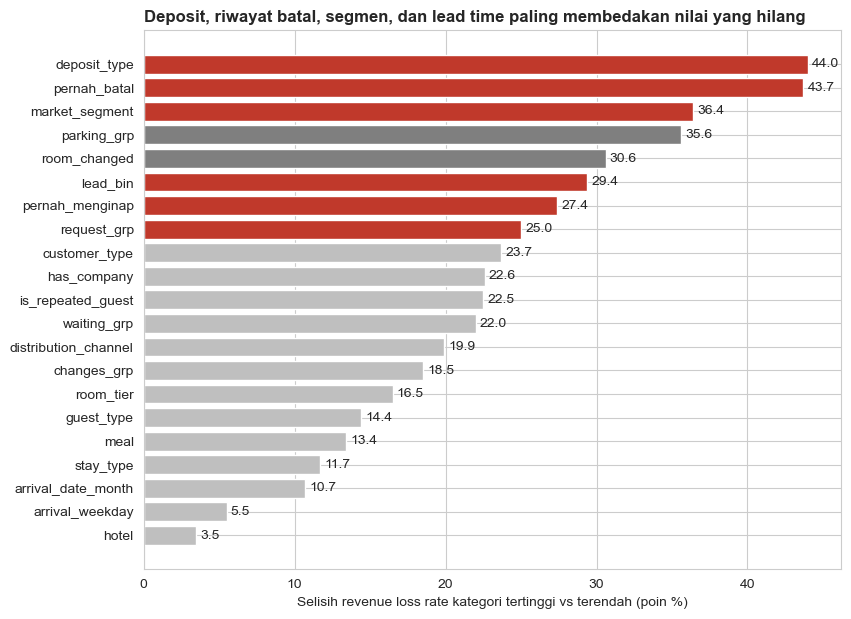

In [119]:
r = rekap.sort_values('selisih')
r['warna'] = ABU
r.loc[r['selisih'] >= 25, 'warna'] = SOROT
r.loc[r['faktor'].isin(['parking_grp', 'room_changed']), 'warna'] = '#7F7F7F'   # dicatat saat check-in, dibahas di 4.D

plt.figure(figsize=(9, 7))
bar = plt.barh(r['faktor'], r['selisih'], color=r['warna'])
plt.bar_label(bar, fmt='%.1f', padding=3)
plt.title('Deposit, riwayat batal, segmen, dan lead time paling membedakan nilai yang hilang', loc='left')
plt.xlabel('Selisih revenue loss rate kategori tertinggi vs terendah (poin %)')
plt.show()

- Selisih terbesar ada di deposit type (44 poin), riwayat pembatalan (44), market segment (36), lead time (29), riwayat menginap (27), special request (25), dan customer type (24). Hari kedatangan (5,5) dan hotel (3,5) paling kecil; pola hari kedatangan dicek lagi di 4.G.3.
- Dibanding selisih cancel rate, deposit turun dari 70 ke 44 poin karena Non Refund yang batal tetap membayar, market segment naik dari 23 ke 36 karena booking Online TA yang batal bernilai lebih besar, dan lead time turun dari 32 ke 29 karena booking di atas 365 hari yang batal bernilai kecil.
- Deposit di urutan pertama hanya karena definisi (Non Refund 0%) dan kelompok Refundable yang kecil (107 booking), padahal 99,2% potensi revenue ada di No Deposit. Faktor perilaku terkuat adalah riwayat pembatalan dan market segment.
- parking_grp (36) dan room_changed (31) diberi warna abu gelap karena nilainya tidak sebanding antara booking batal dan booking yang datang.

#### **2. Detail 6 faktor utama**
Enam faktor dibahas dengan urutan deposit, riwayat pembatalan, lead time, market segment, customer type, lalu special request. Urutan ini berasal dari peringkat cancel rate di versi sebelumnya. Dengan revenue, market segment naik ke atas lead time dan special request ke atas customer type, tetapi urutan pembahasan dipertahankan supaya alurnya sama. Riwayat menginap dan status tamu repeat dibahas bersama riwayat pembatalan, karena ketiganya sama-sama kolom riwayat tamu.

##### **a. Deposit type**

Selanjutnya kita akan melihat cancel rate dari tiap tipe deposit.

              revenue_loss_rate  cancel_rate  jumlah_booking  revenue_hilang  \
deposit_type                                                                   
No Deposit                 32.9         26.7           86084     11226895.38   
Non Refund                  0.0         94.7            1037            0.00   
Refundable                 44.0         24.3             107        14390.17   

              potensi_revenue  forfeited_rate  
deposit_type                                   
No Deposit        34165236.80             0.0  
Non Refund          248331.30            95.6  
Refundable           32686.83             0.0  


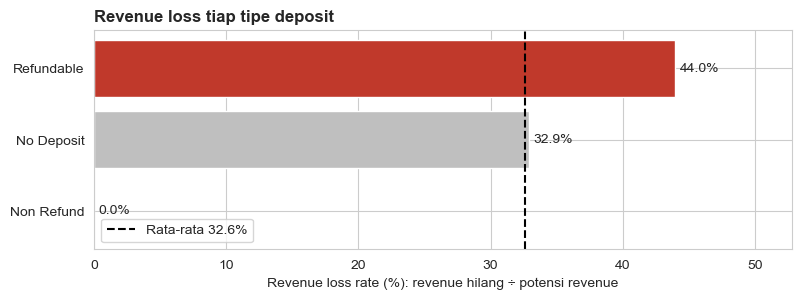

In [120]:
t = cancel_rate(df, 'deposit_type')
t['forfeited_rate'] = (df.groupby('deposit_type')['forfeited_deposit_revenue'].sum() / t['potensi_revenue'] * 100).round(1)
print(t)
plot_cancel_rate(t, 'Revenue loss tiap tipe deposit')


Non Refund batal **94,7%**, tetapi booking ini sudah dibayar penuh, jadi revenue loss rate-nya **0%** dan **95,6%** nilainya tercatat sebagai Forfeited Deposit Revenue. Angka 0% ini datang dari definisi, bukan dari perilaku tamu. No Deposit kehilangan **32,9%** nilainya (cancel rate 26,7%). Refundable tertinggi (44,0%).

##### **b. Riwayat tamu**

              revenue_loss_rate  cancel_rate  jumlah_booking  revenue_hilang  \
pernah_batal                                                                   
Belum pernah               32.0         26.7           85547     10889770.05   
Pernah                     75.7         68.0            1681       351515.50   

              potensi_revenue  
pernah_batal                   
Belum pernah      33982077.47  
Pernah              464177.46   

                 revenue_loss_rate  cancel_rate  jumlah_booking  \
pernah_menginap                                                   
Belum pernah                  33.1         28.5           83691   
Pernah                         5.7          5.0            3537   

                 revenue_hilang  potensi_revenue  
pernah_menginap                                   
Belum pernah        11206395.47      33838160.80  
Pernah                 34890.08        608094.13   

                   revenue_loss_rate  cancel_rate  jumlah_booking  \
is_re

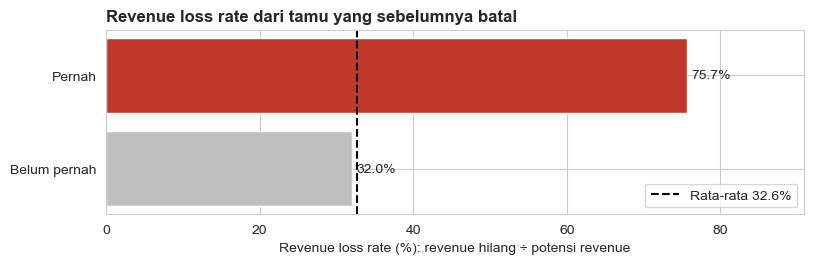

In [121]:
t = cancel_rate(df, 'pernah_batal')
print(t, '\n')
print(cancel_rate(df, 'pernah_menginap'), '\n')
print(cancel_rate(df, 'is_repeated_guest'))
plot_cancel_rate(t, 'Revenue loss rate dari tamu yang sebelumnya batal')


- Booking dari tamu yang pernah membatalkan kehilangan **75,7%** nilainya (cancel rate 68,0%).
- Sebaliknya, tamu yang pernah menginap tanpa batal hanya kehilangan 5,7% (cancel rate 5,0%), dan tamu repeat 10,5% vs tamu baru 33,0%.
- Sinyalnya kuat, tetapi cakupannya kecil: tamu yang pernah batal hanya membawa 1,3% potensi revenue, tamu repeat hanya 3,86% booking (4.A.12), dan kolom riwayat tidak sepenuhnya konsisten.

##### **c. Lead time**

          revenue_loss_rate  cancel_rate  jumlah_booking  revenue_hilang  \
lead_bin                                                                   
0-7                    10.8          8.4           18203       381488.81   
8-30                   30.5         25.4           16326      1758436.60   
31-90                  34.2         32.0           22719      3270213.12   
91-180                 36.0         35.0           18224      3390811.03   
181-365                40.2         39.7           11192      2407062.01   
>365                   20.1         40.8             564        33273.98   

          potensi_revenue  
lead_bin                   
0-7            3533193.10  
8-30           5762630.06  
31-90          9568791.84  
91-180         9423945.03  
181-365        5992358.21  
>365            165336.69  


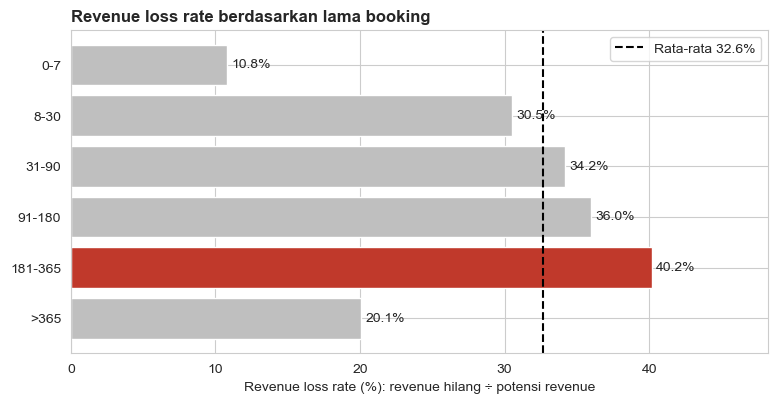

In [122]:
t = cancel_rate(df, 'lead_bin')
print(t)
plot_cancel_rate(t, 'Revenue loss rate berdasarkan lama booking', urut=False)

Booking 0-7 hari sebelum kedatangan hanya kehilangan **10,8%** nilainya, lalu naik sampai **40,2%** untuk 181-365 hari. Di atas 365 hari angkanya turun ke 20,1%, padahal cancel rate-nya tertinggi (40,8%): booking sejauh ini hanya 564, dan yang batal bernilai lebih kecil dari rata-rata kelompoknya.

##### **d. Market segment**

                revenue_loss_rate  cancel_rate  jumlah_booking  \
market_segment                                                   
Aviation                     16.9         19.9             226   
Complementary                 5.3         12.3             692   
Corporate                    16.7         12.1            4200   
Direct                       19.1         14.7           11780   
Groups                       13.6         27.1            4921   
Offline TA/TO                13.7         14.8           13854   
Online TA                    41.7         35.4           51553   
Undefined                   100.0        100.0               2   

                revenue_hilang  potensi_revenue  
market_segment                                   
Aviation              14065.00         83033.36  
Complementary           269.99          5074.52  
Corporate             99120.25        594144.08  
Direct               928553.83       4855042.75  
Groups               168339.89       12

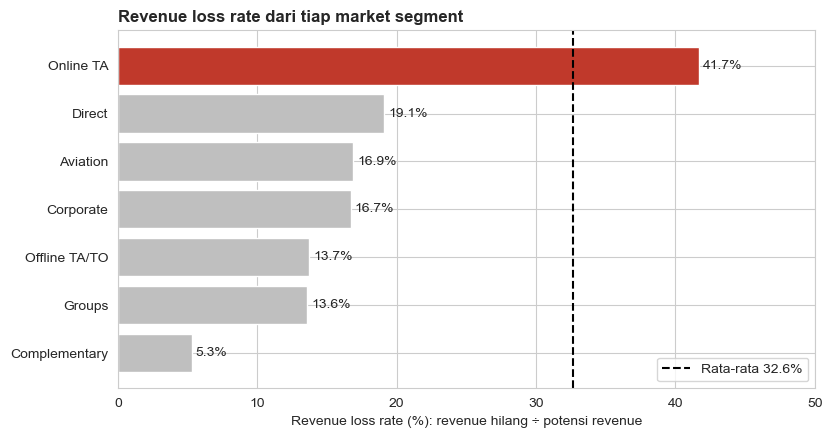

In [123]:
t = cancel_rate(df, 'market_segment')
print(t)
plot_cancel_rate(t, 'Revenue loss rate dari tiap market segment')

Online TA kehilangan **41,7%** nilainya (cancel rate 35,4%), sedangkan Direct 19,1%, Corporate 16,7%, Offline TA/TO 13,7%, dan Groups 13,6%. Groups batal 27,1%, tetapi nilai yang hilang hanya 13,6%, karena booking Groups yang batal bernilai lebih kecil dari rata-rata Groups. Apakah OTA tinggi hanya karena booking-nya dibuat jauh hari? Diuji di 4.C.3.

##### **e. Customer type**

                 revenue_loss_rate  cancel_rate  jumlah_booking  \
customer_type                                                     
Contract                      14.1         16.3            3135   
Group                         12.2          9.8             541   
Transient                     35.9         30.1           71861   
Transient-Party               14.1         15.3           11691   

                 revenue_hilang  potensi_revenue  
customer_type                                     
Contract              232270.37       1641846.82  
Group                  16639.59        135837.06  
Transient           10507024.74      29234626.89  
Transient-Party       485350.85       3433944.16  


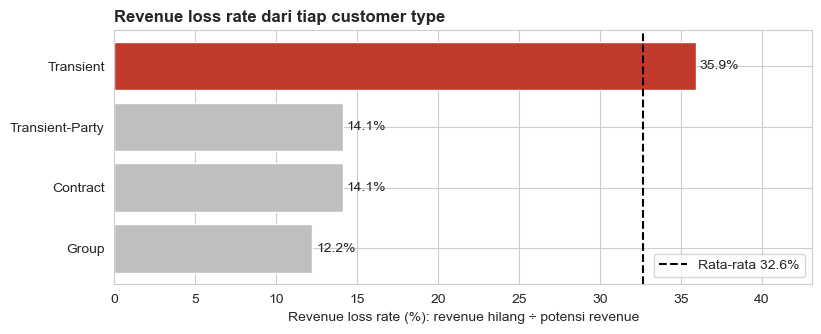

In [124]:
t = cancel_rate(df, 'customer_type')
print(t)
plot_cancel_rate(t, 'Revenue loss rate dari tiap customer type')

Tamu Transient (individu) kehilangan **35,9%** nilainya, sekitar 2,5 kali Transient-Party dan Contract (14,1%). Group hanya 12,2%. Transient membawa 84,9% potensi revenue (4.A.10), jadi faktor ini terlalu lebar untuk dijadikan sasaran kebijakan sendiri.

##### **f. Special request & perubahan booking**

Pembuatan cancel rate untuk request dan perubahan booking/kamar

In [125]:
# cancel_rate untuk request_grp dan changes_grp
t = cancel_rate(df, 'request_grp')
print(t, '\n')
print(cancel_rate(df, 'changes_grp'))


             revenue_loss_rate  cancel_rate  jumlah_booking  revenue_hilang  \
request_grp                                                                   
0                         40.9         33.3           43787      6510665.25   
1                         27.3         22.4           28976      3225993.99   
2                         24.0         21.3           11795      1283665.03   
3+                        15.9         16.2            2670       220961.28   

             potensi_revenue  
request_grp                   
0                15902070.47  
1                11799773.19  
2                 5358500.69  
3+                1385910.58   

             revenue_loss_rate  cancel_rate  jumlah_booking  revenue_hilang  \
changes_grp                                                                   
0                         35.9         30.2           71425      9942135.84   
1                         17.8         13.9           10867       794131.63   
2                    

Pembuatan kolom variabel baru untuk menghitung berapa lama booking ada sebelum dibatalkan.

In [126]:
cxl['lama_bertahan'] = pd.cut(cxl['lead_time'] - cxl['days_before_arrival'], bins=[-1, 0, 7, 30, 90, 800],
                              labels=['batal di hari booking', '1-7 hari', '8-30 hari', '31-90 hari', '>90 hari'])
bertahan = cxl.groupby('lama_bertahan')[['total_of_special_requests', 'booking_changes']].mean()
bertahan.loc['menginap (check-out)'] = df[df['is_canceled'] == 0][['total_of_special_requests', 'booking_changes']].mean()
print(bertahan.round(2))

                       total_of_special_requests  booking_changes
lama_bertahan                                                    
batal di hari booking                       0.23             0.06
1-7 hari                                    0.52             0.12
8-30 hari                                   0.59             0.16
31-90 hari                                  0.60             0.19
>90 hari                                    0.65             0.26
menginap (check-out)                        0.76             0.31


Setelah semua data sudah di dapatkan akan dilakukan visualisasi

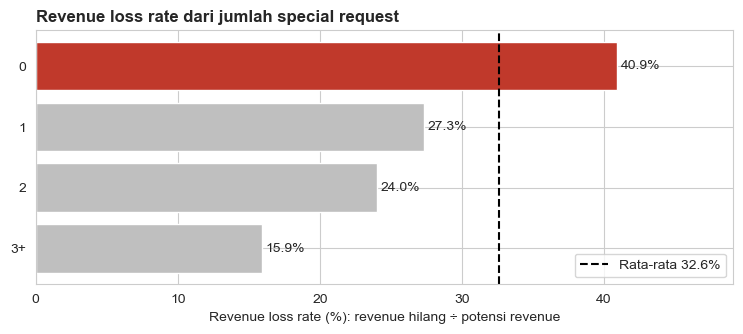

In [127]:
plot_cancel_rate(t, 'Revenue loss rate dari jumlah special request', urut=False)

- Special request: tanpa request kehilangan 40,9% nilai (cancel rate 33,3%), 1 request 27,3%, 3 request atau lebih 15,9%. Perubahan booking: 0 perubahan 35,9% vs 1 perubahan 17,8%.

#### **3. Online TA sering batal karena OTA-nya, atau karena lead time-nya panjang?**
Kalau booking OTA kebanyakan dibuat jauh hari, cancel rate OTA yang tinggi bisa saja disebabkan lead time. Untuk memisahkan keduanya, bandingkan segmen di dalam rentang lead time yang sama. Perbandingan ini dihitung per hotel, karena komposisi segmen City dan Resort berbeda dan kebijakan deposit ditetapkan per hotel.

Pembuatan variabel baru seg_utama yang berisi market segment (Online TA, Offline TA, Direct, Groups, Corporate), serta judul untuk grafik yang akan digunakan.

In [128]:
seg_utama = ['Online TA', 'Offline TA/TO', 'Direct', 'Groups', 'Corporate']
judul = {'City Hotel': 'Loss rate dari market segment utama berdasarkan lama waktu booking pada City Hotel',
         'Resort Hotel': 'Loss rate dari market segment utama berdasarkan lama waktu booking pada Resort Hotel'}

Setelah pembuatan variabel dari segment utama dan judul sudah selanjutnya akan dilakukan visualisasinya.

City Hotel - revenue loss rate (%) per segmen dan lead time:
lead_bin         0-7  8-30  31-90  91-180  181-365  >365
market_segment                                          
Corporate        9.0  14.7   17.5     NaN      NaN   NaN
Direct          10.8  31.1   24.3    19.6     22.4   NaN
Groups          14.8  11.2   14.6    11.8     15.3   7.5
Offline TA/TO    8.6  10.6   13.8    16.6     13.4  20.4
Online TA       15.0  38.9   41.6    44.0     52.8   NaN 



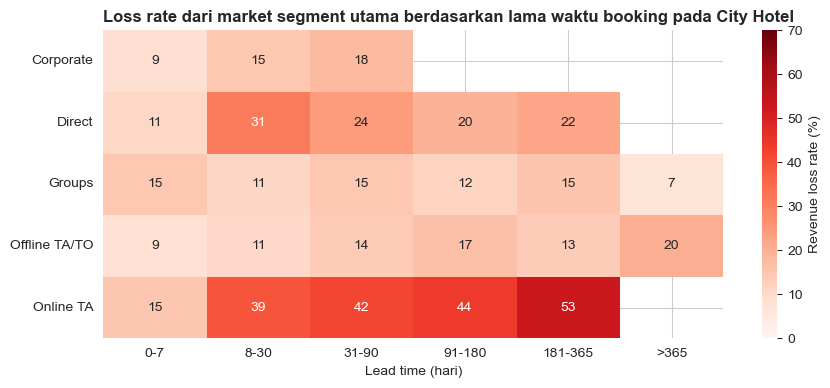

In [129]:
for hotel in ['City Hotel']:
    d = df[(df['market_segment'].isin(seg_utama)) & (df['hotel'] == hotel)]
    pv = loss_rate_pivot(d, 'market_segment', 'lead_bin')
    jumlah = d.pivot_table(index='market_segment', columns='lead_bin', values='is_canceled', aggfunc='count')
    pv[jumlah < 100] = np.nan      # sel yang isinya kurang dari 100 booking dikosongkan
    print(hotel, '- revenue loss rate (%) per segmen dan lead time:')
    print(pv.round(1), '\n')

    plt.figure(figsize=(10, 4))
    # vmin dan vmax membuat skala warna kedua hotel sama, supaya warnanya bisa dibandingkan
    sns.heatmap(pv, annot=True, fmt='.0f', cmap='Reds', vmin=0, vmax=70, cbar_kws={'label': 'Revenue loss rate (%)'})
    plt.title(judul[hotel], loc='left')
    plt.xlabel('Lead time (hari)'); plt.ylabel('')
    plt.show()

- **City:** di setiap rentang lead time 8-365 hari, Online TA kehilangan nilai paling besar (38,9-52,8%). Contoh rentang 31-90 hari: OTA 41,6%, Direct 24,3%, Corporate 17,5%, Offline TA/TO 13,8%.

Resort Hotel - revenue loss rate (%) per segmen dan lead time:
lead_bin        0-7  8-30  31-90  91-180  181-365  >365
market_segment                                         
Corporate       8.5  23.8   46.3     NaN      NaN   NaN
Direct          6.4  17.9   19.2    19.4     23.2   NaN
Groups          9.6  24.4   17.5    15.3     11.9   3.6
Offline TA/TO   8.3  11.9   11.1    13.8     15.6   NaN
Online TA       6.2  30.0   41.6    49.9     58.4   NaN 



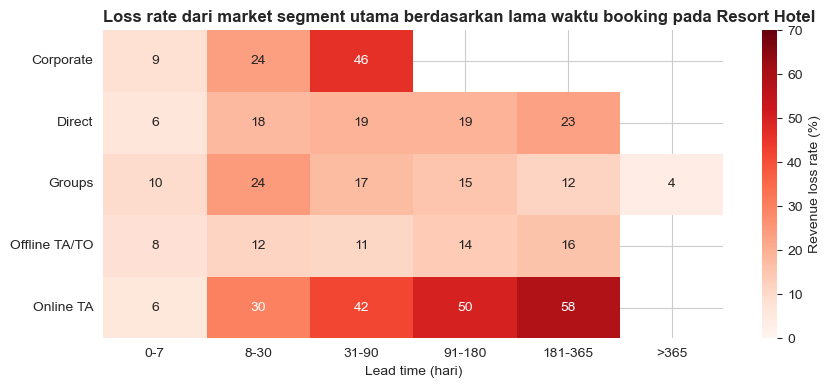

In [130]:
for hotel in ['Resort Hotel']:
    d = df[(df['market_segment'].isin(seg_utama)) & (df['hotel'] == hotel)]
    pv = loss_rate_pivot(d, 'market_segment', 'lead_bin')
    jumlah = d.pivot_table(index='market_segment', columns='lead_bin', values='is_canceled', aggfunc='count')
    pv[jumlah < 100] = np.nan      # sel yang isinya kurang dari 100 booking dikosongkan
    print(hotel, '- revenue loss rate (%) per segmen dan lead time:')
    print(pv.round(1), '\n')

    plt.figure(figsize=(10, 4))
    # vmin dan vmax membuat skala warna kedua hotel sama, supaya warnanya bisa dibandingkan
    sns.heatmap(pv, annot=True, fmt='.0f', cmap='Reds', vmin=0, vmax=70, cbar_kws={'label': 'Revenue loss rate (%)'})
    plt.title(judul[hotel], loc='left')
    plt.xlabel('Lead time (hari)'); plt.ylabel('')
    plt.show()

- **Resort:** Online TA paling besar di 8-30 hari (30,0%) dan di atas 90 hari (49,9% di 91-180 hari, 58,4% di 181-365 hari). Di rentang 31-90 hari, Corporate (46,3%) lebih tinggi dari OTA (41,6%).

Berdasarkan heatmap di atas akan didapatkan kesimpulan bahwa:
- Di kedua hotel, kehilangan OTA naik terus seiring lead time, sedangkan Offline TA/TO tetap rendah di semua rentang (City 8,6-20,4%, Resort 8,3-15,6%). Jadi tingginya kehilangan OTA tidak bisa dijelaskan oleh lead time saja; lead time dan channel sama-sama berperan.

#### **4. Apakah efek special request bertahan di dalam segmen yang sama?**

Penentuan judul untuk heatmapnya

In [131]:
judul = {'City Hotel': 'City: di tiap segmen, booking tanpa special request kehilangan nilai terbesar (Online TA 62%)',
         'Resort Hotel': 'Resort: pola yang sama, Online TA dari 62% tanpa request ke 20% dengan 3+ request'}


City Hotel - jumlah booking per segmen dan jumlah special request:
request_grp         0      1     2    3+
market_segment                          
Direct           3416   1315   589   218
Groups           2181    369    65     4
Offline TA/TO    5470   1478   243    47
Online TA       13233  14151  6219  1326 

City Hotel - revenue loss rate (%):
request_grp        0     1     2    3+
market_segment                        
Direct          25.3  15.6  17.2  14.5
Groups          15.1   4.4   NaN   NaN
Offline TA/TO   14.8  11.0  14.7   NaN
Online TA       61.8  30.6  23.6  19.2 



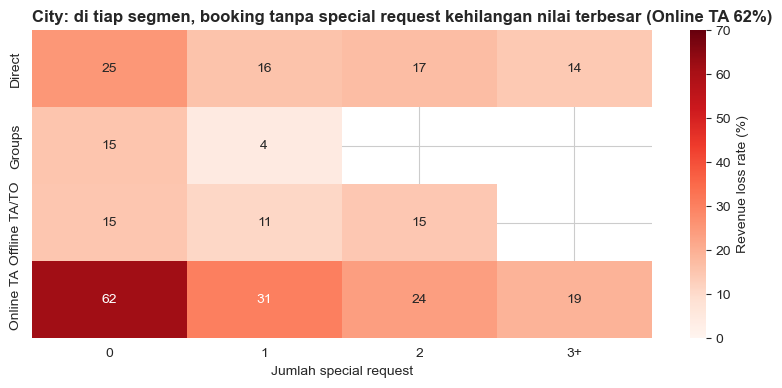

Resort Hotel - jumlah booking per segmen dan jumlah special request:
request_grp        0     1     2   3+
market_segment                       
Direct          3753  1596   668  225
Groups          2049   219    29    5
Offline TA/TO   4479  1605   443   89
Online TA       5422  7303  3240  659 

Resort Hotel - revenue loss rate (%):
request_grp        0     1     2    3+
market_segment                        
Direct          24.0  13.1  12.3   6.0
Groups          16.1   0.9   NaN   NaN
Offline TA/TO   15.4  12.4   7.4   NaN
Online TA       62.3  35.3  32.3  19.8 



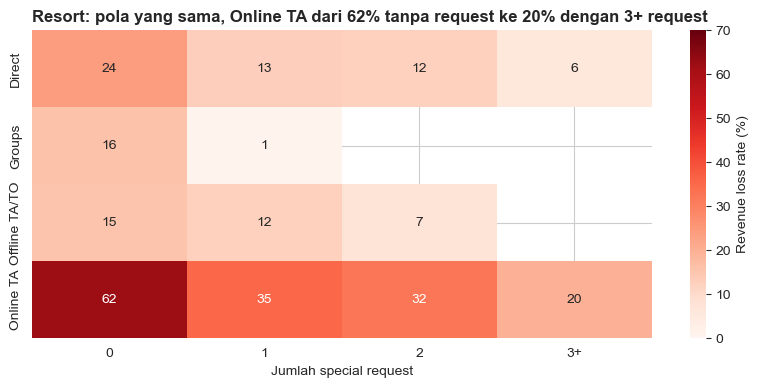

In [132]:
for hotel in ['City Hotel', 'Resort Hotel']:
    d = df[(df['market_segment'].isin(['Online TA', 'Offline TA/TO', 'Direct', 'Groups'])) & (df['hotel'] == hotel)]
    pv = loss_rate_pivot(d, 'market_segment', 'request_grp')
    jumlah = d.pivot_table(index='market_segment', columns='request_grp', values='is_canceled', aggfunc='count')
    pv[jumlah < 100] = np.nan      # sel yang isinya kurang dari 100 booking dikosongkan
    print(hotel, '- jumlah booking per segmen dan jumlah special request:')
    print(jumlah, '\n')
    print(hotel, '- revenue loss rate (%):')
    print(pv.round(1), '\n')

    plt.figure(figsize=(10, 4))
    sns.heatmap(pv, annot=True, fmt='.0f', cmap='Reds', vmin=0, vmax=70, cbar_kws={'label': 'Revenue loss rate (%)'})
    plt.title(judul[hotel], loc='left')
    plt.xlabel('Jumlah special request'); plt.ylabel('')
    plt.show()

- **Online TA** kehilangan **61,8%** nilai tanpa request di City dan **62,3%** di Resort. Dengan 3 request atau lebih, angkanya turun ke 19,2% dan 19,8%.
- Di setiap segmen kedua hotel, booking tanpa request kehilangan nilai paling besar. Contohnya Direct: City 25,3% tanpa request vs 14,5% dengan 3+ request, Resort 24,0% vs 6,0%. Di Offline TA/TO City selisihnya kecil (14,8% tanpa request, 14,7% dengan 2 request). Sel dengan kurang dari 100 booking dikosongkan, misalnya Groups dengan 2 request atau lebih.

#### **5. Apakah harga yang mahal membuat tamu cancel?**
Di permukaan, booking yang batal memang lebih mahal. Tetapi harga tinggi terjadi di musim ramai, dan musim ramai juga musim banyak pembatalan. Untuk memisahkannya, harga dibandingkan dengan median kamar sejenis di hotel dan bulan yang sama (harga relatif).

Selanjutnya akan dilihat median dari ADR booking yang batal.

In [133]:
print(df.groupby('is_canceled')['adr'].median())

is_canceled
0     94.89
1    109.80
Name: adr, dtype: float64


Median ADR booking batal €109,8 vs tidak batal €94,9. Sekilas, booking mahal lebih sering batal.

Lalu melihat median ADR untuk setiap kombinasi hotel + tahun + bulan + tipe kamar dilakukan seperti ini agar dapat dibandingkan harga dalam bulan yang sama (harga relatif)

In [134]:
kunci = ['hotel', 'arrival_date_year', 'arrival_date_month', 'reserved_room_type']
median_setara = df.groupby(kunci)['adr'].median().reset_index()
median_setara.columns = kunci + ['adr_median_setara']

Selanjutnya merge median dari harga relatif ke tiap booking, dan dibandingkan

In [135]:
harga = df.merge(median_setara, on=kunci, how='left')
harga['harga_relatif'] = harga['adr'] / harga['adr_median_setara']
harga['harga_relatif_grp'] = pd.cut(harga['harga_relatif'], bins=[0, 0.8, 0.95, 1.05, 1.2, 10],
                                    labels=['<80%', '80-95%', '95-105%', '105-120%', '>120%'])

Setelah semuanya sudah akan divisualisasikan.

                   revenue_loss_rate  cancel_rate  jumlah_booking  \
harga_relatif_grp                                                   
<80%                            21.9         20.5           15504   
80-95%                          34.5         29.6           18937   
95-105%                         36.6         31.4           15896   
105-120%                        36.3         30.7           16977   
>120%                           30.9         26.4           18265   

                   revenue_hilang  potensi_revenue  
harga_relatif_grp                                   
<80%                   1053886.16       4812289.41  
80-95%                 2461270.78       7123844.22  
95-105%                2402682.80       6566182.74  
105-120%               2681157.34       7386272.73  
>120%                  2641794.47       8555547.83  


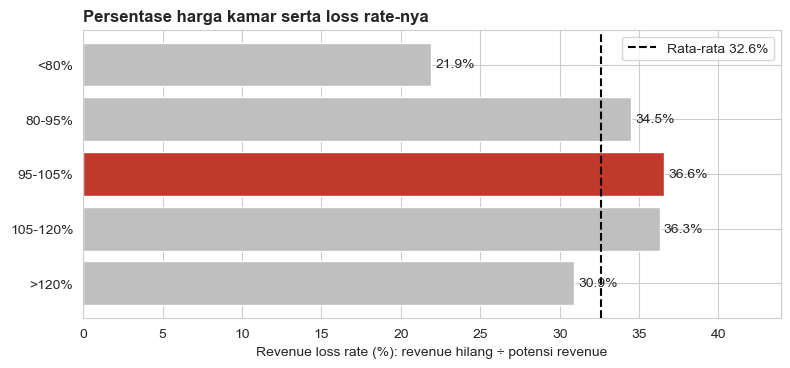

In [136]:
t = cancel_rate(harga, 'harga_relatif_grp')
print(t)
plot_cancel_rate(t, 'Persentase harga kamar serta loss rate-nya', urut=False)

- Setelah dibandingkan dengan kamar sejenis di bulan yang sama, polanya tidak linear: harga di bawah 80% median kehilangan **21,9%** nilai, sekitar median 36,6%, dan di atas 120% median 30,9%. Cancel rate berpola sama (20,5%, 31,4%, 26,4%).
- Jadi, setelah musim dan tipe kamar disamakan, harga yang lebih tinggi tidak diikuti kehilangan yang lebih tinggi. Selisih di permukaan datang dari musim dan tipe kamar. Booking dengan harga di bawah 80% median paling sedikit kehilangan nilai.

#### **6. Siapakah tamu yang non-refund?**
Booking yang sudah dibayar penuh dan tidak bisa di-refund seharusnya paling jarang batal. Profilnya perlu dicek.

Pembuatan variable nr sebagai booking non refund

In [137]:
# nr = booking Non Refund
nr = df[df['deposit_type'] == 'Non Refund']

Lalu melihat jumlah, cancel rate, median lead time (bandingkan semua booking)


In [138]:
print('Jumlah:', len(nr), '| cancel rate:', round(nr['is_canceled'].mean() * 100, 1), '%')
print('Median lead time:', nr['lead_time'].median(), 'hari (semua booking:', df['lead_time'].median(), 'hari)')
print('Rata-rata special request:', round(nr['total_of_special_requests'].mean(), 2), '\n')

Jumlah: 1037 | cancel rate: 94.7 %
Median lead time: 189.0 hari (semua booking: 49.0 hari)
Rata-rata special request: 0.02 



- 1.037 booking, **94,7% batal**, median lead time **189 hari** (semua booking: 49 hari), special request hampir nol.

Selanjutnya rata-rata special request 3 kategori teratas untuk hotel, market_segment, country, agent 

In [139]:
for kolom in ['hotel', 'market_segment', 'country', 'agent']:
    print(nr[kolom].value_counts(normalize=True).mul(100).round(1).head(3))

hotel
City Hotel      81.4
Resort Hotel    18.6
Name: proportion, dtype: float64
market_segment
Groups           63.5
Offline TA/TO    27.6
Corporate         6.2
Name: proportion, dtype: float64
country
PRT    94.7
GBR     1.4
DEU     1.3
Name: proportion, dtype: float64
agent
1    27.9
0    18.5
3     4.1
Name: proportion, dtype: float64


- Komposisinya sangat berbeda dari booking lain: lead time hampir empat kali lebih panjang, didominasi Groups, dan 92,9% barisnya duplikat yang sudah dihapus di 3.B. Karena itu cancel rate Non Refund tidak bisa dibandingkan langsung dengan No Deposit, dan tidak bisa dibaca sebagai "deposit membuat tamu batal".
- Karena sudah dibayar, pembatalan mereka tidak menjadi revenue hilang: €0,24 juta tercatat sebagai Forfeited Deposit Revenue (4.B.1).

#### **7. Apakah hari booking dibuat atau tanggal kedatangan ikut berpengaruh?**
Dua ciri kalender yang sudah diketahui saat booking dibuat juga dicek: hari booking dibuat dan tanggal kedatangan dalam bulan (awal, tengah, akhir). Tanggal booking dibuat dihitung dari tanggal kedatangan dikurangi lead_time.

Pembuatan variabel untuk urutan hari

In [140]:
urutan_hari = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

Setelah itu mengubah tanggal kedatangannya menjadi nama hari

In [141]:
df['booking_date'] = df['arrival_date'] - pd.to_timedelta(df['lead_time'], unit='D')
df['hari_booking'] = df['booking_date'].dt.day_name()
print(cancel_rate(df, 'hari_booking').loc[urutan_hari])

              revenue_loss_rate  cancel_rate  jumlah_booking  revenue_hilang  \
hari_booking                                                                   
Monday                     32.0         26.3           15710      1935924.82   
Tuesday                    33.0         27.7           14005      1814216.83   
Wednesday                  31.2         26.1           14700      1790140.84   
Thursday                   31.5         26.3           13146      1583919.27   
Friday                     31.8         28.5           12800      1537295.34   
Saturday                   33.9         28.6            8737      1256576.97   
Sunday                     36.9         31.4            8130      1323211.48   

              potensi_revenue  
hari_booking                   
Monday             6045676.95  
Tuesday            5504919.77  
Wednesday          5738389.11  
Thursday           5023536.35  
Friday             4836189.03  
Saturday           3710957.90  
Sunday             3586

Setelah sudah dikelompokkan per hari dan pengecekan potensi revenue akan dilakukan perhitungan persentase booking lewat Online TA

In [142]:
print('% booking lewat Online TA, per hari booking dibuat:')
print(df.groupby('hari_booking')['market_segment'].apply(lambda x: (x == 'Online TA').mean() * 100).loc[urutan_hari].round(1))


% booking lewat Online TA, per hari booking dibuat:
hari_booking
Monday       57.4
Tuesday      56.7
Wednesday    53.6
Thursday     54.0
Friday       52.0
Saturday     68.9
Sunday       85.1
Name: market_segment, dtype: float64


Secara sekilas jika melihat dari result di atas booking yang dibuat hari Minggu paling banyak kehilangan nilai. Tetapi booking hari Minggu hampir semuanya lewat Online TA, segment yang memang paling banyak kehilangan nilai.

Selanjutnya akan dilihat persebaran loss rate dari booking berdasarkan hari dan juga segment utama

In [143]:
judul = {'City Hotel': 'Loss rate dari booking berdasarkan hari dan main segment di City Hotel',
         'Resort Hotel': 'Loss rate dari booking berdasarkan hari dan main segment di Resort Hotel'}

City Hotel - revenue loss rate (%) per segmen dan hari booking dibuat:
                 Sen   Sel   Rab   Kam   Jum   Sab   Min
market_segment                                          
Corporate       10.7  11.8  10.2  11.6  13.3   NaN   NaN
Direct          20.3  22.6  17.2  23.4  26.9  21.6  17.5
Groups          12.1  16.2   9.0  13.1  18.6  14.7   NaN
Offline TA/TO   10.2  17.6  14.3  14.1  12.0  16.6  19.2
Online TA       41.3  41.3  42.6  41.8  41.3  39.2  37.4 



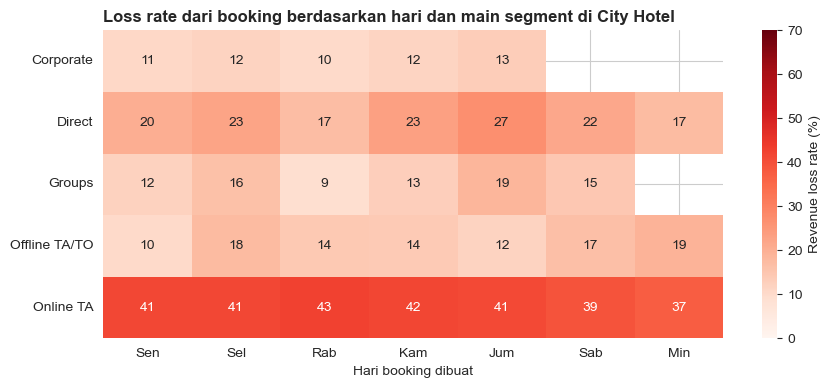

Resort Hotel - revenue loss rate (%) per segmen dan hari booking dibuat:
                 Sen   Sel   Rab   Kam   Jum   Sab   Min
market_segment                                          
Corporate       14.6  38.5  42.5   7.7  10.6   NaN   NaN
Direct          18.8  16.7  16.5  13.7  17.3  22.5  21.7
Groups          29.6  13.2  11.0  10.6  16.5  10.6   NaN
Offline TA/TO   12.7  13.2  16.3  13.3  13.8  10.9   NaN
Online TA       42.1  46.0  40.0  44.7  45.5  42.1  44.6 



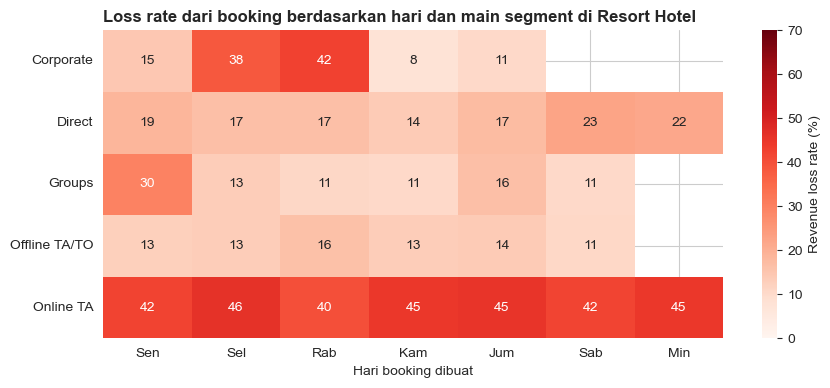

In [144]:
for hotel in ['City Hotel', 'Resort Hotel']:
    d = df[(df['market_segment'].isin(seg_utama)) & (df['hotel'] == hotel)]
    pv = loss_rate_pivot(d, 'market_segment', 'hari_booking')
    jumlah = d.pivot_table(index='market_segment', columns='hari_booking', values='is_canceled', aggfunc='count')
    pv[jumlah < 100] = np.nan      # sel yang isinya kurang dari 100 booking dikosongkan
    pv = pv[urutan_hari]
    pv.columns = ['Sen', 'Sel', 'Rab', 'Kam', 'Jum', 'Sab', 'Min']
    print(hotel, '- revenue loss rate (%) per segmen dan hari booking dibuat:')
    print(pv.round(1), '\n')

    plt.figure(figsize=(10, 4))
    sns.heatmap(pv, annot=True, fmt='.0f', cmap='Reds', vmin=0, vmax=70, cbar_kws={'label': 'Revenue loss rate (%)'})
    plt.title(judul[hotel], loc='left')
    plt.xlabel('Hari booking dibuat'); plt.ylabel('')
    plt.show()

- Booking yang dibuat hari Minggu kehilangan **36,9%** nilainya (cancel rate 31,4%), dibanding 31-34% di hari lain. Tetapi **85,1%** booking hari Minggu lewat Online TA, sedangkan di hari kerja hanya 52-57%.
- Di dalam segmen yang sama polanya hilang. Online TA kehilangan 37,4-42,6% di City dan 40,0-46,0% di Resort, di hari apa pun booking dibuat. Efek hari Minggu datang dari komposisi segmen.
- Pola di dalam segmen hanya muncul di Resort dan di segmen kecil: booking Corporate yang dibuat Selasa-Rabu kehilangan 38,5-42,5% (hari lain 7,7-14,6%), dan Groups yang dibuat Senin 29,6%. Di City, Corporate stabil di 10,2-13,3%. Corporate dan Groups hanya 4,8% dan 5,6% booking, jadi hari booking dibuat tidak dipakai sebagai kriteria kebijakan.

### **D. Validitas data: kolom yang tidak boleh dipakai sebagai penyebab** (pertanyaan C)
Beberapa faktor di 4.C terlihat sangat kuat, misalnya booking yang minta parkir 0% batal. Sebelum dipakai sebagai dasar kebijakan, cek dulu apakah nilai kolomnya pada booking yang batal sebanding dengan nilainya pada booking yang datang. Kalau tidak sebanding, hubungan kolom itu dengan pembatalan tidak bisa dipakai.

*kolom-kolom yang berada di sini tidak boleh dipakai sebagai dasar aturan kebijakan, ex: deposit berdasarkan negara asal*

#### **1. Negara asal**

In [145]:
# asal = 'Portugal (PRT)' atau 'Luar Portugal' (np.where)
df['asal'] = np.where(df['country'] == 'PRT', 'Portugal (PRT)', 'Luar Portugal')
d = df[df['market_segment'].isin(seg_utama)]
pv = loss_rate_pivot(d, 'market_segment', 'asal').round(1)
print(pv)

asal            Luar Portugal  Portugal (PRT)
market_segment                               
Corporate                 1.7            23.5
Direct                   15.0            24.9
Groups                    0.7            33.4
Offline TA/TO             0.3            45.8
Online TA                38.3            55.1


- Offline TA/TO: booking non-Portugal kehilangan **0,3%** nilainya, Portugal 45,8%. Groups: 0,7% vs 33,4%. Corporate: 1,7% vs 23,5%.

In [146]:
print(f"besar nilai Portugal pada revenue hilang: {df[df['country'] == 'PRT']['revenue_hilang'].sum() / df['revenue_hilang'].sum():.1%}, "
      f"pada revenue masuk: {df[(df['is_canceled'] == 0) & (df['country'] == 'PRT')]['revenue'].sum() / df[df['is_canceled'] == 0]['revenue'].sum():.1%}")
print(f"besar nilai Portugal: booking batal {(df[df['is_canceled'] == 1]['country'] == 'PRT').mean():.1%}, "
      f"booking check-out {(df[df['is_canceled'] == 0]['country'] == 'PRT').mean():.1%}")

besar nilai Portugal pada revenue hilang: 35.6%, pada revenue masuk: 21.1%
besar nilai Portugal: booking batal 40.7%, booking check-out 27.8%


- Dari seluruh revenue hilang, **35,6%** tercatat dari Portugal, dibanding 21,1% pada revenue yang masuk (dari jumlah booking: 40,7% vs 27,8%).

Setelah semua data sudah ada akan dilakukan visualisasi

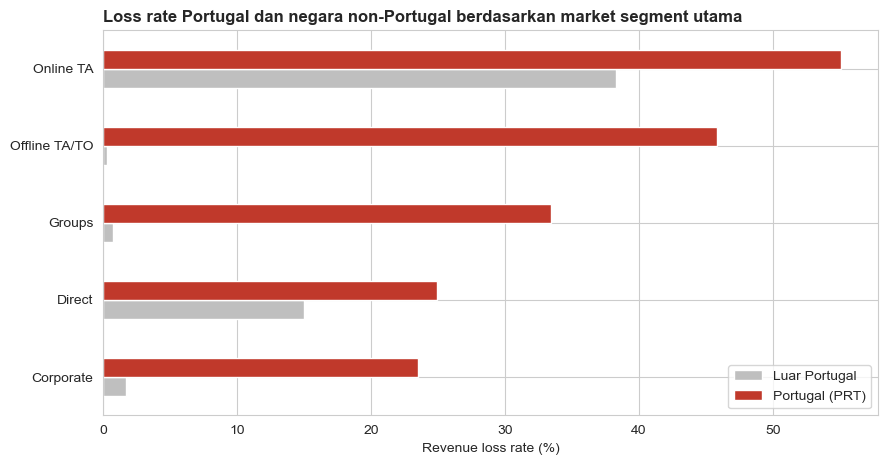

In [147]:
pv.plot.barh(color=[ABU, SOROT], figsize=(10, 5))
plt.legend(loc='lower right')
plt.title('Loss rate Portugal dan negara non-Portugal berdasarkan market segment utama', loc='left')
plt.xlabel('Revenue loss rate (%)'); plt.ylabel('')
plt.show()

Data tidak mencatat kapan kolom negara diisi, jadi selisih sebesar ini tidak bisa diverifikasi lebih jauh. Karena itu negara tidak dipakai sebagai penyebab pembatalan

#### **2. Parkir & perubahan tipe kamar**

In [148]:
print(cancel_rate(df, 'parking_grp'))

              revenue_loss_rate  cancel_rate  jumlah_booking  revenue_hilang  \
parking_grp                                                                    
Minta parkir                0.0          0.0            7306            0.00   
Tidak                      35.6         30.0           79922     11241285.55   

              potensi_revenue  
parking_grp                    
Minta parkir       2862860.17  
Tidak             31583394.76  


- Booking yang minta parkir: **0% batal**, tidak ada satu pun dari 7.306 booking, jadi revenue loss rate-nya juga 0%.

In [149]:
print(cancel_rate(df, 'room_changed'))

              revenue_loss_rate  cancel_rate  jumlah_booking  revenue_hilang  \
room_changed                                                                   
Tidak                      35.4         31.5           74239     11092035.01   
Ya                          4.8          4.7           12989       149250.54   

              potensi_revenue  
room_changed                   
Tidak             31315780.02  
Ya                 3130474.91  


- Booking yang tipe kamarnya berubah kehilangan **4,8%** nilainya (cancel rate 4,7%), dibanding 35,4% (cancel rate 31,5%).

> **Babak 3 dari 6: Waktu** (4.E)
>
> Babak 2 menjawab booking seperti apa yang batal. Babak ini menjawab kapan: musim, pendorong naik-turunnya volume dan pembatalan, variasi mingguan dan libur, serta kamar yang hilang menjelang kedatangan

### **E. Kapan hotel ramai?** (pertanyaan D)
4.C dan 4.D menjawab booking seperti apa yang batal. Bagian ini menjawab *kapan*: kapan hotel ramai dan mahal, kapan pembatalan tinggi, siapa yang mendorong naik-turunnya, bagaimana efek libur, dan berapa kamar yang hilang menjelang kedatangan.

Pola bulanan dibaca dari tahun 2016, satu-satunya tahun dengan 12 bulan lengkap, dan Januari-Agustus 2017 dipakai sebagai pembanding arah. Rata-rata per bulan kalender tidak dipakai untuk pola musim, karena Juli-Agustus punya 3 tahun data sedangkan bulan lain 2 tahun, dan data City 2015 didominasi duplikat (3.B). Judul grafik untuk bagian ini disimpan di sel berikut supaya kode grafiknya tetap ringkas.

#### **1. Musim: volume, harga, pembatalan, dan revenue hilang**

Pembuatan labelling bulan terlebih dahulu

In [150]:
label_bulan = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']

Berapa tahun data yang dimiliki tiap bulan (Juli & Agustus = 3 tahun, bulan lain = 2 tahun); dipakai lagi di bagian lain

In [151]:
jumlah_tahun = df.groupby('arrival_month')['arrival_date_year'].nunique()
print('Jumlah tahun per bulan:', jumlah_tahun.to_dict(), '\n')

Jumlah tahun per bulan: {1: 2, 2: 2, 3: 2, 4: 2, 5: 2, 6: 2, 7: 3, 8: 3, 9: 2, 10: 2, 11: 2, 12: 2} 



Pola bulanan dibaca dari 2016, satu-satunya tahun dengan 12 bulan lengkap

In [152]:
data_2016 = df[df['arrival_date_year'] == 2016]

Ukuran utama: potensi revenue (nilai semua booking) per bulan kedatangan; jumlah booking sebagai pendamping

In [153]:
potensi_2016 = data_2016.pivot_table(index='arrival_month', columns='hotel', values='revenue', aggfunc='sum') / 1000
volume_2016 = data_2016.pivot_table(index='arrival_month', columns='hotel', values='is_canceled', aggfunc='count')
print('Potensi revenue per bulan, 2016 (€ ribu):')
print(potensi_2016.round(0))


Potensi revenue per bulan, 2016 (€ ribu):
hotel          City Hotel  Resort Hotel
arrival_month                          
1                   234.0         107.0
2                   418.0         183.0
3                   685.0         283.0
4                   774.0         351.0
5                   797.0         452.0
6                   747.0         662.0
7                   966.0        1128.0
8                  1165.0        1537.0
9                   952.0         666.0
10                  911.0         428.0
11                  666.0         222.0
12                  665.0         283.0


Jumlah booking per bulan di tahun 2016

In [154]:
print('Jumlah booking per bulan, 2016:')
print(volume_2016,)

Jumlah booking per bulan, 2016:
hotel          City Hotel  Resort Hotel
arrival_month                          
1                    1030           819
2                    1655          1144
3                    2362          1463
4                    2410          1357
5                    2340          1437
6                    2283          1232
7                    2478          1364
8                    2808          1607
9                    2565          1283
10                   2642          1585
11                   2127          1184
12                   1983          1154


Pembanding pada tahun 2017 (Januari-Agustus)

In [155]:
data_2017 = df[df['arrival_date_year'] == 2017]
print('Potensi revenue per bulan, Januari-Agustus 2017 (€ ribu):')
print((data_2017.pivot_table(index='arrival_month', columns='hotel', values='revenue', aggfunc='sum') / 1000).round(0), '\n')

Potensi revenue per bulan, Januari-Agustus 2017 (€ ribu):
hotel          City Hotel  Resort Hotel
arrival_month                          
1                   556.0         183.0
2                   617.0         255.0
3                   761.0         314.0
4                  1120.0         542.0
5                  1262.0         612.0
6                  1139.0         947.0
7                  1236.0        1605.0
8                  1324.0        1808.0 



Jumlah booking per bulan tahun 2017

In [156]:
print('Jumlah booking per bulan, Januari-Agustus 2017:')
print(data_2017.pivot_table(index='arrival_month', columns='hotel', values='is_canceled', aggfunc='count'))

Jumlah booking per bulan, Januari-Agustus 2017:
hotel          City Hotel  Resort Hotel
arrival_month                          
1                    1694          1142
2                    1936          1348
3                    2470          1192
4                    2662          1471
5                    3062          1505
6                    2714          1527
7                    2859          1670
8                    2667          1713


Pembuatan potensi revenue per bulan

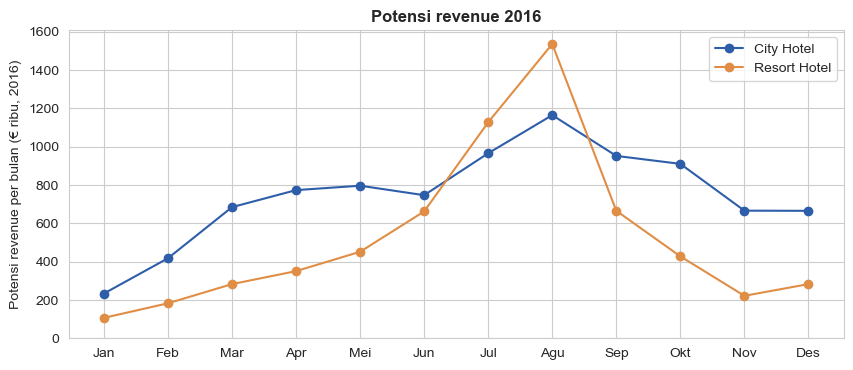

In [157]:
judul_volume = 'Potensi revenue 2016'

for hotel in ['City Hotel', 'Resort Hotel']:
    plt.plot(potensi_2016.index, potensi_2016[hotel], marker='o', color=WARNA_HOTEL[hotel], label=hotel)
plt.title(judul_volume, loc='center')
plt.xticks(range(1, 13), label_bulan)
plt.ylabel('Potensi revenue per bulan (€ ribu, 2016)'); plt.ylim(0)
plt.legend()
plt.show()

Selanjutnya melihat rata-rata ADR per bulan pada tahun 2016

In [158]:
adr_bulan = data_2016.pivot_table(index='arrival_month', columns='hotel', values='adr', aggfunc='mean')
print('Rata-rata ADR per bulan, 2016 (€):')
print(adr_bulan.round(1))

Rata-rata ADR per bulan, 2016 (€):
hotel          City Hotel  Resort Hotel
arrival_month                          
1                    75.8          46.3
2                    82.8          51.7
3                    91.9          56.1
4                   103.9          68.0
5                   117.0          72.7
6                   112.3         102.7
7                   117.8         156.8
8                   124.5         191.9
9                   126.3         110.8
10                  114.8          68.6
11                   95.8          51.1
12                   98.4          70.2


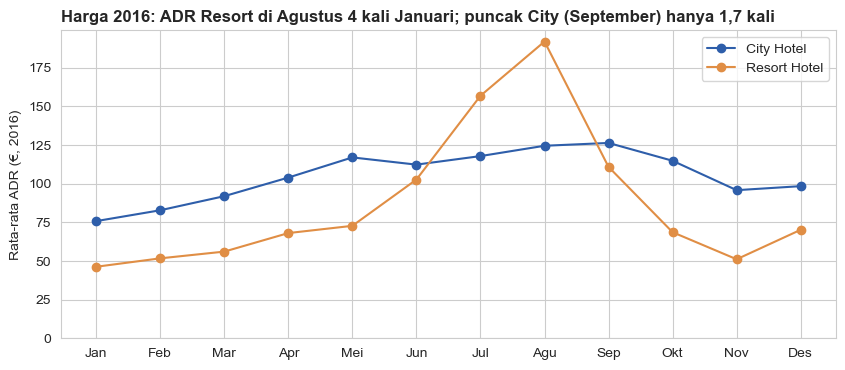

In [159]:
judul_adr = 'Harga 2016: ADR Resort di Agustus 4 kali Januari; puncak City (September) hanya 1,7 kali'

for hotel in ['City Hotel', 'Resort Hotel']:
    plt.plot(adr_bulan.index, adr_bulan[hotel], marker='o', color=WARNA_HOTEL[hotel], label=hotel)
plt.title(judul_adr, loc='left')
plt.xticks(range(1, 13), label_bulan)
plt.ylabel('Rata-rata ADR (€, 2016)'); plt.ylim(0)
plt.legend()
plt.show()

Berdasarkan data di atas dapat disimpulkan bahwa:
- **City 2016:** potensi revenue tertinggi di Agustus (€1,17 juta) dan terendah di Januari (€0,23 juta). Jumlah booking berpola sama (2.808 di Agustus, 1.030 di Januari). ADR naik dari €75,8 di Januari ke puncaknya €126,3 di September; Agustus €124,5.
- **Resort 2016:** potensi revenue Agustus **€1,54 juta**, sekitar 14 kali Januari (€0,11 juta), karena volume dan harga sama-sama memuncak (1.607 booking, ADR naik dari €46,3 di Januari menjadi **€191,9**).
- Januari-Agustus 2017 searah: Agustus tetap tertinggi di kedua hotel (City €1,32 juta, Resort €1,81 juta). City 2017 paling banyak booking di Mei (3.062), tetapi potensi revenue Mei (€1,26 juta) masih di bawah Agustus.

Potensi revenue yang didapatkan sudah ada, sekarang akan berlanjut ke potensi revenue loss-nya

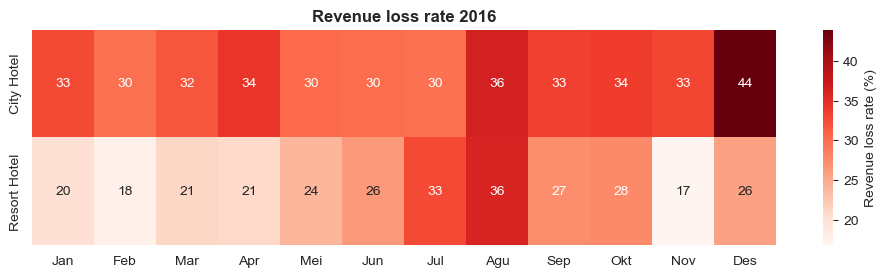

In [160]:
pv = loss_rate_pivot(df[df['arrival_date_year'] == 2016], 'hotel', 'arrival_month')
pv.columns = label_bulan        # ganti angka bulan 1-12 dengan nama bulan

plt.figure(figsize=(12, 2.8))
sns.heatmap(pv, annot=True, fmt='.0f', cmap='Reds', cbar_kws={'label': 'Revenue loss rate (%)'})
plt.title('Revenue loss rate 2016')
plt.xlabel(''); plt.ylabel('')
plt.show()

Setelah itu akan dicari revenue yang hilang pada tahun 2016

In [161]:
hilang_bulan = data_2016[data_2016['is_canceled'] == 1].pivot_table(index='arrival_month', columns='hotel',
                                                                     values='revenue_hilang', aggfunc='sum')
print('Revenue hilang per bulan, 2016 (€):')
print(hilang_bulan.round(0))

Revenue hilang per bulan, 2016 (€):
hotel          City Hotel  Resort Hotel
arrival_month                          
1                 76297.0       21353.0
2                124642.0       32005.0
3                217366.0       59693.0
4                265522.0       72938.0
5                241660.0      108747.0
6                224506.0      174429.0
7                287229.0      369010.0
8                423361.0      553665.0
9                318315.0      182379.0
10               307026.0      118262.0
11               219794.0       37184.0
12               292426.0       72825.0


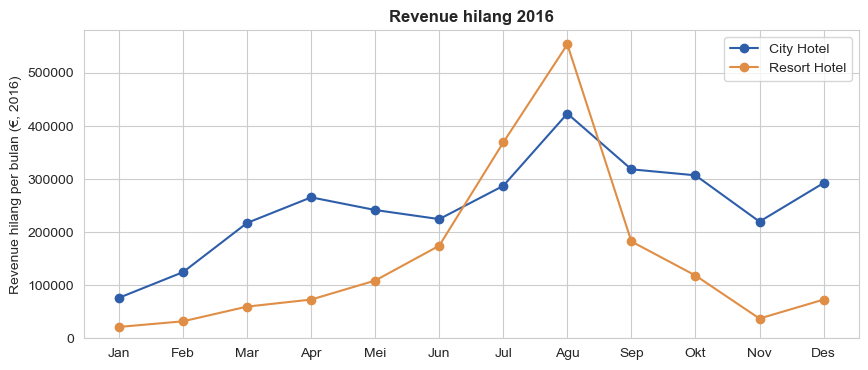

In [162]:
judul_hilang = 'Revenue hilang 2016'

for hotel in ['City Hotel', 'Resort Hotel']:
    plt.plot(hilang_bulan.index, hilang_bulan[hotel], marker='o', color=WARNA_HOTEL[hotel], label=hotel)
plt.title(judul_hilang, loc='center')
plt.xticks(range(1, 13), label_bulan)
plt.ylabel('Revenue hilang per bulan (€, 2016)'); plt.ylim(0)
plt.legend()
plt.show()

Setelah itu melihat data nilai rata-rata booking Resort yang batal per bulan di tahun 2016

In [163]:
batal_resort = data_2016[(data_2016['is_canceled'] == 1) & (data_2016['hotel'] == 'Resort Hotel')]
print('Nilai rata-rata satu booking Resort yang batal, 2016 (€):')
print(batal_resort.groupby('arrival_month')['revenue'].mean().round(0))

Nilai rata-rata satu booking Resort yang batal, 2016 (€):
arrival_month
1      246.0
2      219.0
3      262.0
4      318.0
5      367.0
6      591.0
7      896.0
8     1042.0
9      572.0
10     327.0
11     188.0
12     298.0
Name: revenue, dtype: float64


Berdasarkan data di atas dapat disimpulkan bahwa:
- Revenue loss rate 2016: City tertinggi di **Desember (43,9%)**, Resort di **Agustus (36,0%)** dan Juli (32,7%), dan terendah di November (16,8%). Cancel rate berpola sama (City Desember 38%, Resort Agustus 33%).
- Revenue hilang Resort 2016 menumpuk di musim panas: **€554 ribu di Agustus** dan €369 ribu di Juli, sedangkan Januari hanya €21 ribu. Satu booking Resort yang batal di Agustus 2016 rata-rata bernilai **€1.042**, sekitar 4 kali booking yang batal di Januari (€246).
- Revenue hilang City 2016 lebih tersebar: €217-423 ribu per bulan dari Maret sampai Desember, tertinggi di Agustus (€423 ribu), dan hanya €76 ribu di Januari.

*Pola musim tiap hotel berbeda. Bagian berikutnya memecah siapa yang mendorong naik-turunnya.*

#### **2. Variabel yang mendorong naik-turunnya volume dan juga pembatalan**
Grafik di atas menunjukkan *kapan*. Untuk tahu *siapa* yang mendorong, perubahannya dipecah per kelompok booking. Datanya tahun 2016, satu-satunya tahun yang lengkap Januari-Desember.

Pertama, volume: selisih potensi revenue tiap bulan terhadap rata-rata bulanannya, dipisah Online TA vs segmen lain.

In [164]:
d16 = df[df['arrival_date_year'] == 2016].copy()
d16['kelompok_segmen'] = np.where(d16['market_segment'] == 'Online TA', 'Online TA', 'Segmen lain')

Lalu pembuatan potensi revenue per bulan serta selisih tiap bulan terhadap rata-rata bulanan, dipisah sebagai Online TA dengan segment lainnya.

City Hotel - potensi revenue 2016 per segmen (€ ribu):
market_segment  Online TA  Offline TA/TO  Direct  Groups  Corporate   total
Jan                 138.0           43.0    39.0     4.0       10.0   234.0
Feb                 278.0           71.0    47.0     3.0       18.0   418.0
Mar                 494.0           93.0    59.0    19.0       19.0   685.0
Apr                 612.0           73.0    54.0    15.0       10.0   774.0
Mei                 551.0           92.0    76.0    25.0       34.0   797.0
Jun                 520.0          129.0    72.0    12.0       12.0   747.0
Jul                 742.0          105.0    98.0     6.0       14.0   966.0
Agu                 925.0           92.0   133.0     4.0       12.0  1165.0
Sep                 676.0          138.0    82.0    27.0       24.0   952.0
Okt                 671.0          123.0    73.0    14.0       20.0   911.0
Nov                 490.0           57.0    64.0    27.0       25.0   666.0
Des                 521.0        

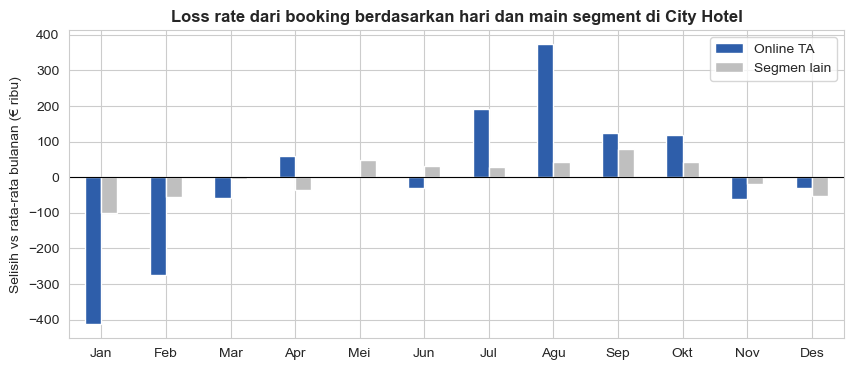

In [165]:
for hotel in ['City Hotel']:
    data_hotel = d16[d16['hotel'] == hotel]
    per_segmen = data_hotel.pivot_table(index='arrival_month', columns='market_segment', values='revenue', aggfunc='sum', fill_value=0)
    per_segmen = per_segmen[['Online TA', 'Offline TA/TO', 'Direct', 'Groups', 'Corporate']]
    per_segmen['total'] = data_hotel.groupby('arrival_month')['revenue'].sum()
    per_segmen.index = label_bulan
    print(hotel, '- potensi revenue 2016 per segmen (€ ribu):')
    print((per_segmen / 1000).round(0), '\n')

    # selisih tiap bulan terhadap rata-rata bulanan, dipisah Online TA vs segmen lain
    volume = data_hotel.pivot_table(index='arrival_month', columns='kelompok_segmen', values='revenue', aggfunc='sum') / 1000
    selisih = volume - volume.mean()
    selisih.index = label_bulan
    selisih.plot.bar(color=[WARNA_HOTEL[hotel], ABU], figsize=(10, 4))
    plt.axhline(0, color='black', linewidth=0.8)
    plt.title(judul[hotel])
    plt.xticks(rotation=0)
    plt.ylabel('Selisih vs rata-rata bulanan (€ ribu)'); plt.xlabel('')
    plt.legend(title='')
    plt.show()

- **City:** potensi revenue Agustus €1,17 juta, €417 ribu di atas rata-rata bulanan (€748 ribu). Online TA menambah **€373 ribu (90%)**. Januari €0,23 juta (€515 ribu di bawah rata-rata), dan **€413 ribu (80%)** hilang dari Online TA.

Resort Hotel - potensi revenue 2016 per segmen (€ ribu):
market_segment  Online TA  Offline TA/TO  Direct  Groups  Corporate   total
Jan                  51.0           27.0    22.0     3.0        4.0   107.0
Feb                  80.0           54.0    36.0     6.0        6.0   183.0
Mar                 141.0           60.0    41.0    35.0        6.0   283.0
Apr                 149.0           83.0    62.0    45.0       12.0   351.0
Mei                 221.0          126.0    55.0    38.0       11.0   452.0
Jun                 329.0          227.0    97.0     4.0        5.0   662.0
Jul                 610.0          276.0   226.0    12.0        4.0  1128.0
Agu                 958.0          262.0   315.0     1.0        1.0  1537.0
Sep                 319.0          174.0   114.0    53.0        5.0   666.0
Okt                 215.0           59.0    54.0    95.0        6.0   428.0
Nov                 130.0           51.0    31.0     5.0        5.0   222.0
Des                 160.0      

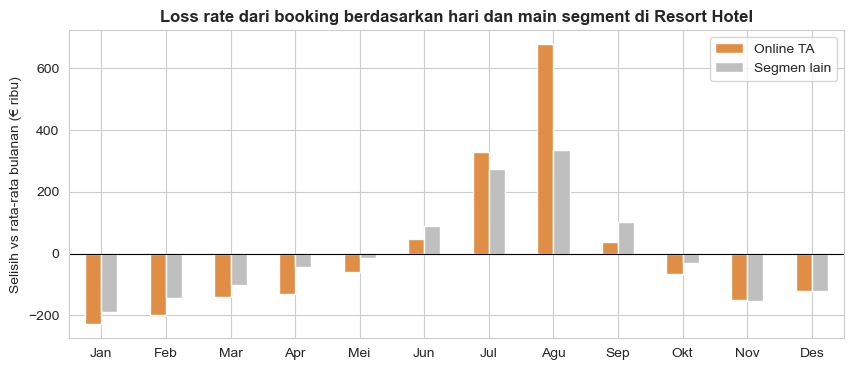

In [166]:
for hotel in ['Resort Hotel']:
    data_hotel = d16[d16['hotel'] == hotel]
    per_segmen = data_hotel.pivot_table(index='arrival_month', columns='market_segment', values='revenue', aggfunc='sum', fill_value=0)
    per_segmen = per_segmen[['Online TA', 'Offline TA/TO', 'Direct', 'Groups', 'Corporate']]
    per_segmen['total'] = data_hotel.groupby('arrival_month')['revenue'].sum()
    per_segmen.index = label_bulan
    print(hotel, '- potensi revenue 2016 per segmen (€ ribu):')
    print((per_segmen / 1000).round(0), '\n')

    # selisih tiap bulan terhadap rata-rata bulanan, dipisah Online TA vs segmen lain
    volume = data_hotel.pivot_table(index='arrival_month', columns='kelompok_segmen', values='revenue', aggfunc='sum') / 1000
    selisih = volume - volume.mean()
    selisih.index = label_bulan
    selisih.plot.bar(color=[WARNA_HOTEL[hotel], ABU], figsize=(10, 4))
    plt.axhline(0, color='black', linewidth=0.8)
    plt.title(judul[hotel])
    plt.xticks(rotation=0)
    plt.ylabel('Selisih vs rata-rata bulanan (€ ribu)'); plt.xlabel('')
    plt.legend(title='')
    plt.show()

- **Resort:** Agustus €1,54 juta (+€1,01 juta), Online TA **+€678 ribu (67%)**, dan sisanya terutama Direct dan Offline TA/TO. Januari €0,11 juta (−€418 ribu), Online TA −€229 ribu (55%).

Lalu kesimpulan dari kedua perbandingan di atas adalah:
- Segmen lain bergerak berlawanan musim: Groups di Resort memuncak di Oktober (€95 ribu) dan Maret-Mei (€35-45 ribu), tetapi hanya €1 ribu di Agustus. Corporate di Resort juga hampir nol di Agustus (€1 ribu).
- Jadi naik-turunnya revenue musiman terutama digerakkan Online TA. Di Resort, Direct dan Offline TA/TO ikut menyumbang sepertiga lonjakan Agustus.

Kedua, revenue loss rate. Selisih revenue loss rate tiap bulan terhadap rata-rata setahun dipecah menjadi dua bagian:
- **Efek komposisi:** bulan itu berisi porsi nilai yang lebih besar (atau lebih kecil) dari kelompok yang memang banyak kehilangan nilai.
- **Efek perilaku:** kelompok yang sama kehilangan lebih banyak (atau lebih sedikit) nilai di bulan itu.

Kelompok dibentuk dari market segment × rentang lead time, dua ciri terkuat di 4.C yang sudah diketahui saat booking dibuat. Porsi tiap kelompok dihitung dari potensi revenue, bukan jumlah booking. Jumlah kedua efek sama persis dengan selisih aslinya.

Pembuatan list untuk kelompok tamu yang dipakai fungsi pecah_cancel untuk memisahkan efek komposisi dan efek perilaku.

In [167]:
utama = ['Online TA', 'Offline TA/TO', 'Direct', 'Groups', 'Corporate']
# kelompok = segmen x lead time, misalnya 'Online TA | 91-180'
df['segmen_utama'] = np.where(df['market_segment'].isin(utama), df['market_segment'], 'Lainnya')
df['kelompok'] = df['segmen_utama'] + ' | ' + df['lead_bin'].astype(str)

Pembuatan fungsi pecah_cancel untuk menjawab: kalau kerugian karena pembatalan naik atau turun, penyebabnya apa? Jawabannya penting karena setiap penyebab butuh tindakan yang berbeda.

Dua kemungkinan penyebab

- Komposisi (siapa yang memesan berubah). Misalnya bulan itu lebih banyak booking Online TA yang dibuat jauh hari, kelompok yang memang paling sering batal. Kelompoknya sendiri tidak berubah, hanya porsinya yang bertambah.
- Perilaku (kebiasaan kelompok yang sama berubah). Misalnya tamu Online TA jauh hari di bulan itu lebih sering batal dibanding biasanya.

In [168]:
def pecah_cancel(data, kolom_waktu, dasar):
    # revenue loss rate tiap kelompok di data dasar
    rate_dasar_kelompok = dasar.groupby('kelompok')['revenue_hilang'].sum() / dasar.groupby('kelompok')['revenue'].sum()

    # revenue hilang yang diharapkan kalau tiap kelompok kehilangan nilai sama seperti di data dasar
    data = data.copy()
    data['hilang_harapan'] = data['revenue'] * data['kelompok'].map(rate_dasar_kelompok)
    # kelompok yang tidak ada di data dasar memakai revenue hilangnya sendiri
    data['hilang_harapan'] = data['hilang_harapan'].fillna(data['revenue_hilang'])

    rate_dasar = dasar['revenue_hilang'].sum() / dasar['revenue'].sum() * 100
    potensi = data.groupby(kolom_waktu)['revenue'].sum()

    hasil = pd.DataFrame()
    hasil['booking'] = data.groupby(kolom_waktu)['is_canceled'].count()
    hasil['revenue_loss_rate'] = data.groupby(kolom_waktu)['revenue_hilang'].sum() / potensi * 100
    hasil['cancel_rate'] = data.groupby(kolom_waktu)['is_canceled'].mean() * 100
    hasil['rate_harapan'] = data.groupby(kolom_waktu)['hilang_harapan'].sum() / potensi * 100
    hasil['selisih'] = hasil['revenue_loss_rate'] - rate_dasar
    hasil['efek_komposisi'] = hasil['rate_harapan'] - rate_dasar
    hasil['efek_perilaku'] = hasil['revenue_loss_rate'] - hasil['rate_harapan']
    return hasil[['booking', 'revenue_loss_rate', 'cancel_rate', 'selisih', 'efek_komposisi', 'efek_perilaku']]

In [169]:
d16 = df[df['arrival_date_year'] == 2016]
judul = {'City Hotel': 'Perilaku, komposisi dan selisih City Hotel 2016',
         'Resort Hotel': 'Perilaku, komposisi dan selisih Resort Hotel 2016'}

City Hotel | revenue loss rate 2016: 33.4% | cancel rate 2016: 29.2%
     booking  revenue_loss_rate  cancel_rate  selisih  efek_komposisi  \
Jan     1030               32.7         20.8     -0.7            -5.7   
Feb     1655               29.8         22.7     -3.6            -4.8   
Mar     2362               31.7         27.3     -1.6            -1.8   
Apr     2410               34.3         31.0      0.9             0.5   
Mei     2340               30.3         27.5     -3.1            -1.2   
Jun     2283               30.0         26.8     -3.3            -1.7   
Jul     2478               29.7         27.3     -3.7             1.7   
Agu     2808               36.3         32.4      2.9             2.8   
Sep     2565               33.4         29.4      0.0            -0.1   
Okt     2642               33.7         31.7      0.3             0.6   
Nov     2127               33.0         28.6     -0.4            -0.2   
Des     1983               43.9         38.3     10.6  

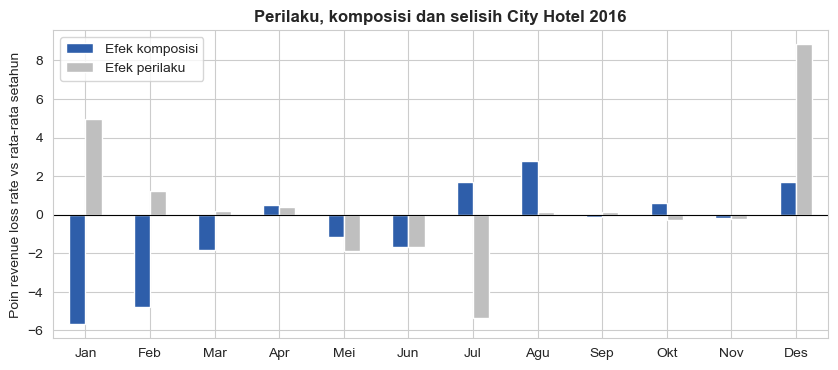

Resort Hotel | revenue loss rate 2016: 28.6% | cancel rate 2016: 21.9%
     booking  revenue_loss_rate  cancel_rate  selisih  efek_komposisi  \
Jan      819               20.0         10.6     -8.6           -10.5   
Feb     1144               17.5         13.2    -11.1           -10.0   
Mar     1463               21.1         16.3     -7.5            -5.0   
Apr     1357               20.8         19.5     -7.8            -5.7   
Mei     1437               24.1         20.7     -4.5            -1.7   
Jun     1232               26.3         24.3     -2.3             0.6   
Jul     1364               32.7         30.2      4.1             1.7   
Agu     1607               36.0         33.1      7.4             3.9   
Sep     1283               27.4         25.2     -1.2            -0.4   
Okt     1585               27.6         23.0     -1.0            -1.4   
Nov     1184               16.8         17.0    -11.8            -2.5   
Des     1154               25.7         21.3     -2.9

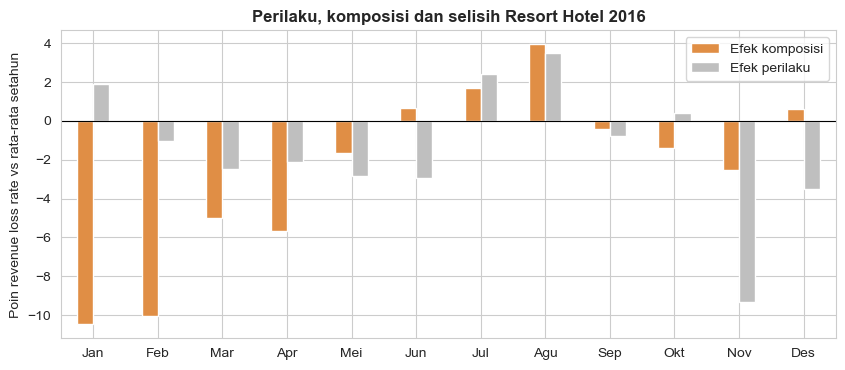

In [170]:
for hotel in ['City Hotel', 'Resort Hotel']:
    data_hotel = d16[d16['hotel'] == hotel]
    # data dasar = seluruh tahun 2016 di hotel yang sama
    hasil = pecah_cancel(data_hotel, 'arrival_month', data_hotel)
    hasil['%_online_ta'] = data_hotel.groupby('arrival_month')['market_segment'].apply(lambda x: (x == 'Online TA').mean() * 100)
    hasil['median_lead_time'] = data_hotel.groupby('arrival_month')['lead_time'].median()
    hasil['%_direct_corporate'] = data_hotel.groupby('arrival_month')['market_segment'].apply(lambda x: x.isin(['Direct', 'Corporate']).mean() * 100)
    hasil.index = label_bulan
    print(f"{hotel} | revenue loss rate 2016: {data_hotel['revenue_hilang'].sum() / data_hotel['revenue'].sum():.1%} | "
          f"cancel rate 2016: {data_hotel['is_canceled'].mean():.1%}")
    print(hasil.round(1), '\n')

    efek = pd.DataFrame()
    efek['Efek komposisi'] = hasil['efek_komposisi']
    efek['Efek perilaku'] = hasil['efek_perilaku']
    efek.plot.bar(color=[WARNA_HOTEL[hotel], ABU], figsize=(10, 4))
    plt.axhline(0, color='black', linewidth=0.8)
    plt.title(judul[hotel])
    plt.xticks(rotation=0)
    plt.ylabel('Poin revenue loss rate vs rata-rata setahun'); plt.xlabel('')
    plt.legend()
    plt.show()

- **Angka rendah di musim sepi Resort datang dari komposisi.** Januari −8,6 poin (komposisi −10,5) dan Februari −11,1 poin (komposisi −10,0). Booking di bulan ini dibuat dekat hari kedatangan (median lead time 3-7 hari) dan porsi Direct + Corporate besar (33-37%). Di City, komposisi Januari juga menurunkan angka (−5,7 poin), tetapi kelompok yang sama kehilangan lebih banyak nilai (+5,0), sehingga selisihnya hanya −0,7 poin.
- **Angka tinggi datang dari komposisi dan perilaku.** Resort Agustus +7,4 poin (komposisi +3,9, perilaku +3,5) dan Juli +4,1 poin (+1,7 dan +2,4): porsi Online TA naik ke 54-63% dan median lead time 90-119 hari. City Desember +10,6 poin hampir seluruhnya perilaku (+8,8): komposisinya mirip bulan lain, tetapi kelompok yang sama kehilangan jauh lebih banyak nilai.
- Pengecualian: Resort November −11,8 poin datang dari perilaku (−9,3). City Juli −3,7 poin walaupun komposisinya mendorong naik (+1,7), karena perilakunya turun (−5,4).

Efek perilaku di musim panas berarti kelompok yang sama kehilangan lebih banyak nilai. Segmen mana yang naik? Revenue loss rate per segmen per bulan (semua tahun):

Pembuatan heatmap revenue loss rate per market segment per bulan di 4.E.2. Tujuannya menjawab pertanyaan lanjutan dari pecah_cancel: kalau musim panas naik karena efek perilaku, segmen mana yang kebiasaan batalnya naik?

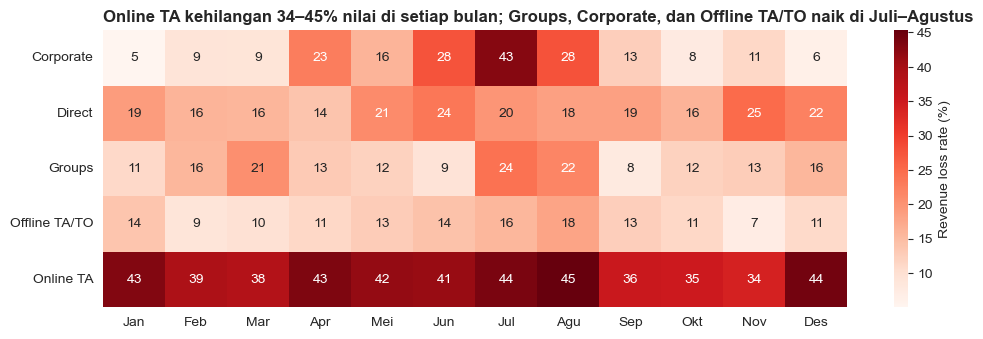

In [171]:
d = df[df['market_segment'].isin(seg_utama)]
pv = loss_rate_pivot(d, 'market_segment', 'arrival_month')
jumlah = d.pivot_table(index='market_segment', columns='arrival_month', values='is_canceled', aggfunc='count')
pv[jumlah < 100] = np.nan
pv.columns = label_bulan

plt.figure(figsize=(12, 3.6))
sns.heatmap(pv, annot=True, fmt='.0f', cmap='Reds', cbar_kws={'label': 'Revenue loss rate (%)'})
plt.title('Online TA kehilangan 34–45% nilai di setiap bulan; Groups, Corporate, dan Offline TA/TO naik di Juli–Agustus', loc='left')
plt.xlabel(''); plt.ylabel('')
plt.show()

- **Online TA** kehilangan 34-45% nilainya di setiap bulan, paling tinggi di Agustus (45%) dan paling rendah di September-November (34-36%).
- **Groups** naik ke 22-24% di Juli-Agustus (bulan lain 8-21%), **Corporate** ke 28-43% di Juni-Agustus, dan **Offline TA/TO** ke 14-18% di Juni-Agustus (bulan lain 7-14%). Ketiga segmen ini kecil di musim panas (4.E.2), jadi nilai yang hilang tetap kecil.
- **Direct** bergerak 14-25% tanpa pola musim yang jelas.
- Jadi kenaikan di musim panas terlihat di hampir semua segmen kecuali Direct, tetapi besarnya kerugian tetap ditentukan Online TA.

4.B.4 menunjukkan revenue loss rate Januari-Agustus naik 6-7 poin dari 2016 ke 2017. Dengan cara yang sama, kenaikan itu dipecah, kali ini dengan 2016 sebagai dasar.

Januari-Agustus 2016 dan 2017 (filter yang sama dengan jan_agu di 4.B.4), sekarang sudah punya kolom kelompok

In [172]:
jan_agu_kel = df[(df['arrival_month'] <= 8) & (df['arrival_date_year'].isin([2016, 2017]))]


Selanjutnya, membedah kenaikan revenue loss rate Januari–Agustus dari 2016 ke 2017, terpisah untuk setiap hotel. Pertanyaannya ada dua: berapa bagian kenaikan yang datang dari komposisi dan berapa dari perilaku, lalu di kelompok mana perilakunya berubah.

In [173]:
for hotel in ['City Hotel', 'Resort Hotel']:
    data_hotel = jan_agu_kel[jan_agu_kel['hotel'] == hotel]
    # data dasar = tahun 2016, jadi selisih 2017 dihitung terhadap 2016
    hasil = pecah_cancel(data_hotel, 'arrival_date_year', data_hotel[data_hotel['arrival_date_year'] == 2016])
    hasil['median_lead_time'] = data_hotel.groupby('arrival_date_year')['lead_time'].median()
    hasil['%_lead_time_>90'] = data_hotel.groupby('arrival_date_year')['lead_time'].apply(lambda x: (x > 90).mean() * 100)
    hasil['%_online_ta'] = data_hotel.groupby('arrival_date_year')['market_segment'].apply(lambda x: (x == 'Online TA').mean() * 100)
    print(hotel, '- Januari-Agustus (selisih 2017 dihitung terhadap 2016)')
    print(hasil.round(1), '\n')

    ota = data_hotel[data_hotel['market_segment'] == 'Online TA']
    print('Revenue loss rate Online TA per lead time:')
    print(loss_rate_pivot(ota, 'lead_bin', 'arrival_date_year').round(1), '\n')
    print('Cancel rate Online TA per lead time:')
    print((ota.pivot_table(index='lead_bin', columns='arrival_date_year', values='is_canceled', aggfunc='mean') * 100).round(1), '\n')

City Hotel - Januari-Agustus (selisih 2017 dihitung terhadap 2016)
                   booking  revenue_loss_rate  cancel_rate  selisih  \
arrival_date_year                                                     
2016                 17366               32.2         27.8      0.0   
2017                 20064               38.0         34.1      5.9   

                   efek_komposisi  efek_perilaku  median_lead_time  \
arrival_date_year                                                    
2016                          0.0            0.0              50.0   
2017                          1.9            3.9              68.0   

                   %_lead_time_>90  %_online_ta  
arrival_date_year                                
2016                          31.9         67.0  
2017                          41.4         71.3   

Revenue loss rate Online TA per lead time:
arrival_date_year  2016  2017
lead_bin                     
0-7                19.1  11.8
8-30               43.1  40.5
31

- **City:** naik 5,9 poin (dari 32,2% ke 38,0%) = komposisi +1,9 + perilaku +3,9. Komposisinya bergeser ke booking jauh hari: median lead time dari 50 ke 68 hari, porsi lead time > 90 hari dari 31,9% ke 41,4%, dan porsi Online TA dari 67,0% ke 71,3%. Perilakunya juga berubah: Online TA dengan lead time 181-365 hari kehilangan nilai dari 41,4% ke 55,4%, dan 91-180 hari dari 38,1% ke 46,1%.
- **Resort:** naik 7,4 poin (dari 29,6% ke 37,0%) = komposisi +3,0 + perilaku +4,4. Median lead time dari 40 ke 58 hari, porsi Online TA dari 47,4% ke 53,9%, dan Online TA kehilangan lebih banyak nilai di hampir semua rentang lead time (181-365 hari: dari 51,1% ke 62,9%).
- Jadi sepertiga sampai dua perlima kenaikan 2017 datang dari lebih banyak booking Online TA jauh hari, dan sisanya dari kelompok yang sama yang kehilangan lebih banyak nilai.

#### **3. Variasi mingguan dan efek libur**

Rata-rata bulanan bisa menyembunyikan variasi antarminggu. Revenue loss rate dihitung per minggu kedatangan (Senin-Minggu) untuk Januari 2016 sampai Agustus 2017. Tahun 2015 tidak dipakai karena data City 2015 didominasi duplikat (3.B), begitu juga minggu yang tidak lengkap di awal dan akhir periode.

In [174]:
# mingguan = kedatangan 4 Januari 2016 sampai 27 Agustus 2017 (minggu penuh), .copy()
mingguan = df[(df['arrival_date'] >= '2016-01-04') & (df['arrival_date'] <= '2017-08-27')].copy()

In [175]:
# tanggal Senin di tiap minggu: tanggal kedatangan dikurangi urutan harinya (0 = Senin, 6 = Minggu)
mingguan['minggu'] = mingguan['arrival_date'] - pd.to_timedelta(mingguan['arrival_date'].dt.dayofweek, unit='D')
cr_minggu = loss_rate_pivot(mingguan, 'minggu', 'hotel')         # revenue loss rate per minggu kedatangan
print(cr_minggu.describe().round(1), '\n')

hotel  City Hotel  Resort Hotel
count        86.0          86.0
mean         35.1          27.2
std           5.0           8.8
min          22.0           6.7
25%          31.5          21.5
50%          35.0          26.7
75%          38.6          33.2
max          45.2          46.6 



Selanjutnya menghitung selisih tertinggi dan terendah di dalam bulan yang sama.

In [176]:
cr_minggu = cr_minggu.reset_index()
cr_minggu['tahun'] = cr_minggu['minggu'].dt.year
cr_minggu['bulan'] = cr_minggu['minggu'].dt.month
tertinggi = cr_minggu.groupby(['tahun', 'bulan'])[['City Hotel', 'Resort Hotel']].max()
terendah = cr_minggu.groupby(['tahun', 'bulan'])[['City Hotel', 'Resort Hotel']].min()
selisih_minggu = tertinggi - terendah
print('Selisih revenue loss rate antarminggu di dalam satu bulan (poin):')
print(selisih_minggu.describe().loc[['50%', 'max']].round(1))

Selisih revenue loss rate antarminggu di dalam satu bulan (poin):
hotel  City Hotel  Resort Hotel
50%           6.6           9.5
max          17.8          26.8


- Revenue loss rate mingguan City bergerak **22,0-45,2%** (median 35,0%), Resort **6,7-46,6%** (median 26,7%).
- Di dalam bulan yang sama, minggu tertinggi dan terendah berbeda median **6,6 poin (City)** dan **9,5 poin (Resort)**, dan bisa sampai 18 poin (City) dan 27 poin (Resort).

Setelah itu dilakukan visualisasi data

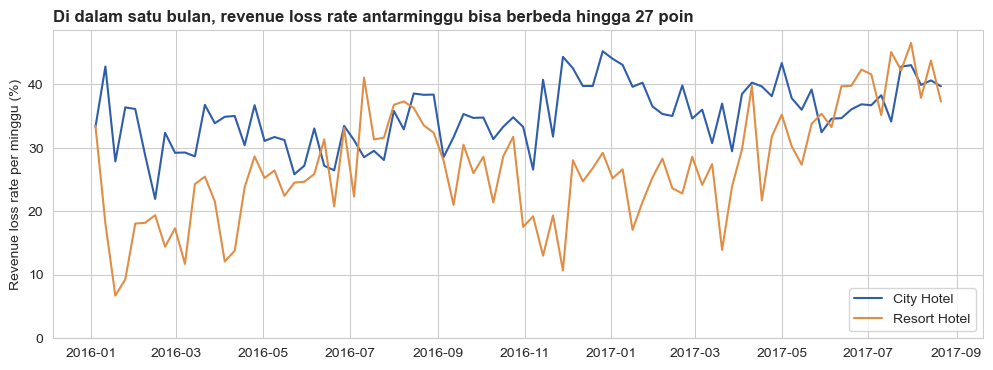

In [177]:
plt.figure(figsize=(12, 4))
for hotel in ['City Hotel', 'Resort Hotel']:
    plt.plot(cr_minggu['minggu'], cr_minggu[hotel], color=WARNA_HOTEL[hotel], label=hotel)
plt.title('Di dalam satu bulan, revenue loss rate antarminggu bisa berbeda hingga 27 poin', loc='left')
plt.ylabel('Revenue loss rate per minggu (%)'); plt.ylim(0)
plt.legend()
plt.show()

Efek libur diukur langsung dari tanggal kedatangan. Tanggal libur diambil dari kalender Portugal (bukan dari dataset); datanya hanya dipakai untuk mengukur efeknya. Hanya libur yang muncul di dua tahun data yang dihitung. Setiap periode libur dibandingkan dengan 3 minggu sebelum dan sesudahnya, pada hari yang sama dalam minggu, supaya efek akhir pekan tidak ikut terhitung.

Pembuatan list of tuples yang berisi hari libur dari kalender Portugal

In [178]:
# tanggal libur dari kalender Portugal; hanya libur yang ada di dua tahun data
libur = [('Carnaval', '2016-02-06', '2016-02-09'), ('Carnaval', '2017-02-25', '2017-02-28'),
         ('Paskah', '2016-03-24', '2016-03-27'), ('Paskah', '2017-04-13', '2017-04-16'),
         ('25 April', '2016-04-23', '2016-04-25'), ('25 April', '2017-04-22', '2017-04-25'),
         ('1 Mei', '2016-04-30', '2016-05-01'), ('1 Mei', '2017-04-29', '2017-05-01'),
         ('Corpus Christi', '2016-05-26', '2016-05-29'), ('Corpus Christi', '2017-06-15', '2017-06-18'),
         ('10 & 13 Juni', '2016-06-10', '2016-06-13'), ('10 & 13 Juni', '2017-06-10', '2017-06-13'),
         ('Natal', '2015-12-23', '2015-12-26'), ('Natal', '2016-12-23', '2016-12-26'),
         ('Tahun Baru', '2015-12-30', '2016-01-01'), ('Tahun Baru', '2016-12-30', '2017-01-01')]

Pembuatan fungsi efek libur yang berfungsi untuk mengukur apakah sebuah hari libur (Paskah, Carnaval, 1 Mei, dan lainnya) membuat kedatangan, harga, dan pembatalan berbeda dari hari biasa di sekitarnya.

In [179]:
def efek_libur(data, mulai, selesai):
    # bandingkan periode libur dengan 3 minggu sebelum dan sesudahnya, pada hari yang sama dalam minggu
    mulai = pd.Timestamp(mulai)
    selesai = pd.Timestamp(selesai)
    periode = data[(data['arrival_date'] >= mulai) & (data['arrival_date'] <= selesai)]
    sekitar = data[((data['arrival_date'] >= mulai - pd.Timedelta(days=21)) & (data['arrival_date'] < mulai)) |
                   ((data['arrival_date'] > selesai) & (data['arrival_date'] <= selesai + pd.Timedelta(days=21)))]
    sekitar = sekitar[sekitar['arrival_date'].dt.dayofweek.isin(periode['arrival_date'].dt.dayofweek.unique())]
    per_hari_libur = len(periode) / periode['arrival_date'].nunique()
    per_hari_sekitar = len(sekitar) / sekitar['arrival_date'].nunique()
    kedatangan = (per_hari_libur / per_hari_sekitar - 1) * 100
    adr = (periode['adr'].mean() / sekitar['adr'].mean() - 1) * 100
    rugi_libur = periode['revenue_hilang'].sum() / periode['revenue'].sum() * 100
    rugi_sekitar = sekitar['revenue_hilang'].sum() / sekitar['revenue'].sum() * 100
    return [kedatangan, adr, rugi_libur, rugi_sekitar, periode['is_canceled'].mean() * 100, sekitar['is_canceled'].mean() * 100]

Lalu dibuat list kosong untuk setiap libur dan setiap hotel, lalu mengumpulkan semua hasilnya menjadi satu tabel.

In [180]:
baris = []
for nama, mulai, selesai in libur:
    for hotel in ['City Hotel', 'Resort Hotel']:
        hasil = efek_libur(df[df['hotel'] == hotel], mulai, selesai)
        baris.append([nama, mulai[:4], hotel] + hasil)
efek = pd.DataFrame(baris, columns=['libur', 'tahun', 'hotel', 'Δ kedatangan per hari (%)', 'Δ ADR (%)',
                                    'loss rate libur', 'loss rate sekitar', 'cancel rate libur', 'cancel rate sekitar'])
print(efek.round(1).to_string(index=False))

         libur tahun        hotel  Δ kedatangan per hari (%)  Δ ADR (%)  loss rate libur  loss rate sekitar  cancel rate libur  cancel rate sekitar
      Carnaval  2016   City Hotel                       15.7        4.3             20.8               28.2               20.1                 21.5
      Carnaval  2016 Resort Hotel                       22.4       10.8             15.1               16.8               11.6                 12.0
      Carnaval  2017   City Hotel                       15.7        3.6             38.3               33.1               30.1                 28.6
      Carnaval  2017 Resort Hotel                       19.8       11.5             17.8               26.5               21.3                 21.4
        Paskah  2016   City Hotel                        1.1       21.4             41.3               34.9               37.0                 30.8
        Paskah  2016 Resort Hotel                       22.0       33.8             28.3               16.2     

Selanjutnya pemeriksaan apakah perubahan ADR dan kedatangan sama di kedua tahun

In [181]:
ringkas_libur = efek.groupby(['libur', 'hotel'])[['Δ kedatangan per hari (%)', 'Δ ADR (%)']].agg(['min', 'max'])
print(ringkas_libur.round(1))

                            Δ kedatangan per hari (%)       Δ ADR (%)       
                                                  min   max       min    max
libur          hotel                                                        
1 Mei          City Hotel                       -20.2   9.2      -0.5   10.2
               Resort Hotel                      31.7  45.5       8.4    9.8
10 & 13 Juni   City Hotel                       -14.3  -0.0      -3.1    4.5
               Resort Hotel                       3.3  17.4       0.7   11.3
25 April       City Hotel                       -24.8   0.1      -3.1    1.4
               Resort Hotel                     -26.9  -8.3      -7.1    7.9
Carnaval       City Hotel                        15.7  15.7       3.6    4.3
               Resort Hotel                      19.8  22.4      10.8   11.5
Corpus Christi City Hotel                       -17.8  -4.7      -0.7    5.2
               Resort Hotel                     -19.8  -7.0      -9.0    2.8

Setelah itu divisualisasikan untuk mempermudah analisis

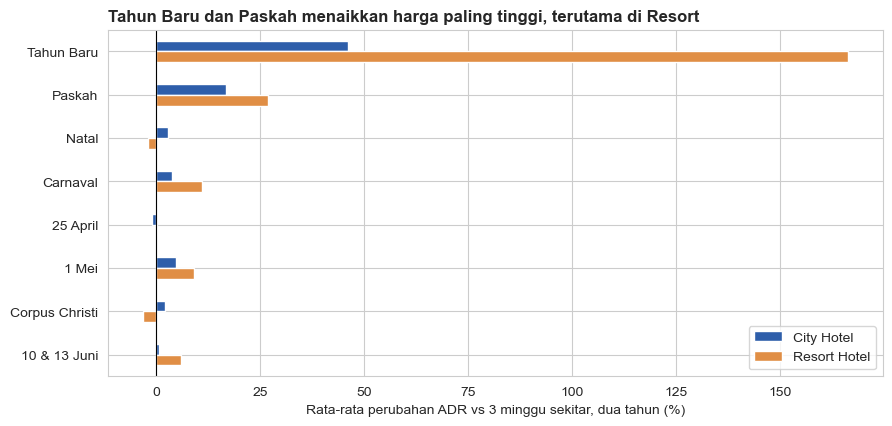

In [182]:
urutan_libur = ['Tahun Baru', 'Paskah', 'Natal', 'Carnaval', '25 April', '1 Mei', 'Corpus Christi', '10 & 13 Juni']
adr_libur = efek.pivot_table(index='libur', columns='hotel', values='Δ ADR (%)', aggfunc='mean').loc[urutan_libur]
adr_libur.plot.barh(color=[WARNA_HOTEL['City Hotel'], WARNA_HOTEL['Resort Hotel']], figsize=(10, 4.5))
plt.gca().invert_yaxis()          # Tahun Baru di paling atas, mengikuti urutan_libur
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Tahun Baru dan Paskah menaikkan harga paling tinggi, terutama di Resort', loc='left')
plt.xlabel('Rata-rata perubahan ADR vs 3 minggu sekitar, dua tahun (%)'); plt.ylabel('')
plt.legend(title='')
plt.show()

- **Tahun Baru** paling kuat dan konsisten di kedua tahun: kedatangan per hari naik 28-79% (City) dan 48-51% (Resort), dan ADR naik 37-56% (City) serta **162-171% (Resort)**.
- **Paskah** juga konsisten: ADR naik 12-21% (City) dan 20-34% (Resort), dan kedatangan Resort naik 22-41%.
- **Carnaval** menaikkan kedatangan (City +16%, Resort +20-22%) dengan kenaikan ADR yang lebih kecil (City 4%, Resort 11-12%). **Natal** menaikkan kedatangan Resort sekitar 20% tanpa kenaikan ADR. **1 Mei** menaikkan kedatangan Resort 32-46% dan ADR-nya 8-10%.
- **Corpus Christi** diikuti kedatangan yang lebih rendah di kedua hotel dan kedua tahun. **25 April** dan **10 & 13 Juni** tidak menunjukkan arah yang sama di kedua tahun atau kedua hotel.
- **Pembatalan dalam nilai:** Paskah (kedua hotel), serta Tahun Baru dan Natal di Resort, kehilangan nilai lebih besar dari 3 minggu sekitarnya di kedua tahun. Contoh Paskah di Resort: 28,3% vs 16,2% (2016) dan 45,4% vs 30,1% (2017). Di City, Tahun Baru justru kehilangan nilai lebih kecil (28,0% vs 33,6% dan 38,7% vs 45,3%), walaupun cancel rate-nya lebih tinggi. Carnaval di Resort lebih rendah di kedua tahun.
- Catatan metode: setiap libur hanya muncul dua kali, dan 3 minggu pembanding bisa memuat libur lain (misalnya 25 April 2017 berdekatan dengan Paskah dan 1 Mei).

Libur di negara asal tamu tidak tercatat di dataset, tetapi kapan tamu tiap negara datang bisa dilihat langsung. Indeks di bawah membandingkan kedatangan tiap bulan dengan rata-rata bulanan negara itu sendiri (1,0 = rata-rata), hanya dari booking yang check-out (4.D).

Pembuatan looping untuk mencari kapan tamu dari setiap negara paling banyak datang di masing-masing hotel. Hasilnya dipakai untuk menentukan waktu promosi per negara

In [183]:
negara_utama = ['PRT', 'GBR', 'FRA', 'ESP', 'DEU', 'IRL', 'NLD', 'USA']

Resort Hotel - indeks kedatangan per negara (booking check-out)
          Jan   Feb   Mar   Apr   Mei   Jun   Jul   Agu   Sep   Okt   Nov  \
country                                                                     
PRT      1.16  1.37  1.25  0.95  0.76  0.70  0.99  1.23  0.59  0.87  1.00   
GBR      0.46  0.89  0.91  1.17  1.67  1.41  0.78  0.67  1.24  1.69  0.59   
FRA      0.78  0.98  1.01  1.28  1.28  0.53  0.49  1.00  1.09  0.88  1.54   
ESP      0.85  1.16  1.22  1.01  0.54  0.54  1.28  1.65  0.74  0.93  0.83   
DEU      0.56  0.66  1.92  1.95  1.78  0.81  0.53  0.40  0.97  0.92  1.05   
IRL      0.48  0.43  0.62  1.10  2.07  1.67  0.97  0.89  1.72  1.21  0.46   
NLD      0.92  1.33  1.60  1.21  0.83  0.50  0.77  0.61  1.04  1.24  1.21   
USA      0.60  0.67  0.28  0.99  1.16  1.62  1.97  1.69  1.06  0.99  0.39   

          Des  
country        
PRT      1.13  
GBR      0.53  
FRA      1.15  
ESP      1.26  
DEU      0.45  
IRL      0.39  
NLD      0.74  
USA      0.60   



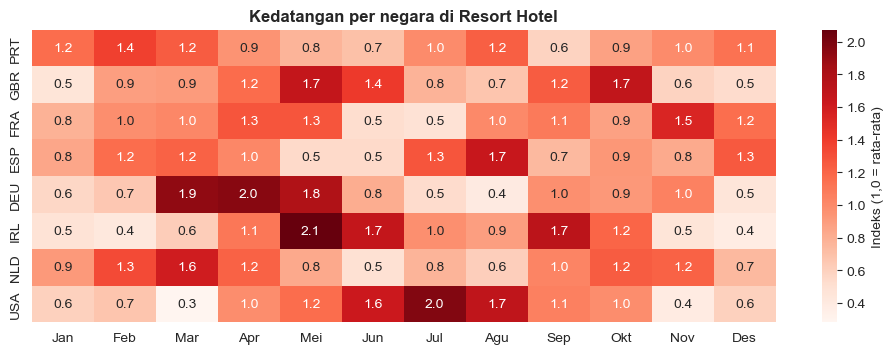

City Hotel - indeks kedatangan per negara (booking check-out)
          Jan   Feb   Mar   Apr   Mei   Jun   Jul   Agu   Sep   Okt   Nov  \
country                                                                     
PRT      0.88  1.10  1.17  0.85  1.05  1.17  0.86  0.86  1.30  1.11  0.80   
GBR      0.39  0.83  1.21  1.20  1.50  1.59  1.19  1.02  1.19  1.05  0.57   
FRA      0.52  1.16  1.25  1.36  1.36  1.00  0.71  1.10  0.79  1.07  0.89   
ESP      0.78  0.91  1.35  0.84  0.74  0.68  0.70  1.73  1.14  0.96  0.68   
DEU      0.43  0.66  1.33  1.46  1.45  1.44  0.86  1.13  1.07  1.25  0.57   
IRL      0.40  0.70  1.80  1.42  1.73  1.47  1.09  0.75  0.81  0.98  0.58   
NLD      0.58  0.94  1.06  1.40  1.40  1.50  0.92  1.22  0.84  0.97  0.83   
USA      0.66  0.49  1.12  1.09  1.57  1.73  0.83  0.93  1.42  1.15  0.52   

          Des  
country        
PRT      0.87  
GBR      0.25  
FRA      0.78  
ESP      1.50  
DEU      0.36  
IRL      0.28  
NLD      0.35  
USA      0.49   



In [184]:
for hotel in ['Resort Hotel', 'City Hotel']:
    x = co[co['hotel'] == hotel]
    per_bulan = x.pivot_table(index='country', columns='arrival_month', values='is_canceled', aggfunc='count').loc[negara_utama].fillna(0)

    # rata-rata per bulan kalender (Juli & Agustus punya 3 tahun data, bulan lain 2 tahun)
    for bulan in per_bulan.columns:
        per_bulan[bulan] = per_bulan[bulan] / jumlah_tahun[bulan]

    # indeks 1,0 = rata-rata bulanan negara itu
    rata_negara = per_bulan.mean(axis=1)
    indeks = pd.DataFrame()
    for bulan in per_bulan.columns:
        indeks[bulan] = per_bulan[bulan] / rata_negara
    indeks.columns = label_bulan
    print(hotel, '- indeks kedatangan per negara (booking check-out)')
    print(indeks.round(2), '\n')

    if hotel == 'Resort Hotel':
        plt.figure(figsize=(12, 3.8))
        sns.heatmap(indeks, annot=True, fmt='.1f', cmap='Reds', cbar_kws={'label': 'Indeks (1,0 = rata-rata)'})
        plt.title('Kedatangan per negara di Resort Hotel')
        plt.xlabel(''); plt.ylabel('')
        plt.show()

Lalu menghitung berapa persen tamu yang datang bersama anak di setiap bulan, terpisah untuk City dan Resort.

In [185]:
keluarga_bulan = co.pivot_table(index='hotel', columns='arrival_month', values='bawa_anak', aggfunc='mean') * 100
keluarga_bulan.columns = label_bulan
print('% tamu keluarga per bulan (booking check-out):')
print(keluarga_bulan.round(1))

% tamu keluarga per bulan (booking check-out):
              Jan  Feb  Mar   Apr  Mei  Jun   Jul   Agu  Sep  Okt  Nov   Des
hotel                                                                       
City Hotel    7.8  9.9  6.1  10.0  5.5  7.5  16.2  16.6  5.6  7.1  4.0  10.7
Resort Hotel  5.2  8.2  6.2   6.9  7.3  8.9  17.2  20.0  6.3  5.9  4.4   9.1


- **Resort:** tiap pasar memuncak di bulan berbeda. Inggris di Mei (1,67) dan Oktober (1,69), tetapi rendah di Juli-Agustus (0,67-0,78). Jerman di Maret-Mei (1,78-1,95). Irlandia di Mei (2,07) dan September (1,72). Prancis di November (1,54). Spanyol di Agustus (1,65). Amerika di Juni-Agustus (1,62-1,97). Portugal di Februari (1,37) dan Agustus (1,23).
- **City:** sebagian besar pasar Eropa Utara dan Amerika memuncak di Maret-Juni dan paling rendah di Desember-Februari. Spanyol berbeda: memuncak di Agustus (1,73) dan Desember (1,50).
- Porsi tamu keluarga naik menjadi **16-20% di Juli-Agustus** di kedua hotel, dibanding 4-11% di bulan lain.

#### **4. Kamar yang hilang menjelang kedatangan: dasar buffer overbooking**
Pembatalan jauh hari masih menyisakan waktu untuk menjual ulang kamar. Waktu paling sedikit tersisa untuk **pembatalan dalam 7 hari terakhir dan no-show**. Jadi dasar buffer overbooking adalah: dari booking yang masih aktif 7 hari sebelum kedatangan, berapa persen yang akhirnya batal atau tidak datang?

Dataset tidak memuat kapasitas kamar, jadi buffer dinyatakan sebagai persen dari booking yang masih aktif, bukan jumlah kamar. 4.I.4 menerjemahkannya menjadi kamar per malam memakai proksi kapasitas.

In [186]:
df['days_before_arrival'] = (df['arrival_date'] - df['reservation_status_date']).dt.days

# booking yang masih aktif 7 hari sebelum kedatangan:
# semua booking yang tidak batal, ditambah booking yang batal atau no-show di 7 hari terakhir
aktif_h7 = df[(df['is_canceled'] == 0) | (df['days_before_arrival'] <= 7)]
print('Booking aktif H-7:', len(aktif_h7))
print(aktif_h7.groupby('hotel')['is_canceled'].mean().mul(100).round(1))

batal_h7 = aktif_h7[aktif_h7['is_canceled'] == 1]
print(batal_h7['reservation_status'].value_counts())
print(batal_h7.groupby('hotel')['revenue_hilang'].sum().round(0))


Booking aktif H-7: 67964
hotel
City Hotel      8.6
Resort Hotel    4.6
Name: is_canceled, dtype: float64
reservation_status
Canceled    3732
No-Show     1012
Name: count, dtype: int64
hotel
City Hotel      1250105.0
Resort Hotel     385412.0
Name: revenue_hilang, dtype: float64


Pembuatan variabel untuk menghitung dasar buffer overbooking di 4.E.4: dari booking yang masih aktif 7 hari sebelum kedatangan (H-7), berapa persen yang akhirnya batal atau tidak datang. Angkanya dipecah per hotel dan per bulan.

In [187]:
buffer = aktif_h7.pivot_table(index='hotel', columns='arrival_month', values='is_canceled', aggfunc='mean') * 100
buffer.columns = label_bulan
print(buffer.round(1))

              Jan   Feb   Mar  Apr  Mei  Jun  Jul  Agu  Sep  Okt  Nov  Des
hotel                                                                     
City Hotel    9.7  10.6  10.1  8.3  8.2  7.6  7.1  7.0  8.8  9.1  9.5  9.4
Resort Hotel  5.1   5.8   5.2  4.8  4.6  4.9  4.0  4.4  3.8  4.4  3.5  4.6


Lalu divisualisasikan buffer yang sudah dibuat

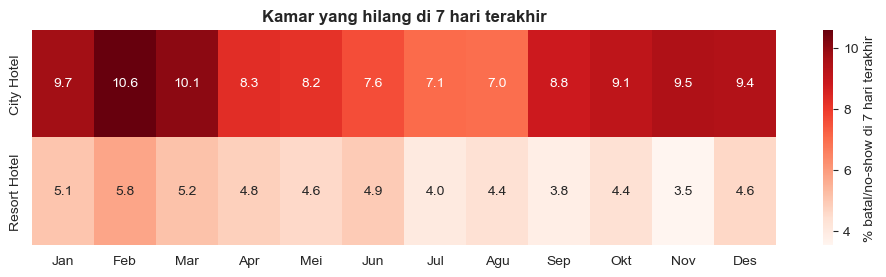

In [188]:
plt.figure(figsize=(12, 2.8))
sns.heatmap(buffer, annot=True, fmt='.1f', cmap='Reds', cbar_kws={'label': '% batal/no-show di 7 hari terakhir'})
plt.title('Kamar yang hilang di 7 hari terakhir')
plt.xlabel(''); plt.ylabel('')
plt.show()

- Dari booking yang masih aktif 7 hari sebelum kedatangan, **8,6% di City** dan **4,6% di Resort** akhirnya batal atau no-show. Dari 4.744 kasus itu, 1.012 adalah no-show. Revenue hilangnya **€1,64 juta** (City €1,25 juta, Resort €0,39 juta).
- Polanya terbalik dengan cancel rate total. Angka tertingginya ada di awal tahun (Februari: City 10,6%, Resort 5,8%), sedangkan musim ramai lebih rendah (Agustus: City 7,0%, Resort 4,4%).
- Artinya, di musim ramai pembatalan lebih banyak terjadi sebelum H-7, sedangkan di musim sepi porsi yang batal di minggu terakhir lebih besar. Apakah overbooking berguna di bulan itu bergantung pada apakah hotel penuh, yang dicek di 4.I.4.
- Angka ini menjadi batas atas buffer overbooking per hotel per bulan: City sekitar 7-11%, Resort sekitar 3,5-6% dari booking yang masih aktif di H-7. Buffer tetap dihitung dari jumlah booking, karena overbooking diukur dalam kamar.

**Faktor realisasi untuk laporan pickup.** Buffer di atas memakai minggu terakhir. Keputusan harga dan penerimaan grup diambil jauh lebih awal, dari booking yang ada di buku saat itu. Dari booking yang sudah ada di buku pada H-90 sampai H-14, berapa persen yang akhirnya datang, dan berapa persen kedatangan akhir yang sudah tercatat?

In [189]:
datang_akhir = df[df['is_canceled'] == 0]
jadi_datang = pd.DataFrame()
sudah_di_buku = pd.DataFrame()
for h in [90, 60, 30, 14]:
    di_buku = df[(df['lead_time'] >= h) & ((df['is_canceled'] == 0) | (df['days_before_arrival'] < h))]
    jadi_datang[f'H-{h}'] = di_buku.groupby('hotel')['is_canceled'].apply(lambda x: (x == 0).mean() * 100)
    sudah_di_buku[f'H-{h}'] = datang_akhir.groupby('hotel')['lead_time'].apply(lambda x: (x >= h).mean() * 100)

print('% booking di buku yang akhirnya datang (faktor realisasi)')
print(jadi_datang.round(1), '\n')
print('% kedatangan akhir yang sudah ada di buku (pickup)')
print(sudah_di_buku.round(1))

% booking di buku yang akhirnya datang (faktor realisasi)
              H-90  H-60  H-30  H-14
hotel                               
City Hotel    77.8  80.6  84.7  89.3
Resort Hotel  82.6  85.1  89.2  93.1 

% kedatangan akhir yang sudah ada di buku (pickup)
              H-90  H-60  H-30  H-14
hotel                               
City Hotel    29.2  40.5  56.7  69.5
Resort Hotel  31.7  40.0  52.4  63.2


Visualisasi data yang sudah didapat

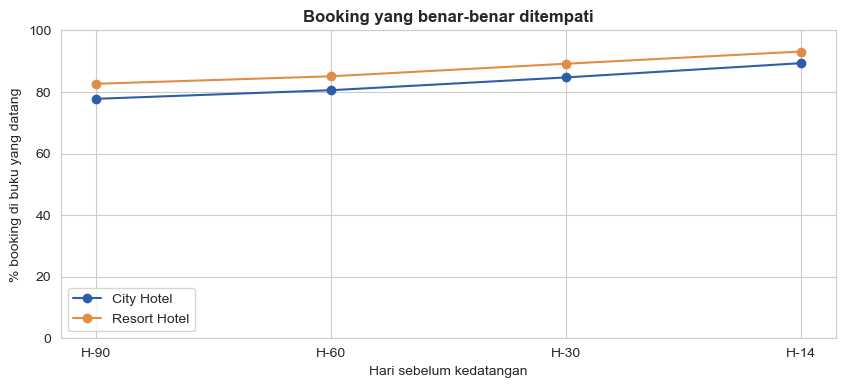

In [190]:
for hotel in ['City Hotel', 'Resort Hotel']:
    plt.plot(jadi_datang.columns, jadi_datang.loc[hotel], marker='o', color=WARNA_HOTEL[hotel], label=hotel)
plt.title('Booking yang benar-benar ditempati')
plt.xlabel('Hari sebelum kedatangan'); plt.ylabel('% booking di buku yang datang')
plt.ylim(0, 100)
plt.legend()
plt.show()

- **Faktor realisasi:** dari booking yang ada di buku pada H-30, hanya **84,7% (City)** dan **89,2% (Resort)** yang akhirnya datang. Pada H-90 angkanya 77,8% dan 82,6%.
- **Pickup:** pada H-30 baru **56,7% (City)** dan **52,4% (Resort)** kedatangan akhir yang sudah tercatat. Sisanya baru memesan di bulan terakhir.
- Angka di buku pada H-30 karena itu meleset ke dua arah: sebagian booking akan batal, dan sebagian tamu belum memesan. Perkiraan kedatangan butuh kedua faktor ini, per hotel dan per horizon (rekomendasi 2).
- H-7 tidak dimasukkan karena sudah diwakili buffer di atas.

**Uji ketahanan.** Keputusan menghapus 31.994 duplikat (3.B) menurunkan cancel rate dari 37,04% ke 27,52%. Apakah buffer H-7 ikut bergeser sebesar itu?

Pembuatan uji ketahanan untuk keputusan menghapus duplikat di 3.B. Pertanyaannya: kalau 31.994 baris duplikat tidak dihapus, apakah angka buffer H-7 ikut berubah banyak?

In [191]:
semua_baris = df_raw.copy()
semua_baris['children'] = semua_baris['children'].fillna(0)
semua_baris = semua_baris[(semua_baris['adults'] + semua_baris['children'] + semua_baris['babies']) > 0]
semua_baris = semua_baris[(semua_baris['adr'] >= 0) & (semua_baris['adr'] < 5000)].copy()
semua_baris['reservation_status_date'] = pd.to_datetime(semua_baris['reservation_status_date'])
semua_baris['arrival_date'] = pd.to_datetime(
    semua_baris['arrival_date_year'].astype(str) + '-' + semua_baris['arrival_date_month'] + '-' +
    semua_baris['arrival_date_day_of_month'].astype(str), format='%Y-%B-%d')
semua_baris['days_before_arrival'] = (semua_baris['arrival_date'] - semua_baris['reservation_status_date']).dt.days
aktif_semua = semua_baris[(semua_baris['is_canceled'] == 0) | (semua_baris['days_before_arrival'] <= 7)]


Selanjutnya dibuat tabel perbandingan uji ketahanan: data tanpa duplikat (yang dipakai di seluruh notebook) disandingkan dengan data yang duplikatnya dipertahankan.

In [192]:
uji_dup = pd.DataFrame()
uji_dup['cancel rate tanpa duplikat'] = df.groupby('hotel')['is_canceled'].mean() * 100
uji_dup['cancel rate dengan duplikat'] = semua_baris.groupby('hotel')['is_canceled'].mean() * 100
uji_dup['buffer H-7 tanpa duplikat'] = aktif_h7.groupby('hotel')['is_canceled'].mean() * 100
uji_dup['buffer H-7 dengan duplikat'] = aktif_semua.groupby('hotel')['is_canceled'].mean() * 100
uji_dup.round(1)

,cancel rate tanpa duplikat,cancel rate dengan duplikat,buffer H-7 tanpa duplikat,buffer H-7 dengan duplikat
hotel,,,,
City Hotel,30.1,41.8,8.6,9.4
Resort Hotel,23.5,27.8,4.6,5.1


- Kalau duplikat dipertahankan, cancel rate City naik **11,7 poin** (dari 30,1% ke 41,8%) dan Resort 4,3 poin.
- Buffer H-7 hanya bergeser **0,8 poin** di City dan **0,5 poin** di Resort.
- Artinya, hampir semua pembatalan pada baris duplikat terjadi sebelum H-7, sehingga tidak masuk perhitungan buffer. Angka buffer tetap bisa dipakai apa pun keputusan soal duplikat.

> **Babak 4 dari 6: Sasaran dan nilai** (4.F-4.I)
>
> Ciri dan waktu dari babak 2 dan 3 disusun menjadi sasaran kebijakan (4.F). Setelah itu dicek segmen mana yang harus dijaga (4.G, dan per hotel di 4.I.2), apakah ada satu kolom numerik yang dominan (4.H), dan konteks lain sebelum rekomendasi ditulis (4.I)

### **F. Konsentrasi: di mana kerugian menumpuk, dan siapa sasarannya?** (pertanyaan E)
4.C sampai 4.E menunjukkan booking seperti apa yang batal dan kapan. Sekarang kerugian ditelusuri ke sumbernya, lalu disusun menjadi sasaran kebijakan.

Prinsip Pareto: kalau sebagian besar kerugian datang dari sedikit sumber, tindakan bisa difokuskan ke sana.

#### **1. Agent**

Pembuatan variabel untuk memeriksa apakah pembatalan dan revenue yang hilang tersebar di banyak agent, atau menumpuk di segelintir agent saja?

In [193]:
booking_batal = df[df['is_canceled'] == 1]

pareto = pd.DataFrame()
pareto['jumlah_batal'] = booking_batal['agent'].value_counts()
pareto['%_pembatalan'] = pareto['jumlah_batal'] / pareto['jumlah_batal'].sum() * 100
pareto['kumulatif_%'] = pareto['%_pembatalan'].cumsum()        # cumsum = jumlah berjalan dari atas ke bawah
pareto['revenue_hilang'] = booking_batal.groupby('agent')['revenue_hilang'].sum()
pareto['%_revenue_hilang'] = pareto['revenue_hilang'] / booking_batal['revenue_hilang'].sum() * 100
pareto['cancel_rate_agent'] = df.groupby('agent')['is_canceled'].mean() * 100
pareto['%_booking'] = df['agent'].value_counts(normalize=True) * 100
pareto.head(8).round(1)


,jumlah_batal,%_pembatalan,kumulatif_%,revenue_hilang,%_revenue_hilang,cancel_rate_agent,%_booking
agent,,,,,,,
9,11522,48.0,48.0,5129205.9,45.6,40.1,32.9
240,4944,20.6,68.6,3246583.6,28.9,37.9,14.9
0,1548,6.4,75.0,376823.8,3.4,12.8,13.9
14,583,2.4,77.5,312741.8,2.8,17.4,3.8
250,494,2.1,79.5,367178.8,3.3,17.8,3.2
1,457,1.9,81.4,27980.7,0.2,37.2,1.4
7,436,1.8,83.2,162407.2,1.4,13.2,3.8
8,385,1.6,84.8,196125.1,1.7,27.8,1.6


In [194]:
# Agent 9 dan 240 menerima booking untuk hotel apa? pd.crosstab agent x hotel
top2 = df[df['agent'].isin([9, 240])]
pd.crosstab(top2['agent'], top2['hotel'])

hotel,City Hotel,Resort Hotel
agent,,
9,28715,6
240,8,13020


Visualisasi data agent nya

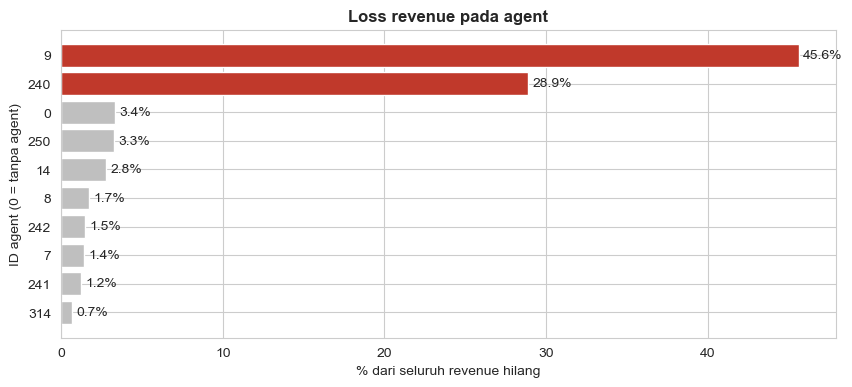

In [195]:
top = pareto.sort_values('revenue_hilang', ascending=False).head(10).sort_values('%_revenue_hilang')
warna = np.where(top.index.isin([9, 240]), SOROT, ABU)
bar = plt.barh(top.index.astype(str), top['%_revenue_hilang'], color=warna)
plt.bar_label(bar, fmt='%.1f%%', padding=3)
plt.title('Loss revenue pada agent')
plt.xlabel('% dari seluruh revenue hilang'); plt.ylabel('ID agent (0 = tanpa agent)')
plt.show()

- **Agent 9** (hampir seluruhnya City Hotel) menanggung **45,6%** revenue hilang (€5,13 juta) dan 48,0% pembatalan.
- **Agent 240** (hampir seluruhnya Resort Hotel) menanggung **28,9%** revenue hilang (€3,25 juta) dan 20,6% pembatalan.
- Berdua mereka membawa 47,9% booking tetapi **74,5% revenue yang hilang** (68,6% pembatalan). Revenue loss rate keduanya 44,1% dan 48,1%, jauh di atas rata-rata 32,6%.
- Mengubah syarat pembatalan dengan dua agent ini saja sudah menyentuh tiga perempat revenue yang hilang.

Apakah kehilangan sebesar itu juga terjadi pada agent besar lain? Pembandingnya adalah agent lain yang membawa minimal 1.000 booking di hotel yang sama.

Selanjutnya, membandingkan agent 9 dan 240 dengan agent besar lainnya di hotel yang sama. Pertanyaannya: apakah kehilangan 44-48% itu wajar untuk agent besar, atau memang khusus terjadi di dua agent itu?

In [196]:
agent_hotel = df[df['agent'] != 0].groupby(['hotel', 'agent'])['is_canceled'].agg(['count', 'mean']).reset_index()
agent_hotel.columns = ['hotel', 'agent', 'jumlah_booking', 'cancel_rate']
agent_hotel['cancel_rate'] = (agent_hotel['cancel_rate'] * 100).round(1)
rugi_agent = df[df['agent'] != 0].groupby(['hotel', 'agent'])[['revenue_hilang', 'revenue']].sum().reset_index()
rugi_agent['revenue_loss_rate'] = (rugi_agent['revenue_hilang'] / rugi_agent['revenue'] * 100).round(1)
agent_hotel = agent_hotel.merge(rugi_agent[['hotel', 'agent', 'revenue_loss_rate']], on=['hotel', 'agent'])
agent_hotel = agent_hotel[agent_hotel['jumlah_booking'] >= 1000].sort_values(['hotel', 'revenue_loss_rate'])
print(agent_hotel)

            hotel  agent  jumlah_booking  cancel_rate  revenue_loss_rate
26     City Hotel     28            1493          5.8                5.9
0      City Hotel      1            1222         37.2               11.3
6      City Hotel      7            3294         13.2               15.0
13     City Hotel     14            3342         17.4               22.3
7      City Hotel      8            1118         31.2               37.0
8      City Hotel      9           28715         40.1               44.1
299  Resort Hotel    241            1644         13.3               18.1
306  Resort Hotel    250            2778         17.8               21.1
298  Resort Hotel    240           13020         38.0               48.1


Visualisasi dari data yang sudah dibuat

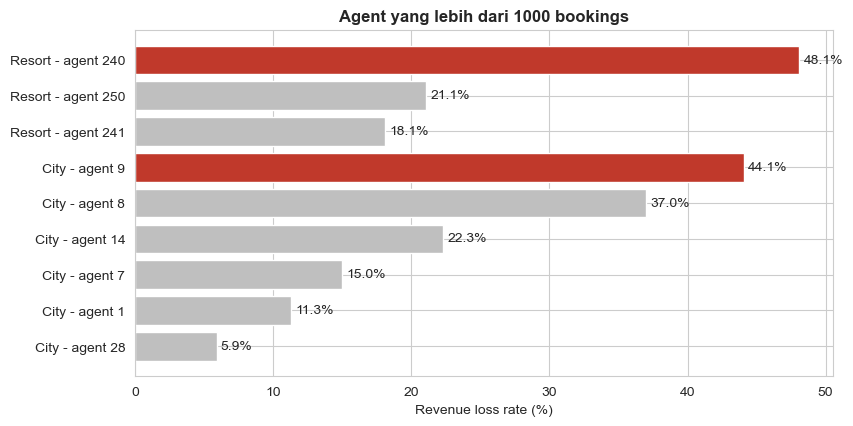

In [197]:
agent_hotel['label'] = agent_hotel['hotel'].str.replace(' Hotel', '') + ' - agent ' + agent_hotel['agent'].astype(str)
warna = np.where(agent_hotel['agent'].isin([9, 240]), SOROT, ABU)

plt.figure(figsize=(9, 4.5))
bar = plt.barh(agent_hotel['label'], agent_hotel['revenue_loss_rate'], color=warna)
plt.bar_label(bar, fmt='%.1f%%', padding=3)
plt.title('Agent yang lebih dari 1000 bookings')
plt.xlabel('Revenue loss rate (%)')
plt.show()

- **City:** agent 9 kehilangan **44,1%** nilai booking-nya (cancel rate 40,1%). Agent 28 hanya **5,9%**, agent 1 11,3%, agent 7 15,0%, dan agent 14 22,3%. Agent 8 juga tinggi (37,0%). Agent 1 batal 37,2%, tetapi hanya kehilangan 11,3% nilai, karena booking-nya yang batal bernilai kecil.
- **Resort:** agent 240 kehilangan **48,1%**, sedangkan agent 241 18,1% dan agent 250 21,1%.
- Enam dari tujuh agent besar lain menjaga revenue loss rate di 6-22%. Angka ini bisa menjadi tolok ukur saat syarat kontrak agent 9 dan 240 dibahas, dan agent 8 perlu ikut dipantau (rekomendasi 3).

#### **2. Segmen risiko tinggi**
Sasaran kebijakan disusun dari ciri yang memenuhi dua syarat: (1) sudah diketahui saat booking dibuat, dan (2) menunjukkan hubungan dengan revenue yang hilang di bagian sebelumnya.
- **Online TA** dan **lead time** memenuhi keduanya (4.C.2-4.C.3), dan keduanya juga yang menggerakkan naik-turunnya pembatalan (4.E.2).
- **Bulan kedatangan** sudah diketahui saat booking dibuat, dan 4.E menunjukkan kerugian menumpuk di bulan tertentu. Bulan rawan dihitung per hotel dari 2016 (satu-satunya tahun lengkap): bulan ketika revenue hilang kelompok Online TA dengan lead time > 30 hari berada di atas rata-rata bulanan hotel itu. 2015 dan 2017 dipakai untuk mengecek apakah bulannya sama.
- **Special request** dan **perubahan booking** tidak dipakai, karena nilainya baru lengkap setelah booking berjalan (4.C.2.f).

Kandidat aturan dibandingkan per hotel dengan dua rasio: % revenue hilang ÷ % booking (rasio), dan % revenue hilang ÷ % potensi revenue (rasio_revenue). Rasio kedua menjadi dasar pilihan, karena kebijakan dinilai dari nilai booking yang disentuhnya.

Pembuatan variabel bulan rawan di setiap hotel, yaitu bulan ketika revenue yang hilang dari booking Online TA jauh hari (lead time > 30 hari) di atas rata-rata bulanan hotel itu.

In [198]:
booking_batal = df[df['is_canceled'] == 1]
ota_jauh = (df['market_segment'] == 'Online TA') & (df['lead_time'] > 30)

Selanjutnya membuat dua dictionary kosong sebagai tempat menyimpan hasil per hotel dari perulangan, lalu membuat penanda True/False: True kalau booking lewat Online TA dan dipesan lebih dari 30 hari sebelum kedatangan. Ini kelompok yang dicurigai paling berisiko.

In [199]:
bulan_rawan_hotel = {}
hilang_2016 = {}
for hotel in ['City Hotel', 'Resort Hotel']:
    x = df[ota_jauh & (df['is_canceled'] == 1) & (df['hotel'] == hotel)]
    per_tahun_bulan = x.pivot_table(index='arrival_date_year', columns='arrival_month', values='revenue_hilang', aggfunc='sum') / 1000
    print(hotel, '- revenue hilang Online TA + lead time > 30 hari (€ ribu):')
    tabel_tampil = per_tahun_bulan.copy()
    tabel_tampil.columns = label_bulan
    print(tabel_tampil.round(0))
    for tahun in [2015, 2016, 2017]:
        baris = per_tahun_bulan.loc[tahun].dropna()
        di_atas = list(baris[baris > baris.mean()].index)
        nama = []
        for b in di_atas:
            nama.append(label_bulan[b - 1])
        print(f"   {tahun}: bulan di atas rata-rata = {nama}")
        if tahun == 2016:
            bulan_rawan_hotel[hotel] = di_atas
            hilang_2016[hotel] = per_tahun_bulan.loc[2016]

City Hotel - revenue hilang Online TA + lead time > 30 hari (€ ribu):
                     Jan    Feb    Mar    Apr    Mei    Jun    Jul    Agu  \
arrival_date_year                                                           
2015                 NaN    NaN    NaN    NaN    NaN    NaN   50.0   14.0   
2016                 9.0   30.0  130.0  167.0  148.0  131.0  222.0  333.0   
2017               127.0  130.0  185.0  343.0  348.0  302.0  386.0  450.0   

                     Sep    Okt    Nov    Des  
arrival_date_year                              
2015                11.0   23.0    8.0   37.0  
2016               210.0  231.0  129.0  199.0  
2017                 NaN    NaN    NaN    NaN  
   2015: bulan di atas rata-rata = ['Jul', 'Des']
   2016: bulan di atas rata-rata = ['Apr', 'Jul', 'Agu', 'Sep', 'Okt', 'Des']
   2017: bulan di atas rata-rata = ['Apr', 'Mei', 'Jun', 'Jul', 'Agu']
Resort Hotel - revenue hilang Online TA + lead time > 30 hari (€ ribu):
                    Jan   Feb   M

Selanjutnya membuat fungsi untuk menilai satu kandidat aturan kebijakan (misalnya “Online TA + lead time > 90 hari”) di satu hotel. Fungsi ini dipanggil berkali-kali untuk beberapa kandidat, lalu hasilnya disusun menjadi tabel pembanding.

In [200]:
def ukur(hotel, syarat, nama):
    # ukuran satu kandidat aturan di satu hotel
    data_hotel = df[df['hotel'] == hotel]
    batal_hotel = data_hotel[data_hotel['is_canceled'] == 1]
    m = syarat[data_hotel.index]
    batal_m = batal_hotel[m[batal_hotel.index]]
    porsi_booking = m.mean() * 100
    porsi_hilang = batal_m['revenue_hilang'].sum() / batal_hotel['revenue_hilang'].sum() * 100
    porsi_potensi = data_hotel[m]['revenue'].sum() / data_hotel['revenue'].sum() * 100      # cakupan menurut potensi revenue
    return [hotel, nama, porsi_booking, porsi_potensi, data_hotel[m]['is_canceled'].mean() * 100,
            len(batal_m) / len(batal_hotel) * 100, porsi_hilang, batal_m['revenue_hilang'].sum() / 1e6,
            porsi_hilang / porsi_booking, porsi_hilang / porsi_potensi]

Lalu ukur 4 kandidat aturan di setiap hotel, lalu menyusun hasilnya menjadi satu tabel pembanding.

In [201]:
semua_bulan = list(range(1, 13))
lama = [4, 5, 6, 7, 8]                     # aturan lama: April-Agustus, dari rata-rata per bulan kalender
banding = []
for hotel in ['City Hotel', 'Resort Hotel']:
    banding.append(ukur(hotel, ota_jauh & df['arrival_month'].isin(lama), 'Online TA, lead > 30, April-Agustus (lama)'))
    banding.append(ukur(hotel, ota_jauh & df['arrival_month'].isin(bulan_rawan_hotel[hotel]), 'Online TA, lead > 30, bulan rawan 2016'))
    banding.append(ukur(hotel, ota_jauh, 'Online TA, lead > 30, sepanjang tahun'))
    banding.append(ukur(hotel, (df['market_segment'] == 'Online TA') & (df['lead_time'] > 90), 'Online TA, lead > 90, sepanjang tahun'))
banding = pd.DataFrame(banding, columns=['hotel', 'kandidat', '% booking hotel', '% potensi revenue hotel', 'cancel rate',
                                         '% pembatalan hotel', '% revenue hilang hotel', 'revenue hilang (€ juta)', 'rasio', 'rasio_revenue'])
print('rasio = % revenue hilang ÷ % booking; rasio_revenue = % revenue hilang ÷ % potensi revenue (makin tinggi, makin tepat sasaran)')
print(banding.round(2).to_string(index=False))

rasio = % revenue hilang ÷ % booking; rasio_revenue = % revenue hilang ÷ % potensi revenue (makin tinggi, makin tepat sasaran)
       hotel                                   kandidat  % booking hotel  % potensi revenue hotel  cancel rate  % pembatalan hotel  % revenue hilang hotel  revenue hilang (€ juta)  rasio  rasio_revenue
  City Hotel Online TA, lead > 30, April-Agustus (lama)            26.87                    34.94        41.90               37.40                   45.08                     2.89   1.68           1.29
  City Hotel     Online TA, lead > 30, bulan rawan 2016            25.05                    31.52        42.56               35.42                   41.69                     2.68   1.66           1.32
  City Hotel      Online TA, lead > 30, sepanjang tahun            43.27                    52.10        42.09               60.51                   67.80                     4.35   1.57           1.30
  City Hotel      Online TA, lead > 90, sepanjang tahun          

Lalu visualisasikan data-data yang sudah didapat.

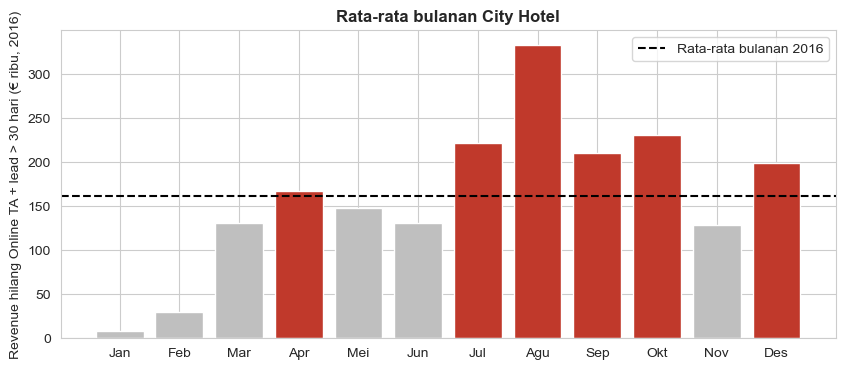

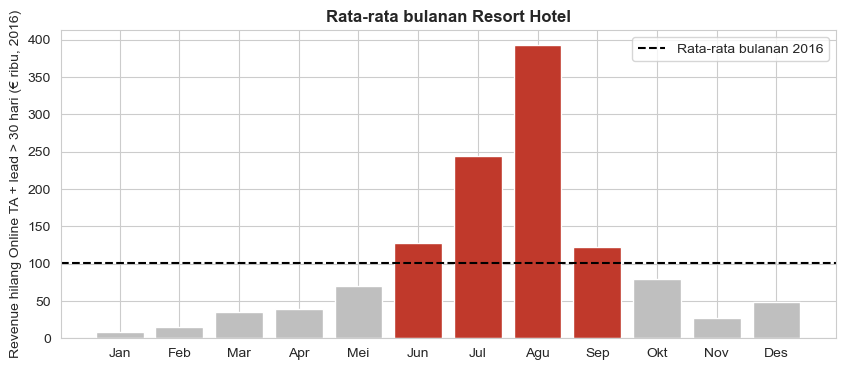

In [202]:
judul = {'City Hotel': 'Rata-rata bulanan City Hotel',
         'Resort Hotel': 'Rata-rata bulanan Resort Hotel'}
for hotel in ['City Hotel', 'Resort Hotel']:
    nilai = hilang_2016[hotel]
    warna = np.where(nilai.index.isin(bulan_rawan_hotel[hotel]), SOROT, ABU)     # bulan rawan merah
    plt.bar(label_bulan, nilai, color=warna)
    plt.axhline(nilai.mean(), color='black', linestyle='--', label='Rata-rata bulanan 2016')
    plt.title(judul[hotel])
    plt.ylabel('Revenue hilang Online TA + lead > 30 hari (€ ribu, 2016)')
    plt.legend()
    plt.show()

- **Resort:** revenue hilang kelompok ini berada di atas rata-rata pada **Juni-September** 2016, dan 2015 serta 2017 menunjuk bulan yang sama. Syarat Juni-September memberi rasio booking tertinggi (3,17), tetapi bulan-bulan itu juga bulan dengan booking paling mahal: kelompoknya 16,8% booking tetapi 32,2% potensi revenue Resort. Diukur dengan potensi revenue, **lead time > 90 hari sepanjang tahun** lebih tepat sasaran (rasio_revenue 1,75 vs 1,65): 27,5% potensi revenue Resort, 48,0% revenue hilang Resort, dan cancel rate 49,8%.
- **City:** bulan di atas rata-rata berganti tiap tahun (2016: April, Juli-Oktober, dan Desember; 2017: April-Agustus; data City 2015 tipis). **Lead time > 90 hari sepanjang tahun** paling tepat sasaran dengan kedua rasio (rasio_revenue 1,37, rasio 1,74): 29,2% potensi revenue City, 40,0% revenue hilang City, dan cancel rate 44,7%.

Selanjutnya menetapkan aturan segmen risiko yang dipilih dari perbandingan kandidat sebelumnya, lalu menyimpannya sebagai kolom supaya bisa dipakai di bagian-bagian berikutnya.

In [203]:
risiko = (df['market_segment'] == 'Online TA') & (df['lead_time'] > 90)
df['segmen_risiko'] = np.where(risiko, 'Risiko tinggi', 'Lainnya')
bulan_rawan = bulan_rawan_hotel['Resort Hotel']  
booking_batal = df[df['is_canceled'] == 1]

Lalu membuat tabel ringkasan segmen risiko: dua baris (“Risiko tinggi” dan “Lainnya”) yang dibandingkan dari enam sisi.

In [204]:
ringkas_risiko = pd.DataFrame()
ringkas_risiko['% booking'] = df['segmen_risiko'].value_counts(normalize=True) * 100
ringkas_risiko['% potensi revenue'] = df.groupby('segmen_risiko')['revenue'].sum() / df['revenue'].sum() * 100
ringkas_risiko['% pembatalan'] = booking_batal['segmen_risiko'].value_counts(normalize=True) * 100
ringkas_risiko['% revenue hilang'] = booking_batal.groupby('segmen_risiko')['revenue_hilang'].sum() / booking_batal['revenue_hilang'].sum() * 100
ringkas_risiko['revenue hilang (€)'] = booking_batal.groupby('segmen_risiko')['revenue_hilang'].sum()
ringkas_risiko['cancel_rate'] = df.groupby('segmen_risiko')['is_canceled'].mean() * 100
print(ringkas_risiko.round(1))

               % booking  % potensi revenue  % pembatalan  % revenue hilang  \
segmen_risiko                                                                 
Lainnya             79.2               71.6          65.0              56.6   
Risiko tinggi       20.8               28.4          35.0              43.4   

               revenue hilang (€)  cancel_rate  
segmen_risiko                                   
Lainnya                 6359723.1         22.6  
Risiko tinggi           4881562.5         46.4  


Lalu visualisasikan

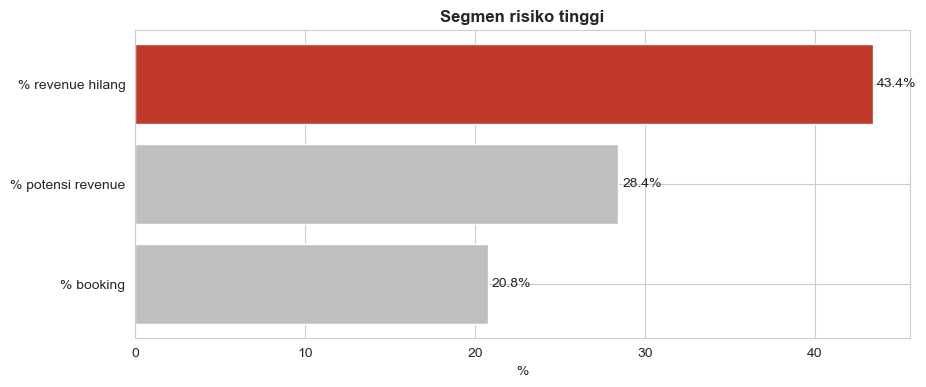

In [205]:
angka = ringkas_risiko.loc['Risiko tinggi', ['% booking', '% potensi revenue', '% revenue hilang']]
bar = plt.barh(angka.index, angka, color=[ABU, ABU, SOROT])
plt.bar_label(bar, fmt='%.1f%%', padding=3)
plt.title('Segmen risiko tinggi')
plt.xlabel('%')
plt.show()

Aturan ini mencakup **20,8% booking** dan **28,4% potensi revenue**, tetapi menyumbang **35,0% pembatalan** dan **43,4% revenue yang hilang (€4,88 juta)**, dengan cancel rate **46,4%** (nilai 26 bulan). Kedua cirinya sudah diketahui saat booking dibuat, jadi kebijakan untuk kelompok ini tidak mengubah kebijakan bagi 79,2% booking lainnya. Selisih cancel rate ini diuji dengan 95% confidence interval di 4.N.

Kebijakan deposit ditetapkan per hotel, jadi segmen risiko tinggi juga perlu dilihat per hotel.

Setelah itu akan memecah segmen risiko per hotel. Tabel ringkasan sebelumnya menggabungkan kedua hotel, padahal kebijakan deposit ditetapkan per hotel. Jadi perlu dicek apakah aturan yang sama juga tepat sasaran di masing-masing hotel.

In [206]:
risiko_hotel = pd.DataFrame()
risiko_hotel['% booking risiko tinggi'] = df.groupby('hotel')['segmen_risiko'].apply(
    lambda x: (x == 'Risiko tinggi').mean() * 100)
risiko_hotel['cancel rate segmen risiko'] = df[df['segmen_risiko'] == 'Risiko tinggi'].groupby('hotel')['is_canceled'].mean() * 100

Menghitung berapa euro yang hilang dari segmen risiko di setiap hotel, dan berapa persen itu dari seluruh kerugian hotel tersebut.

In [207]:
batal_risiko = booking_batal[booking_batal['segmen_risiko'] == 'Risiko tinggi']
risiko_hotel['revenue hilang segmen risiko'] = batal_risiko.groupby('hotel')['revenue_hilang'].sum()
risiko_hotel['% dari revenue hilang hotel'] = risiko_hotel['revenue hilang segmen risiko'] / booking_batal.groupby('hotel')['revenue_hilang'].sum() * 100
risiko_hotel.round(1)

,% booking risiko tinggi,cancel rate segmen risiko,revenue hilang segmen risiko,% dari revenue hilang hotel
hotel,,,,
City Hotel,23.0,44.7,2566963.4,40.0
Resort Hotel,17.3,49.8,2314599.1,48.0


#### **3. Celah di luar segmen risiko: booking lebih dari 7 malam**
Segmen risiko tinggi dihitung per booking. Satu booking 10 malam yang batal menghapus revenue sepuluh kali booking 1 malam, jadi lama menginap perlu dicek sebagai ciri tambahan. Lama menginap sudah diketahui saat booking dibuat.

Selanjutnya untuk mencari celah di luar segmen risiko. Segmen risiko dihitung per booking, padahal satu booking 10 malam yang batal menghapus revenue sebesar sepuluh booking 1 malam. Jadi perlu dicek apakah booking yang menginap lama juga menanggung kerugian besar, dan berapa yang belum tertangkap aturan Online TA + lead time > 90 hari.

In [208]:
df['inap_panjang'] = np.where(df['total_nights'] > 7, 'Lebih dari 7 malam', '7 malam atau kurang')
booking_batal = df[df['is_canceled'] == 1]

inap = cancel_rate(df, 'inap_panjang')
inap['% booking'] = inap['jumlah_booking'] / inap['jumlah_booking'].sum() * 100
inap['% revenue hilang'] = booking_batal.groupby('inap_panjang')['revenue_hilang'].sum() / booking_batal['revenue_hilang'].sum() * 100
print(inap.round(1), '\n')
print('Revenue loss rate per hotel (%)')
print(loss_rate_pivot(df, 'hotel', 'inap_panjang').round(1), '\n')
print('Cancel rate per hotel (%)')
print((df.pivot_table(index='hotel', columns='inap_panjang', values='is_canceled', aggfunc='mean') * 100).round(1))

                     revenue_loss_rate  cancel_rate  jumlah_booking  \
inap_panjang                                                          
7 malam atau kurang               31.4         27.1           82397   
Lebih dari 7 malam                38.8         34.3            4831   

                     revenue_hilang  potensi_revenue  % booking  \
inap_panjang                                                      
7 malam atau kurang       9044151.5       28779495.6       94.5   
Lebih dari 7 malam        2197134.0        5666759.3        5.5   

                     % revenue hilang  
inap_panjang                           
7 malam atau kurang              80.5  
Lebih dari 7 malam               19.5   

Revenue loss rate per hotel (%)
inap_panjang  7 malam atau kurang  Lebih dari 7 malam
hotel                                                
City Hotel                   32.0                61.0
Resort Hotel                 30.5                31.3 

Cancel rate per hotel (%)


inap_panjang  7 malam atau kurang  Lebih dari 7 malam
hotel                                                
City Hotel                   29.5                55.1
Resort Hotel                 23.0                27.7


- Booking lebih dari 7 malam hanya **5,5%** booking, tetapi menyumbang **19,5%** revenue yang hilang. Revenue loss rate-nya 38,8% (cancel rate 34,3%); di City **61,0%**, di Resort 31,3%.

Selanjutnya menghitung dan memvisualisasikan berapa revenue hilang dari booking lebih dari 7 malam yang tidak masuk segmen risiko tinggi

Revenue hilang inap panjang di luar segmen risiko : €1,115,911
Porsi dari seluruh revenue hilang                 : 9.9%
Porsi booking > 7 malam di luar segmen risiko     : 3.9% dari semua booking
market_segment
Online TA        50.3
Offline TA/TO    22.4
Direct           18.6
Name: proportion, dtype: float64


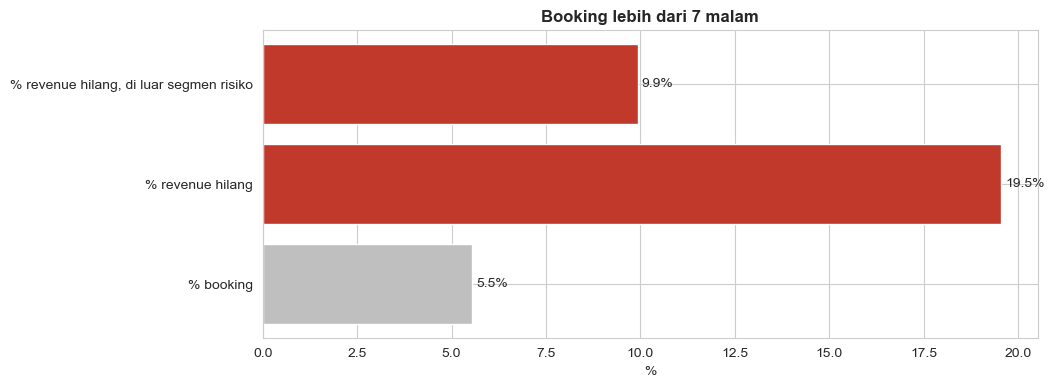

In [209]:
luar_risiko = booking_batal[(booking_batal['inap_panjang'] == 'Lebih dari 7 malam') & (booking_batal['segmen_risiko'] == 'Lainnya')]
print(f"Revenue hilang inap panjang di luar segmen risiko : €{luar_risiko['revenue_hilang'].sum():,.0f}")
print(f"Porsi dari seluruh revenue hilang                 : {luar_risiko['revenue_hilang'].sum() / booking_batal['revenue_hilang'].sum():.1%}")
print(f"Porsi booking > 7 malam di luar segmen risiko     : {((df['inap_panjang'] == 'Lebih dari 7 malam') & (df['segmen_risiko'] == 'Lainnya')).mean():.1%} dari semua booking")
print(luar_risiko['market_segment'].value_counts(normalize=True).mul(100).round(1).head(3))

angka_inap = pd.Series({'% booking': inap.loc['Lebih dari 7 malam', '% booking'],
                        '% revenue hilang': inap.loc['Lebih dari 7 malam', '% revenue hilang'],
                        '% revenue hilang, di luar segmen risiko': luar_risiko['revenue_hilang'].sum() / booking_batal['revenue_hilang'].sum() * 100})
bar = plt.barh(angka_inap.index, angka_inap, color=[ABU, SOROT, SOROT])
plt.bar_label(bar, fmt='%.1f%%', padding=3)
plt.title('Booking lebih dari 7 malam')
plt.xlabel('%')
plt.show()

- Booking lebih dari 7 malam hanya **5,5%** booking, tetapi menyumbang **19,5%** revenue yang hilang. Revenue loss rate-nya 38,8% (cancel rate 34,3%); di City **61,0%**, di Resort 31,3%.
- **€1,12 juta (9,9% revenue hilang)** datang dari booking panjang yang tidak masuk segmen risiko tinggi. Jumlahnya hanya 3,9% booking, dan 50,3% di antaranya tetap lewat Online TA.

### **G. Market segment mana yang paling menguntungkan bahkan setelah dikurangi pembatalan?** (pertanyaan F)
4.F menunjukkan di mana kerugian terbesar. Tetapi segmen yang sering batal belum tentu harus dihindari; perlu dilihat juga berapa nilai yang dibawanya.

Ukuran yang dipakai: revenue yang masuk per booking = revenue booking yang tidak batal ÷ semua booking di segmen itu.

#### **1. Revenue masuk per booking, per segmen**

Pembuatan Profil tiap market segment: jumlah booking, porsi, cancel rate, harga, dan lama menginap

In [210]:
nilai = df.groupby('market_segment')['is_canceled'].agg(['count', 'mean'])
nilai.columns = ['jumlah_booking', 'cancel_rate']
nilai['cancel_rate'] = nilai['cancel_rate'] * 100
nilai['%_booking'] = nilai['jumlah_booking'] / nilai['jumlah_booking'].sum() * 100
nilai['adr_rata2'] = df.groupby('market_segment')['adr'].mean()
nilai['malam_rata2'] = df.groupby('market_segment')['total_nights'].mean()

Nilai tiap segmen: revenue dari booking check-out, dibagi semua booking segmen itu (termasuk yang batal)

In [211]:
nilai['revenue_masuk'] = df[df['is_canceled'] == 0].groupby('market_segment')['revenue'].sum()
nilai['revenue_masuk_per_booking'] = nilai['revenue_masuk'] / nilai['jumlah_booking']
nilai['%_revenue_masuk'] = nilai['revenue_masuk'] / nilai['revenue_masuk'].sum() * 100

Tampilkan segmen dengan minimal 100 booking, dari yang terbanyak

In [212]:
tampil = nilai[nilai['jumlah_booking'] >= 100].sort_values('jumlah_booking', ascending=False)

print('Profil booking per segmen')
print(tampil[['jumlah_booking', '%_booking', 'cancel_rate', 'adr_rata2', 'malam_rata2']].round(1), '\n')
print('Nilai per segmen')
print(tampil[['revenue_masuk', '%_revenue_masuk', 'revenue_masuk_per_booking']].round(1))

Profil booking per segmen
                jumlah_booking  %_booking  cancel_rate  adr_rata2  malam_rata2
market_segment                                                                
Online TA                51553       59.1         35.4      118.3          3.6
Offline TA/TO            13854       15.9         14.8       81.6          4.7
Direct                   11780       13.5         14.7      116.8          3.2
Groups                    4921        5.6         27.1       75.2          3.4
Corporate                 4200        4.8         12.1       68.3          2.0
Complementary              692        0.8         12.3        3.1          1.7
Aviation                   226        0.3         19.9      100.6          3.6 

Nilai per segmen
                revenue_masuk  %_revenue_masuk  revenue_masuk_per_booking
market_segment                                                           
Online TA          12966424.6             56.5                      251.5
Offline TA/TO       45

Lalu visualisasikan datanya

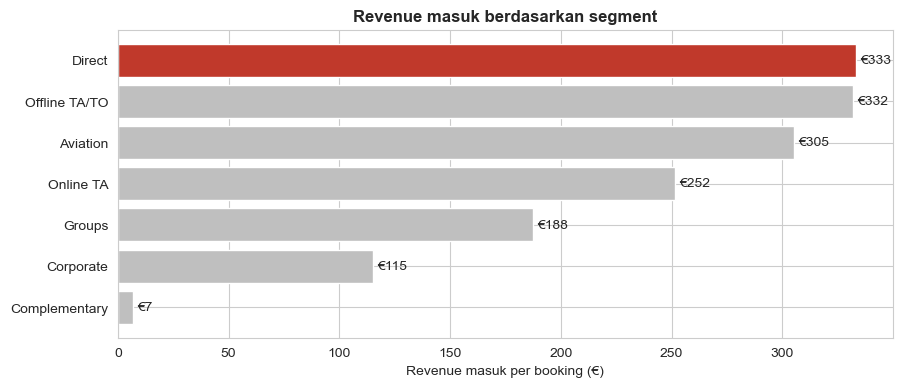

In [213]:
v = nilai[nilai['jumlah_booking'] >= 100].sort_values('revenue_masuk_per_booking')
warna = np.where(v.index == 'Direct', SOROT, ABU)
bar = plt.barh(v.index, v['revenue_masuk_per_booking'], color=warna)
plt.bar_label(bar, fmt='€%.0f', padding=3)
plt.title('Revenue masuk berdasarkan segment')
plt.xlabel('Revenue masuk per booking (€)')
plt.show()

- Revenue masuk per booking: **Direct €333**, Offline TA/TO €332, **Online TA €252**, Groups €188, Corporate €115.
- ADR Direct (€116,8) hampir sama dengan OTA (€118,3), tetapi nilai yang hilang kurang dari separuhnya (revenue loss rate 19,1% vs 41,7%; cancel rate 14,7% vs 35,4%). Selisih gabungannya sekitar €82 per booking, tetapi angka ini ikut terdorong oleh porsi Resort yang lebih besar di Direct. Per hotel (4.I.2), **booking Direct bernilai sekitar €45 lebih besar dari OTA di City dan €92 di Resort**, belum termasuk komisi agent yang tidak tercatat di dataset. Selisih per hotel ini diuji di 4.N (Welch t-test, p-value di bawah 0,001).
- OTA tetap penyumbang revenue terbesar (56% revenue masuk) karena volumenya. Naik-turunnya revenue hotel juga digerakkan Online TA (4.E.2).
- Revenue masuk di sini hanya dari booking check-out. Forfeited Deposit Revenue (€0,24 juta, 4.B.1) tidak dimasukkan supaya angkanya sama dengan 4.J.

#### **2. Tamu repeat, tipe tamu, dan lama menginap**

In [214]:
repeat = df.groupby('is_repeated_guest')['is_canceled'].agg(['count', 'mean'])
repeat.columns = ['jumlah', 'cancel_rate']
repeat['adr_rata2'] = df.groupby('is_repeated_guest')['adr'].mean()
repeat['porsi_direct_corporate'] = df.groupby('is_repeated_guest')['market_segment'].apply(
    lambda x: x.isin(['Direct', 'Corporate']).mean())
repeat['revenue_loss_rate'] = df.groupby('is_repeated_guest')['revenue_hilang'].sum() / df.groupby('is_repeated_guest')['revenue'].sum() * 100
print(repeat.round(3))

                   jumlah  cancel_rate  adr_rata2  porsi_direct_corporate  \
is_repeated_guest                                                           
0                   83865        0.283    108.098                   0.164   
1                    3363        0.077     65.584                   0.659   

                   revenue_loss_rate  
is_repeated_guest                     
0                             32.981  
1                             10.450  


Setelah itu, melihat tipe tamu nya

In [215]:
tipe = df.groupby('guest_type')['is_canceled'].agg(['count', 'mean'])
tipe.columns = ['jumlah', 'cancel_rate']
tipe['adr_rata2'] = df.groupby('guest_type')['adr'].mean()
tipe['malam_rata2'] = df.groupby('guest_type')['total_nights'].mean()
tipe['request_rata2'] = df.groupby('guest_type')['total_of_special_requests'].mean()
tipe['revenue_loss_rate'] = df.groupby('guest_type')['revenue_hilang'].sum() / df.groupby('guest_type')['revenue'].sum() * 100
print(tipe.round(2))

                jumlah  cancel_rate  adr_rata2  malam_rata2  request_rata2  \
guest_type                                                                   
Grup 3+ dewasa    5477         0.34     153.63         3.74           0.90   
Keluarga          9103         0.34     154.91         3.94           0.93   
Pasangan         56580         0.28     101.90         3.83           0.72   
Solo             16068         0.19      79.00         2.69           0.42   

                revenue_loss_rate  
guest_type                         
Grup 3+ dewasa              35.44  
Keluarga                    41.60  
Pasangan                    30.79  
Solo                        27.19  


Tipe tamu sudah lalu dilanjutkan ke berapa lama menginapnya

In [216]:
df['nights_grp'] = pd.cut(df['total_nights'], bins=[-1, 0, 2, 4, 7, 100],
                          labels=['0 (day-use)', '1-2', '3-4', '5-7', '>7'])
cancel_rate(df, 'nights_grp')

,revenue_loss_rate,cancel_rate,jumlah_booking,revenue_hilang,potensi_revenue
nights_grp,,,,,
0 (day-use),NaN,3.9,591,0.00,0.00
1-2,24.4,22.4,32902,1218914.86,4995617.14
3-4,31.5,30.2,31392,3740848.18,11862201.92
5-7,34.3,31.3,17512,4084388.49,11921676.57
>7,38.8,34.3,4831,2197134.02,5666759.30


- **Tamu repeat:** revenue loss rate **10,5%** (cancel rate 7,7%), tetapi ADR hanya €65,6 (tamu baru €108,1), dan 66% datang lewat Direct atau Corporate. Tamu repeat jarang batal tetapi membayar lebih murah.
- **Keluarga & Grup 3+ dewasa:** ADR tertinggi (sekitar €154), dan nilai yang hilang juga paling besar (41,6% dan 35,4%). **Solo:** paling kecil (27,2%; cancel rate 19%), ADR €79.
- **Lama menginap:** 1-2 malam kehilangan 24,4% nilai, naik menjadi 38,8% untuk lebih dari 7 malam (cancel rate dari 22,4% ke 34,3%). Booking panjang lebih sering batal dan nilainya paling besar.

#### **3. Hari kedatangan per tipe tamu**
Di 4.C, hari kedatangan membedakan cancel rate kurang dari 10 poin. Angka itu rata-rata semua tamu, padahal komposisi tamu bisa berbeda di tiap hari. Polanya dicek per tipe tamu.

In [217]:
label_hari = ['Sen', 'Sel', 'Rab', 'Kam', 'Jum', 'Sab', 'Min']

Porsi kedatangan tiap tipe tamu per hari (setiap baris berjumlah 100%)

In [218]:
hari_tipe = pd.crosstab(df['guest_type'], df['arrival_weekday'], normalize='index') * 100
hari_tipe = hari_tipe[urutan_hari]
hari_tipe.columns = label_hari
print('% kedatangan per hari')
print(hari_tipe.round(1))

% kedatangan per hari
                 Sen   Sel   Rab   Kam   Jum   Sab   Min
guest_type                                              
Grup 3+ dewasa  16.1  10.9  11.9  15.2  16.2  16.0  13.6
Keluarga        15.6  11.0  11.0  13.9  16.3  18.9  13.4
Pasangan        15.2  11.5  11.8  15.0  16.3  16.2  13.9
Solo            20.2  17.8  18.2  14.7  10.6   8.2  10.3


Visualisasikan data yang sudah didapat

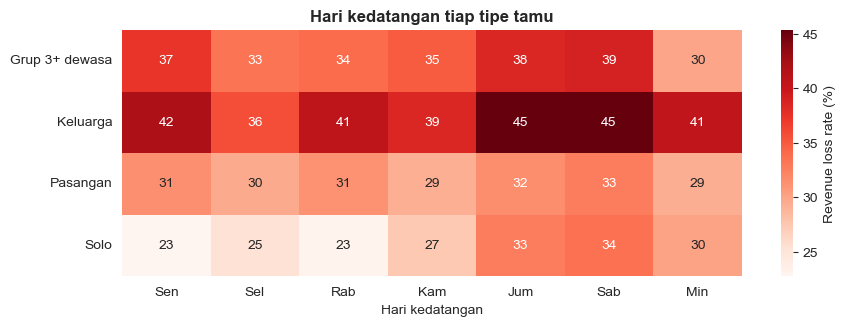

In [219]:
batal_hari_tipe = loss_rate_pivot(df, 'guest_type', 'arrival_weekday')
batal_hari_tipe = batal_hari_tipe[urutan_hari]
batal_hari_tipe.columns = label_hari

plt.figure(figsize=(10, 3.2))
sns.heatmap(batal_hari_tipe, annot=True, fmt='.0f', cmap='Reds', cbar_kws={'label': 'Revenue loss rate (%)'})
plt.title('Hari kedatangan tiap tipe tamu')
plt.xlabel('Hari kedatangan'); plt.ylabel('')
plt.show()

- Tamu solo datang di awal minggu: 56% tiba Senin-Rabu dan hanya 8,2% di hari Sabtu. Solo yang datang Senin-Rabu kehilangan 23-25% nilai, sedangkan Kamis-Minggu 27-34%.
- Keluarga paling banyak tiba hari Sabtu (18,9%). Pasangan dan grup tersebar cukup merata, dengan porsi terkecil di hari Selasa dan Rabu.
- Di luar tamu solo, selisih antarhari tetap di bawah 10 poin.

Selanjutnya mengecek apakah tamu yang datang sendirian (solo) di awal minggu berbeda dari tamu solo yang datang di akhir minggu, baik dari sisi pembatalan, tamu repeat, maupun channel pemesanannya.

In [220]:
df['hari_ke'] = df['arrival_date'].dt.dayofweek          # 0 = Senin, 6 = Minggu

solo = df[df['guest_type'] == 'Solo']
solo_awal = solo[solo['hari_ke'] <= 2]                   # datang Senin-Rabu
solo_akhir = solo[solo['hari_ke'] >= 3]                  # datang Kamis-Minggu

Lalu membuat fungsi untuk membagi tamu solo menjadi dua kelompok. <= 2 berarti hari 0, 1, 2 (Senin–Rabu), dan >= 3 berarti hari 3 sampai 6 (Kamis–Minggu).

In [221]:
def profil_solo(data):
    # ringkasan satu kelompok tamu solo
    hasil = pd.Series(dtype=float)
    hasil['jumlah booking'] = len(data)
    hasil['% dari tamu solo'] = len(data) / len(solo) * 100
    hasil['revenue loss rate (%)'] = data['revenue_hilang'].sum() / data['revenue'].sum() * 100
    hasil['cancel rate (%)'] = data['is_canceled'].mean() * 100
    hasil['tamu repeat (%)'] = data['is_repeated_guest'].mean() * 100
    hasil['lewat Corporate atau Direct (%)'] = data['market_segment'].isin(['Corporate', 'Direct']).mean() * 100
    hasil['di City Hotel (%)'] = (data['hotel'] == 'City Hotel').mean() * 100
    hasil['masuk segmen risiko tinggi (%)'] = (data['segmen_risiko'] == 'Risiko tinggi').mean() * 100
    return hasil

Tabel 1: profil tamu solo menurut hari kedatangan

In [222]:
tabel_solo = pd.DataFrame()
tabel_solo['Senin-Rabu'] = profil_solo(solo_awal)
tabel_solo['Kamis-Minggu'] = profil_solo(solo_akhir)
print('Profil tamu solo menurut hari kedatangan')
print(tabel_solo.round(1), '\n')

Profil tamu solo menurut hari kedatangan
                                 Senin-Rabu  Kamis-Minggu
jumlah booking                       9018.0        7050.0
% dari tamu solo                       56.1          43.9
revenue loss rate (%)                  23.6          30.8
cancel rate (%)                        15.7          23.8
tamu repeat (%)                        18.2           7.8
lewat Corporate atau Direct (%)        40.7          26.1
di City Hotel (%)                      61.6          65.5
masuk segmen risiko tinggi (%)          4.5           8.3 



Pembuatan Tabel 2: median ADR tamu solo yang menginap, per hotel

In [223]:
adr_solo = pd.DataFrame()
adr_solo['Senin-Rabu'] = solo_awal[solo_awal['is_canceled'] == 0].groupby('hotel')['adr'].median()
adr_solo['Kamis-Minggu'] = solo_akhir[solo_akhir['is_canceled'] == 0].groupby('hotel')['adr'].median()
print('Median ADR tamu solo yang menginap (€)')
print(adr_solo.round(1))

Median ADR tamu solo yang menginap (€)
              Senin-Rabu  Kamis-Minggu
hotel                                 
City Hotel          89.0          89.0
Resort Hotel        43.0          48.0


- Tamu solo yang datang Senin-Rabu berjumlah **9.018 booking** (56,1% tamu solo, 61,6% di City). Revenue loss rate-nya **23,6%** (cancel rate 15,7%), dibanding 30,8% (cancel rate 23,8%) untuk tamu solo yang datang Kamis-Minggu.
- **18,2%** di antaranya tamu repeat, hampir lima kali rata-rata semua booking (3,86%). 40,7% datang lewat Corporate atau Direct.
- Hanya 4,5% yang masuk segmen risiko tinggi (4.F.2), jadi deposit di rekomendasi 1 hampir tidak menyentuh kelompok ini.
- Median ADR mereka di City **€89** per malam. Kelompok ini jarang batal dan sering kembali.

Kelompok lain dengan pola hari yang jelas adalah keluarga di Resort.

In [224]:
resort = df[df['hotel'] == 'Resort Hotel']
keluarga_resort = resort[resort['guest_type'] == 'Keluarga']

Membuat fungsi untuk ringkasan satu kelompok booking Resort

In [225]:
def profil_resort(data):
    menginap = data[data['is_canceled'] == 0]
    hasil = pd.Series(dtype=float)
    hasil['jumlah booking'] = len(data)
    hasil['% dari booking Resort'] = len(data) / len(resort) * 100
    hasil['revenue loss rate (%)'] = data['revenue_hilang'].sum() / data['revenue'].sum() * 100
    hasil['cancel rate (%)'] = data['is_canceled'].mean() * 100
    hasil['datang hari Sabtu (%)'] = (data['arrival_weekday'] == 'Saturday').mean() * 100
    hasil['datang Juli-Agustus (%)'] = data['arrival_month'].isin([7, 8]).mean() * 100
    hasil['lewat Online TA (%)'] = (data['market_segment'] == 'Online TA').mean() * 100
    hasil['lewat Direct (%)'] = (data['market_segment'] == 'Direct').mean() * 100
    hasil['memilih Half Board (%)'] = (data['meal'] == 'HB').mean() * 100
    hasil['revenue per booking menginap (€)'] = menginap['revenue'].mean()
    hasil['% dari revenue hilang kedua hotel'] = data['revenue_hilang'].sum() / df['revenue_hilang'].sum() * 100
    return hasil

Keluarga di Resort dibandingkan dengan semua booking Resort

In [226]:
tabel_keluarga = pd.DataFrame()
tabel_keluarga['Keluarga di Resort'] = profil_resort(keluarga_resort)
tabel_keluarga['Semua booking Resort'] = profil_resort(resort)
print(tabel_keluarga.round(1))

                                   Keluarga di Resort  Semua booking Resort
jumlah booking                                 3869.0               33955.0
% dari booking Resort                            11.4                 100.0
revenue loss rate (%)                            43.1                  30.7
cancel rate (%)                                  35.3                  23.5
datang hari Sabtu (%)                            21.2                  17.0
datang Juli-Agustus (%)                          46.4                  26.4
lewat Online TA (%)                              64.3                  49.0
lewat Direct (%)                                 23.3                  18.4
memilih Half Board (%)                           25.2                  18.5
revenue per booking menginap (€)                699.1                 416.3
% dari revenue hilang kedua hotel                11.8                  42.9


- Keluarga hanya **11,4%** booking Resort, tetapi satu booking keluarga yang menginap bernilai **€699**, sekitar 1,7 kali rata-rata tamu Resort (€416).
- Revenue loss rate-nya **43,1%** (cancel rate 35,3%), dan 64,3% datang lewat Online TA. Keluarga di Resort menyumbang **11,8%** dari seluruh revenue yang hilang di kedua hotel.
- Waktu kedatangannya terkumpul: 46,4% datang Juli-Agustus, 21,2% tiba hari Sabtu, dan 25,2% memilih Half Board.
- Kelompok ini bernilai tinggi tetapi sebagian besar datang lewat Online TA.


Selain per tipe tamu, hari kedatangan dilihat per hotel dan per periode: Juni-September (musim rawan Resort, 4.F.2) dibanding bulan lain. City tidak punya bulan rawan yang tetap, jadi baris City memakai pembagian yang sama hanya sebagai pembanding.

In [227]:
# periode: Juni-September (musim rawan Resort, 4.F.2) dibanding bulan lain, untuk kedua hotel
df['bulan_rawan'] = np.where(df['arrival_month'].isin(bulan_rawan), 'Jun-Sep', 'Bulan lain')
# label baris gabungan hotel dan periode, misalnya 'City - Bulan lain'
df['hotel_periode'] = df['hotel'].str.replace(' Hotel', '') + ' - ' + df['bulan_rawan']

Lalu mengecek apakah hari kedatangan memengaruhi kerugian, dengan memisahkan hotel dan musim. Di 4.C, hari kedatangan tampak tidak berpengaruh (selisih hanya 5,5 poin), tetapi angka gabungan bisa menyembunyikan pola yang hanya muncul di hotel atau musim tertentu.

Revenue loss rate (%):
                      Sen   Sel   Rab   Kam   Jum   Sab   Min
hotel_periode                                                
City - Bulan lain    32.2  32.0  34.4  33.3  39.2  37.4  32.0
City - Jun-Sep       34.6  32.5  33.8  36.5  32.7  35.7  31.5
Resort - Bulan lain  23.7  23.4  20.4  21.4  27.5  27.7  23.1
Resort - Jun-Sep     35.0  29.9  33.2  28.9  34.1  38.1  33.7 

Cancel rate (%):
                      Sen   Sel   Rab   Kam   Jum   Sab   Min
hotel_periode                                                
City - Bulan lain    27.0  26.6  28.2  31.0  33.7  33.1  27.6
City - Jun-Sep       30.6  27.9  30.0  34.1  31.3  31.7  28.2
Resort - Bulan lain  18.5  15.2  14.7  17.0  23.4  22.9  20.3
Resort - Jun-Sep     30.8  27.9  28.2  26.3  31.1  33.0  29.6 

Median ADR per hari kedatangan (€):
                Sen    Sel    Rab    Kam    Jum    Sab    Min
hotel                                                        
City Hotel    105.3  103.5  103.5  107.1  106.2  107

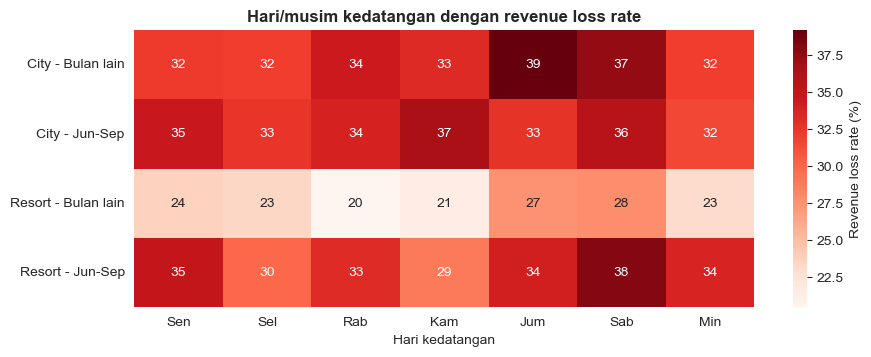

In [228]:
hari_musim = loss_rate_pivot(df, 'hotel_periode', 'arrival_weekday')
hari_musim = hari_musim[urutan_hari]
hari_musim.columns = label_hari
print('Revenue loss rate (%):')
print(hari_musim.round(1), '\n')
cancel_musim = df.pivot_table(index='hotel_periode', columns='arrival_weekday', values='is_canceled', aggfunc='mean')[urutan_hari] * 100
cancel_musim.columns = label_hari
print('Cancel rate (%):')
print(cancel_musim.round(1), '\n')

print('Median ADR per hari kedatangan (€):')
adr_hari = df.pivot_table(index='hotel', columns='arrival_weekday', values='adr', aggfunc='median')[urutan_hari]
adr_hari.columns = label_hari
print(adr_hari.round(1))

plt.figure(figsize=(10, 3.6))
sns.heatmap(hari_musim, annot=True, fmt='.0f', cmap='Reds', cbar_kws={'label': 'Revenue loss rate (%)'})
plt.title('Hari/musim kedatangan dengan revenue loss rate')
plt.xlabel('Hari kedatangan'); plt.ylabel('')
plt.show()

- **City:** di bulan lain, kedatangan Jumat-Sabtu kehilangan nilai paling besar (37,4-39,2%), hari lain 32,0-34,4%. Di Juni-September selisih antarhari lebih kecil (31,5-36,5%), dengan Kamis tertinggi.
- **Resort di bulan lain:** kedatangan Rabu-Kamis hanya kehilangan 20,4-21,4% nilai, sedangkan Jumat-Sabtu 27,5-27,7%. Di Juni-September semua hari naik ke 28,9-38,1%, dengan Sabtu tertinggi (38,1%).
- Kedatangan Jumat-Minggu di Resort juga yang termahal (median ADR €83,2-86,4 vs €71,1-74,0 di Selasa-Kamis). Kamar akhir pekan Resort adalah kamar yang paling mahal sekaligus paling banyak kehilangan nilai.

### **H. Korelasi antarkolom numerik**
Sebagai pengecekan: apakah ada satu kolom numerik yang dominan, atau pembatalan memang dijelaskan oleh kombinasi faktor seperti yang terlihat di 4.C?

Korelasi Pearson hanya mengukur hubungan linear. Untuk kolom biner atau diskrit, hasilnya hanya dibaca sebagai arah dan kekuatan kasar.

In [229]:
kolom_num = ['is_canceled', 'lead_time', 'adr', 'total_nights', 'total_guests', 'booking_changes',
             'total_of_special_requests', 'required_car_parking_spaces', 'previous_cancellations',
             'previous_bookings_not_canceled', 'is_repeated_guest', 'days_in_waiting_list']
korelasi = df[kolom_num].corr()

Visualisasikan datanya

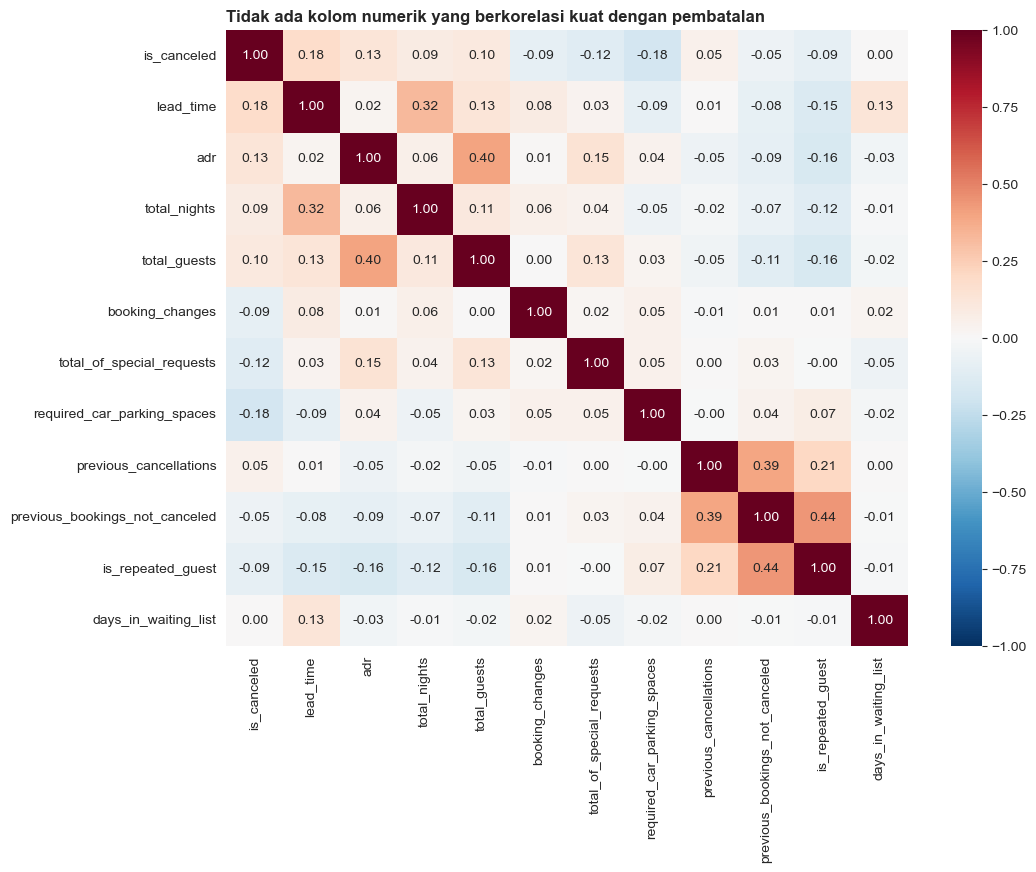

required_car_parking_spaces      -0.184
total_of_special_requests        -0.121
booking_changes                  -0.093
is_repeated_guest                -0.089
previous_bookings_not_canceled   -0.052
days_in_waiting_list              0.005
previous_cancellations            0.052
total_nights                      0.085
total_guests                      0.099
adr                               0.133
lead_time                         0.185
is_canceled                       1.000
Name: is_canceled, dtype: float64


In [230]:
plt.figure(figsize=(11, 8))
sns.heatmap(korelasi, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1)
plt.title('Tidak ada kolom numerik yang berkorelasi kuat dengan pembatalan', loc='left')
plt.show()

print(korelasi['is_canceled'].sort_values().round(3))

- Korelasi terkuat dengan is_canceled hanya **lead_time (+0,19)** dan **parkir (−0,18)**, dan 4.D sudah menunjukkan kolom parkir tidak bisa dipakai. Special request (−0,12) dan ADR (+0,13) lemah.
- Tidak ada satu kolom numerik yang dominan. Karena itu analisis 2 dimensi di 4.C, dekomposisi di 4.E, dan segmen risiko di 4.F memakai kombinasi ciri, bukan korelasi satu per satu.

**Cek silang: korelasi versi one-hot.** Kolom kategori tidak bisa masuk korelasi Pearson secara langsung. Sebagai pembanding, tiap kategori diubah menjadi kolom 0/1 (one-hot), lalu dikorelasikan dengan is_canceled.

- Korelasi Pearson hanya bisa dihitung untuk angka, jadi tiap kategori diubah dulu menjadi kolom 0/1.
- get_dummies tidak dipraktikkan di modul; dipakai di sini hanya sebagai cek silang heatmap 4.H.

In [231]:
kolom_kat = ['hotel', 'market_segment', 'distribution_channel', 'deposit_type', 'customer_type', 'meal',
             'lead_bin', 'room_changed', 'parking_grp', 'asal', 'agent']
dummy = pd.get_dummies(df[kolom_kat].astype(str), dtype=int)
print('Jumlah kolom 0/1:', dummy.shape[1])

Jumlah kolom 0/1: 372


Korelasi tiap kolom 0/1 dengan is_canceled

In [232]:
korelasi_dummy = pd.Series(dtype=float)
for kolom in dummy.columns:
    korelasi_dummy[kolom] = dummy[kolom].corr(df['is_canceled'])

Korelasi terkuat: di atas 0,15 atau di bawah -0,15

In [233]:
kuat = korelasi_dummy[(korelasi_dummy > 0.15) | (korelasi_dummy < -0.15)]
print(kuat.sort_values().round(3))

lead_bin_0-7                 -0.220
room_changed_Ya              -0.213
parking_grp_Minta parkir     -0.186
deposit_type_No Deposit      -0.156
distribution_channel_TA/TO    0.152
deposit_type_Non Refund       0.165
parking_grp_Tidak             0.186
agent_9                       0.198
market_segment_Online TA      0.212
room_changed_Tidak            0.213
dtype: float64


- Dari 372 kolom 0/1, korelasi terkuat hanya sekitar ±0,2: lead time 0-7 hari (−0,22), Online TA (+0,21), dan agent 9 (+0,20). Ketiganya sama dengan temuan 4.C dan 4.F.1.
- Kolom room_changed, parkir, dan asal (Portugal) juga muncul di daftar teratas, tetapi 4.D sudah menunjukkan ketiganya tidak boleh dibaca sebagai penyebab.
- Korelasi pada kolom 0/1 kecil karena hanya mengukur satu kategori melawan sisanya. Selisih antarkategori lebih mudah dibaca: Non Refund 94,7% vs No Deposit 26,7% hanya menghasilkan korelasi sekitar 0,17, karena Non Refund hanya 1,2% booking. Korelasi ini memakai is_canceled; dalam revenue loss rate, Non Refund justru 0% karena tetap membayar.

### **I. Cek konteks sebelum menyusun rekomendasi** (pertanyaan G)
Sampai 4.H, analisis sudah menjawab besar, penyebab, lokasi, dan waktu kerugian. Sebelum rekomendasi disusun untuk Revenue Manager, ada lima hal yang perlu dicek supaya kebijakan tidak salah sasaran:
1. Siapa yang akan terkena kebijakan deposit?
2. Segmen mana yang harus dijaga di tiap hotel?
3. Kapan tamu membatalkan setelah booking dibuat?
4. Kapan hotel penuh, kapan kosong, dan berapa kamar batal yang masih bisa dijual ulang?
5. Bagaimana harga saat ini terbentuk, dan pasar mana yang sedang tumbuh?

#### **1. Siapa yang akan terkena kebijakan deposit?**
Rekomendasi deposit akan menyasar segmen risiko tinggi dari 4.F. Sebelum itu, bandingkan nilai booking mereka dengan booking lainnya

In [234]:
df['keluarga'] = np.where((df['children'] + df['babies']) > 0, 1, 0)

profil_risiko = df.groupby('segmen_risiko')['adr'].agg(['count', 'mean'])
profil_risiko.columns = ['jumlah_booking', 'adr_rata2']
profil_risiko['malam_rata2'] = df.groupby('segmen_risiko')['total_nights'].mean()
profil_risiko['revenue_per_booking'] = df.groupby('segmen_risiko')['revenue'].mean()
profil_risiko['%_keluarga'] = df.groupby('segmen_risiko')['keluarga'].mean() * 100
profil_risiko.round(1)

,jumlah_booking,adr_rata2,malam_rata2,revenue_per_booking,%_keluarga
segmen_risiko,,,,,
Lainnya,69124,102.8,3.4,356.7,9.3
Risiko tinggi,18104,120.3,4.5,540.9,14.6


- Segmen risiko tinggi berisi booking yang lebih bernilai: ADR €120,3 vs €102,8, menginap 4,5 vs 3,4 malam, dan nilai booking €540,9 vs €356,7. Porsi keluarganya juga lebih tinggi (14,6% vs 9,3%)
- Kebijakan deposit karena itu akan mengenai booking yang bernilai tinggi. Bentuk depositnya dibahas di rekomendasi 1

#### **2. Segmen mana yang harus dijaga di tiap hotel?**
4.G melihat nilai segmen untuk kedua hotel sekaligus. Kebijakan ditetapkan per hotel, jadi peta nilai vs risiko dipisah per hotel. Segmen Complementary (kamar gratis) dan segmen dengan kurang dari 300 booking tidak ditampilkan

In [235]:
peta = df.groupby(['hotel', 'market_segment'])['is_canceled'].agg(['count', 'mean']).reset_index()
peta.columns = ['hotel', 'market_segment', 'jumlah_booking', 'cancel_rate']
peta['cancel_rate'] = peta['cancel_rate'] * 100
rugi_peta = df.groupby(['hotel', 'market_segment'])[['revenue_hilang', 'revenue']].sum().reset_index()
rugi_peta['revenue_loss_rate'] = rugi_peta['revenue_hilang'] / rugi_peta['revenue'] * 100
peta = peta.merge(rugi_peta[['hotel', 'market_segment', 'revenue_loss_rate']], on=['hotel', 'market_segment'], how='left')

revenue_masuk = df[df['is_canceled'] == 0].groupby(['hotel', 'market_segment'])['revenue'].sum().reset_index()
revenue_masuk.columns = ['hotel', 'market_segment', 'revenue_masuk']
peta = peta.merge(revenue_masuk, on=['hotel', 'market_segment'], how='left')
peta['revenue_per_booking'] = peta['revenue_masuk'] / peta['jumlah_booking']

peta = peta[(peta['jumlah_booking'] >= 300) & (peta['market_segment'] != 'Complementary')]
print(peta.round(1))

           hotel market_segment  jumlah_booking  cancel_rate  \
2     City Hotel      Corporate            2218         11.9   
3     City Hotel         Direct            5538         16.5   
4     City Hotel         Groups            2619         33.9   
5     City Hotel  Offline TA/TO            7238         17.4   
6     City Hotel      Online TA           34929         36.1   
9   Resort Hotel      Corporate            1982         12.4   
10  Resort Hotel         Direct            6242         13.2   
11  Resort Hotel         Groups            2302         19.3   
12  Resort Hotel  Offline TA/TO            6616         12.1   
13  Resort Hotel      Online TA           16624         33.8   

    revenue_loss_rate  revenue_masuk  revenue_per_booking  
2                11.9       307065.9                138.4  
3                21.4      1538751.9                277.9  
4                13.2       413406.2                157.8  
5                13.8      1673811.2                231

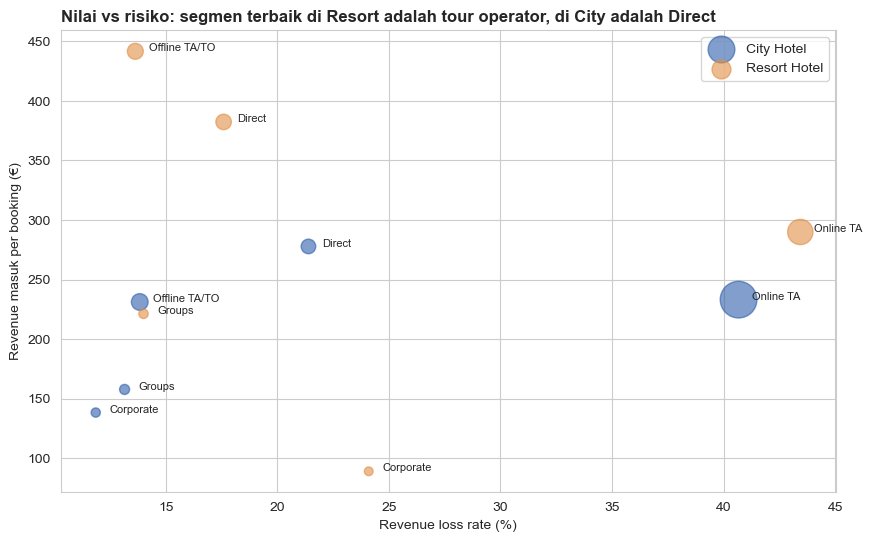

In [236]:
plt.figure(figsize=(10, 6))
for hotel in ['City Hotel', 'Resort Hotel']:
    data_hotel = peta[peta['hotel'] == hotel]
    plt.scatter(data_hotel['revenue_loss_rate'], data_hotel['revenue_per_booking'],
                s=data_hotel['jumlah_booking'] / 50, color=WARNA_HOTEL[hotel], alpha=0.6, label=hotel)
    for i in data_hotel.index:
        plt.text(data_hotel.loc[i, 'revenue_loss_rate'] + 0.6, data_hotel.loc[i, 'revenue_per_booking'],
                 data_hotel.loc[i, 'market_segment'], fontsize=8)
plt.title('Nilai vs risiko: segmen terbaik di Resort adalah tour operator, di City adalah Direct', loc='left')
plt.xlabel('Revenue loss rate (%)'); plt.ylabel('Revenue masuk per booking (€)')
plt.legend()
plt.show()

Cara membaca: kanan atas berarti banyak kehilangan nilai tetapi bernilai, kiri atas berarti bernilai dan sedikit kehilangan nilai
- **Resort:** Offline TA/TO (tour operator) paling bernilai: €441,6 per booking dengan revenue loss rate 13,6%. Direct menyusul (€382,3, 17,6%). Online TA €290,0 dengan revenue loss rate 43,4%
- **City:** Direct paling bernilai (€277,9, 21,4%). Online TA €233,2 dengan revenue loss rate 40,7%. Groups paling rendah per booking (€157,8), tetapi nilai yang hilang kecil (13,2%), padahal cancel rate-nya 33,9%
- Segmen paling bernilai dengan kehilangan rendah berbeda per hotel: Offline TA/TO di Resort dan Direct di City. Keduanya berada di luar segmen risiko tinggi (dipakai di rekomendasi 1 dan 6)

#### **3. Kapan tamu membatalkan setelah booking dibuat?**
4.B.2 menghitung jarak pembatalan ke tanggal kedatangan. Sisi sebaliknya: berapa lama setelah booking dibuat tamu membatalkan? Ini penting untuk menentukan kapan deposit ditarik

In [237]:
cxl['hari_setelah_booking'] = cxl['lead_time'] - cxl['days_before_arrival']

print(f"Batal di hari booking dibuat : {(cxl['hari_setelah_booking'] == 0).mean():.1%}")
print(f"Batal <= 1 hari setelahnya   : {(cxl['hari_setelah_booking'] <= 1).mean():.1%}")
print(f"Batal <= 7 hari setelahnya   : {(cxl['hari_setelah_booking'] <= 7).mean():.1%}")

cepat = cxl[cxl['hari_setelah_booking'] <= 7]
print('Median jarak ke kedatangan untuk pembatalan cepat:', cepat['days_before_arrival'].median(), 'hari')
print(f"Porsi nilai booking dari pembatalan cepat        : {cepat['revenue_hilang'].sum() / cxl['revenue_hilang'].sum():.1%}")
print()
print('% pembatalan <= 1 hari setelah booking, per segmen:')
print(cxl.groupby('market_segment')['hari_setelah_booking'].apply(lambda x: (x <= 1).mean() * 100).round(1))

Batal di hari booking dibuat : 13.7%
Batal <= 1 hari setelahnya   : 21.8%
Batal <= 7 hari setelahnya   : 41.7%
Median jarak ke kedatangan untuk pembatalan cepat: 43.0 hari
Porsi nilai booking dari pembatalan cepat        : 42.5%

% pembatalan <= 1 hari setelah booking, per segmen:
market_segment
Aviation          76.5
Complementary     47.3
Corporate         26.4
Direct            26.2
Groups            13.9
Offline TA/TO     20.7
Online TA         21.7
Undefined        100.0
Name: hari_setelah_booking, dtype: float64


- **13,7% pembatalan terjadi di hari yang sama dengan booking dibuat**, 21,8% dalam 1 hari, dan 41,7% dalam 7 hari. Pembatalan dalam 7 hari ini membawa 42,5% revenue hilang dari pembatalan
- Pembatalan cepat ini masih jauh dari kedatangan (median 43 hari sebelumnya), jadi masih ada waktu untuk menjual ulang kamarnya
- Waktu penarikan deposit yang menghindari pembatalan cepat ini dibahas di rekomendasi 1

Per bulan memakai 2016 saja (satu-satunya tahun lengkap), karena 2017 berhenti di Agustus

In [238]:
cxl['bulan_batal'] = cxl['reservation_status_date'].dt.month
cxl['hari_batal'] = cxl['reservation_status_date'].dt.day_name()
batal_2016 = cxl[cxl['reservation_status_date'].dt.year == 2016]

per_bulan = batal_2016.groupby('bulan_batal').size()
per_bulan.index = label_bulan
print('% pembatalan per bulan terjadinya (2016):')
print((per_bulan / per_bulan.sum() * 100).round(1), '\n')

per_hari = cxl.groupby('hari_batal').size().loc[urutan_hari]
print('% pembatalan per hari terjadinya (semua tahun):')
print((per_hari / per_hari.sum() * 100).round(1), '\n')

# jumlah pembatalan per tanggal; tanggal tanpa pembatalan ikut dihitung sebagai 0
batal_harian = batal_2016.groupby('reservation_status_date')['is_canceled'].count().reset_index()
batal_harian.columns = ['tanggal', 'jumlah_batal']
semua_hari = pd.DataFrame()
semua_hari['tanggal'] = pd.date_range('2016-01-01', '2016-12-31')
semua_hari = semua_hari.merge(batal_harian, on='tanggal', how='left')
semua_hari['jumlah_batal'] = semua_hari['jumlah_batal'].fillna(0)
print(f"Pembatalan per hari (2016): median {semua_hari['jumlah_batal'].median():.0f}, "
      f"90% hari di bawah {semua_hari['jumlah_batal'].quantile(0.9):.0f}, maksimum {semua_hari['jumlah_batal'].max():.0f}")

% pembatalan per bulan terjadinya (2016):
Jan     7.4
Feb     8.6
Mar    10.2
Apr     8.8
Mei     7.8
Jun     7.7
Jul     8.2
Agu     8.2
Sep     8.5
Okt     8.6
Nov     7.9
Des     8.1
dtype: float64 

% pembatalan per hari terjadinya (semua tahun):
hari_batal
Monday       18.2
Tuesday      17.1
Wednesday    16.0
Thursday     15.3
Friday       14.6
Saturday      9.6
Sunday        9.2
dtype: float64 

Pembatalan per hari (2016): median 32, 90% hari di bawah 48, maksimum 73


- Sepanjang 2016 pembatalan masuk cukup merata: 7,4-10,2% per bulan, sedikit lebih tinggi di Maret
- Pembatalan terjadi di hari kerja: Senin 18,2%, turun bertahap sampai Jumat 14,6%, dan hanya sekitar 9% di Sabtu dan Minggu
- Median 32 pembatalan masuk per hari, dan 90% hari di bawah 48. Bebannya stabil sepanjang tahun (dipakai di rekomendasi 2)

#### **4. Kapan hotel penuh, dan kapan kosong?**
Supaya buffer overbooking (4.E.4) bisa dinyatakan dalam kamar, bukan persen, kapasitas hotel diperkirakan dari kamar terisi pada malam paling penuh. Kapasitas asli tidak ada di data dan bisa lebih besar, jadi kamar kosong di bawah adalah perkiraan

In [239]:
def bentangkan(data):
    # satu baris per malam menginap: booking 3 malam menjadi 3 baris (malam ke-0, ke-1, ke-2)
    data = data[data['total_nights'] > 0]
    daftar = []
    for i in range(data['total_nights'].max()):
        malam_ke_i = data[data['total_nights'] > i][['hotel', 'arrival_date', 'adr']].copy()
        malam_ke_i['tanggal_inap'] = malam_ke_i['arrival_date'] + pd.to_timedelta(i, unit='D')
        daftar.append(malam_ke_i)
    hasil = pd.concat(daftar)
    # hanya malam yang masih di dalam periode data
    hasil = hasil[(hasil['tanggal_inap'] >= '2015-07-01') & (hasil['tanggal_inap'] <= '2017-08-31')]
    return hasil


malam_terisi = bentangkan(df[df['is_canceled'] == 0])
okupansi = malam_terisi.groupby(['hotel', 'tanggal_inap']).size().reset_index()
okupansi.columns = ['hotel', 'tanggal_inap', 'kamar_terisi']

# kapasitas tidak ada di dataset: dipakai jumlah kamar terisi pada malam paling penuh (proksi)
kapasitas = okupansi.groupby('hotel')['kamar_terisi'].max()
okupansi['kapasitas'] = okupansi['hotel'].map(kapasitas)
okupansi['kamar_kosong'] = okupansi['kapasitas'] - okupansi['kamar_terisi']
okupansi['okupansi_%'] = okupansi['kamar_terisi'] / okupansi['kapasitas'] * 100
okupansi['bulan'] = okupansi['tanggal_inap'].dt.month

# Estimated max rooms per hotel: kamar terisi pada malam paling penuh, beserta tanggalnya
# (hanya booking yang menginap; booking batal tidak menempati kamar)
puncak_kapasitas = okupansi[okupansi['kamar_terisi'] == okupansi['kapasitas']][['hotel', 'tanggal_inap', 'kamar_terisi']].copy()
puncak_kapasitas['hari'] = puncak_kapasitas['tanggal_inap'].dt.day_name()
puncak_kapasitas.columns = ['hotel', 'tanggal_puncak', 'estimated_max_rooms', 'hari']
print('Estimated max rooms (proksi kapasitas) dan tanggal puncaknya:')
print(puncak_kapasitas.to_string(index=False), '\n')
ringkas_okupansi = okupansi.groupby('hotel')[['kamar_terisi', 'kamar_kosong', 'okupansi_%']].mean()
ringkas_okupansi['% malam okupansi >= 95%'] = okupansi.groupby('hotel')['okupansi_%'].apply(lambda x: (x >= 95).mean() * 100)
print(ringkas_okupansi.round(1), '\n')

okupansi_bulan = okupansi.pivot_table(index='bulan', columns='hotel', values='okupansi_%', aggfunc='mean')
print(okupansi_bulan.round(1))

Estimated max rooms (proksi kapasitas) dan tanggal puncaknya:
       hotel tanggal_puncak  estimated_max_rooms     hari
  City Hotel     2016-08-13                  216 Saturday
  City Hotel     2017-08-21                  216   Monday
  City Hotel     2017-08-22                  216  Tuesday
Resort Hotel     2017-08-18                  184   Friday
Resort Hotel     2017-08-19                  184 Saturday 

              kamar_terisi  kamar_kosong  okupansi_%  % malam okupansi >= 95%
hotel                                                                        
City Hotel           139.9          76.1        64.8                      4.2
Resort Hotel         137.0          47.0        74.4                     15.3 

hotel  City Hotel  Resort Hotel
bulan                          
1            43.4          40.9
2            60.1          58.1
3            78.1          68.5
4            79.2          73.8
5            77.2          84.4
6            76.1          91.6
7            60.2 

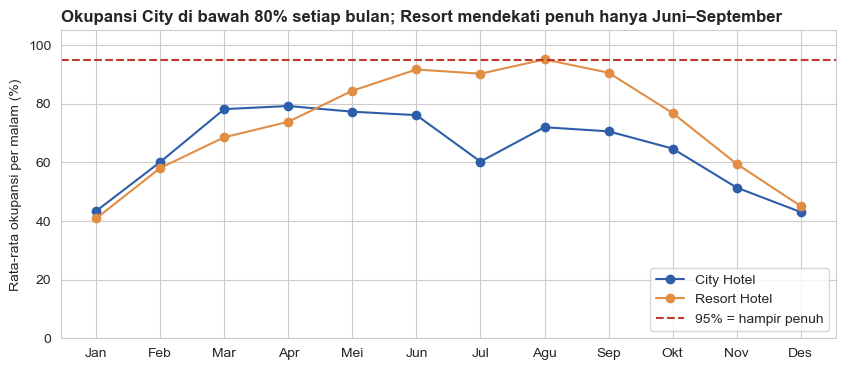

In [240]:
for hotel in ['City Hotel', 'Resort Hotel']:
    plt.plot(okupansi_bulan.index, okupansi_bulan[hotel], marker='o', color=WARNA_HOTEL[hotel], label=hotel)
plt.axhline(95, color=SOROT, linestyle='--', label='95% = hampir penuh')
plt.title('Okupansi City di bawah 80% setiap bulan; Resort mendekati penuh hanya Juni–September', loc='left')
plt.xticks(range(1, 13), label_bulan)
plt.ylabel('Rata-rata okupansi per malam (%)'); plt.ylim(0, 105)
plt.legend(loc='lower right')
plt.show()

**City rata-rata terisi 64,8%, Resort 74,4%. Hanya Resort yang sering penuh di musim panas.**

- City: perkiraan kapasitas 216 kamar, rata-rata 76 kamar kosong per malam
- Resort: perkiraan kapasitas 184 kamar, rata-rata 47 kamar kosong per malam. Kapasitas kedua hotel tercapai di Agustus
- Malam terisi 95% atau lebih: 4,2% di City dan 15,3% di Resort. Okupansi bulanan City tidak pernah melewati 80%, Resort di atas 90% hanya Juni-September. Januari paling sepi (City 43,4%, Resort 40,9%)

In [241]:
jendela = df.pivot_table(index='hotel', columns='arrival_month', values='lead_time', aggfunc='median')
jendela.columns = label_bulan
jendela

,Jan,Feb,Mar,Apr,Mei,Jun,Jul,Agu,Sep,Okt,Nov,Des
hotel,,,,,,,,,,,,
City Hotel,19.0,20.0,42.0,68.0,69.0,65.0,111.0,96.0,35.0,40.0,39.0,35.0
Resort Hotel,5.0,11.0,23.0,44.0,88.0,127.0,91.0,80.0,114.0,43.0,19.0,24.0


- Kedatangan musim panas dipesan jauh hari (median City Juli 111 hari, Resort Juni 127 hari), sedangkan musim dingin mepet (Resort Januari 5 hari, City Januari 19 hari)

Kamar kosong dihitung per malam, termasuk booking yang batal atau no-show di 7 hari terakhir (`batal_h7`). Overbooking hanya berguna di malam yang akan penuh.

In [242]:
# kamar per malam yang kosong karena batal atau no-show di 7 hari terakhir (booking batal_h7 dari 4.E.4)
hilang_h7 = bentangkan(batal_h7)
hilang_h7_harian = hilang_h7.groupby(['hotel', 'tanggal_inap'])['adr'].agg(['count', 'sum']).reset_index()
hilang_h7_harian.columns = ['hotel', 'tanggal_inap', 'kamar_hilang', 'nilai_hilang']

semua_malam = okupansi.merge(hilang_h7_harian, on=['hotel', 'tanggal_inap'], how='left')
semua_malam['kamar_hilang'] = semua_malam['kamar_hilang'].fillna(0)
semua_malam['nilai_hilang'] = semua_malam['nilai_hilang'].fillna(0)
semua_malam['penuh'] = np.where(semua_malam['okupansi_%'] >= 95, 1, 0)      # 1 = okupansi 95% atau lebih

print('Rata-rata kamar hilang per malam (semua malam):')
print(semua_malam.groupby('hotel')['kamar_hilang'].mean().round(1), '\n')

malam_penuh = semua_malam.pivot_table(index='hotel', columns='bulan', values='penuh', aggfunc='mean') * 100
malam_penuh.columns = label_bulan
print('% malam yang hampir penuh (okupansi >= 95%)')
print(malam_penuh.round(0), '\n')

print('Jumlah malam (0 = masih ada kamar kosong, 1 = hampir penuh):')
print(semua_malam.pivot_table(index='hotel', columns='penuh', values='kamar_hilang', aggfunc='count'), '\n')
print('Rata-rata kamar hilang per malam:')
print(semua_malam.pivot_table(index='hotel', columns='penuh', values='kamar_hilang', aggfunc='mean').round(1), '\n')
print('Total nilai kamar hilang (€, 26 bulan):')
print(semua_malam.pivot_table(index='hotel', columns='penuh', values='nilai_hilang', aggfunc='sum').round(0), '\n')

buffer_kamar = semua_malam.pivot_table(index='hotel', columns='bulan', values='kamar_hilang', aggfunc='mean')
buffer_kamar.columns = label_bulan
print('Rata-rata kamar hilang per malam, per bulan:')
print(buffer_kamar.round(1))

Rata-rata kamar hilang per malam (semua malam):


hotel
City Hotel      14.3
Resort Hotel     5.1
Name: kamar_hilang, dtype: float64 

% malam yang hampir penuh (okupansi >= 95%)
              Jan  Feb  Mar  Apr  Mei   Jun   Jul   Agu   Sep  Okt  Nov  Des
hotel                                                                       
City Hotel    0.0  0.0  2.0  2.0  0.0   3.0  11.0  19.0   2.0  0.0  0.0  0.0
Resort Hotel  0.0  0.0  0.0  0.0  8.0  22.0  30.0  65.0  25.0  0.0  0.0  0.0 

Jumlah malam (0 = masih ada kamar kosong, 1 = hampir penuh):
penuh           0    1
hotel                 
City Hotel    760   33
Resort Hotel  672  121 

Rata-rata kamar hilang per malam:
penuh            0     1
hotel                   
City Hotel    14.4  10.4
Resort Hotel   5.2   4.7 

Total nilai kamar hilang (€, 26 bulan):
penuh                 0        1
hotel                           
City Hotel    1213636.0  43990.0
Resort Hotel   292458.0  95350.0 

Rata-rata kamar hilang per malam, per bulan:
               Jan   Feb   Mar   Apr   Mei   Jun  J

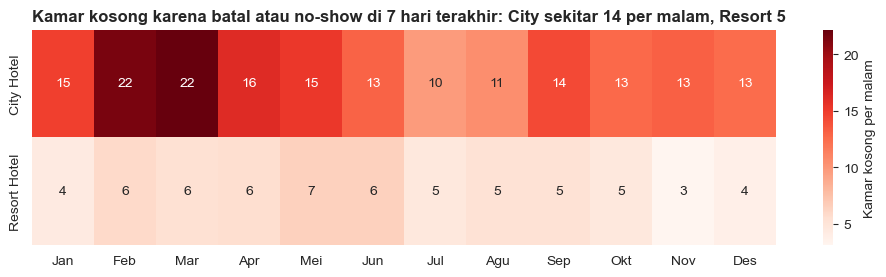

In [243]:
plt.figure(figsize=(12, 2.8))
sns.heatmap(buffer_kamar, annot=True, fmt='.0f', cmap='Reds', cbar_kws={'label': 'Kamar kosong per malam'})
plt.title('Kamar kosong karena batal atau no-show di 7 hari terakhir: City sekitar 14 per malam, Resort 5', loc='left')
plt.xlabel(''); plt.ylabel('')
plt.show()

**Overbooking hanya berguna di musim ramai. Di luar itu hotel masih punya kamar kosong**

- Kamar kosong karena batal atau no-show di 7 hari terakhir: rata-rata 14,3 per malam di City dan 5,1 di Resort
- Malam hampir penuh hanya di Resort Mei-September (Agustus 65% malam) dan City Juli-Agustus (11-19%). Januari-Februari dan Oktober-Desember tidak ada malam penuh
- Pada malam penuh, kamar yang hilang rata-rata 10 di City (33 malam) dan 5 di Resort (121 malam), senilai €0,14 juta. Sisanya €1,51 juta jatuh pada malam yang masih punya kamar kosong
- Kehilangan H-7 tertinggi di awal tahun, saat hotel hampir tidak pernah penuh (rekomendasi 2 dan 4)

88,7% revenue hilang dilepas lebih dari 7 hari sebelum kedatangan. Kamar itu baru jadi kerugian kalau malamnya tetap kosong, jadi yang dihitung hanya kamar yang malamnya masih kosong, dinilai dengan harga booking yang batal.

In [244]:
# kamar dari booking yang batal lebih dari 7 hari sebelum kedatangan (masih ada waktu untuk dijual lagi)
dilepas = bentangkan(df[(df['reservation_status'] == 'Canceled') & (df['days_before_arrival'] > 7)])
dilepas_harian = dilepas.groupby(['hotel', 'tanggal_inap'])['adr'].agg(['count', 'mean']).reset_index()
dilepas_harian.columns = ['hotel', 'tanggal_inap', 'kamar_dilepas', 'adr_dilepas']

celah = okupansi.merge(dilepas_harian, on=['hotel', 'tanggal_inap'], how='left')
celah['kamar_dilepas'] = celah['kamar_dilepas'].fillna(0)
celah['adr_dilepas'] = celah['adr_dilepas'].fillna(0)

# yang bisa dijual ulang = kamar yang dilepas, tetapi tidak lebih dari kamar yang masih kosong malam itu
celah['bisa_dijual_ulang'] = np.where(celah['kamar_dilepas'] < celah['kamar_kosong'],
                                      celah['kamar_dilepas'], celah['kamar_kosong'])
celah['nilai_peluang'] = celah['bisa_dijual_ulang'] * celah['adr_dilepas']

ringkas_celah = celah.groupby('hotel')[['kamar_dilepas', 'bisa_dijual_ulang', 'nilai_peluang']].sum()
ringkas_celah.loc['Total'] = ringkas_celah.sum()
ringkas_celah['% bisa dijual ulang'] = ringkas_celah['bisa_dijual_ulang'] / ringkas_celah['kamar_dilepas'] * 100
print(ringkas_celah.round(1), '\n')

# rata-rata per bulan kalender (Juli-Agustus punya 3 tahun data)
celah_bulan = celah.pivot_table(index='bulan', columns='hotel', values='bisa_dijual_ulang', aggfunc='sum')
for hotel in ['City Hotel', 'Resort Hotel']:
    celah_bulan[hotel] = celah_bulan[hotel] / jumlah_tahun
print(celah_bulan.round(0))

              kamar_dilepas  bisa_dijual_ulang  nilai_peluang  \
hotel                                                           
City Hotel          44762.0            25126.0      2812535.3   
Resort Hotel        35768.0            15409.0      1314718.9   
Total               80530.0            40535.0      4127254.2   

              % bisa dijual ulang  
hotel                              
City Hotel                   56.1  
Resort Hotel                 43.1  
Total                        50.3   

hotel  City Hotel  Resort Hotel
bulan                          
1          1114.0         500.0
2          1062.0         648.0
3          1205.0         876.0
4          1257.0         931.0
5          1220.0         834.0
6          1080.0         462.0
7           758.0         416.0
8           590.0         282.0
9           868.0         520.0
10          909.0         723.0
11          734.0         540.0
12         1090.0         626.0


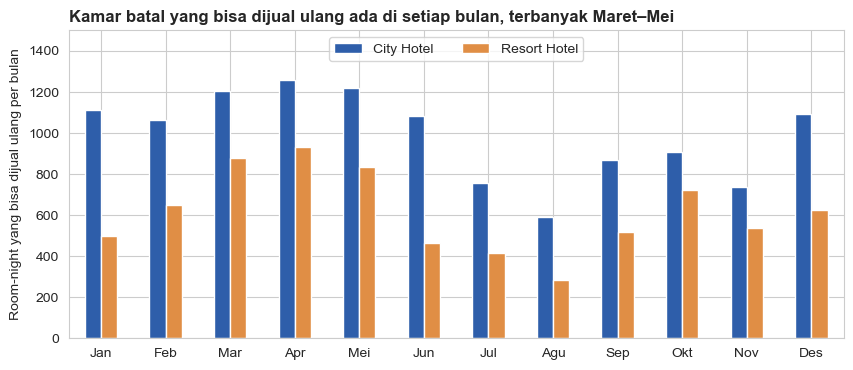

In [245]:
celah_bulan.plot.bar(color=[WARNA_HOTEL['City Hotel'], WARNA_HOTEL['Resort Hotel']])
plt.title('Kamar batal yang bisa dijual ulang ada di setiap bulan, terbanyak Maret–Mei', loc='left')
plt.xticks(range(12), label_bulan, rotation=0)
plt.xlabel(''); plt.ylabel('Room-night yang bisa dijual ulang per bulan')
plt.ylim(0, 1500)
plt.legend(loc='upper center', ncol=2)
plt.show()

**Separuh kamar yang dilepas jauh hari jatuh pada malam yang masih kosong, senilai €4,13 juta.**

- Dari 80.530 room-night yang dilepas, 40.535 (50,3%) jatuh pada malam yang masih kosong: €4,13 juta (City €2,81 juta, Resort €1,31 juta)
- Terbanyak di Maret-Mei, tersedikit di Juli-Agustus (rekomendasi 2)
- Laku atau tidaknya kalau dijual ulang tidak terlihat di data, jadi simulasi memakai porsi 10-50%

RevPAR = pendapatan kamar per kamar tersedia per malam (ADR × okupansi). Angkanya batas atas karena kapasitas diperkirakan. RevPAR gap = tambahan RevPAR kalau kamar batal di malam yang masih kosong terjual lagi.

In [246]:
judul_revpar = 'RevPAR 2016: Resort €18–174 per kamar, City €26–111; celah jual ulang City terbesar di luar Juli–Agustus'

# RevPAR (Revenue per Available Room) = revenue kamar ÷ kamar tersedia = ADR × okupansi
# kamar tersedia = estimated max rooms × jumlah malam. Kapasitas ini proksi yang tidak lebih besar dari kapasitas asli,
# jadi okupansi dan RevPAR di sini adalah batas atas.
revpar = pd.DataFrame()
revpar['kapasitas'] = kapasitas
revpar['jumlah_malam'] = okupansi.groupby('hotel')['tanggal_inap'].count()
revpar['kamar_tersedia'] = revpar['kapasitas'] * revpar['jumlah_malam']
revpar['kamar_terisi'] = okupansi.groupby('hotel')['kamar_terisi'].sum()
revpar['revenue_kamar'] = malam_terisi.groupby('hotel')['adr'].sum()
revpar['okupansi_%'] = revpar['kamar_terisi'] / revpar['kamar_tersedia'] * 100
revpar['adr'] = revpar['revenue_kamar'] / revpar['kamar_terisi']
revpar['revpar'] = revpar['revenue_kamar'] / revpar['kamar_tersedia']

# RevPAR gap: kamar batal yang jatuh di malam yang masih punya kamar kosong (tabel celah di atas,
# sudah dibatasi jumlah kamar kosong tiap malam)
revpar['revpar_gap'] = celah.groupby('hotel')['nilai_peluang'].sum() / revpar['kamar_tersedia']
revpar['revpar_bila_10%_terjual'] = revpar['revpar'] + revpar['revpar_gap'] * 0.10
print(revpar.round(1), '\n')

# Kenapa gap dibatasi kamar kosong: kalau semua booking (termasuk yang batal) dianggap menginap,
# jumlahnya melebihi kapasitas di banyak malam, karena hotel menerima booking lebih banyak dari jumlah kamar
semua_booking = bentangkan(df).groupby(['hotel', 'tanggal_inap']).size().reset_index()
semua_booking.columns = ['hotel', 'tanggal_inap', 'booking_malam_itu']
semua_booking['kapasitas'] = semua_booking['hotel'].map(kapasitas)
semua_booking['lebih_dari_kapasitas'] = semua_booking['booking_malam_itu'] > semua_booking['kapasitas']
print('% malam yang booking-nya (termasuk yang batal) melebihi kapasitas:')
print((semua_booking.groupby('hotel')['lebih_dari_kapasitas'].mean() * 100).round(1), '\n')

# RevPAR per bulan menginap, per tahun (tidak dirata-rata per bulan kalender)
kamar_bulan = okupansi.copy()
kamar_bulan['periode'] = kamar_bulan['tanggal_inap'].dt.to_period('M').astype(str)
revpar_bulanan = kamar_bulan.groupby(['hotel', 'periode'])[['kamar_terisi', 'kapasitas']].sum().reset_index()
revpar_bulanan.columns = ['hotel', 'periode', 'kamar_terisi', 'kamar_tersedia']

pendapatan_bulan = malam_terisi.copy()
pendapatan_bulan['periode'] = pendapatan_bulan['tanggal_inap'].dt.to_period('M').astype(str)
pendapatan_bulan = pendapatan_bulan.groupby(['hotel', 'periode'])['adr'].sum().reset_index()
pendapatan_bulan.columns = ['hotel', 'periode', 'revenue_kamar']
revpar_bulanan = revpar_bulanan.merge(pendapatan_bulan, on=['hotel', 'periode'], how='left')

jual_ulang_bulan = celah.copy()
jual_ulang_bulan['periode'] = jual_ulang_bulan['tanggal_inap'].dt.to_period('M').astype(str)
jual_ulang_bulan = jual_ulang_bulan.groupby(['hotel', 'periode'])['nilai_peluang'].sum().reset_index()
jual_ulang_bulan.columns = ['hotel', 'periode', 'nilai_jual_ulang']
revpar_bulanan = revpar_bulanan.merge(jual_ulang_bulan, on=['hotel', 'periode'], how='left')

revpar_bulanan['okupansi_%'] = revpar_bulanan['kamar_terisi'] / revpar_bulanan['kamar_tersedia'] * 100
revpar_bulanan['adr'] = revpar_bulanan['revenue_kamar'] / revpar_bulanan['kamar_terisi']
revpar_bulanan['revpar'] = revpar_bulanan['revenue_kamar'] / revpar_bulanan['kamar_tersedia']
revpar_bulanan['revpar_gap'] = revpar_bulanan['nilai_jual_ulang'] / revpar_bulanan['kamar_tersedia']

# pola bulanan dibaca dari 2016, satu-satunya tahun lengkap (sama dengan 4.E.1)
tahun_2016 = revpar_bulanan[revpar_bulanan['periode'].str.startswith('2016')].copy()
tahun_2016['bulan'] = tahun_2016['periode'].str[5:].astype(int)
print('RevPAR 2016 per bulan (€):')
print(tahun_2016.pivot_table(index='bulan', columns='hotel', values='revpar').round(1), '\n')
print('RevPAR gap 2016 per bulan (€):')
print(tahun_2016.pivot_table(index='bulan', columns='hotel', values='revpar_gap').round(1))

              kapasitas  jumlah_malam  kamar_tersedia  kamar_terisi  \
hotel                                                                 
City Hotel          216           793          171288        110911   
Resort Hotel        184           793          145912        108622   

              revenue_kamar  okupansi_%    adr  revpar  revpar_gap  \
hotel                                                                
City Hotel       12120562.1        64.8  109.3    70.8        16.4   
Resort Hotel     10741786.4        74.4   98.9    73.6         9.0   

              revpar_bila_10%_terjual  
hotel                                  
City Hotel                       72.4  
Resort Hotel                     74.5   



% malam yang booking-nya (termasuk yang batal) melebihi kapasitas:
hotel
City Hotel      54.6
Resort Hotel    57.4
Name: lebih_dari_kapasitas, dtype: float64 

RevPAR 2016 per bulan (€):
hotel  City Hotel  Resort Hotel
bulan                          
1            25.8          17.8
2            44.8          26.2
3            67.7          38.0
4            76.2          46.6
5            81.6          57.5
6            77.8          85.0
7           101.2         130.6
8           110.6         174.2
9            98.2          91.3
10           87.7          56.2
11           70.3          36.8
12           53.0          34.0 

RevPAR gap 2016 per bulan (€):
hotel  City Hotel  Resort Hotel
bulan                          
1             5.6           3.5
2             8.1           4.5
3            15.4           7.2
4            23.2          10.8
5            24.4          11.6
6            20.1           8.4
7            12.0           9.4
8            10.8           8.3
9           

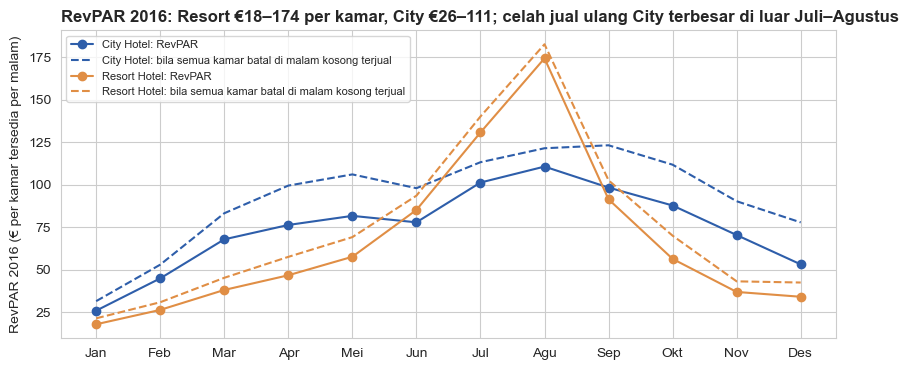

In [247]:
for hotel in ['City Hotel', 'Resort Hotel']:
    t = tahun_2016[tahun_2016['hotel'] == hotel]
    plt.plot(t['bulan'], t['revpar'], marker='o', color=WARNA_HOTEL[hotel], label=hotel + ': RevPAR')
    plt.plot(t['bulan'], t['revpar'] + t['revpar_gap'], linestyle='--', color=WARNA_HOTEL[hotel],
             label=hotel + ': bila semua kamar batal di malam kosong terjual')
plt.title(judul_revpar, loc='left')
plt.xticks(range(1, 13), label_bulan)
plt.ylabel('RevPAR 2016 (€ per kamar tersedia per malam)')
plt.legend(loc='upper left', fontsize=8)
plt.show()

**Intinya:** RevPAR Resort (€73,6) sedikit di atas City (€70,8): ADR City lebih tinggi, tetapi Resort lebih penuh. Menjual ulang sebagian kamar batal menaikkan RevPAR di kedua hotel.

- RevPAR gap: €16,4 (City) dan €9,0 (Resort) per kamar per malam. Jual ulang 10% menaikkan RevPAR jadi €72,4 dan €74,5 (rekomendasi 2)
- Gap dibatasi kamar kosong, karena kalau semua booking dianggap menginap, jumlahnya melebihi kapasitas di 54,6% malam City dan 57,4% malam Resort
- Celah City terbesar justru di luar puncak (€23-25 di April-Mei, September-Oktober, Desember, Juli-Agustus hanya €11-12). Karena itu pickup berjalan sepanjang tahun, sedangkan buffer overbooking hanya untuk malam penuh

**Upgrade dan downgrade.** Tamu yang menginap kadang mendapat tipe kamar berbeda dari pesanannya. Kode kamar disamarkan, jadi kamar "lebih mahal" ditentukan dari median ADR tiap tipe kamar di hotel yang sama: upgrade berarti mendapat tipe kamar dengan median ADR lebih tinggi, downgrade lebih rendah

In [248]:
menginap = df[df['is_canceled'] == 0].copy()

# median ADR tiap tipe kamar di tiap hotel, dipakai sebagai 'tingkat harga' kamar
menginap['kamar_pesan'] = menginap['hotel'] + '-' + menginap['reserved_room_type']
menginap['kamar_dapat'] = menginap['hotel'] + '-' + menginap['assigned_room_type']
median_kamar = menginap.groupby('kamar_pesan')['adr'].median()
menginap['adr_kamar_pesan'] = menginap['kamar_pesan'].map(median_kamar)
menginap['adr_kamar_dapat'] = menginap['kamar_dapat'].map(median_kamar)

berubah = menginap['reserved_room_type'] != menginap['assigned_room_type']
menginap['perubahan_kamar'] = 'Berubah (tidak diketahui)'
menginap.loc[berubah == False, 'perubahan_kamar'] = 'Sama'
menginap.loc[berubah & (menginap['adr_kamar_dapat'] > menginap['adr_kamar_pesan']), 'perubahan_kamar'] = 'Upgrade'
menginap.loc[berubah & (menginap['adr_kamar_dapat'] < menginap['adr_kamar_pesan']), 'perubahan_kamar'] = 'Downgrade'

print(pd.crosstab(menginap['hotel'], menginap['perubahan_kamar'], normalize='index').mul(100).round(1), '\n')
print('Median ADR yang dibayar:')
print(menginap.pivot_table(index='perubahan_kamar', columns='hotel', values='adr', aggfunc='median').round(1))

perubahan_kamar  Berubah (tidak diketahui)  Downgrade  Sama  Upgrade
hotel                                                               
City Hotel                             0.5        3.1  84.8     11.7
Resort Hotel                           1.3        0.4  74.2     24.0 

Median ADR yang dibayar:
hotel                      City Hotel  Resort Hotel
perubahan_kamar                                    
Berubah (tidak diketahui)        84.1           0.0
Downgrade                       104.5         119.4
Sama                            103.5          81.2
Upgrade                          96.0          56.0


In [249]:
menginap['upgrade'] = np.where(menginap['perubahan_kamar'] == 'Upgrade', 1, 0)
menginap['downgrade'] = np.where(menginap['perubahan_kamar'] == 'Downgrade', 1, 0)

upgrade_bulan = menginap.pivot_table(index='hotel', columns='arrival_month', values='upgrade', aggfunc='mean') * 100
downgrade_bulan = menginap.pivot_table(index='hotel', columns='arrival_month', values='downgrade', aggfunc='mean') * 100
upgrade_bulan.columns = label_bulan
downgrade_bulan.columns = label_bulan
print('% upgrade');   print(upgrade_bulan.round(1), '\n')
print('% downgrade'); print(downgrade_bulan.round(1))

% upgrade
               Jan   Feb   Mar   Apr   Mei   Jun   Jul   Agu   Sep   Okt  \
hotel                                                                      
City Hotel    10.0  12.3  12.1  11.1   9.0   9.6   9.0   8.8  17.5  15.1   
Resort Hotel  42.6  33.5  28.0  23.0  22.1  15.1  13.6  12.3  22.0  26.3   

               Nov   Des  
hotel                     
City Hotel    14.9  14.6  
Resort Hotel  34.6  31.8   

% downgrade
              Jan  Feb  Mar  Apr  Mei  Jun  Jul  Agu  Sep  Okt  Nov  Des
hotel                                                                   
City Hotel    0.6  1.7  2.7  2.6  4.2  2.5  3.3  3.3  6.1  4.3  1.7  1.8
Resort Hotel  0.2  0.4  0.4  0.1  0.0  0.6  0.5  0.8  0.6  0.6  0.3  0.1


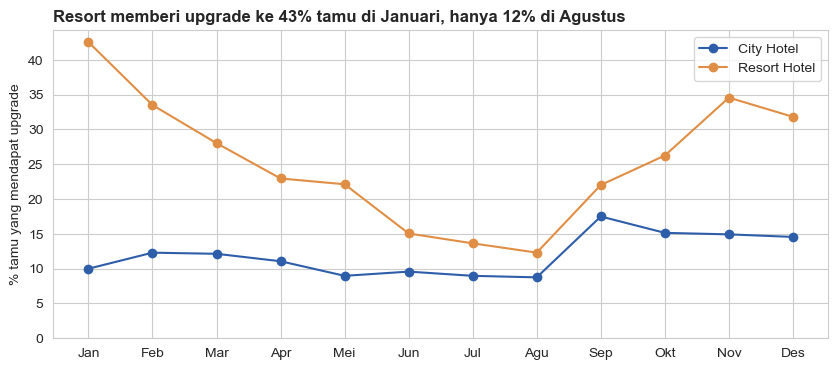

In [250]:
for hotel in ['City Hotel', 'Resort Hotel']:
    plt.plot(label_bulan, upgrade_bulan.loc[hotel], marker='o', color=WARNA_HOTEL[hotel], label=hotel)
plt.title('Resort memberi upgrade ke 43% tamu di Januari, hanya 12% di Agustus', loc='left')
plt.ylabel('% tamu yang mendapat upgrade'); plt.ylim(0)
plt.legend()
plt.show()

In [251]:
# apakah upgrade lebih sering terjadi ketika hotel lebih kosong? (korelasi 12 bulan)
okupansi_label = okupansi_bulan.copy()
okupansi_label.index = label_bulan          # samakan label bulan dengan tabel upgrade_bulan
for hotel in ['City Hotel', 'Resort Hotel']:
    r = upgrade_bulan.loc[hotel].corr(okupansi_label[hotel])
    print(f"{hotel}: korelasi % upgrade dengan okupansi per bulan = {r:.2f}")

City Hotel: korelasi % upgrade dengan okupansi per bulan = -0.25
Resort Hotel: korelasi % upgrade dengan okupansi per bulan = -0.93


- **Resort:** 24,0% tamu mendapat upgrade, dengan puncak 42,6% di Januari dan titik terendah 12,3% di Agustus. Tamu yang di-upgrade membayar median €56, dibanding €81 untuk tamu yang mendapat kamar sesuai pesanan
- **City:** downgrade memuncak di September (6,1%) dan Mei (4,2%)
- Di Resort, porsi upgrade bergerak hampir sempurna berlawanan dengan okupansi (korelasi −0,93 antarbulan): semakin kosong hotel, semakin banyak upgrade. Di City hubungannya lemah (−0,25)

Nilai upgrade = selisih harga kamar yang diberikan dan yang dipesan × jumlah malam.

In [252]:
# harga tipe kamar dibandingkan di hotel, tahun, dan bulan yang sama (median_setara dari 4.C.5),
# karena upgrade paling banyak terjadi di musim sepi saat semua harga rendah
harga_pesan = median_setara.copy()
harga_pesan.columns = ['hotel', 'arrival_date_year', 'arrival_date_month', 'reserved_room_type', 'harga_tipe_dipesan']
harga_dapat = median_setara.copy()
harga_dapat.columns = ['hotel', 'arrival_date_year', 'arrival_date_month', 'assigned_room_type', 'harga_tipe_diberikan']

upg = menginap[menginap['perubahan_kamar'] == 'Upgrade']
upg = upg.merge(harga_pesan, on=['hotel', 'arrival_date_year', 'arrival_date_month', 'reserved_room_type'], how='left')
upg = upg.merge(harga_dapat, on=['hotel', 'arrival_date_year', 'arrival_date_month', 'assigned_room_type'], how='left')
upg['selisih_harga'] = upg['harga_tipe_diberikan'] - upg['harga_tipe_dipesan']
upg['nilai_upgrade'] = upg['selisih_harga'] * upg['total_nights']
jumlah_bulan_data = df['arrival_date'].dt.to_period('M').nunique()

# hanya upgrade yang punya pembanding harga di bulan yang sama dan selisihnya positif
upg_valid = upg[upg['selisih_harga'] > 0]
print(f"Jumlah upgrade                 : {len(upg)}")
print(f"Dihitung (selisih harga > 0)   : {len(upg_valid)}")
print(f"Nilai upgrade gratis           : €{upg_valid['nilai_upgrade'].sum():,.0f} dalam {jumlah_bulan_data} bulan")
print(f"Per tahun                      : €{upg_valid['nilai_upgrade'].sum() / jumlah_bulan_data * 12:,.0f}")
print()
print('Per tahun per hotel (€):')
print((upg_valid.groupby('hotel')['nilai_upgrade'].sum() / jumlah_bulan_data * 12).round(0))
print('Median selisih harga per malam (€):')
print(upg_valid.groupby('hotel')['selisih_harga'].median())

Jumlah upgrade                 : 10587
Dihitung (selisih harga > 0)   : 10154
Nilai upgrade gratis           : €747,503 dalam 26 bulan
Per tahun                      : €345,001

Per tahun per hotel (€):
hotel
City Hotel      142481.0
Resort Hotel    202520.0
Name: nilai_upgrade, dtype: float64
Median selisih harga per malam (€):
hotel
City Hotel      27.60
Resort Hotel    17.56
Name: selisih_harga, dtype: float64


**Upgrade bernilai sekitar €345 ribu per tahun, tetapi data tidak mencatat apakah tamu membayarnya**

- Dari 10.587 upgrade, 10.154 punya pembanding harga dengan selisih positif: €748 ribu dalam 26 bulan, atau €345 ribu per tahun (City €142 ribu, Resort €203 ribu)
- Ini batas atas pendapatan kalau upgrade dijual (rekomendasi 7)

**Uji ketahanan: keputusan menghapus duplikat.** Buffer H-7 hampir tidak berubah kalau duplikat dipertahankan (4.E). Angka utama lain dicek dengan cara yang sama: semua perhitungan diulang dengan 31.994 baris duplikat dikembalikan

In [253]:
# Uji ketahanan: angka utama kalau duplikat dipertahankan (semua_baris dari 4.E.4)
sb = semua_baris.copy()
sb['total_nights'] = sb['stays_in_weekend_nights'] + sb['stays_in_week_nights']
sb['revenue'] = sb['adr'] * sb['total_nights']
sb['revenue_hilang'] = 0.0          # aturan sama dengan 3.G: Non Refund yang batal tetap membayar
sb.loc[(sb['is_canceled'] == 1) & (sb['deposit_type'] != 'Non Refund'), 'revenue_hilang'] = sb['revenue']
sb['arrival_month'] = sb['arrival_date'].dt.month
batal_sb = sb[sb['is_canceled'] == 1]

# okupansi dan peluang jual ulang, cara hitung sama dengan 4.I.4
terisi_sb = bentangkan(sb[sb['is_canceled'] == 0]).groupby(['hotel', 'tanggal_inap']).size().reset_index()
terisi_sb.columns = ['hotel', 'tanggal_inap', 'kamar_terisi']
kapasitas_sb = terisi_sb.groupby('hotel')['kamar_terisi'].max()
terisi_sb['kamar_kosong'] = terisi_sb['hotel'].map(kapasitas_sb) - terisi_sb['kamar_terisi']
dilepas_sb = bentangkan(sb[(sb['reservation_status'] == 'Canceled') & (sb['days_before_arrival'] > 7)])
dilepas_sb = dilepas_sb.groupby(['hotel', 'tanggal_inap'])['adr'].agg(['count', 'mean']).reset_index()
celah_sb = terisi_sb.merge(dilepas_sb, on=['hotel', 'tanggal_inap'], how='left').fillna(0)
celah_sb['bisa_dijual_ulang'] = np.where(celah_sb['count'] < celah_sb['kamar_kosong'], celah_sb['count'], celah_sb['kamar_kosong'])
okupansi_sb = terisi_sb.groupby('hotel')['kamar_terisi'].mean() / kapasitas_sb * 100

# segmen risiko dengan aturan yang sama dengan 4.F.2 (Online TA, lead time > 90 hari)
risiko_sb = (batal_sb['market_segment'] == 'Online TA') & (batal_sb['lead_time'] > 90)
jan_agu_sb = sb[(sb['arrival_month'] <= 8) & sb['arrival_date_year'].isin([2016, 2017])]
tren_sb = jan_agu_sb.pivot_table(index='arrival_date_year', columns='hotel', values='is_canceled', aggfunc='mean') * 100
# cancel rate Jan-Agu tanpa duplikat (4.B.4 hanya menyimpan tren_rugi, jadi dihitung lagi di sini)
tren = jan_agu.pivot_table(index='arrival_date_year', columns='hotel', values='is_canceled', aggfunc='mean') * 100
batal = df[df['is_canceled'] == 1]

uji_ketahanan = pd.DataFrame({
    'Tanpa duplikat': [
        okupansi.groupby('hotel')['okupansi_%'].mean()['City Hotel'],
        okupansi.groupby('hotel')['okupansi_%'].mean()['Resort Hotel'],
        celah['nilai_peluang'].sum() / 1e6,
        batal[batal['segmen_risiko'] == 'Risiko tinggi']['revenue_hilang'].sum() / batal['revenue_hilang'].sum() * 100,
        batal[batal['agent'].isin([9, 240])]['revenue_hilang'].sum() / batal['revenue_hilang'].sum() * 100,
        tren.loc[2017, 'City Hotel'] - tren.loc[2016, 'City Hotel'],
        tren.loc[2017, 'Resort Hotel'] - tren.loc[2016, 'Resort Hotel']],
    'Dengan duplikat': [
        okupansi_sb['City Hotel'],
        okupansi_sb['Resort Hotel'],
        (celah_sb['bisa_dijual_ulang'] * celah_sb['mean']).sum() / 1e6,
        batal_sb[risiko_sb]['revenue_hilang'].sum() / batal_sb['revenue_hilang'].sum() * 100,
        batal_sb[batal_sb['agent'].isin([9, 240])]['revenue_hilang'].sum() / batal_sb['revenue_hilang'].sum() * 100,
        tren_sb.loc[2017, 'City Hotel'] - tren_sb.loc[2016, 'City Hotel'],
        tren_sb.loc[2017, 'Resort Hotel'] - tren_sb.loc[2016, 'Resort Hotel']]},
    index=['Okupansi City (%)', 'Okupansi Resort (%)', 'Peluang jual ulang (€ juta, 26 bulan)',
           'Segmen risiko: % revenue hilang', 'Agent 9 + 240: % revenue hilang',
           'Kenaikan cancel rate City 2016-2017 (poin)', 'Kenaikan cancel rate Resort 2016-2017 (poin)'])
uji_ketahanan.round(1)

,Tanpa duplikat,Dengan duplikat
Okupansi City (%),64.8,74.9
Okupansi Resort (%),74.4,80.5
"Peluang jual ulang (€ juta, 26 bulan)",4.1,3.2
Segmen risiko: % revenue hilang,43.4,41.9
Agent 9 + 240: % revenue hilang,74.5,70.3
Kenaikan cancel rate City 2016-2017 (poin),6.3,3.8
Kenaikan cancel rate Resort 2016-2017 (poin),6.4,4.0


**Keputusan soal duplikat mengubah besar angka, bukan arah temuan. Sampaikan sebagai rentang**

- Kalau duplikat dikembalikan: okupansi naik ke sekitar 75% (City) dan 80% (Resort), peluang jual ulang turun dari €4,1 juta ke €3,2 juta, segmen risiko 43,4% ke 41,9%, agent 9 dan 240 74,5% ke 70,3%, dan kenaikan cancel rate 2016 ke 2017 jadi 3,8 poin (City) dan 4,0 poin (Resort)

#### **5. Bagaimana harga terbentuk, dan pasar mana yang tumbuh?**
Siapa yang mendapat harga murah? Harga dibandingkan dengan median kamar sejenis di bulan yang sama, per lead time dan segmen (booking yang menginap, ADR di atas 0).

In [254]:
harga_menginap = harga[(harga['is_canceled'] == 0) & (harga['adr'] > 0)]

relatif_lead = harga_menginap.pivot_table(index='lead_bin', columns='hotel', values='harga_relatif', aggfunc='median')
print('Harga relatif per lead time (1,00 = sama dengan median)')
print(relatif_lead.round(3), '\n')
print('Harga relatif per segmen')
print(harga_menginap.pivot_table(index='market_segment', columns='hotel', values='harga_relatif', aggfunc='median').round(3))

Harga relatif per lead time (1,00 = sama dengan median)
hotel     City Hotel  Resort Hotel
lead_bin                          
0-7            1.065         1.031
8-30           1.055         1.089
31-90          1.000         1.030
91-180         0.956         0.942
181-365        0.888         0.858
>365           0.939         0.843 

Harga relatif per segmen
hotel           City Hotel  Resort Hotel
market_segment                          
Aviation             0.831           NaN
Complementary        0.482         0.123
Corporate            0.835         0.833
Direct               1.048         1.069
Groups               0.901         0.988
Offline TA/TO        0.838         0.799
Online TA            1.037         1.070


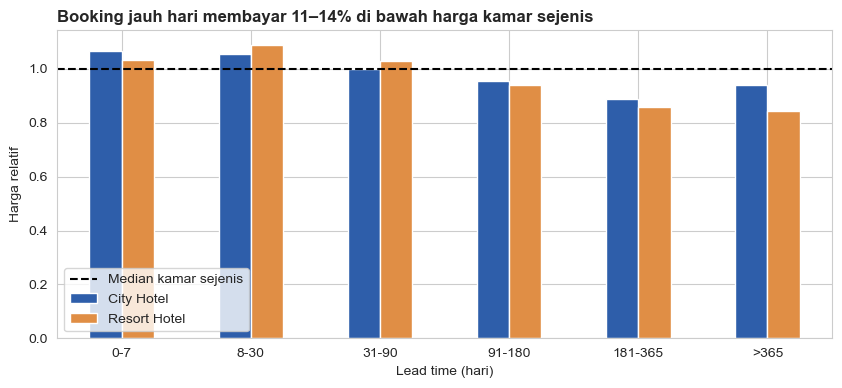

In [255]:
relatif_lead.plot.bar(color=[WARNA_HOTEL['City Hotel'], WARNA_HOTEL['Resort Hotel']])
plt.axhline(1, color='black', linestyle='--', label='Median kamar sejenis')
plt.title('Booking jauh hari membayar 11–14% di bawah harga kamar sejenis', loc='left')
plt.xticks(rotation=0)
plt.xlabel('Lead time (hari)'); plt.ylabel('Harga relatif')
plt.legend(loc='lower left')
plt.show()

In [256]:
df['adr_per_orang'] = df['adr'] / (df['adults'] + df['children'])
per_orang = df[(df['is_canceled'] == 0) & (df['adr'] > 0) & ((df['adults'] + df['children']) > 0)]
per_orang.pivot_table(index='guest_type', columns='hotel', values='adr_per_orang', aggfunc='median').round(1)

hotel,City Hotel,Resort Hotel
guest_type,,
Grup 3+ dewasa,49.5,51.8
Keluarga,45.2,45.8
Pasangan,49.8,39.5
Solo,90.0,45.0


- **Early-bird:** booking 181-365 hari sebelum kedatangan membayar 11,2% (City) dan 14,2% (Resort) di bawah median kamar sejenis, padahal cancel rate kelompok ini 39,7% (4.C). Booking mendadak (0-7 hari) membayar 3-7% di atas median
- Offline TA/TO dan Corporate membayar sekitar 16-20% di bawah median, Online TA dan Direct 4-7% di atas
- **Harga per orang:** tamu solo di City membayar €90,0 per orang, hampir dua kali pasangan (€49,8). Tamu solo (4.G.3) adalah pembayar per orang tertinggi dan cancel rate-nya rendah (19%)

In [257]:
negara = ['PRT', 'GBR', 'FRA', 'ESP', 'DEU', 'IRL']

profil_negara = pd.DataFrame()
profil_negara['%_revenue_masuk'] = co.groupby('country')['revenue'].sum() / co['revenue'].sum() * 100
profil_negara['malam_rata2'] = co.groupby('country')['total_nights'].mean()
profil_negara['adr_median'] = co.groupby('country')['adr'].median()
print(profil_negara.loc[negara].round(2), '\n')

         %_revenue_masuk  malam_rata2  adr_median
country                                          
PRT                21.11         2.55       80.75
GBR                16.22         5.11       84.43
FRA                11.92         3.56      100.00
ESP                 8.79         3.01      104.56
DEU                 7.07         3.81       96.28
IRL                 5.11         5.32       89.10 



In [258]:
# lama menginap dan ADR dipisah per hotel: angka gabungan ikut dipengaruhi porsi negara itu di Resort
print('Rata-rata lama menginap per hotel (malam):')
print(co[co['country'].isin(negara)].pivot_table(index='country', columns='hotel', values='total_nights', aggfunc='mean').round(1), '\n')
print('Median ADR per hotel (€):')
print(co[co['country'].isin(negara)].pivot_table(index='country', columns='hotel', values='adr', aggfunc='median').round(1), '\n')
print('% booking check-out di Resort:')
print((co[co['country'].isin(negara)].groupby('country')['hotel'].apply(lambda x: (x == 'Resort Hotel').mean() * 100)).round(1), '\n')

co_jan_agu = co[(co['arrival_month'] <= 8) & (co['arrival_date_year'].isin([2016, 2017]))]
porsi_negara = pd.crosstab([co_jan_agu['hotel'], co_jan_agu['arrival_date_year']], co_jan_agu['country'], normalize='index') * 100
print(porsi_negara[['PRT', 'GBR', 'FRA', 'DEU', 'USA']].round(1), '\n')

print('% tamu yang minta parkir:')
print(co.groupby('hotel')['required_car_parking_spaces'].apply(lambda x: (x > 0).mean() * 100).round(1), '\n')

resort_menginap = co[co['hotel'] == 'Resort Hotel']
print('% tamu Resort yang memilih Half Board:')
print(resort_menginap[resort_menginap['country'].isin(negara)].groupby('country')['meal'].apply(lambda x: (x == 'HB').mean() * 100).round(1), '\n')

print('Hari kedatangan tamu Resort yang menginap 7 malam:')
print(resort_menginap[resort_menginap['total_nights'] == 7]['arrival_weekday'].value_counts(normalize=True).mul(100).round(1).head(3))

Rata-rata lama menginap per hotel (malam):


hotel    City Hotel  Resort Hotel
country                          
DEU             3.5           5.3
ESP             2.8           3.2
FRA             3.4           4.4
GBR             3.2           6.3
IRL             3.3           6.2
PRT             2.2           2.9 

Median ADR per hotel (€):
hotel    City Hotel  Resort Hotel
country                          
DEU           100.0          72.0
ESP           108.0          95.5
FRA           105.0          77.1
GBR           106.9          68.0
IRL           106.4          76.6
PRT            89.0          68.0 

% booking check-out di Resort:
country
DEU    18.4
ESP    50.6
FRA    17.4
GBR    61.8
IRL    68.6
PRT    53.1
Name: hotel, dtype: float64 

country                          PRT   GBR   FRA   DEU  USA
hotel        arrival_date_year                             
City Hotel   2016               25.1   7.7  16.1   9.5  2.2
             2017               15.3  11.3  15.9  10.7  3.4
Resort Hotel 2016               37.9  18.7   

**Portugal membawa revenue terbesar tetapi menginap paling singkat dan membayar paling murah. Porsinya turun, sementara Inggris dan Amerika naik**

- Portugal 21,1% revenue masuk, menginap 2,55 malam, ADR €80,8 (terendah). Per hotel, yang paling lama: Inggris (6,3 malam) dan Irlandia (6,2) di Resort, Jerman (3,5) di City. Angka gabungan terdorong porsi Resort (61,8% check-out Inggris dan 68,6% Irlandia ada di Resort)
- Porsi tamu Portugal Januari-Agustus 2016 ke 2017 turun: 25,1% ke 15,3% (City), 37,9% ke 33,1% (Resort)
- 20,8% tamu Resort minta parkir (City 5,1%). Minat Half Board di Resort: Jerman 37,5%, Spanyol 27,5%, Portugal 14,5%

> **Babak 5 dari 6: Pemasukan dan kelompok** (4.J-4.M)
>
> Revenue yang masuk (4.J), ringkasan 4.B-4.J (4.K), peringkat kelompok dengan LRFM (4.L), dan RFM agent serta perusahaan (4.M).

### **J. Pola pemasukan: hari, bulan, segmen, dan tipe kamar** (pertanyaan H)
4.B-4.I membahas booking yang batal. Bagian ini melihat booking yang datang: kapan dan dari siapa pemasukan masuk, dan bagaimana pola tertinggi dan terendahnya di tiap hotel. Pertanyaannya:

1. Malam dan hari apa yang tertinggi dan terendah, dan kenapa? (4.J.1-4.J.3)
2. Bulan dan malam apa yang tertinggi dan terendah? (4.J.4-4.J.5)
3. Segmen mana tertinggi dan terendah, dan siapa yang mengisi kamar? (4.J.6)
4. Tipe kamar apa yang paling laku di malam Senin? (4.J.7)
5. Apa yang dipelajari dari Frequency-Monetary (FM), dan segmen mana yang diprioritaskan? (4.J.8)

**Definisi**

- **Pemasukan** = estimasi nilai menginap, `adr × total_nights` booking Check-Out saja. Bukan uang kas, net revenue, atau profit. Complementary tetap dihitung (nilainya hanya 0,02%)
- Dihitung **per malam menginap**, bukan per hari kedatangan, supaya hari yang ramai check-in tidak tampak paling besar. **Kedatangan per tanggal** (jumlah booking Check-Out yang tiba) dipakai sebagai ukuran pendamping
- City dan Resort dipisah, karena angka gabungan bisa menyesatkan
- Bulan dibaca per tahun: hanya 2016 yang lengkap (2015: Juli-Desember, 2017: Januari-Agustus)

In [259]:
masuk = df[df['is_canceled'] == 0]            # booking Check-Out: nilai booking yang menjadi pemasukan
complementary = masuk[masuk['market_segment'] == 'Complementary']['revenue'].sum()
print(f"Nilai semua booking (termasuk yang batal) : €{df['revenue'].sum():,.0f}")
print(f"Pemasukan (booking Check-Out)             : €{masuk['revenue'].sum():,.0f}")
print(f"   di antaranya segmen Complementary      : €{complementary:,.0f} ({complementary / masuk['revenue'].sum():.2%})")

Nilai semua booking (termasuk yang batal) : €34,446,255
Pemasukan (booking Check-Out)             : €22,967,612
   di antaranya segmen Complementary      : €4,805 (0.02%)


In [260]:
# pemasukan per hotel per tanggal kedatangan; tanggal tanpa tamu check-out dihitung 0
semua_tanggal = pd.date_range(df['arrival_date'].min(), df['arrival_date'].max())
kerangka_city = pd.DataFrame()
kerangka_city['arrival_date'] = semua_tanggal
kerangka_city['hotel'] = 'City Hotel'
kerangka_resort = pd.DataFrame()
kerangka_resort['arrival_date'] = semua_tanggal
kerangka_resort['hotel'] = 'Resort Hotel'
kerangka = pd.concat([kerangka_city, kerangka_resort], ignore_index=True)

pemasukan_tanggal = masuk.groupby(['hotel', 'arrival_date'])['revenue'].sum().reset_index()
harian = kerangka.merge(pemasukan_tanggal, on=['hotel', 'arrival_date'], how='left')
harian['revenue'] = harian['revenue'].fillna(0)
harian = harian[['hotel', 'arrival_date', 'revenue']]
harian.columns = ['hotel', 'arrival_date', 'pemasukan']
harian['hari'] = harian['arrival_date'].dt.day_name()
harian['bulan'] = harian['arrival_date'].dt.month

In [261]:
# gabungan kedua hotel
harian_gab = harian.groupby('arrival_date')['pemasukan'].sum().reset_index()
harian_gab['hari'] = harian_gab['arrival_date'].dt.day_name()
harian_gab['bulan'] = harian_gab['arrival_date'].dt.month

jumlah_tanggal = harian_gab['hari'].value_counts().loc[urutan_hari]
print('Jumlah tanggal per hari:')
print(jumlah_tanggal)

Jumlah tanggal per hari:
hari
Monday       113
Tuesday      113
Wednesday    114
Thursday     114
Friday       113
Saturday     113
Sunday       113
Name: count, dtype: int64


In [262]:
# ukuran utama 4.J: pemasukan per malam menginap, per hotel (malam_terisi dari 4.I.4: satu baris per malam)
per_malam_hotel = malam_terisi.groupby(['hotel', 'tanggal_inap'])['adr'].agg(['count', 'sum']).reset_index()
per_malam_hotel.columns = ['hotel', 'tanggal_inap', 'kamar_terisi', 'pemasukan_malam']
per_malam_hotel['hari'] = per_malam_hotel['tanggal_inap'].dt.day_name()
per_malam_hotel['bulan'] = per_malam_hotel['tanggal_inap'].dt.month
per_malam_hotel['tahun'] = per_malam_hotel['tanggal_inap'].dt.year
print('Jumlah malam per hotel:', per_malam_hotel.groupby('hotel').size().to_dict())

Jumlah malam per hotel: {'City Hotel': 793, 'Resort Hotel': 793}


In [263]:
# ukuran pendamping: jumlah kedatangan (booking Check-Out) per tanggal, per hotel; tanggal tanpa kedatangan = 0
datang_tanggal = masuk.groupby(['hotel', 'arrival_date']).size().reset_index()
datang_tanggal.columns = ['hotel', 'arrival_date', 'kedatangan']
harian = harian.merge(datang_tanggal, on=['hotel', 'arrival_date'], how='left')
harian['kedatangan'] = harian['kedatangan'].fillna(0)


def bentangkan_detail(data, kolom):
    # sama dengan bentangkan() di 4.I.4, tetapi ikut membawa kolom tambahan (misalnya segmen dan tipe kamar)
    data = data[data['total_nights'] > 0]
    daftar = []
    for i in range(data['total_nights'].max()):
        malam_ke_i = data[data['total_nights'] > i][['hotel', 'arrival_date', 'adr'] + kolom].copy()
        malam_ke_i['tanggal_inap'] = malam_ke_i['arrival_date'] + pd.to_timedelta(i, unit='D')
        daftar.append(malam_ke_i)
    hasil = pd.concat(daftar, ignore_index=True)      # index baru, supaya crosstab tidak kena index duplikat
    hasil = hasil[(hasil['tanggal_inap'] >= '2015-07-01') & (hasil['tanggal_inap'] <= '2017-08-31')]
    return hasil

In [264]:
# satu baris per malam menginap, lengkap dengan segmen dan tipe kamar (dipakai di 4.J.6 dan 4.J.7)
malam_detail = bentangkan_detail(masuk, ['market_segment', 'reserved_room_type'])
malam_detail['hari'] = malam_detail['tanggal_inap'].dt.day_name()

**Dari €34,45 juta nilai semua booking, €22,97 juta masuk sebagai pemasukan booking Check-Out**

- Selisih €11,48 juta adalah booking batal (€11,24 juta revenue hilang + €0,24 juta Forfeited Deposit Revenue)
- Complementary hanya €4.805 (0,02%)
- Data berisi 793 tanggal dan 793 malam per hotel

#### **1. Hari: pemasukan per malam dan kedatangan per tanggal**

In [265]:
judul_malam = 'Per malam menginap, pemasukan hampir rata: malam tertinggi hanya 9–10% di atas terendah'
judul_datang = 'Kedatangan teramai: City di hari Senin, Resort di hari Senin dan Sabtu'

# rata-rata, terendah, dan tertinggi per hari, per hotel
hari_hotel = {}
for hotel in ['City Hotel', 'Resort Hotel']:
    m = per_malam_hotel[per_malam_hotel['hotel'] == hotel]
    t = m.groupby('hari')['pemasukan_malam'].agg(['mean', 'min', 'max']).loc[urutan_hari]
    t.columns = ['pemasukan_rata2', 'pemasukan_terendah', 'pemasukan_tertinggi']
    t['kamar_terisi_rata2'] = m.groupby('hari')['kamar_terisi'].mean()
    t['kedatangan_rata2'] = harian[harian['hotel'] == hotel].groupby('hari')['kedatangan'].mean()
    t.index = label_hari
    hari_hotel[hotel] = t
    print(hotel, '- pemasukan dan kamar terisi per malam menginap, kedatangan per tanggal:')
    print(t.round(1), '\n')

City Hotel - pemasukan dan kamar terisi per malam menginap, kedatangan per tanggal:
     pemasukan_rata2  pemasukan_terendah  pemasukan_tertinggi  \
Sen          15442.8               392.4              28980.5   
Sel          15720.0               168.6              29429.6   
Rab          15503.0               270.4              28856.4   
Kam          15409.2               270.4              28793.6   
Jum          15142.3                 0.0              28771.1   
Sab          15357.3               827.9              28465.8   
Min          14413.5               514.3              27897.0   

     kamar_terisi_rata2  kedatangan_rata2  
Sen               142.1              54.8  
Sel               145.0              42.9  
Rab               143.1              44.2  
Kam               140.7              47.2  
Jum               137.1              50.4  
Sab               139.1              43.8  
Min               131.8              45.5   

Resort Hotel - pemasukan dan kamar terisi

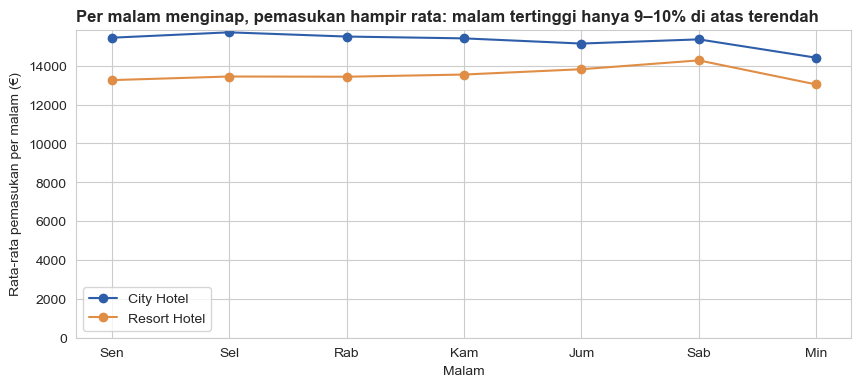

In [266]:
# grafik 1: pemasukan per malam (ukuran utama)
for hotel in ['City Hotel', 'Resort Hotel']:
    plt.plot(label_hari, hari_hotel[hotel]['pemasukan_rata2'], marker='o', color=WARNA_HOTEL[hotel], label=hotel)
plt.title(judul_malam, loc='left')
plt.xlabel('Malam'); plt.ylabel('Rata-rata pemasukan per malam (€)'); plt.ylim(0)
plt.legend()
plt.show()

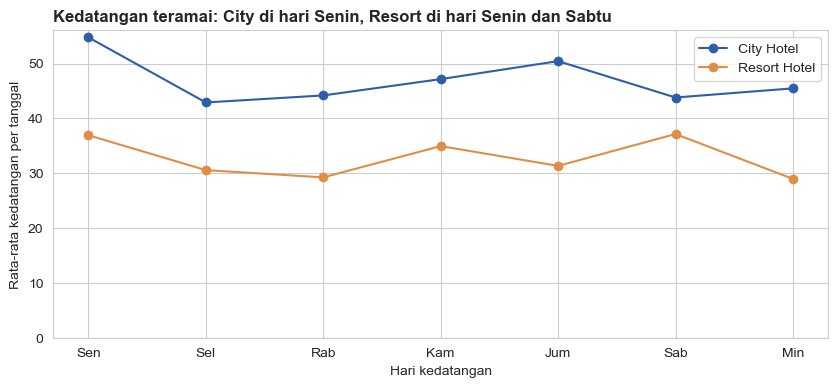

In [267]:
# grafik 2: kedatangan per tanggal (ukuran pendamping)
for hotel in ['City Hotel', 'Resort Hotel']:
    plt.plot(label_hari, hari_hotel[hotel]['kedatangan_rata2'], marker='o', color=WARNA_HOTEL[hotel], label=hotel)
plt.title(judul_datang, loc='left')
plt.xlabel('Hari kedatangan'); plt.ylabel('Rata-rata kedatangan per tanggal'); plt.ylim(0)
plt.legend()
plt.show()

**Pemasukan per malam hampir sama di semua hari. Yang berbeda adalah hari kedatangan**

- City: tertinggi Selasa (€15.720), terendah Minggu (€14.414), selisih 9%. Resort: tertinggi Sabtu (€14.276), terendah Minggu (€13.037), selisih 10%. Selisih ini mengikuti kamar terisi (City 131,8-145,0, Resort 130,5-144,2)
- Sebaran lebar karena musim: malam tertinggi City €28-29 ribu, Resort €36-38 ribu, terendah di bawah €2.500
- Kedatangan beda pola. City paling ramai Senin (54,8) dan paling sepi Selasa (42,9). Resort paling ramai Sabtu (37,2) dan Senin (36,9), paling sepi Minggu (29,0) dan Rabu (29,3). Kalau nilai booking dicatat di hari kedatangan (cara notebook 4D), Senin tampak tertinggi (1,4 kali Rabu di City, 1,6 kali di Resort), itu pola kedatangan (4.J.3)

#### **2. Kenapa pemasukan per malam hampir rata, padahal kedatangan Senin ramai?**
Pemasukan per malam = kamar terisi × ADR rata-rata. Kedatangan = booking Check-Out per tanggal × nilai per booking. Pembatalan ikut dicek karena hari yang sering batal punya lebih sedikit booking Check-Out

In [268]:
# Pemasukan per malam = kamar terisi x ADR rata-rata kamar yang terisi malam itu
for hotel in ['City Hotel', 'Resort Hotel']:
    t = hari_hotel[hotel].copy()
    t['adr_kamar_terisi'] = t['pemasukan_rata2'] / t['kamar_terisi_rata2']
    print(hotel, '- malam tertinggi dibanding terendah (rasio):')
    print(f"   pemasukan {t['pemasukan_rata2'].max() / t['pemasukan_rata2'].min():.2f} | "
          f"kamar terisi {t['kamar_terisi_rata2'].max() / t['kamar_terisi_rata2'].min():.2f} | "
          f"ADR kamar terisi {t['adr_kamar_terisi'].max() / t['adr_kamar_terisi'].min():.2f}")
    print(t[['kamar_terisi_rata2', 'adr_kamar_terisi', 'pemasukan_rata2']].round(1), '\n')

City Hotel - malam tertinggi dibanding terendah (rasio):
   pemasukan 1.09 | kamar terisi 1.10 | ADR kamar terisi 1.02
     kamar_terisi_rata2  adr_kamar_terisi  pemasukan_rata2
Sen               142.1             108.7          15442.8
Sel               145.0             108.4          15720.0
Rab               143.1             108.3          15503.0
Kam               140.7             109.5          15409.2
Jum               137.1             110.4          15142.3
Sab               139.1             110.4          15357.3
Min               131.8             109.3          14413.5 

Resort Hotel - malam tertinggi dibanding terendah (rasio):
   pemasukan 1.10 | kamar terisi 1.10 | ADR kamar terisi 1.02
     kamar_terisi_rata2  adr_kamar_terisi  pemasukan_rata2
Sen               134.3              98.7          13260.2
Sel               137.6              97.7          13445.7
Rab               137.5              97.7          13434.4
Kam               136.6              99.1         

In [269]:
# Kedatangan: kenapa hari Senin ramai kedatangan (analisis awal 4.J, per tanggal kedatangan)
pendorong = pd.DataFrame()
pendorong['booking_per_tanggal'] = df.groupby('arrival_weekday').size() / jumlah_tanggal
pendorong['cancel_rate_%'] = df.groupby('arrival_weekday')['is_canceled'].mean() * 100
pendorong['checkout_per_tanggal'] = masuk.groupby('arrival_weekday').size() / jumlah_tanggal
pendorong['adr_rata2'] = masuk.groupby('arrival_weekday')['adr'].mean()
pendorong['malam_rata2'] = masuk.groupby('arrival_weekday')['total_nights'].mean()
pendorong['nilai_per_booking'] = masuk.groupby('arrival_weekday')['revenue'].mean()
pendorong = pendorong.loc[urutan_hari]
print(pendorong.round(2), '\n')

           booking_per_tanggal  cancel_rate_%  checkout_per_tanggal  \
Monday                  125.20          26.76                 91.70   
Tuesday                  97.18          24.35                 73.51   
Wednesday                98.71          25.57                 73.47   
Thursday                113.72          27.78                 82.13   
Friday                  117.84          30.58                 81.81   
Saturday                115.90          30.13                 80.98   
Sunday                  101.50          26.61                 74.49   

           adr_rata2  malam_rata2  nilai_per_booking  
Monday        102.46         3.66             388.60  
Tuesday        98.62         3.39             349.06  
Wednesday      97.72         3.17             322.53  
Thursday      101.54         3.46             349.50  
Friday        106.07         3.09             332.06  
Saturday      104.51         3.63             382.83  
Sunday        103.96         3.98             

In [270]:
print('Senin dibanding Rabu (rasio):')
print((pendorong.loc['Monday'] / pendorong.loc['Wednesday']).round(2), '\n')

for hotel in ['City Hotel', 'Resort Hotel']:
    m = masuk[masuk['hotel'] == hotel]
    per_hotel = pd.DataFrame()
    per_hotel['checkout_per_tanggal'] = m.groupby('arrival_weekday').size() / jumlah_tanggal
    per_hotel['adr_rata2'] = m.groupby('arrival_weekday')['adr'].mean()
    per_hotel['malam_rata2'] = m.groupby('arrival_weekday')['total_nights'].mean()
    rasio = per_hotel.loc['Monday'] / per_hotel.loc['Wednesday']
    print(hotel, '- Senin dibanding Rabu (rasio):')
    print(rasio.round(2), '\n')

Senin dibanding Rabu (rasio):
booking_per_tanggal     1.27
cancel_rate_%           1.05
checkout_per_tanggal    1.25
adr_rata2               1.05
malam_rata2             1.15
nilai_per_booking       1.20
dtype: float64 

City Hotel - Senin dibanding Rabu (rasio):
checkout_per_tanggal    1.24
adr_rata2               1.02
malam_rata2             1.13
dtype: float64 

Resort Hotel - Senin dibanding Rabu (rasio):
checkout_per_tanggal    1.26
adr_rata2               1.10
malam_rata2             1.18
dtype: float64 



**Pemasukan per malam mengikuti kamar terisi**. Senin ramai karena banyak yang tiba, bukan karena hotelnya lebih penuh

- Per malam: tertinggi hanya 1,09-1,10 kali terendah (pemasukan) dan 1,10 kali (kamar terisi), sedangkan ADR kamar terisi hanya beda 1,02 kali
- Kedatangan Senin vs Rabu (kedua hotel): 91,7 vs 73,5 per tanggal (+25%), menginap 3,66 vs 3,17 malam (+15%), ADR €102,5 vs €97,7 (+5%), cancel rate hampir sama (26,8% vs 25,6%). Per hotel: Senin 1,24 kali Rabu di City dan 1,26 kali di Resort
- Tamu yang tiba Senin menginap lebih lama, jadi malam Selasa-Rabu tetap terisi
- Kedatangan yang paling sering batal: Jumat (30,6%) dan Sabtu (30,1%)

#### **3. Dicatat pada hari kedatangan atau pada malam menginap?**
Notebook 4D dan analisis awal bagian ini mencatat seluruh nilai booking pada hari kedatangan. Tamu yang tiba Senin dan menginap 4 malam membayar untuk malam Senin sampai Kamis. Di sini kedua cara dibandingkan per hotel, sebagai indeks (1,0 = rata-rata tujuh hari)

In [271]:
# nilai booking dicatat pada hari kedatangan vs pemasukan dicatat pada malam menginap, per hotel
# kedua ukuran dijadikan indeks (1,0 = rata-rata tujuh hari) supaya bisa dibandingkan di satu sumbu
banding_hari = pd.DataFrame()
for hotel in ['City Hotel', 'Resort Hotel']:
    nama = hotel.replace(' Hotel', '')
    per_kedatangan = harian[harian['hotel'] == hotel].groupby('hari')['pemasukan'].mean().loc[urutan_hari]
    per_malam_hari = hari_hotel[hotel]['pemasukan_rata2'].values
    banding_hari[nama + ' - per hari kedatangan'] = (per_kedatangan / per_kedatangan.mean()).values
    banding_hari[nama + ' - per malam menginap'] = per_malam_hari / per_malam_hari.mean()
banding_hari.index = label_hari
print(banding_hari.round(2), '\n')
print('Tertinggi dibanding terendah:')
print((banding_hari.max() / banding_hari.min()).round(2))

     City - per hari kedatangan  City - per malam menginap  \
Sen                        1.23                       1.01   
Sel                        0.88                       1.03   
Rab                        0.87                       1.01   
Kam                        0.98                       1.01   
Jum                        1.00                       0.99   
Sab                        0.95                       1.00   
Min                        1.09                       0.94   

     Resort - per hari kedatangan  Resort - per malam menginap  
Sen                          1.23                         0.98  
Sel                          0.89                         0.99  
Rab                          0.76                         0.99  
Kam                          1.00                         1.00  
Jum                          0.87                         1.02  
Sab                          1.21                         1.05  
Min                          1.04               

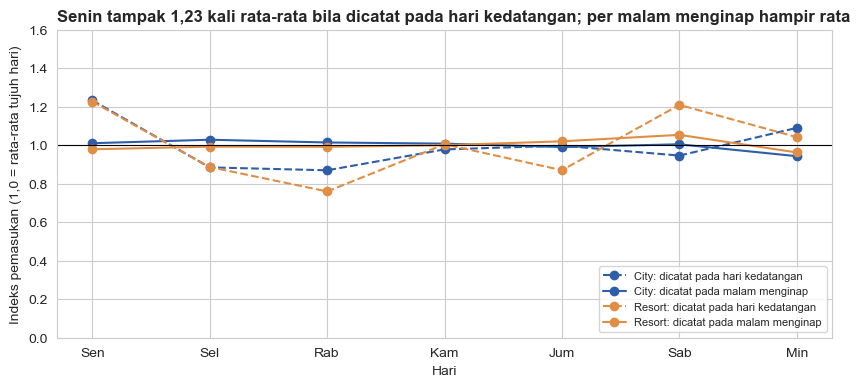

In [272]:
for hotel in ['City Hotel', 'Resort Hotel']:
    nama = hotel.replace(' Hotel', '')
    plt.plot(label_hari, banding_hari[nama + ' - per hari kedatangan'], marker='o', linestyle='--', color=WARNA_HOTEL[hotel],
             label=nama + ': dicatat pada hari kedatangan')
    plt.plot(label_hari, banding_hari[nama + ' - per malam menginap'], marker='o', color=WARNA_HOTEL[hotel],
             label=nama + ': dicatat pada malam menginap')
plt.axhline(1, color='black', linewidth=0.8)
plt.title('Senin tampak 1,23 kali rata-rata bila dicatat pada hari kedatangan; per malam menginap hampir rata', loc='left')
plt.xlabel('Hari'); plt.ylabel('Indeks pemasukan (1,0 = rata-rata tujuh hari)')
plt.ylim(0, 1.6)
plt.legend(loc='lower right', fontsize=8)
plt.show()

Yang berbeda antarhari adalah arus check-in, bukan pemasukan kamar. Harga khusus malam Senin tidak punya dasar dari data ini

- Dicatat di hari kedatangan: Senin 1,23 kali rata-rata, dan hari tertinggi 1,42 kali (City) dan 1,61 kali (Resort) hari terendah
- Dicatat di malam menginap: indeks semua hari 0,94-1,05, malam tertinggi hanya 1,09-1,10 kali terendah

#### **4. Bulan: kapan pemasukan tertinggi dan terendah?**
Pemasukan per bulan = jumlah pemasukan per malam, per hotel dan tahun. Hanya 2016 yang lengkap (2015: Juli-Desember, 2017: Januari-Agustus). Bulan yang ditunjuk cara hitung lama (rata-rata per bulan kalender) ikut dicetak sebagai pembanding

In [273]:
judul = {'City Hotel': 'City: Agustus tertinggi di 2016 dan 2017; "puncak Mei" hanya efek rata-rata kalender',
         'Resort Hotel': 'Resort: Agustus tertinggi di ketiga tahun'}

# pemasukan per bulan dari malam menginap, per hotel per tahun (2015 hanya Juli-Desember, 2017 hanya Januari-Agustus)
bulan_tahun = per_malam_hotel.pivot_table(index=['hotel', 'tahun'], columns='bulan', values='pemasukan_malam', aggfunc='sum') / 1000
bulan_tahun.columns = label_bulan
print('Pemasukan per bulan dari malam menginap (€ ribu):')
print(bulan_tahun.round(0), '\n')

puncak_bulan = pd.DataFrame()
puncak_bulan['tertinggi'] = bulan_tahun.idxmax(axis=1)
puncak_bulan['nilai_tertinggi'] = bulan_tahun.max(axis=1)
puncak_bulan['terendah'] = bulan_tahun.idxmin(axis=1)
puncak_bulan['nilai_terendah'] = bulan_tahun.min(axis=1)
puncak_bulan['jumlah_bulan'] = bulan_tahun.notna().sum(axis=1)
print(puncak_bulan.round(0), '\n')

Pemasukan per bulan dari malam menginap (€ ribu):
                      Jan    Feb    Mar    Apr    Mei    Jun    Jul     Agu  \
hotel        tahun                                                            
City Hotel   2015     NaN    NaN    NaN    NaN    NaN    NaN   26.0   207.0   
             2016   173.0  281.0  454.0  494.0  546.0  504.0  677.0   740.0   
             2017   334.0  383.0  495.0  676.0  749.0  705.0  740.0   807.0   
Resort Hotel 2015     NaN    NaN    NaN    NaN    NaN    NaN  592.0   825.0   
             2016   101.0  140.0  217.0  257.0  328.0  469.0  745.0   994.0   
             2017   154.0  184.0  229.0  366.0  402.0  570.0  892.0  1082.0   

                      Sep    Okt    Nov    Des  
hotel        tahun                              
City Hotel   2015   433.0  349.0  147.0  169.0  
             2016   636.0  587.0  455.0  355.0  
             2017     NaN    NaN    NaN    NaN  
Resort Hotel 2015   453.0  254.0  130.0  136.0  
             2016   504

City Hotel: rata-rata kalender menunjuk Mei sebagai bulan tertinggi
Resort Hotel: rata-rata kalender menunjuk Agu sebagai bulan tertinggi


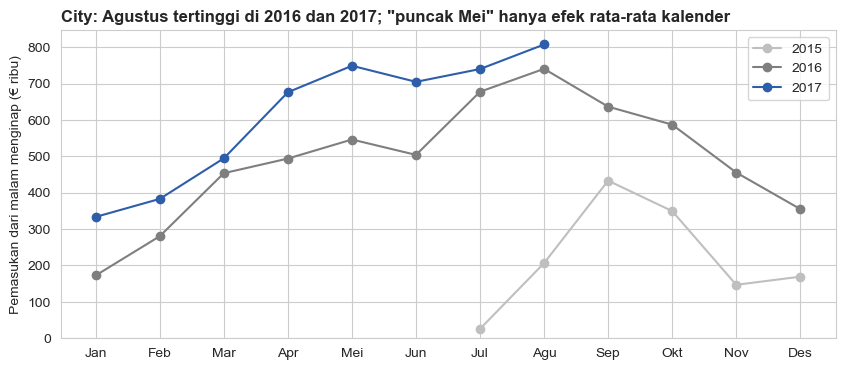

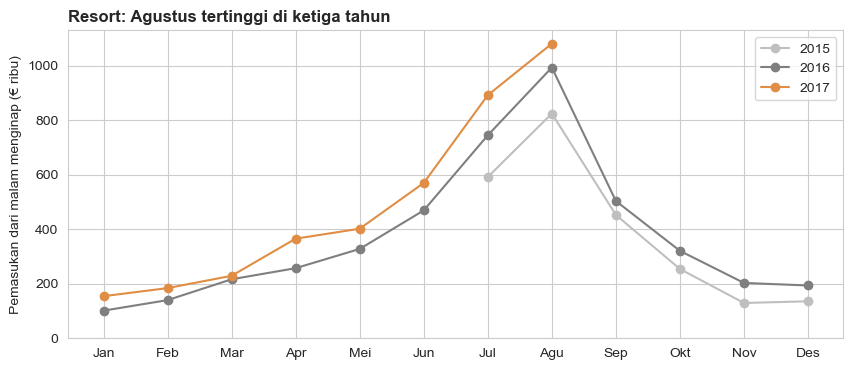

In [274]:
# pembanding: cara hitung lama (rata-rata per bulan kalender dari semua tahun) menunjuk bulan apa?
kalender = masuk.pivot_table(index='arrival_month', columns='hotel', values='revenue', aggfunc='sum')
for hotel in ['City Hotel', 'Resort Hotel']:
    kalender[hotel] = kalender[hotel] / jumlah_tahun
    print(f"{hotel}: rata-rata kalender menunjuk {label_bulan[kalender[hotel].idxmax() - 1]} sebagai bulan tertinggi")

for hotel in ['City Hotel', 'Resort Hotel']:
    warna_tahun = {2015: ABU, 2016: '#7F7F7F', 2017: WARNA_HOTEL[hotel]}
    plt.figure(figsize=(10, 4))
    for tahun in [2015, 2016, 2017]:
        plt.plot(label_bulan, bulan_tahun.loc[(hotel, tahun)], marker='o', color=warna_tahun[tahun], label=str(tahun))
    plt.title(judul[hotel], loc='left')
    plt.ylabel('Pemasukan dari malam menginap (€ ribu)'); plt.ylim(0)
    plt.legend()
    plt.show()

> Agustus tertinggi dan Januari terendah. Musim Resort jauh lebih tajam dari City

- Resort: Agustus tertinggi di ketiga tahun (€825 ribu, €994 ribu, €1,08 juta), Januari terendah (€101 ribu di 2016, sekitar sepersepuluh Agustus)
- City: Agustus tertinggi di 2016 (€740 ribu) dan 2017 (€807 ribu), Januari terendah (€173 ribu dan €334 ribu). City 2015 menunjuk September (€433 ribu), tetapi datanya didominasi duplikat
- "City memuncak di Mei" hanya efek cara hitung: Mei dirata-rata dari 2016 dan 2017, Agustus ikut menghitung 2015 yang tipis (€207 ribu)
- Agustus 2016 hampir 10 kali Januari di Resort, sekitar 4 kali di City. Alasannya tidak tercatat (festival musim panas di Algarve hanya dugaan). Yang terlihat: ADR Resort Agustus 2016 €191,9 (sekitar 4 kali Januari) dan porsi tamu keluarga naik jadi 16-20%

#### **5. Bulan × hari: malam tertinggi dan terendah di tiap bulan**
Grafik memakai indeks per bulan (1,0 = rata-rata malam di bulan itu), jadi warnanya hanya membandingkan malam di dalam bulan yang sama. Level tiap bulan ada di 4.J.4

City Hotel
    malam_tertinggi malam_terendah  rata2_per_malam  tertinggi/terendah  \
Jan             Rab            Min          8174.88                1.11   
Feb             Sab            Rab         11638.18                1.23   
Mar             Jum            Min         15261.27                1.15   
Apr             Kam            Min         19529.12                1.09   
Mei             Sab            Min         20899.47                1.10   
Jun             Sel            Min         20100.30                1.24   
Jul             Sen            Kam         15527.95                1.20   
Agu             Sel            Min         18833.86                1.17   
Sep             Sen            Rab         17853.64                1.20   
Okt             Sen            Sab         15169.46                1.22   
Nov             Rab            Min         10047.69                1.42   
Des             Sab            Sel          8442.96                1.44   

    kedatanga

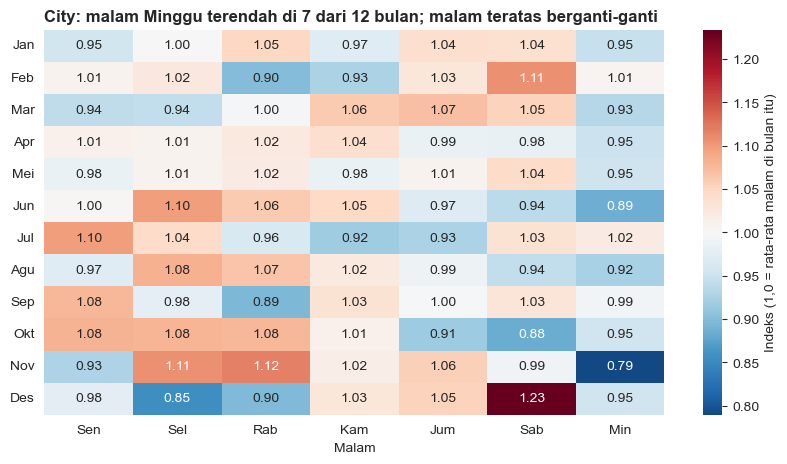

Resort Hotel
    malam_tertinggi malam_terendah  rata2_per_malam  tertinggi/terendah  \
Jan             Sab            Rab          4116.50                1.34   
Feb             Sab            Rab          5693.62                1.57   
Mar             Sab            Min          7176.87                1.29   
Apr             Sab            Sen         10349.78                1.18   
Mei             Rab            Min         11752.61                1.08   
Jun             Sab            Rab         17340.36                1.11   
Jul             Sel            Rab         23979.02                1.06   
Agu             Jum            Min         31204.95                1.08   
Sep             Kam            Min         15928.49                1.07   
Okt             Min            Kam          9266.19                1.10   
Nov             Sab            Min          5579.08                1.47   
Des             Sab            Sel          5290.63                1.71   

    kedatan

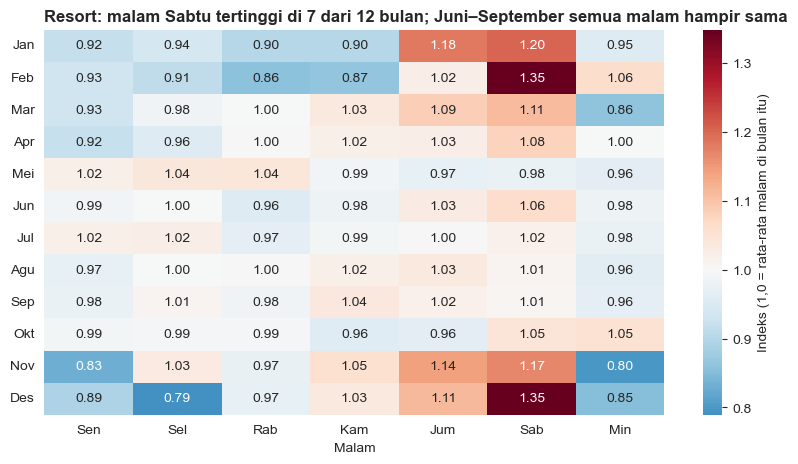

In [275]:
judul = {'City Hotel': 'City: malam Minggu terendah di 7 dari 12 bulan; malam teratas berganti-ganti',
         'Resort Hotel': 'Resort: malam Sabtu tertinggi di 7 dari 12 bulan; Juni–September semua malam hampir sama'}

# bulan x hari, per hotel: pemasukan per malam (utama) dan kedatangan per tanggal (pendamping)
for hotel in ['City Hotel', 'Resort Hotel']:
    m = per_malam_hotel[per_malam_hotel['hotel'] == hotel]
    malam_bh = m.pivot_table(index='bulan', columns='hari', values='pemasukan_malam', aggfunc='mean')[urutan_hari]
    malam_bh.columns = label_hari
    malam_bh.index = label_bulan
    d = harian[harian['hotel'] == hotel]
    datang_bh = d.pivot_table(index='bulan', columns='hari', values='kedatangan', aggfunc='mean')[urutan_hari]
    datang_bh.columns = label_hari
    datang_bh.index = label_bulan

    # idxmax(axis=1) / idxmin(axis=1) = nama kolom (hari) dengan nilai tertinggi / terendah di tiap baris (bulan)
    tabel = pd.DataFrame()
    tabel['malam_tertinggi'] = malam_bh.idxmax(axis=1)
    tabel['malam_terendah'] = malam_bh.idxmin(axis=1)
    tabel['rata2_per_malam'] = malam_bh.mean(axis=1)
    tabel['tertinggi/terendah'] = malam_bh.max(axis=1) / malam_bh.min(axis=1)
    tabel['kedatangan_tertinggi'] = datang_bh.idxmax(axis=1)
    tabel['kedatangan_terendah'] = datang_bh.idxmin(axis=1)
    print(hotel)
    print(tabel.round(2), '\n')

    # grafik memakai indeks per bulan (1,0 = rata-rata malam di bulan itu): bulan yang sama dari tahun berbeda
    # digabung di sini, jadi warna mentah antarbulan akan ikut campuran tahun (lihat 4.J.4 untuk level per bulan)
    indeks_bh = malam_bh.copy()
    for bulan in label_bulan:
        indeks_bh.loc[bulan] = malam_bh.loc[bulan] / malam_bh.loc[bulan].mean()
    plt.figure(figsize=(10, 5))
    sns.heatmap(indeks_bh, annot=True, fmt='.2f', cmap='RdBu_r', center=1,
                cbar_kws={'label': 'Indeks (1,0 = rata-rata malam di bulan itu)'})
    plt.title(judul[hotel], loc='left')
    plt.xlabel('Malam'); plt.ylabel('')
    plt.yticks(rotation=0)
    plt.show()

In [276]:
# Agustus, bulan dengan pemasukan tertinggi: apakah polanya sama di tiap tahun? (per hotel)
for hotel in ['City Hotel', 'Resort Hotel']:
    m = per_malam_hotel[(per_malam_hotel['hotel'] == hotel) & (per_malam_hotel['bulan'] == 8)]
    agustus_malam = m.pivot_table(index='tahun', columns='hari', values='pemasukan_malam', aggfunc='mean')[urutan_hari]
    agustus_malam.columns = label_hari
    d = harian[(harian['hotel'] == hotel) & (harian['bulan'] == 8)].copy()
    d['tahun'] = d['arrival_date'].dt.year
    agustus_datang = d.pivot_table(index='tahun', columns='hari', values='kedatangan', aggfunc='mean')[urutan_hari]
    agustus_datang.columns = label_hari
    print(hotel, '- Agustus, pemasukan per malam (€):')
    print(agustus_malam.round(0))
    print(hotel, '- Agustus, kedatangan per tanggal:')
    print(agustus_datang.round(1), '\n')

City Hotel - Agustus, pemasukan per malam (€):
           Sen      Sel      Rab      Kam      Jum      Sab      Min
tahun                                                               
2015    6770.0   7577.0   7552.0   7202.0   6514.0   6144.0   5328.0
2016   23795.0  24492.0  24139.0  22608.0  22616.0  24574.0  24736.0
2017   25854.0  26621.0  26010.0  26204.0  26750.0  25482.0  25167.0
City Hotel - Agustus, kedatangan per tanggal:
        Sen   Sel   Rab   Kam   Jum   Sab   Min
tahun                                          
2015   34.0  33.2  36.2  23.5  27.5  27.6  16.4
2016   69.6  56.2  57.8  54.8  60.5  63.0  66.8
2017   62.8  50.6  50.8  55.0  50.5  54.0  61.5 

Resort Hotel - Agustus, pemasukan per malam (€):
           Sen      Sel      Rab      Kam      Jum      Sab      Min
tahun                                                               
2015   26055.0  27677.0  27368.0  27343.0  27206.0  26592.0  24640.0
2016   31024.0  31015.0  30946.0  33406.0  33295.0  33154.0  323

> Pola hari berganti-ganti antarbulan. Di musim ramai (Resort Juni-September, Agustus di kedua hotel) semua malam hampir sama

- City: malam Minggu terendah di 7 dari 12 bulan, malam tertinggi berganti-ganti (Senin, Sabtu, atau Selasa). Dalam satu bulan, tertinggi 1,09-1,44 kali terendah, terbesar di November-Desember
- Resort: malam Sabtu tertinggi di 7 dari 12 bulan. Juni-September semua malam hampir sama (1,06-1,11 kali), sedangkan November-Februari selisihnya 1,34-1,71 kali
- Kedatangan: City paling ramai Senin di April-Oktober (7 bulan). Resort paling ramai Sabtu di 6 bulan dan Senin di Juli-September
- Agustus per tahun: pemasukan per malam hampir rata (City 2016 €22,6-24,7 ribu, 2017 €25,2-26,8 ribu, Resort 2016 €30,9-33,4 ribu, 2017 €34,2-36,4 ribu)

#### **6. Segmen: siapa tertinggi dan terendah, dan siapa yang mengisi kamar di tiap hari?**
Nilai segmen untuk kedua hotel ada di 4.G.1. Di sini dipisah per hotel: siapa yang mengisi kamar tiap malam (ukuran utama) dan siapa yang tiba tiap hari (pendamping). Indeks = porsi segmen malam itu ÷ porsinya di semua malam

City Hotel
                pemasukan  %_pemasukan  nilai_per_booking  adr_rata2  \
market_segment                                                         
Online TA       8145831.1         67.0              365.1      118.5   
Offline TA/TO   1673811.2         13.8              279.8       86.0   
Direct          1538751.9         12.7              332.6      120.8   
Groups           413406.2          3.4              238.7       86.1   
Corporate        307065.9          2.5              157.1       82.1   
Aviation          68968.4          0.6              381.0      100.6   
Complementary      2743.0          0.0                6.1        2.9   

                malam_rata2  
market_segment               
Online TA               3.1  
Offline TA/TO           3.3  
Direct                  2.7  
Groups                  2.7  
Corporate               1.8  
Aviation                3.7  
Complementary           1.5   

% kamar terisi per segmen, per malam:
                 Sen   Sel   R

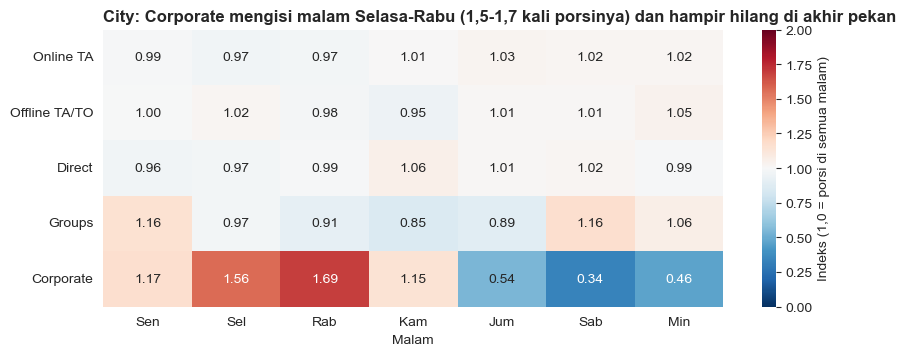

Resort Hotel
                pemasukan  %_pemasukan  nilai_per_booking  adr_rata2  \
market_segment                                                         
Online TA       4820593.5         44.6              438.4      107.5   
Offline TA/TO   2921644.9         27.0              502.3       74.3   
Direct          2386576.6         22.1              440.6      110.2   
Groups           509494.8          4.7              274.4       64.2   
Corporate        176662.9          1.6              101.8       49.6   
Complementary      2061.5          0.0               13.0        4.4   

                malam_rata2  
market_segment               
Online TA               3.8  
Offline TA/TO           6.3  
Direct                  3.4  
Groups                  4.3  
Corporate               2.0  
Complementary           2.2   

% kamar terisi per segmen, per malam:
                 Sen   Sel   Rab   Kam   Jum   Sab   Min  Semua malam
market_segment                                              

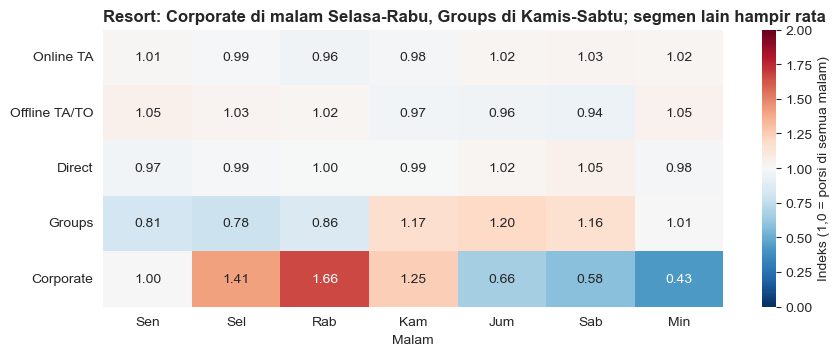

In [277]:
judul = {'City Hotel': 'City: Corporate mengisi malam Selasa-Rabu (1,5-1,7 kali porsinya) dan hampir hilang di akhir pekan',
         'Resort Hotel': 'Resort: Corporate di malam Selasa-Rabu, Groups di Kamis-Sabtu; segmen lain hampir rata'}

for hotel in ['City Hotel', 'Resort Hotel']:
    m = masuk[masuk['hotel'] == hotel]
    # tertinggi dan terendah per segmen (booking Check-Out)
    nilai_segmen = pd.DataFrame()
    nilai_segmen['pemasukan'] = m.groupby('market_segment')['revenue'].sum()
    nilai_segmen['%_pemasukan'] = nilai_segmen['pemasukan'] / nilai_segmen['pemasukan'].sum() * 100
    nilai_segmen['nilai_per_booking'] = m.groupby('market_segment')['revenue'].mean()
    nilai_segmen['adr_rata2'] = m.groupby('market_segment')['adr'].mean()
    nilai_segmen['malam_rata2'] = m.groupby('market_segment')['total_nights'].mean()
    print(hotel)
    print(nilai_segmen.sort_values('pemasukan', ascending=False).round(1), '\n')

    # siapa yang mengisi kamar tiap malam (porsi kamar terisi per segmen, tiap kolom 100%)
    md_hotel = malam_detail[malam_detail['hotel'] == hotel]
    segmen_malam = pd.crosstab(md_hotel['market_segment'], md_hotel['hari'], normalize='columns')[urutan_hari] * 100
    segmen_malam.columns = label_hari
    segmen_malam['Semua malam'] = md_hotel['market_segment'].value_counts(normalize=True) * 100
    segmen_malam = segmen_malam.loc[seg_utama]
    print('% kamar terisi per segmen, per malam:')
    print(segmen_malam.round(1), '\n')

    # siapa yang tiba tiap hari (porsi kedatangan per segmen)
    segmen_datang = pd.crosstab(m['market_segment'], m['arrival_weekday'], normalize='columns')[urutan_hari] * 100
    segmen_datang.columns = label_hari
    segmen_datang['Semua hari'] = m['market_segment'].value_counts(normalize=True) * 100
    print('% kedatangan per segmen, per hari:')
    print(segmen_datang.loc[seg_utama].round(1), '\n')

    # indeks 1,0 = porsi segmen itu di semua malam
    indeks_segmen = pd.DataFrame()
    for hari in label_hari:
        indeks_segmen[hari] = segmen_malam[hari] / segmen_malam['Semua malam']
    plt.figure(figsize=(10, 3.6))
    sns.heatmap(indeks_segmen, annot=True, fmt='.2f', cmap='RdBu_r', center=1, vmin=0, vmax=2,
                cbar_kws={'label': 'Indeks (1,0 = porsi di semua malam)'})
    plt.title(judul[hotel], loc='left')
    plt.xlabel('Malam'); plt.ylabel('')
    plt.show()

In [278]:
# tiap segmen: malam dengan pemasukan tertinggi dan terendah, dan hari kedatangan teramai dan tersepi, per hotel
for hotel in ['City Hotel', 'Resort Hotel']:
    md_hotel = malam_detail[malam_detail['hotel'] == hotel]
    per_malam_segmen = md_hotel.groupby(['market_segment', 'tanggal_inap'])['adr'].sum().reset_index()
    per_malam_segmen['hari'] = per_malam_segmen['tanggal_inap'].dt.day_name()
    rata_malam = per_malam_segmen.pivot_table(index='market_segment', columns='hari', values='adr', aggfunc='mean')[urutan_hari]
    rata_malam.columns = label_hari

    m = masuk[masuk['hotel'] == hotel]
    datang = m.pivot_table(index='market_segment', columns='arrival_weekday', values='revenue', aggfunc='count')[urutan_hari] / jumlah_tanggal
    datang.columns = label_hari

    puncak_segmen = pd.DataFrame()
    puncak_segmen['malam_tertinggi'] = rata_malam.loc[seg_utama].idxmax(axis=1)
    puncak_segmen['malam_terendah'] = rata_malam.loc[seg_utama].idxmin(axis=1)
    puncak_segmen['malam: tertinggi / terendah'] = rata_malam.loc[seg_utama].max(axis=1) / rata_malam.loc[seg_utama].min(axis=1)
    puncak_segmen['kedatangan_teramai'] = datang.loc[seg_utama].idxmax(axis=1)
    puncak_segmen['kedatangan_tersepi'] = datang.loc[seg_utama].idxmin(axis=1)
    puncak_segmen['kedatangan: teramai / tersepi'] = datang.loc[seg_utama].max(axis=1) / datang.loc[seg_utama].min(axis=1)
    print(hotel)
    print(puncak_segmen.round(2), '\n')

City Hotel
               malam_tertinggi malam_terendah  malam: tertinggi / terendah  \
market_segment                                                               
Online TA                  Jum            Min                         1.07   
Offline TA/TO              Sel            Kam                         1.11   
Direct                     Kam            Min                         1.15   
Groups                     Sen            Kam                         1.62   
Corporate                  Rab            Min                         3.06   

               kedatangan_teramai kedatangan_tersepi  \
market_segment                                         
Online TA                     Sen                Rab   
Offline TA/TO                 Jum                Rab   
Direct                        Kam                Sel   
Groups                        Sab                Sel   
Corporate                     Rab                Sab   

                kedatangan: teramai / tersepi  
m

**Online** TA terbesar di kedua hotel. Corporate nilainya paling kecil tetapi mengisi malam Selasa-Rabu

- City: Online TA 67,0% pemasukan (€8,15 juta), Offline TA/TO 13,8%, Direct 12,7%
- Resort: Online TA 44,6% (€4,82 juta), Offline TA/TO 27,0%, Direct 22,1%. Per booking yang menginap, Offline TA/TO tertinggi (€502) karena menginap 6,3 malam
- Setelah pembatalan dihitung (kedua hotel): Direct €333 dan Offline TA/TO €332 per booking yang dibuat, Online TA €252
- Corporate terendah per booking yang menginap (City €157, Resort €102). Ia mengisi malam Selasa-Rabu (City 5,1-5,5% kamar, Resort 4,6-5,4%, porsi normal 3,3%) dan hampir hilang di Sabtu-Minggu (1,1-1,9%)
- Groups di Resort mengisi malam Kamis-Sabtu (8,5-8,8% kamar, porsi normal 7,3%)

#### **7. Tipe kamar: paling laku, rata-rata, dan paling tidak laku di malam Senin**
"Laku" dihitung dari kamar terisi per malam menurut tipe kamar yang dipesan (reserved_room_type), dengan kedatangan per tanggal sebagai pendamping

Kode kamar disamarkan dan kedua hotel adalah properti berbeda, jadi tipe kamar selalu dibaca per hotel. Median ADR ditampilkan sebagai tingkat harga tiap tipe

City Hotel - kamar terisi per malam dan kedatangan per tanggal, per tipe kamar:
                    jumlah_booking  terisi_malam_Senin  \
reserved_room_type                                       
A                            27045              101.24   
D                             7068               29.16   
E                             1004                3.91   
F                             1076                3.70   
B                              676                2.83   
G                              362                1.27   
C                                8                0.02   

                    terisi_rata2_semua_malam  Senin / rata2  datang_per_Senin  \
reserved_room_type                                                              
A                                      98.05           1.03             40.88   
D                                      29.79           0.98              9.77   
E                                       3.99           0.98              

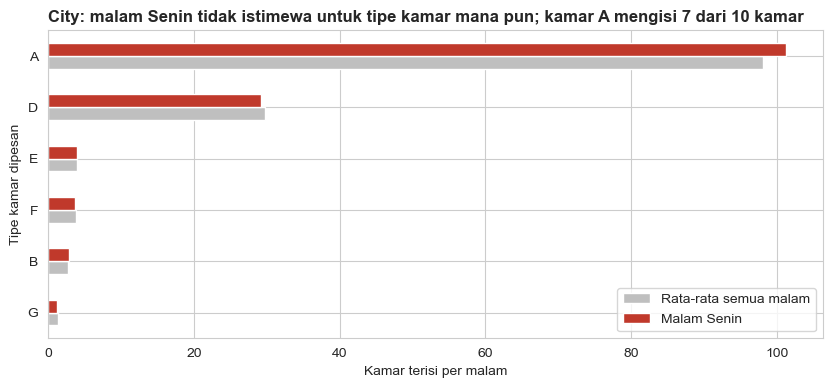

Resort Hotel - kamar terisi per malam dan kedatangan per tanggal, per tipe kamar:
                    jumlah_booking  terisi_malam_Senin  \
reserved_room_type                                       
A                            14708               66.39   
D                             5073               32.06   
E                             3386               21.55   
F                              893                4.86   
G                              951                4.80   
C                              610                3.30   
H                              353                1.34   
L                                4                0.01   
B                                3                0.00   

                    terisi_rata2_semua_malam  Senin / rata2  datang_per_Senin  \
reserved_room_type                                                              
A                                      67.71           0.98             21.99   
D                                   

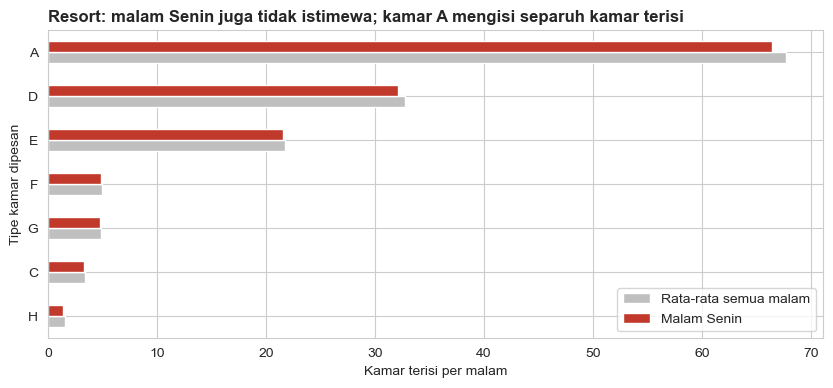

In [279]:
judul = {'City Hotel': 'City: malam Senin tidak istimewa untuk tipe kamar mana pun; kamar A mengisi 7 dari 10 kamar',
         'Resort Hotel': 'Resort: malam Senin juga tidak istimewa; kamar A mengisi separuh kamar terisi'}

# "laku" = kamar terisi per malam menurut tipe kamar yang dipesan (utama), ditambah kedatangan per tanggal (pendamping)
jumlah_malam = per_malam_hotel.groupby(['hotel', 'hari']).size()       # jumlah malam tiap hari di tiap hotel
for hotel in ['City Hotel', 'Resort Hotel']:
    md_hotel = malam_detail[malam_detail['hotel'] == hotel]
    kamar_malam = pd.crosstab(md_hotel['reserved_room_type'], md_hotel['hari'])[urutan_hari]
    for hari in urutan_hari:
        kamar_malam[hari] = kamar_malam[hari] / jumlah_malam[(hotel, hari)]
    kamar_malam.columns = label_hari

    m = masuk[masuk['hotel'] == hotel]
    kamar_datang = pd.crosstab(m['reserved_room_type'], m['arrival_weekday'])[urutan_hari] / jumlah_tanggal
    kamar_datang.columns = label_hari

    tabel_kamar = pd.DataFrame()
    tabel_kamar['jumlah_booking'] = m['reserved_room_type'].value_counts()
    tabel_kamar['terisi_malam_Senin'] = kamar_malam['Sen']
    tabel_kamar['terisi_rata2_semua_malam'] = kamar_malam.mean(axis=1)
    tabel_kamar['Senin / rata2'] = tabel_kamar['terisi_malam_Senin'] / tabel_kamar['terisi_rata2_semua_malam']
    tabel_kamar['datang_per_Senin'] = kamar_datang['Sen']
    tabel_kamar['median_adr'] = m.groupby('reserved_room_type')['adr'].median()
    tabel_kamar = tabel_kamar.sort_values('terisi_malam_Senin', ascending=False)
    print(hotel, '- kamar terisi per malam dan kedatangan per tanggal, per tipe kamar:')
    print(tabel_kamar.round(2), '\n')

    t = tabel_kamar[tabel_kamar['jumlah_booking'] >= 100].sort_values('terisi_malam_Senin')
    grafik = pd.DataFrame()
    grafik['Rata-rata semua malam'] = t['terisi_rata2_semua_malam']
    grafik['Malam Senin'] = t['terisi_malam_Senin']
    grafik.plot.barh(color=[ABU, SOROT], figsize=(10, 4))
    plt.title(judul[hotel], loc='left')
    plt.xlabel('Kamar terisi per malam'); plt.ylabel('Tipe kamar dipesan')
    plt.legend(loc='lower right')
    plt.show()

Pada tipe A (Standard) paling laku di kedua hotel. Malam Senin tidak istimewa untuk tipe kamar mana pun

- City, malam Senin: tipe A paling laku (101,2 kamar, rata-rata semua malam 98,1, sekitar 7 dari 10 kamar terisi), lalu D (29,2). Paling tidak laku G (1,3 kamar, median ADR tertinggi €219,7), tipe C hanya 8 booking selama 26 bulan
- Resort, malam Senin: tipe A paling laku (66,4 kamar, rata-rata 67,7, sekitar separuh), lalu D (32,1) dan E (21,6). Paling tidak laku H (1,3 kamar, median ADR €174), B dan L hampir tidak pernah dipesan
- Malam Senin 0,88-1,04 kali rata-rata semua malam. Tipe A bertarif rendah (median ADR €95 di City, €58,5 di Resort)
- "Tidak laku" berarti jarang dipesan tapi jumlah kamar per tipe tidak ada di dataset

#### **8. FM proxy pada tingkat booking: frequency dan monetary**

Dataset tidak punya `customer_id`, jadi tamu tidak bisa digabung dan FM dihitung per booking (FM proxy), bukan per tamu. Clustering tidak dijalankan

- **F** (frequency) = `previous_bookings_not_canceled`, riwayat booking sukses yang tercatat di booking ini. Dibagi dua (F = 0 dan F > 0) karena hampir semua booking tanpa riwayat
- **M** (monetary) = `adr × total_nights` booking Check-Out (belum termasuk pembayaran aktual, komisi, atau biaya). High-value = M di atas persentil ke-75 di hotel yang sama (batas kerja, bisa diganti), persentil dihitung per hotel karena harga dan lama menginap berbeda

In [280]:
# FM proxy dihitung dari booking Check-Out (masuk)
fm_booking = masuk.copy()
fm_booking['F_proxy'] = fm_booking['previous_bookings_not_canceled']     # F = booking sebelumnya yang tidak batal
fm_booking['M_proxy'] = fm_booking['revenue']                            # M = adr x total_nights booking ini

# batas high-value = persentil ke-75 nilai booking di hotel yang sama
cutoff_fm = fm_booking.groupby('hotel')['M_proxy'].quantile(0.75)
fm_booking['cutoff_high_value'] = fm_booking['hotel'].map(cutoff_fm)

# satu kolom True/False untuk tiap syarat
fm_booking['punya_riwayat_sukses'] = fm_booking['F_proxy'] > 0
fm_booking['high_value'] = fm_booking['M_proxy'] >= fm_booking['cutoff_high_value']

fm_booking['fm_segment'] = 'New standard'
fm_booking.loc[(fm_booking['punya_riwayat_sukses'] == False) & (fm_booking['high_value'] == True), 'fm_segment'] = 'New high-value'
fm_booking.loc[(fm_booking['punya_riwayat_sukses'] == True) & (fm_booking['high_value'] == False), 'fm_segment'] = 'Returning standard'
fm_booking.loc[(fm_booking['punya_riwayat_sukses'] == True) & (fm_booking['high_value'] == True), 'fm_segment'] = 'Returning high-value'

# Cek hasilnya
print('Jumlah baris fm_booking :', len(fm_booking), '| booking Check-Out :', len(masuk))
print('Nilai kosong            :', fm_booking[['F_proxy', 'M_proxy', 'cutoff_high_value', 'fm_segment']].isna().sum().sum())
print('M_proxy negatif         :', (fm_booking['M_proxy'] < 0).sum(), '\n')

print('Cut-off high-value per hotel (€):')
print(cutoff_fm.round(2), '\n')

Jumlah baris fm_booking : 63220 | booking Check-Out : 63220
Nilai kosong            : 0
M_proxy negatif         : 0 

Cut-off high-value per hotel (€):
hotel
City Hotel      426.72
Resort Hotel    578.41
Name: M_proxy, dtype: float64 



In [281]:
# Validasi silang: F proxy dibandingkan dengan penanda is_repeated_guest (semua booking)
df['F_group'] = np.where(df['previous_bookings_not_canceled'] > 0, 'F > 0', 'F = 0')
print('Validasi silang F proxy vs penanda repeated guest:')
print(pd.crosstab(df['F_group'], df['is_repeated_guest']), '\n')

cancel_f = df.groupby('F_group')['is_canceled'].agg(['count', 'mean'])
cancel_f.columns = ['jumlah_booking', 'cancel_rate']
cancel_f['cancel_rate'] = cancel_f['cancel_rate'] * 100
cancel_f['revenue_loss_rate'] = df.groupby('F_group')['revenue_hilang'].sum() / df.groupby('F_group')['revenue'].sum() * 100
print('Cancel rate berdasarkan riwayat booking sukses:')
print(cancel_f.round(1))

Validasi silang F proxy vs penanda repeated guest:
is_repeated_guest      0     1
F_group                       
F = 0              83122   569
F > 0                743  2794 

Cancel rate berdasarkan riwayat booking sukses:
         jumlah_booking  cancel_rate  revenue_loss_rate
F_group                                                
F = 0             83691         28.5               33.1
F > 0              3537          5.0                5.7


- Hanya sekitar 5% booking punya riwayat sukses, dan mereka jauh lebih jarang kehilangan nilai
- Batas high-value €426,72 (City) dan €578,41 (Resort)
- F > 0 kehilangan 5,7% nilai (cancel rate 5,0%), F = 0 kehilangan 33,1% (28,5%)
- **previous_bookings_not_canceled** dan **is_repeated_guest** searah tetapi tidak sama persis pada kolom riwayat yang dipakai dan **is_repeated_guest** hanya cek silang

Total booking_share_pct : 100.0
Total value_share_pct   : 100.0 

                      booking_check_out  booking_share_pct  estimated_value  \
fm_segment                                                                    
New standard                      44248               70.0        9933941.4   
New high-value                    15612               24.7       12460879.0   
Returning standard                 3165                5.0         333994.5   
Returning high-value                195                0.3         238797.0   

                      value_share_pct  nilai_rata2  nilai_median  adr_rata2  \
fm_segment                                                                    
New standard                     43.3        224.5         216.0       90.4   
New high-value                   54.3        798.2         675.8      143.3   
Returning standard                1.5        105.5          75.0       61.6   
Returning high-value              1.0       1224.6         927.5

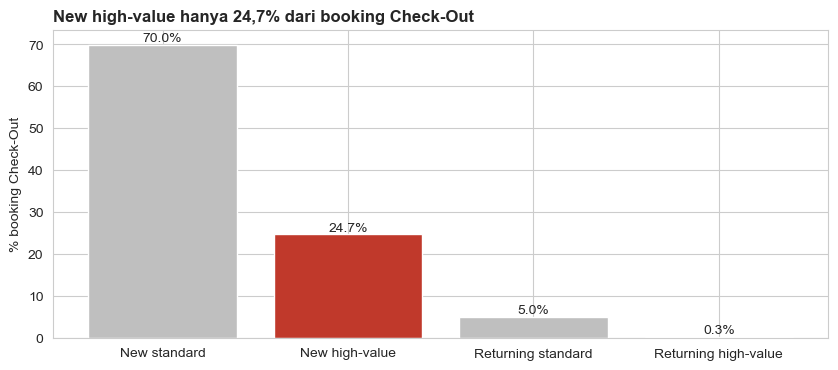

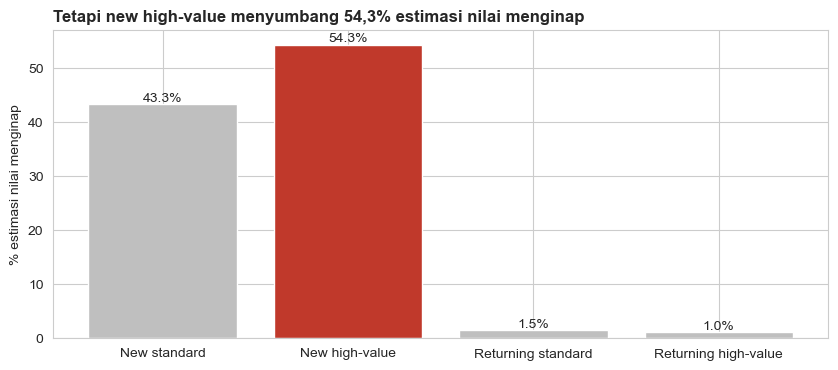

In [282]:
urutan_fm = ['New standard', 'New high-value', 'Returning standard', 'Returning high-value']

ringkasan_fm = fm_booking.groupby('fm_segment')['M_proxy'].agg(['count', 'sum', 'mean', 'median'])
ringkasan_fm.columns = ['booking_check_out', 'estimated_value', 'nilai_rata2', 'nilai_median']
ringkasan_fm['adr_rata2'] = fm_booking.groupby('fm_segment')['adr'].mean()
ringkasan_fm['malam_rata2'] = fm_booking.groupby('fm_segment')['total_nights'].mean()
ringkasan_fm = ringkasan_fm.loc[urutan_fm]
ringkasan_fm['booking_share_pct'] = ringkasan_fm['booking_check_out'] / len(fm_booking) * 100
ringkasan_fm['value_share_pct'] = ringkasan_fm['estimated_value'] / fm_booking['M_proxy'].sum() * 100

# Cek hasilnya: kedua porsi harus berjumlah 100
print('Total booking_share_pct :', round(ringkasan_fm['booking_share_pct'].sum(), 1))
print('Total value_share_pct   :', round(ringkasan_fm['value_share_pct'].sum(), 1), '\n')
print(ringkasan_fm[['booking_check_out', 'booking_share_pct', 'estimated_value', 'value_share_pct',
                    'nilai_rata2', 'nilai_median', 'adr_rata2', 'malam_rata2']].round(1))

warna_fm = [ABU, SOROT, ABU, ABU]          # new high-value diberi warna sorotan

bar = plt.bar(ringkasan_fm.index, ringkasan_fm['booking_share_pct'], color=warna_fm)
plt.bar_label(bar, fmt='%.1f%%')
plt.title('New high-value hanya 24,7% dari booking Check-Out', loc='left')
plt.ylabel('% booking Check-Out')
plt.show()

bar = plt.bar(ringkasan_fm.index, ringkasan_fm['value_share_pct'], color=warna_fm)
plt.bar_label(bar, fmt='%.1f%%')
plt.title('Tetapi new high-value menyumbang 54,3% estimasi nilai menginap', loc='left')
plt.ylabel('% estimasi nilai menginap')
plt.show()

Nilai terbesar ada di tamu baru bernilai tinggi. Tamu yang sering datang belum tentu memesan kamar paling mahal atau penyumbang revenue tertinggi

- New high-value hanya 24,7% booking Check-Out tetapi 54,3% estimasi nilai (rata-rata sekitar €798). Tamunya belum punya riwayat sukses, jadi ini kelompok utama untuk diubah menjadi hubungan langsung
- Returning high-value hanya 195 booking (0,3%) dan 1,0% nilai: terlalu kecil untuk kebijakan massal, cukup untuk uji coba pengenalan tamu
- Returning standard 5,0% booking tetapi 1,5% nilai
- "Tamu loyal" dan customer lifetime value belum bisa disimpulkan karena booking tidak bisa dihubungkan ke orang yang sama

In [283]:
fm_booking['returning_high'] = fm_booking['fm_segment'] == 'Returning high-value'

segment_fm = fm_booking.groupby('market_segment')['M_proxy'].agg(['count', 'sum', 'mean', 'median'])
segment_fm.columns = ['booking_check_out', 'estimated_value', 'nilai_rata2', 'nilai_median']
segment_fm['high_value_share'] = fm_booking.groupby('market_segment')['high_value'].mean() * 100
segment_fm['repeat_history_share'] = fm_booking.groupby('market_segment')['punya_riwayat_sukses'].mean() * 100
segment_fm['returning_high_share'] = fm_booking.groupby('market_segment')['returning_high'].mean() * 100
segment_fm = segment_fm.sort_values('estimated_value', ascending=False)
segment_fm['value_share'] = segment_fm['estimated_value'] / segment_fm['estimated_value'].sum() * 100
print(segment_fm.round(1), '\n')

                booking_check_out  estimated_value  nilai_rata2  nilai_median  \
market_segment                                                                  
Online TA                   33311       12966424.6        389.3         318.6   
Offline TA/TO               11798        4595456.1        389.5         289.7   
Direct                      10043        3925328.5        390.9         237.6   
Groups                       3589         922901.0        257.1         210.0   
Corporate                    3691         483728.8        131.1          85.0   
Aviation                      181          68968.4        381.0         285.0   
Complementary                 607           4804.5          7.9           0.0   

                high_value_share  repeat_history_share  returning_high_share  \
market_segment                                                                 
Online TA                   29.4                   1.5                   0.1   
Offline TA/TO               24

In [284]:
returning_high = fm_booking[fm_booking['fm_segment'] == 'Returning high-value']
returning_high_detail = returning_high.groupby(['hotel', 'market_segment'])['M_proxy'].agg(['count', 'sum', 'median'])
returning_high_detail.columns = ['booking_check_out', 'estimated_value', 'nilai_median']
returning_high_detail = returning_high_detail.sort_values('estimated_value', ascending=False)
print('Lokasi returning high-value:')
print(returning_high_detail.head(10).round(1))

Lokasi returning high-value:
                             booking_check_out  estimated_value  nilai_median
hotel        market_segment                                                  
Resort Hotel Direct                        102         152889.0        1227.1
             Online TA                      32          35409.3         903.0
             Offline TA/TO                  17          19939.1         961.6
City Hotel   Online TA                      14           9613.6         520.6
             Direct                         10           8353.2         622.5
             Aviation                       10           6562.0         457.5
             Corporate                       5           2740.0         520.0
Resort Hotel Groups                          3           1960.4         630.4
             Corporate                       2           1330.4         665.2


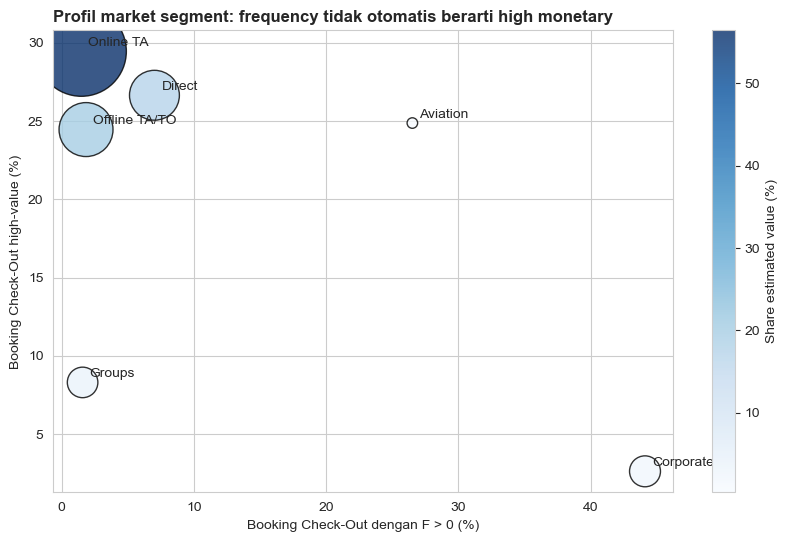

In [285]:
plot_segment = segment_fm[segment_fm.index != 'Complementary']
plt.figure(figsize=(10, 6))
plt.scatter(plot_segment['repeat_history_share'], plot_segment['high_value_share'],
            s=plot_segment['booking_check_out'] / 8 + 35,
            c=plot_segment['value_share'], cmap='Blues', edgecolor='black', alpha=0.8)
# nama segmen ditulis di samping titiknya
for nama in plot_segment.index:
    plt.annotate(nama, (plot_segment.loc[nama, 'repeat_history_share'], plot_segment.loc[nama, 'high_value_share']),
                 xytext=(5, 4), textcoords='offset points')
plt.xlabel('Booking Check-Out dengan F > 0 (%)')
plt.ylabel('Booking Check-Out high-value (%)')
plt.title('Profil market segment: frequency tidak otomatis berarti high monetary', loc='left')
plt.colorbar(label='Share estimated value (%)')
plt.show()

Online TA terbesar tetapi hampir tanpa hubungan langsung, Direct paling seimbang, Corporate sering datang tetapi nilainya kecil. Tindakan ini yang perlu diuji

- **Online TA:** 56,5% nilai, 29,4% high-value, riwayat sukses 1,5%. Uji: upgrade berbayar, paket makan, atau benefit Direct, hindari diskon menyeluruh
- **Direct:** 17,1% nilai, 26,6% high-value, riwayat sukses 7,0%. Uji: pengenalan tamu dan paket beberapa malam, terutama Resort
- **Corporate:** riwayat sukses 44,1% tetapi nilai rata-rata hanya €131 dan high-value 2,6%. Uji: kontrak perusahaan midweek tanpa benefit mahal
- **Offline TA/TO:** 20,0% nilai, 24,4% high-value, rata-rata €390, cancel rate 14,8%. Uji: pertahankan partner produktif, paket menginap panjang tanpa diskon massal
- **Groups:** 4,0% nilai, high-value 8,3%, cancel rate 27,1%. Pengisi volume, uji konfirmasi bertahap atau deposit di periode sepi
- **Aviation:** riwayat sukses 26,5%, hanya 181 Check-Out. Akun khusus dengan perjanjian layanan

Hasil ini deskriptif (63.220 booking Check-Out), dampak tindakan perlu diukur lewat uji coba.

#### **9. Polanya, dan artinya untuk hotel**

- **Malam:** pemasukan hampir rata (selisih 9-10%), mengikuti kamar terisi. Kedatangan: City ramai Senin, Resort Senin dan Sabtu
- **Bulan:** Agustus tertinggi di Resort tiap tahun dan di City 2016-2017, Januari terendah, musim Resort lebih tajam
- **Segmen:** Online TA terbesar setiap malam, Corporate mengisi Selasa-Rabu tetapi nilainya kecil, Groups mengisi Kamis-Sabtu di Resort, Offline TA/TO paling bernilai per booking di Resort. Kamar tipe A paling laku, malam Senin tidak istimewa
- **FM:** new high-value terbesar, Direct paling seimbang, Corporate tinggi di frequency tetapi rendah di monetary

### **K. Ringkasan sementara: apa artinya 4.B-4.J untuk rekomendasi?**

| Temuan | Penyesuaian rekomendasi |
|---|---|
| Segmen risiko tinggi bernilai lebih tinggi (€541 vs €357 per booking) | Deposit ringan |
| Satu aturan risiko untuk kedua hotel: Online TA, lead time > 90 hari (4.F.2) | Syarat deposit sama di kedua hotel, sepanjang tahun |
| Non Refund yang batal tetap membayar (€0,24 juta) | Tarif non-refundable melindungi revenue |
| 41,7% pembatalan dalam 7 hari setelah booking | Deposit ditarik mendekati kedatangan (H-30) |
| Special request menurunkan kehilangan, tetapi kolomnya baru lengkap belakangan | Dicek di H-30 sebagai uji coba |
| Offline TA/TO di Resort dan Direct di City paling bernilai | Tidak diperketat |
| Okupansi City 64,8%, Resort 74,4%, malam penuh hanya di musim ramai | Buffer overbooking hanya untuk malam penuh |
| €4,13 juta kamar batal jatuh di malam kosong, pembatalan merata di hari kerja | Pantau pickup sepanjang tahun, diperbarui tiap hari kerja |
| Kedatangan Jumat-Sabtu kehilangan paling besar | Prioritas di laporan pickup |
| Upgrade Resort berlawanan dengan okupansi (€345 ribu per tahun) | Upgrade berbayar di bulan sepi |
| Early-bird paling murah dan paling sering batal | Diskon hanya untuk non-refundable |
| Paskah, serta Tahun Baru dan Natal di Resort: ADR dan nilai hilang lebih tinggi | Tarif libur dengan syarat lebih ketat |
| Booking lebih dari 7 malam di luar segmen risiko: €1,12 juta | Lama menginap jadi syarat kedua deposit |
| Tamu solo Senin-Rabu jarang batal, keluarga Resort bernilai tinggi | Tarif korporat midweek dan paket keluarga |
| Enam dari tujuh agent besar lain hanya kehilangan 6-22% | Tolok ukur untuk agent 9 dan 240 |
| Hari booking dibuat dan tanggal kedatangan tidak berpengaruh | Tidak dipakai |
| Pemasukan per malam hampir rata, yang berbeda kedatangan | Jadwal staf check-in, harga khusus Senin tidak didukung data |
| Corporate tinggi di F, rendah di M | Akun stabil tanpa benefit |
| New high-value sekitar seperempat booking tetapi lebih dari separuh nilai, returning high-value hanya 195 | Tawaran tambahan di Online TA dan Direct, uji pengenalan tamu |
| Offline TA/TO 20,0% nilai, Groups 4,0% | Partner dijaga, Groups mengisi periode sepi |

4.L sampai 4.N menambah tiga pemeriksaan: peringkat kelompok (4.L), RFM agent dan perusahaan (4.M), dan uji statistik (4.N).

### **L. Peringkat dan kebiasaan kelompok tamu, bulan teramai, dan tanggal teramai** (pertanyaan I)
Bagian ini meranking kelompok tamu (negara, segmen, agent, customer type, tipe tamu, tier kamar), melihat kebiasaan segmen dan pilihan hotel dan kamar tiap negara, lalu bulan dan tanggal teramai. Tanpa ID tamu, yang diranking adalah kelompok, angka dari booking check-out, per hotel

#### **1. Negara asing teratas per tahun**
Bagian ini mencari negara asing yang paling banyak datang tiap tahun dan melihat apakah urutannya berubah. Negara dibaca dari booking check-out saja (4.D), tanpa Portugal dan Unknown

In [286]:
# Negara asing teratas per tahun: booking check-out saja (4.D), tanpa Portugal dan Unknown
asing = co[(co['country'] != 'PRT') & (co['country'] != 'Unknown')]

# Total per tahun. Tahunnya tidak setara: 2015 hanya Juli-Desember, 2017 hanya Januari-Agustus
for hotel in ['City Hotel', 'Resort Hotel']:
    x = asing[asing['hotel'] == hotel]
    for tahun in [2015, 2016, 2017]:
        top3 = x[x['arrival_date_year'] == tahun]['country'].value_counts().head(3)
        print(hotel, tahun, ':', top3.to_dict())
    print()

City Hotel 2015 : {'FRA': 714, 'ESP': 569, 'DEU': 262}
City Hotel 2016 : {'FRA': 3031, 'DEU': 1852, 'GBR': 1513}
City Hotel 2017 : {'FRA': 2109, 'GBR': 1494, 'DEU': 1420}

Resort Hotel 2015 : {'GBR': 891, 'ESP': 753, 'IRL': 349}
Resort Hotel 2016 : {'GBR': 2507, 'ESP': 1205, 'IRL': 766}
Resort Hotel 2017 : {'GBR': 1819, 'ESP': 765, 'IRL': 494}



In [287]:
# Januari-Agustus 2016 vs 2017: satu-satunya periode yang ada di kedua tahun
asing_jan_agu = asing[(asing['arrival_month'] <= 8) & (asing['arrival_date_year'].isin([2016, 2017]))]

for hotel in ['City Hotel', 'Resort Hotel']:
    x = asing_jan_agu[asing_jan_agu['hotel'] == hotel]
    tabel = pd.crosstab(x['country'], x['arrival_date_year'])
    tabel['porsi_2016_%'] = tabel[2016] / tabel[2016].sum() * 100
    tabel['porsi_2017_%'] = tabel[2017] / tabel[2017].sum() * 100
    tabel['tumbuh_%'] = (tabel[2017] / tabel[2016] - 1) * 100
    print(hotel, '- diurutkan dari check-out 2017')
    print(tabel.sort_values(2017, ascending=False).head(6).round(1), '\n')

City Hotel - diurutkan dari check-out 2017
arrival_date_year  2016  2017  porsi_2016_%  porsi_2017_%  tumbuh_%
country                                                            
FRA                2016  2109          21.4          18.8       4.6
GBR                 960  1494          10.2          13.3      55.6
DEU                1195  1420          12.7          12.7      18.8
ESP                 888   754           9.4           6.7     -15.1
BEL                 461   545           4.9           4.9      18.2
ITA                 530   521           5.6           4.6      -1.7 

Resort Hotel - diurutkan dari check-out 2017
arrival_date_year  2016  2017  porsi_2016_%  porsi_2017_%  tumbuh_%
country                                                            
GBR                1520  1819          31.1          33.2      19.7
ESP                 884   765          18.1          14.0     -13.5
IRL                 510   494          10.4           9.0      -3.1
FRA                 326   

In [288]:
# CHN di Resort: berapa yang berasal dari kode CN sebelum disatukan di 3.E?
# dihitung dari data mentah yang duplikatnya sudah dihapus, booking check-out Januari-Agustus
asli = df_raw.drop_duplicates()
bulan_jan_agu = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August']
kode_cn = asli[(asli['hotel'] == 'Resort Hotel') & (asli['is_canceled'] == 0) &
               (asli['country'].isin(['CN', 'CHN'])) & (asli['arrival_date_month'].isin(bulan_jan_agu)) &
               (asli['arrival_date_year'].isin([2016, 2017]))]
pd.crosstab(kode_cn['country'], kode_cn['arrival_date_year'])

arrival_date_year,2016,2017
country,,
CHN,31,34
CN,123,259


- Urutan pertama tidak berubah (City Prancis, Resort Inggris, di ketiga tahun). Inggris naik di kedua hotel dan Spanyol turun
- Pertumbuhan dibaca dari Januari-Agustus (2015 dan 2017 tidak lengkap)
- City: Inggris naik ke urutan 2 (960 ke 1.494, +55,6%), Jerman turun ke 3, Spanyol -15,1%
- Resort: porsi Inggris 31,1% ke 33,2%, Spanyol -13,5%, Jerman -12,9%
- CHN di Resort tumbuh 90,3%, tetapi dari kode CN (123 ke 259), kode CHN asli hanya 31 ke 34. Data tidak bisa memastikan CN adalah China (3.E)

#### **2. Peringkat kelompok dengan LRFM (adaptasi Modul D22)**
LRFM D22 diadaptasi ke kelompok, per hotel:

- **L**: rata-rata lama menginap dibanding rata-rata hotel (di D22: lama menjadi pelanggan)
- **R**: pertumbuhan check-out Januari-Agustus 2016 ke 2017
- **F**: porsi dari seluruh check-out hotel
- **M**: rata-rata ADR dibanding rata-rata hotel

| Skor | F: porsi check-out | L dan M: rasio ke rata-rata hotel | R: pertumbuhan |
|---|---|---|---|
| 5 | di atas 10% | di atas 1,15 | di atas +40% |
| 4 | 5-10% | 1,05-1,15 | +10% sampai +40% |
| 3 | 2-5% | 0,95-1,05 | -5% sampai +10% |
| 2 | 1-2% | 0,85-0,95 | -20% sampai -5% |
| 1 | di bawah 1% | di bawah 0,85 | di bawah -20% |

R = 3 mencakup pertumbuhan hotelnya sendiri (City +5,5%, Resort +1,9%). Hanya kelompok dengan minimal 100 check-out di Januari-Agustus 2016 yang dinilai. Cancel rate ditampilkan di samping skor untuk kolom selain negara

| Label | Syarat |
|---|---|
| Best | L, R, F, M semua 4 atau lebih |
| Potential | R dan F 4 atau lebih |
| New | R 4 atau lebih, F 3 atau kurang |
| At-Risk | R 2 atau kurang, F 3 atau lebih |
| Lost | R dan F 2 atau kurang |
| Stabil | sisanya |

In [289]:
def peringkat_kelompok(kolom, pakai_cancel=True):
    # LRFM per kelompok, dihitung terpisah untuk tiap hotel (definisi dan batas skor ada di tabel di atas)
    hasil = []
    for hotel in ['City Hotel', 'Resort Hotel']:
        semua = df[df['hotel'] == hotel]
        datang = semua[semua['is_canceled'] == 0]
        if kolom == 'country':
            datang = datang[datang['country'] != 'Unknown']

        # R: pertumbuhan check-out Januari-Agustus 2016 ke 2017
        jan_agu_datang = datang[(datang['arrival_month'] <= 8) & (datang['arrival_date_year'].isin([2016, 2017]))]
        tumbuh = jan_agu_datang.pivot_table(index=kolom, columns='arrival_date_year', values='adr',
                                            aggfunc='count', fill_value=0)
        tumbuh = tumbuh[tumbuh[2016] >= 100]          # minimal 100 check-out di Jan-Agu 2016, supaya % tumbuh stabil

        t = pd.DataFrame()
        t['check_out'] = datang.groupby(kolom)['adr'].count()
        t['porsi_%'] = t['check_out'] / len(datang) * 100
        t['malam_rata2'] = datang.groupby(kolom)['total_nights'].mean()
        t['adr_rata2'] = datang.groupby(kolom)['adr'].mean()
        t['nilai_total'] = datang.groupby(kolom)['revenue'].sum()
        t['porsi_revenue_%'] = t['nilai_total'] / datang['revenue'].sum() * 100        # porsi revenue masuk hotel
        t['tumbuh_%'] = (tumbuh[2017] / tumbuh[2016] - 1) * 100
        t = t[t['tumbuh_%'].notna()]                  # kelompok yang tidak lolos batas 100 check-out dibuang
        if pakai_cancel:
            t['revenue_loss_rate'] = semua.groupby(kolom)['revenue_hilang'].sum() / semua.groupby(kolom)['revenue'].sum() * 100
            t['cancel_rate'] = semua.groupby(kolom)['is_canceled'].mean() * 100

        # skor 1-5 dengan batas tetap (rule-based, D22); L dan M dibandingkan dengan rata-rata hotel itu
        t['F'] = pd.cut(t['porsi_%'], bins=[-1, 1, 2, 5, 10, 100], labels=[1, 2, 3, 4, 5]).astype(int)
        t['L'] = pd.cut(t['malam_rata2'] / datang['total_nights'].mean(), bins=[-1, 0.85, 0.95, 1.05, 1.15, 100],
                        labels=[1, 2, 3, 4, 5]).astype(int)
        t['M'] = pd.cut(t['adr_rata2'] / datang['adr'].mean(), bins=[-1, 0.85, 0.95, 1.05, 1.15, 100],
                        labels=[1, 2, 3, 4, 5]).astype(int)
        t['R'] = pd.cut(t['tumbuh_%'], bins=[-101, -20, -5, 10, 40, 100000], labels=[1, 2, 3, 4, 5]).astype(int)

        # skor total (D22): High 17-20, Medium 13-16, Low di bawah 13
        t['skor_total'] = t['L'] + t['R'] + t['F'] + t['M']
        t['kelas_total'] = pd.cut(t['skor_total'], bins=[0, 12, 16, 20], labels=['Low', 'Medium', 'High'])

        # label dari kombinasi skor (D22); aturan terakhir paling kuat
        t['label'] = 'Stabil'
        t.loc[(t['R'] >= 4) & (t['F'] <= 3), 'label'] = 'New'
        t.loc[(t['R'] >= 4) & (t['F'] >= 4), 'label'] = 'Potential'
        t.loc[(t['R'] <= 2) & (t['F'] >= 3), 'label'] = 'At-Risk'
        t.loc[(t['R'] <= 2) & (t['F'] <= 2), 'label'] = 'Lost'
        t.loc[(t['L'] >= 4) & (t['R'] >= 4) & (t['F'] >= 4) & (t['M'] >= 4), 'label'] = 'Best'

        t['hotel'] = hotel
        hasil.append(t.sort_values('nilai_total', ascending=False))
    return pd.concat(hasil)


pd.set_option('display.width', 200)          # supaya tabel lebar tidak terpotong
kolom_tampil = ['hotel', 'check_out', 'porsi_%', 'malam_rata2', 'adr_rata2', 'tumbuh_%', 'nilai_total', 'porsi_revenue_%',
                'L', 'R', 'F', 'M', 'skor_total', 'kelas_total', 'label']

# pembanding untuk skor R: pertumbuhan check-out seluruh hotel, Januari-Agustus 2016 ke 2017
datang_jan_agu = df[(df['is_canceled'] == 0) & (df['arrival_month'] <= 8) & (df['arrival_date_year'].isin([2016, 2017]))]
pertumbuhan_hotel = datang_jan_agu.pivot_table(index='hotel', columns='arrival_date_year', values='adr', aggfunc='count')
pertumbuhan_hotel['tumbuh_%'] = (pertumbuhan_hotel[2017] / pertumbuhan_hotel[2016] - 1) * 100
print(pertumbuhan_hotel.round(1))

arrival_date_year   2016   2017  tumbuh_%
hotel                                    
City Hotel         12542  13232       5.5
Resort Hotel        8140   8294       1.9


##### **a. Negara asal**
Negara tidak diberi cancel rate dan revenue loss rate (4.D). porsi_revenue_% = porsi revenue masuk hotel, skor F memakai porsi check-out

In [290]:
peringkat_negara = peringkat_kelompok('country', pakai_cancel=False)
print('Jumlah negara yang lolos batas:', peringkat_negara['hotel'].value_counts().to_dict())
print('Porsi check-out hotel yang tercakup (%):', peringkat_negara.groupby('hotel')['porsi_%'].sum().round(1).to_dict(), '\n')
print(peringkat_negara[kolom_tampil].round(1))

Jumlah negara yang lolos batas: {'City Hotel': 16, 'Resort Hotel': 10}
Porsi check-out hotel yang tercakup (%): {'City Hotel': 89.4, 'Resort Hotel': 88.8} 

                hotel  check_out  porsi_%  malam_rata2  adr_rata2  tumbuh_%  nilai_total  porsi_revenue_%  L  R  F  M  skor_total kelas_total      label
country                                                                                                                                                 
FRA        City Hotel       5854     15.7          3.4      111.8       4.6    2203334.6             18.1  4  3  5  3          15      Medium     Stabil
PRT        City Hotel       8248     22.2          2.2       92.1     -35.7    1722651.6             14.2  1  1  5  1           8         Low    At-Risk
DEU        City Hotel       3534      9.5          3.5      107.4      18.8    1292043.0             10.6  5  4  4  3          16      Medium  Potential
GBR        City Hotel       3222      8.7          3.2      113.2      55.6   

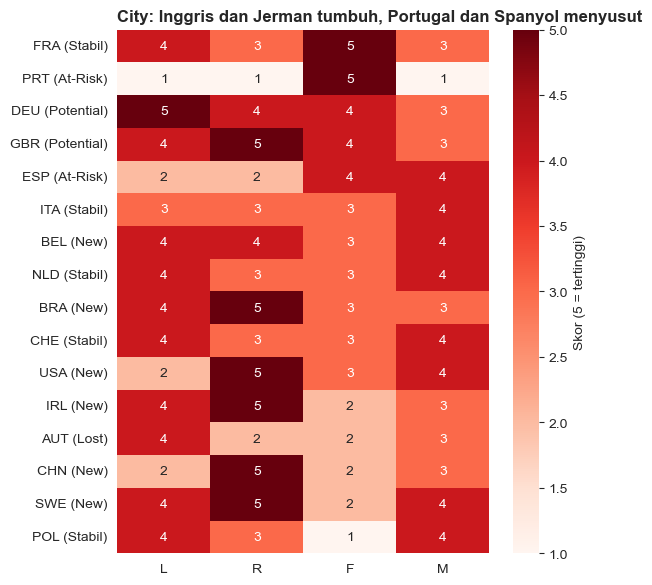

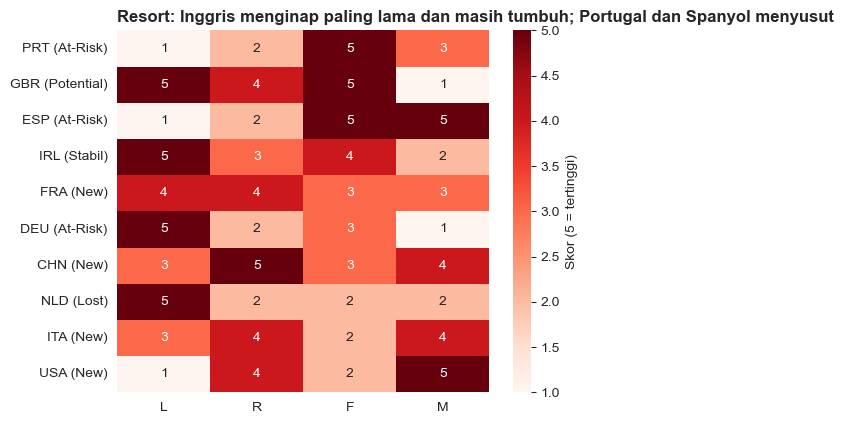

In [291]:
judul = {'City Hotel': 'City: Inggris dan Jerman tumbuh, Portugal dan Spanyol menyusut',
         'Resort Hotel': 'Resort: Inggris menginap paling lama dan masih tumbuh; Portugal dan Spanyol menyusut'}

for hotel in ['City Hotel', 'Resort Hotel']:
    tabel = peringkat_negara[peringkat_negara['hotel'] == hotel].copy()
    tabel['nama'] = tabel.index + ' (' + tabel['label'] + ')'      # contoh: 'FRA (At-Risk)'
    skor = tabel.set_index('nama')[['L', 'R', 'F', 'M']]

    plt.figure(figsize=(6, len(skor) * 0.35 + 1.2))
    sns.heatmap(skor, annot=True, fmt='d', cmap='Reds', vmin=1, vmax=5, cbar_kws={'label': 'Skor (5 = tertinggi)'})
    plt.title(judul[hotel], loc='left')
    plt.xlabel(''); plt.ylabel('')
    plt.show()

- Tidak ada negara Best. Portugal dan Spanyol menyusut serta Inggris dan Irlandia bertambah
- 16 negara di City dan 10 di Resort lolos batas (89,4% dan 88,8% check-out)
- Urutan revenue beda dari jumlah tamu: City Prancis 18,1% di atas Portugal 14,2% (walau Portugal paling banyak check-out, 22,2%), Resort Portugal 29,1%, Inggris 24,2%
- Di Resort, pasar yang menginap lama membayar lebih murah per malam: Inggris dan Irlandia (6,2-6,3 malam) ADR €78,7 dan €88,3, sedangkan Spanyol dan Amerika ADR €115,7 dan €129,8 tetapi hanya 3,2 dan 2,7 malam
- At-Risk: Portugal (City -35,7%, Resort -10,9%), Spanyol (-15,1%, -13,5%), Jerman di Resort (-12,9%). Potential: Inggris (City +55,6%, Resort +19,7%) dan Jerman di City (+18,8%). New: Irlandia (+87,7%), Brasil, Amerika, Swedia di City, Prancis dan Italia di Resort, CHN di Resort (+90,3%) dengan catatan kode CN
- Lama menginap dibaca per hotel, angka 5,11 malam Inggris di 4.I.5 datang dari porsi Resort (di City 3,2 malam)

##### **b. Market segment, agent, customer type, tipe tamu, dan tier kamar**
Fungsi yang sama dipakai untuk kolom lain, dengan cancel rate di kolom terakhir. Segmen Complementary (kamar gratis) tidak dibandingkan

In [292]:
peringkat_segmen = peringkat_kelompok('market_segment')
peringkat_segmen = peringkat_segmen[peringkat_segmen.index != 'Complementary']      # kamar gratis, tidak dibandingkan
print(peringkat_segmen[kolom_tampil + ['revenue_loss_rate', 'cancel_rate']].round(1))

                       hotel  check_out  porsi_%  malam_rata2  adr_rata2  tumbuh_%  nilai_total  porsi_revenue_%  L  R  F  M  skor_total kelas_total      label  revenue_loss_rate  cancel_rate
market_segment                                                                                                                                                                                 
Online TA         City Hotel      22314     59.9          3.1      118.5      10.7    8145831.1             67.0  3  4  5  4          16      Medium  Potential               40.7         36.1
Offline TA/TO     City Hotel       5982     16.1          3.3       86.0     -28.9    1673811.2             13.8  4  1  5  1          11         Low    At-Risk               13.8         17.4
Direct            City Hotel       4626     12.4          2.7      120.8      32.1    1538751.9             12.7  2  4  5  4          15      Medium  Potential               21.4         16.5
Groups            City Hotel       1732 

- Offline TA/TO menyusut di kedua hotel (City -28,9%, Resort -26,4%), At-Risk. Di Resort segmen ini 27,0% revenue masuk dan hanya kehilangan 13,6% nilai
- Corporate City At-Risk (-30,3%)
- Online TA (kedua hotel) dan Direct City Potential: Online TA +10,7% (City) dan +13,9% (Resort), Direct City +32,1%. Nilai hilang beda jauh: Online TA 40,7-43,4%, Direct City 21,4%
- Groups tumbuh (City +72,7%, Resort +27,0%), skor M = 1, nilai hilang kecil (13,2-14,0%) walau cancel rate City 33,9%

In [293]:
peringkat_agent = peringkat_kelompok('agent')            # agent 0 = booking tanpa agent
print('Jumlah agent yang lolos batas:', peringkat_agent['hotel'].value_counts().to_dict())
print('Porsi check-out hotel yang tercakup (%):', peringkat_agent.groupby('hotel')['porsi_%'].sum().round(1).to_dict(), '\n')
print(peringkat_agent[kolom_tampil + ['revenue_loss_rate', 'cancel_rate']].round(1))

Jumlah agent yang lolos batas: {'City Hotel': 14, 'Resort Hotel': 13}
Porsi check-out hotel yang tercakup (%): {'City Hotel': 88.3, 'Resort Hotel': 83.4} 

              hotel  check_out  porsi_%  malam_rata2  adr_rata2  tumbuh_%  nilai_total  porsi_revenue_%  L  R  F  M  skor_total kelas_total      label  revenue_loss_rate  cancel_rate
agent                                                                                                                                                                                 
9        City Hotel      17195     46.2          3.1      123.8       5.0    6497338.3             53.5  3  3  5  4          15      Medium     Stabil               44.1         40.1
14       City Hotel       2759      7.4          3.1      126.9      61.8    1089056.4              9.0  4  5  4  5          18        High       Best               22.3         17.4
7        City Hotel       2858      7.7          3.4       95.3      34.9     923266.2              7.6  5  4  4

Terlihat agent 9 dan 240 terbesar tetapi kehilangan nilai tertinggi. Agent 14, 241, 7, dan 250 jadi pembanding

- 14 agent di City dan 13 di Resort lolos batas (88,3% dan 83,4% check-out). Agent 0 = tanpa agent
- Agent 9 dan 240 Stabil: porsi terbesar (53,5% dan 32,3% revenue masuk), tumbuh di bawah hotelnya (+5,0% dan +0,6%), kehilangan nilai tertinggi (44,1% dan 48,1%)
- Best: agent 14 City (+61,8%, ADR €126,9, loss rate 22,3%) dan agent 241 Resort (+50,7%, 18,1%), Potential: agent 7 dan 250. Keempatnya jadi pembanding syarat kontrak agent 9 dan 240 (rekomendasi 3)
- Agent 40 Resort (New): +118,1%, menginap 8,5 malam, kehilangan 9,4%. Agent 1 (City, -92,3%), 11 (City, -98,8%), dan 115 (Resort, -96,8%) hampir berhenti kirim tamu, alasannya tidak tercatat
- Hanya agent dengan minimal 100 check-out di Januari-Agustus 2016 yang dinilai, RFM semua agent ada di 4.M

In [294]:
for kolom in ['customer_type', 'guest_type', 'room_tier']:
    print(kolom)
    print(peringkat_kelompok(kolom)[kolom_tampil + ['revenue_loss_rate', 'cancel_rate']].round(1), '\n')

customer_type


                        hotel  check_out  porsi_%  malam_rata2  adr_rata2  tumbuh_%  nilai_total  porsi_revenue_%  L  R  F  M  skor_total kelas_total      label  revenue_loss_rate  cancel_rate
customer_type                                                                                                                                                                                   
Transient          City Hotel      30058     80.7          3.0      111.5      16.8   10147824.0             83.5  3  4  5  3          15      Medium  Potential               36.8         32.5
Transient-Party    City Hotel       5837     15.7          2.8       94.7     -43.1    1576708.8             13.0  2  1  5  2          10         Low    At-Risk               14.6         16.8
Transient        Resort Hotel      20143     77.5          3.9       96.8      -6.0    8363919.8             77.3  2  2  5  3          12         Low    At-Risk               34.8         26.3
Transient-Party  Resort Hotel      

                       hotel  check_out  porsi_%  malam_rata2  adr_rata2  tumbuh_%  nilai_total  porsi_revenue_%  L  R  F  M  skor_total kelas_total    label  revenue_loss_rate  cancel_rate
guest_type                                                                                                                                                                                   
Pasangan          City Hotel      23037     61.9          3.2      103.8       8.1    7511800.7             61.8  4  3  5  3          15      Medium   Stabil               32.7         31.1
Solo              City Hotel       7913     21.2          2.3       91.0       2.9    1698717.6             14.0  1  3  5  1          10         Low   Stabil               29.0         22.2
Keluarga          City Hotel       3480      9.3          3.1      147.0      -0.4    1559782.4             12.8  3  3  4  5          15      Medium   Stabil               39.9         33.5
Grup 3+ dewasa    City Hotel       2809      7.5  

                     hotel  check_out  porsi_%  malam_rata2  adr_rata2  tumbuh_%  nilai_total  porsi_revenue_%  L  R  F  M  skor_total kelas_total    label  revenue_loss_rate  cancel_rate
room_tier                                                                                                                                                                                  
Standard        City Hotel      27721     74.4          2.9       97.7      -0.1    7828911.2             64.4  3  3  5  2          13      Medium   Stabil               30.9         28.6
Deluxe          City Hotel       7076     19.0          3.4      129.1      14.2    3021628.2             24.9  4  4  5  5          18        High     Best               38.8         34.2
Presidential    City Hotel       1438      3.9          2.9      187.9      19.4     807929.3              6.6  3  4  3  5          15      Medium      New               43.7         35.5
Suite           City Hotel       1004      2.7          3.2 

Berdasarkan data di atas:
- **Customer type:** Transient-Party di City turun 43,1% (At-Risk). Di Resort sebaliknya, Transient-Party (+31,9%) dan Contract (+37,1%) tumbuh, sedangkan Transient turun 6,0% (At-Risk). Contract di Resort menginap rata-rata 8,5 malam dan hanya kehilangan 9,5% nilai (cancel rate 8,6%)
- **Tipe tamu:** hampir semuanya Stabil, jadi komposisi tamu tidak banyak berubah antartahun. Hanya Grup 3+ dewasa di Resort yang menyusut (-10,8%)
- **Tier kamar:** di City, Deluxe berlabel Best dan Suite tumbuh 90,7% (New). Di Resort, Suite berlabel Best (+15,1%) dan Deluxe Stabil, sedangkan Presidential menyusut (-5,8%, At-Risk). Kamar yang lebih mahal di City juga kehilangan lebih banyak nilai (Deluxe 38,8% vs Standard 30,9%), dan Presidential tertinggi di kedua hotel (43,7% dan 48,9%), jadi label Best tidak berarti risikonya kecil

#### **3. Tindakan per label**
- **Best** (agent 14, agent 241, Deluxe City): jaga alokasi dan kontrak, jadikan tolok ukur (rekomendasi 3)
- **Potential** (Inggris, Online TA, Direct City, agent 7 dan 250): tambah nilai per booking lewat upgrade atau paket makan, tanpa diskon menyeluruh (rekomendasi 6 dan 7)
- **New** (Irlandia, Brasil, Amerika di City, Prancis, Italia di Resort, agent 40): bawa tamu kembali lewat promosi per negara di bulan puncak
- **At-Risk** (Portugal, Spanyol, Offline TA/TO, Corporate City, agent 1): ditinjau bersama Sales tiap bulan
- **Lost** (agent 11, 27, 115, Austria di City, Belanda di Resort): tanyakan penyebabnya ke Sales sebelum kamar dialokasikan ulang

#### **4. Kebiasaan tiap market segment**
Untuk tiap segmen dicari kategori terbanyak (modus) dan paling khas (porsi tertinggi dibanding semua booking hotel itu, minimal 10% di segmen) pada sembilan variabel. Data: booking check-out, bulan dari 2016 saja karena hanya tahun itu yang lengkap

In [295]:
# nama bulan dan hari dalam bahasa Indonesia untuk tabel
nama_bulan = {}
for b in range(1, 13):
    nama_bulan[b] = label_bulan[b - 1]
nama_hari = {}
for i in range(7):
    nama_hari[urutan_hari[i]] = label_hari[i]


def kebiasaan(data, kolom_kelompok, daftar_kelompok, variabel):
    # untuk tiap kelompok (baris) dan tiap variabel (kolom):
    # - modus       = kategori yang paling sering muncul di kelompok itu
    # - paling khas = kategori yang porsinya paling tinggi dibanding porsinya di semua booking hotel itu,
    #                 hanya kategori yang minimal 10% di kelompok itu supaya kategori kecil tidak terpilih
    modus = pd.DataFrame(index=daftar_kelompok)
    khas = pd.DataFrame(index=daftar_kelompok)
    for v in variabel:
        porsi_semua = data[v].value_counts(normalize=True)
        isi_modus = []
        isi_khas = []
        for k in daftar_kelompok:
            porsi = data[data[kolom_kelompok] == k][v].value_counts(normalize=True)
            isi_modus.append(f"{porsi.idxmax()} ({porsi.max() * 100:.0f}%)")
            indeks = porsi / porsi_semua.loc[porsi.index]
            indeks = indeks[porsi >= 0.10]
            terkhas = indeks.idxmax()
            isi_khas.append(f"{terkhas} ({porsi.loc[terkhas] * 100:.0f}% vs {porsi_semua.loc[terkhas] * 100:.0f}%)")
        modus[v] = isi_modus
        khas[v] = isi_khas
    return modus, khas

In [296]:
seg_utama = ['Online TA', 'Offline TA/TO', 'Direct', 'Groups', 'Corporate']
variabel = ['bulan_2016', 'hari', 'reserved_room_type', 'room_tier', 'meal', 'guest_type', 'country', 'stay_type', 'lead_bin']

profil_tamu = co.copy()                     # booking check-out (4.A.8)
profil_tamu['hari'] = profil_tamu['arrival_weekday'].map(nama_hari)
profil_tamu['bulan_2016'] = profil_tamu['arrival_month'].map(nama_bulan)
profil_tamu.loc[profil_tamu['arrival_date_year'] != 2016, 'bulan_2016'] = np.nan     # bulan dibaca dari 2016 saja (tahun lengkap)

for hotel in ['City Hotel', 'Resort Hotel']:
    data_hotel = profil_tamu[profil_tamu['hotel'] == hotel]
    modus, khas = kebiasaan(data_hotel, 'market_segment', seg_utama, variabel)
    print(hotel, '- kategori terbanyak (modus)')
    print(modus.to_string(), '\n')
    print(hotel, '- kategori paling khas (porsi di segmen vs porsi di semua booking hotel)')
    print(khas.to_string(), '\n')

City Hotel - kategori terbanyak (modus)
              bulan_2016       hari reserved_room_type       room_tier      meal      guest_type    country           stay_type     lead_bin
Online TA      Agu (12%)  Sen (16%)            A (68%)  Standard (70%)  BB (72%)  Pasangan (67%)  FRA (16%)      Campuran (50%)  31-90 (30%)
Offline TA/TO  Jun (12%)  Jum (18%)            A (86%)  Standard (87%)  BB (83%)  Pasangan (67%)  PRT (23%)      Campuran (56%)  31-90 (32%)
Direct         Agu (12%)  Kam (16%)            A (63%)  Standard (67%)  BB (90%)  Pasangan (59%)  PRT (31%)  Weekday saja (49%)    0-7 (42%)
Groups         Nov (21%)  Sab (22%)            A (97%)  Standard (97%)  BB (87%)      Solo (50%)  PRT (32%)      Campuran (52%)  31-90 (30%)
Corporate      Mei (12%)  Rab (24%)            A (89%)  Standard (89%)  BB (99%)      Solo (82%)  PRT (72%)  Weekday saja (65%)    0-7 (59%) 

City Hotel - kategori paling khas (porsi di segmen vs porsi di semua booking hotel)
                     bulan_2

Resort Hotel - kategori terbanyak (modus)
              bulan_2016       hari reserved_room_type       room_tier      meal      guest_type    country           stay_type       lead_bin
Online TA      Agu (11%)  Sab (18%)            A (52%)  Standard (52%)  BB (84%)  Pasangan (74%)  PRT (29%)      Campuran (55%)      0-7 (28%)
Offline TA/TO  Jun (12%)  Kam (17%)            A (57%)  Standard (57%)  BB (68%)  Pasangan (77%)  GBR (40%)      Campuran (78%)   91-180 (28%)
Direct         Agu (10%)  Sab (18%)            A (45%)  Standard (45%)  BB (83%)  Pasangan (64%)  PRT (55%)  Weekday saja (46%)      0-7 (50%)
Groups         Okt (32%)  Kam (26%)            A (78%)  Standard (78%)  BB (58%)  Pasangan (62%)  GBR (41%)      Campuran (61%)  181-365 (40%)
Corporate      Apr (13%)  Rab (26%)            A (94%)  Standard (94%)  BB (96%)      Solo (81%)  PRT (77%)  Weekday saja (68%)      0-7 (67%) 

Resort Hotel - kategori paling khas (porsi di segmen vs porsi di semua booking hotel)
            

In [297]:
# ciri angka tiap segmen per hotel (lead time, lama menginap, harga, request, repeat, parkir dari booking check-out)
angka_segmen = pd.DataFrame()
for hotel in ['City Hotel', 'Resort Hotel']:
    semua = df[(df['hotel'] == hotel) & (df['market_segment'].isin(seg_utama))]
    datang = semua[semua['is_canceled'] == 0]
    t = pd.DataFrame()
    t['median_lead_time'] = datang.groupby('market_segment')['lead_time'].median()
    t['malam_rata2'] = datang.groupby('market_segment')['total_nights'].mean()
    t['adr_rata2'] = datang.groupby('market_segment')['adr'].mean()
    t['request_rata2'] = datang.groupby('market_segment')['total_of_special_requests'].mean()
    t['%_repeat'] = datang.groupby('market_segment')['is_repeated_guest'].mean() * 100
    t['%_minta_parkir'] = datang.groupby('market_segment')['required_car_parking_spaces'].apply(lambda x: (x > 0).mean() * 100)
    t['revenue_loss_rate'] = semua.groupby('market_segment')['revenue_hilang'].sum() / semua.groupby('market_segment')['revenue'].sum() * 100
    t['cancel_rate'] = semua.groupby('market_segment')['is_canceled'].mean() * 100
    t['hotel'] = hotel
    angka_segmen = pd.concat([angka_segmen, t])
print(angka_segmen.round(1))

                median_lead_time  malam_rata2  adr_rata2  request_rata2  %_repeat  %_minta_parkir  revenue_loss_rate  cancel_rate         hotel
market_segment                                                                                                                                 
Corporate                    6.0          1.8       82.1            0.4      42.5            13.7               11.9         11.9    City Hotel
Direct                      14.0          2.7      120.8            0.6       3.3             8.9               21.4         16.5    City Hotel
Groups                      61.0          2.7       86.1            0.3       0.3             0.2               13.2         33.9    City Hotel
Offline TA/TO               64.0          3.3       86.0            0.3       1.4             0.8               13.8         17.4    City Hotel
Online TA                   46.0          3.1      118.5            1.1       0.7             5.0               40.7         36.1    Cit

City Hotel - booking check-out 2016 per bulan
arrival_month    1    2    3     4    5    6     7     8     9     10   11   12
market_segment                                                                 
Online TA       390  689  981  1146  993  979  1221  1366  1066  1088  911  777
Offline TA/TO   191  247  347   227  274  391   244   236   356   375  203  203
Direct          118  189  165   148  175  159   215   240   183   164  145  138
Groups           14   10   70    49   85   47    24     5    75    36  110    1
Corporate        79  131  130    59  134   71    83    40    99    94  116   82 



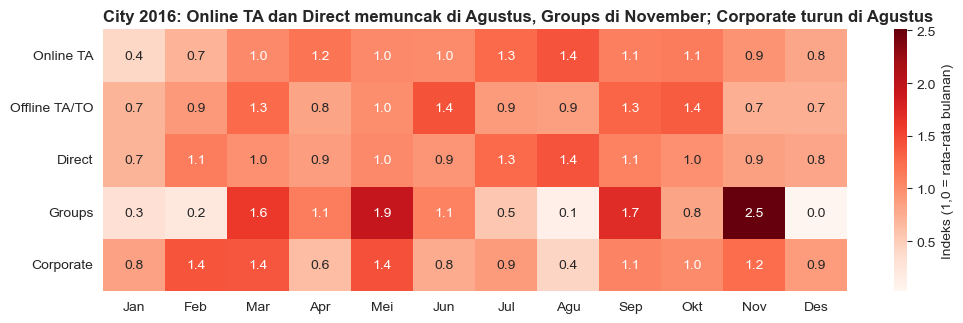

Resort Hotel - booking check-out 2016 per bulan
arrival_month    1    2    3    4    5    6    7    8    9    10   11   12
market_segment                                                            
Online TA       285  352  483  378  433  383  440  579  365  417  495  446
Offline TA/TO   142  246  292  241  288  339  273  226  248  190  197  117
Direct          214  254  240  237  165  157  205  262  178  222  163  200
Groups            9   28  115  125  168    9    6    0  132  320   29   55
Corporate        76  102   91  103   80   43   24    7   35   67   88   67 



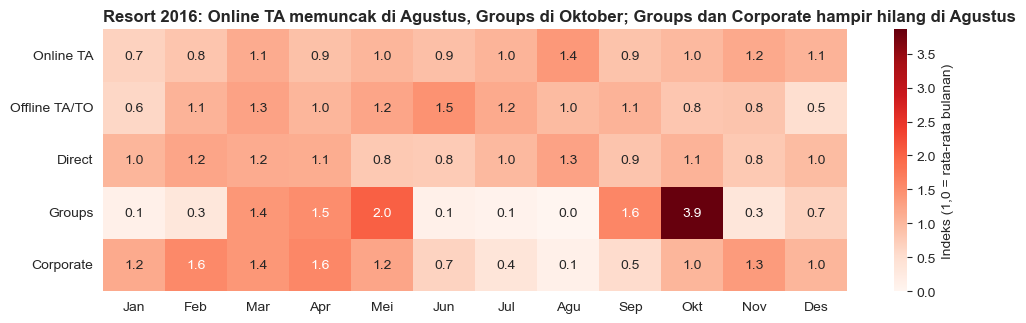

In [298]:
judul = {'City Hotel': 'City 2016: Online TA dan Direct memuncak di Agustus, Groups di November; Corporate turun di Agustus',
         'Resort Hotel': 'Resort 2016: Online TA memuncak di Agustus, Groups di Oktober; Groups dan Corporate hampir hilang di Agustus'}

# bulan kedatangan tiap segmen di 2016; indeks 1,0 = rata-rata bulanan segmen itu (cara yang sama dengan 4.E.3)
for hotel in ['City Hotel', 'Resort Hotel']:
    x = profil_tamu[(profil_tamu['hotel'] == hotel) & (profil_tamu['arrival_date_year'] == 2016) &
                    (profil_tamu['market_segment'].isin(seg_utama))]
    per_bulan = x.pivot_table(index='market_segment', columns='arrival_month', values='adr', aggfunc='count', fill_value=0)
    per_bulan = per_bulan.loc[seg_utama]
    rata_segmen = per_bulan.mean(axis=1)
    indeks = pd.DataFrame()
    for b in per_bulan.columns:
        indeks[label_bulan[b - 1]] = per_bulan[b] / rata_segmen
    print(hotel, '- booking check-out 2016 per bulan')
    print(per_bulan, '\n')

    plt.figure(figsize=(12, 3.4))
    sns.heatmap(indeks, annot=True, fmt='.1f', cmap='Reds', cbar_kws={'label': 'Indeks (1,0 = rata-rata bulanan)'})
    plt.title(judul[hotel], loc='left')
    plt.xlabel(''); plt.ylabel('')
    plt.show()

- Semua segmen paling banyak memesan kamar A (Standard)
- **Corporate:** tamu bisnis domestik, 82% (City) dan 81% (Resort) solo, 72% dan 77% dari Portugal, 59% dan 67% dipesan 0-7 hari sebelumnya, 65% dan 68% hanya hari kerja. Paling banyak tiba Selasa-Rabu, hampir tidak datang di Agustus (indeks 0,4 dan 0,1)
- **Groups:** puncak November di City (indeks 2,5) dan Oktober di Resort (3,9), hampir nol di Agustus. Dipesan jauh hari (Resort: median 165 hari) dan hampir semua kamar A
- **Offline TA/TO:** tamu Eropa menginap lama. Di Resort 40% dari Inggris, 6,3 malam, 27% Half Board, di City lebih banyak Jerman (15% vs 9%). Puncak Juni
- **Direct:** sering mendadak (42% City, 50% Resort dipesan 0-7 hari sebelumnya), banyak tamu Portugal (31% dan 55%) dan keluarga, di Resort 30,7% minta parkir
- **Online TA:** paling mirip rata-rata hotel, memuncak di Agustus (indeks 1,4), request terbanyak (1,1 per booking)

#### **5. Negara: hotel dan tipe kamar yang dipilih**
Dua belas negara dengan check-out terbanyak: hotel dan tipe kamar yang dipilih (per hotel, karena huruf kamar berbeda artinya)

In [299]:
# 12 negara dengan booking check-out terbanyak (tanpa Unknown); negara dibaca dari booking check-out (4.D)
top_negara = list(co[co['country'] != 'Unknown']['country'].value_counts().head(12).index)
negara_datang = co[co['country'].isin(top_negara)]

pilih_hotel = pd.crosstab(negara_datang['country'], negara_datang['hotel'], normalize='index') * 100
pilih_hotel['check_out'] = negara_datang['country'].value_counts()
pilih_hotel = pilih_hotel.sort_values('Resort Hotel')
print(pilih_hotel.round(1))
print(f"Pembanding, semua negara: Resort {(co['hotel'] == 'Resort Hotel').mean() * 100:.1f}%")

hotel    City Hotel  Resort Hotel  check_out
country                                     
FRA            82.6          17.4       7091
ITA            82.5          17.5       1986
DEU            81.6          18.4       4332
BEL            79.2          20.8       1670
BRA            75.1          24.9       1266
NLD            72.5          27.5       1560
USA            72.2          27.8       1412
CHN            52.2          47.8       1292
ESP            49.4          50.6       5382
PRT            46.9          53.1      17573
GBR            38.2          61.8       8439
IRL            31.4          68.6       2347
Pembanding, semua negara: Resort 41.1%


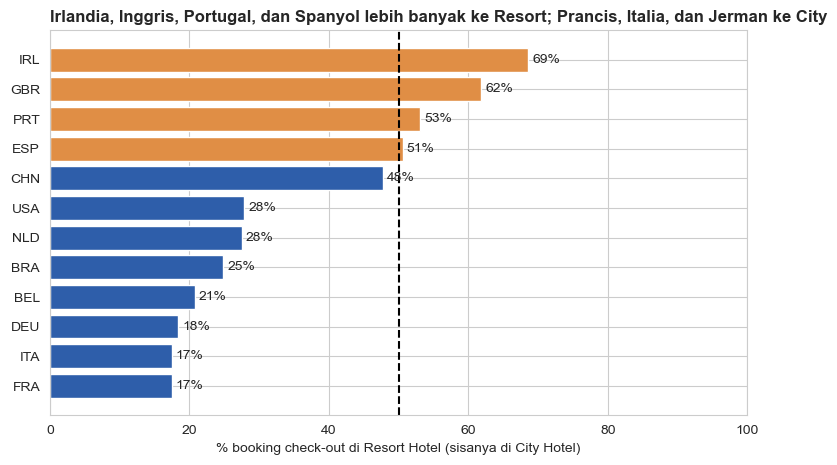

In [300]:
warna = np.where(pilih_hotel['Resort Hotel'] > 50, WARNA_HOTEL['Resort Hotel'], WARNA_HOTEL['City Hotel'])
plt.figure(figsize=(9, 5))
bar = plt.barh(pilih_hotel.index, pilih_hotel['Resort Hotel'], color=warna)
plt.bar_label(bar, fmt='%.0f%%', padding=3)
plt.axvline(50, color='black', linestyle='--')
plt.xlim(0, 100)
plt.title('Irlandia, Inggris, Portugal, dan Spanyol lebih banyak ke Resort; Prancis, Italia, dan Jerman ke City', loc='left')
plt.xlabel('% booking check-out di Resort Hotel (sisanya di City Hotel)')
plt.show()

In [301]:
# tipe kamar per negara, dipisah per hotel karena huruf tipe kamar berarti kamar yang berbeda di tiap hotel
for hotel in ['City Hotel', 'Resort Hotel']:
    data_hotel = co[co['hotel'] == hotel]
    modus, khas = kebiasaan(data_hotel, 'country', top_negara, ['reserved_room_type', 'room_tier'])
    tabel_kamar = pd.DataFrame()
    tabel_kamar['terbanyak_huruf'] = modus['reserved_room_type']
    tabel_kamar['terbanyak_tier'] = modus['room_tier']
    tabel_kamar['paling_khas_huruf'] = khas['reserved_room_type']
    tabel_kamar['paling_khas_tier'] = khas['room_tier']
    print(hotel)
    print(tabel_kamar.to_string(), '\n')

City Hotel
    terbanyak_huruf  terbanyak_tier paling_khas_huruf       paling_khas_tier
PRT         A (79%)  Standard (81%)    A (79% vs 73%)  Standard (81% vs 74%)
GBR         A (68%)  Standard (70%)    D (22% vs 19%)    Deluxe (22% vs 19%)
FRA         A (71%)  Standard (72%)    D (22% vs 19%)    Deluxe (22% vs 19%)
ESP         A (73%)  Standard (75%)    A (73% vs 73%)  Standard (75% vs 74%)
DEU         A (74%)  Standard (75%)    D (20% vs 19%)    Deluxe (20% vs 19%)
IRL         A (70%)  Standard (72%)    D (25% vs 19%)    Deluxe (25% vs 19%)
ITA         A (72%)  Standard (74%)    D (20% vs 19%)    Deluxe (20% vs 19%)
BEL         A (67%)  Standard (70%)    D (23% vs 19%)    Deluxe (23% vs 19%)
NLD         A (70%)  Standard (72%)    D (22% vs 19%)    Deluxe (22% vs 19%)
USA         A (67%)  Standard (68%)    D (20% vs 19%)    Deluxe (20% vs 19%)
CHN         A (75%)  Standard (75%)    A (75% vs 73%)  Standard (75% vs 74%)
BRA         A (70%)  Standard (72%)    D (20% vs 19%)    Deluxe (

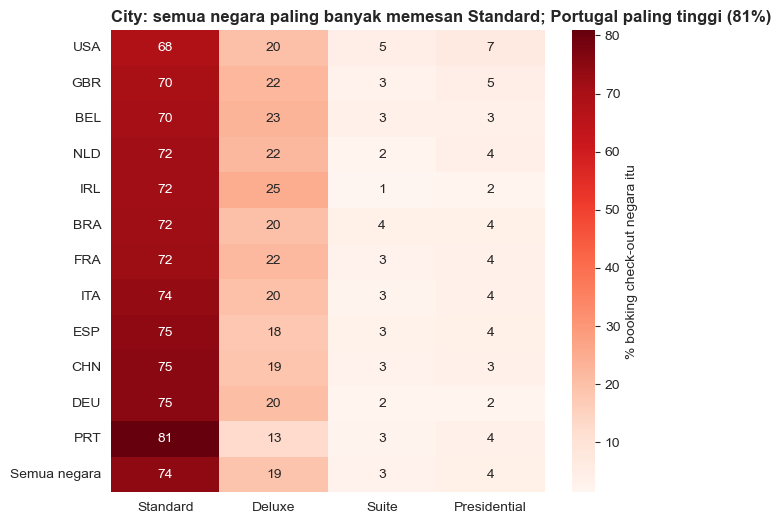

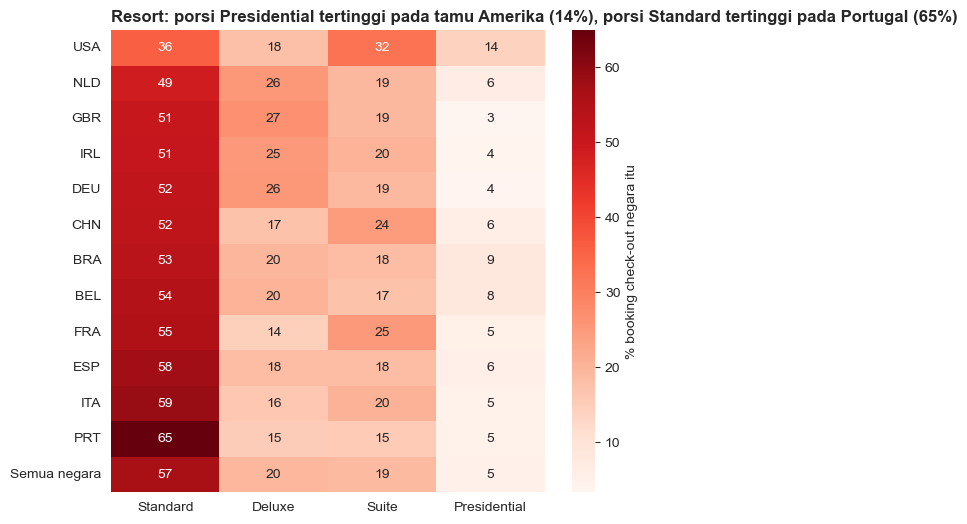

In [302]:
judul = {'City Hotel': 'City: semua negara paling banyak memesan Standard; Portugal paling tinggi (81%)',
         'Resort Hotel': 'Resort: porsi Presidential tertinggi pada tamu Amerika (14%), porsi Standard tertinggi pada Portugal (65%)'}
urutan_tier = ['Standard', 'Deluxe', 'Suite', 'Presidential']

for hotel in ['City Hotel', 'Resort Hotel']:
    x = negara_datang[negara_datang['hotel'] == hotel]
    tier_negara = pd.crosstab(x['country'], x['room_tier'], normalize='index')[urutan_tier] * 100
    tier_negara = tier_negara.sort_values('Standard')
    tier_negara.loc['Semua negara'] = co[co['hotel'] == hotel]['room_tier'].value_counts(normalize=True)[urutan_tier] * 100
    tier_negara.columns = ['Standard', 'Deluxe', 'Suite', 'Presidential']

    plt.figure(figsize=(7, 6))
    sns.heatmap(tier_negara, annot=True, fmt='.0f', cmap='Reds', cbar_kws={'label': '% booking check-out negara itu'})
    plt.title(judul[hotel], loc='left')
    plt.xlabel(''); plt.ylabel('')
    plt.show()

Pada dasarnya tiap negara punya pilihan hotel sendiri. Inggris dan Irlandia condong ke Resort dan menginap paling lama di sana. Semua negara paling banyak memesan kamar A.

- 41,1% check-out semua negara ada di Resort. Lebih banyak ke Resort: Irlandia (68,6%), Inggris (61,8%), Portugal (53,1%), Spanyol (50,6%). Prancis, Italia, Jerman sekitar 82% ke City, Belgia, Brasil, Belanda, Amerika 72-79%
- Portugal paling banyak Standard (City 81%, Resort 65%), Inggris, Irlandia, Jerman, Belanda lebih sering Deluxe (Inggris di Resort 27% vs 20%), tamu Amerika di Resort paling jarang Standard (36%) dan Presidential tertinggi (14% vs 5%), Prancis, Italia, CHN lebih sering Suite (20-25% vs 19%)

#### **6. Bulan teramai tiap tahun**
Bulan teramai dicari per hotel untuk setiap tahun, menurut semua booking dan menurut tamu yang datang (check-out). Tahunnya tidak lengkap: 2015 hanya Juli-Desember dan 2017 hanya Januari-Agustus, jadi bulan teramai 2015 dan 2017 hanya dipilih dari bulan yang ada

In [303]:
# bulan teramai tiap tahun per hotel, menurut semua booking dan menurut tamu yang datang (check-out)
# tahunnya tidak lengkap: 2015 hanya Juli-Desember, 2017 hanya Januari-Agustus
baris = []
for hotel in ['City Hotel', 'Resort Hotel']:
    semua = df[df['hotel'] == hotel]
    booking = semua.pivot_table(index='arrival_date_year', columns='arrival_month', values='adr', aggfunc='count')
    datang = semua[semua['is_canceled'] == 0].pivot_table(index='arrival_date_year', columns='arrival_month', values='adr', aggfunc='count')
    cancel = semua.pivot_table(index='arrival_date_year', columns='arrival_month', values='is_canceled', aggfunc='mean') * 100
    rugi = loss_rate_pivot(semua, 'arrival_date_year', 'arrival_month')
    pendapatan = semua[semua['is_canceled'] == 0].pivot_table(index='arrival_date_year', columns='arrival_month', values='revenue', aggfunc='sum')
    for tahun in [2015, 2016, 2017]:
        b_booking = booking.loc[tahun].idxmax()
        b_datang = datang.loc[tahun].idxmax()
        urut_datang = datang.loc[tahun].sort_values(ascending=False)
        b_pendapatan = pendapatan.loc[tahun].idxmax()          # bulan dengan revenue masuk tertinggi
        baris.append([hotel, tahun, booking.loc[tahun].notna().sum(),
                      b_booking, label_bulan[b_booking - 1], int(booking.loc[tahun].max()), rugi.loc[tahun, b_booking], cancel.loc[tahun, b_booking],
                      b_datang, label_bulan[b_datang - 1], int(datang.loc[tahun].max()),
                      label_bulan[list(urut_datang.index)[1] - 1] + ' (' + str(int(list(urut_datang)[1])) + ')',
                      label_bulan[b_pendapatan - 1], pendapatan.loc[tahun].max() / 1000])
tabel_teramai = pd.DataFrame(baris, columns=['hotel', 'tahun', 'jumlah_bulan_data',
                                             'no_bulan_booking', 'teramai_booking', 'booking', 'loss_rate_%', 'cancel_rate_%',
                                             'no_bulan_datang', 'teramai_datang', 'datang', 'urutan_2_datang',
                                             'revenue_tertinggi', 'revenue_masuk_€ribu'])
print(tabel_teramai.drop(columns=['no_bulan_booking', 'no_bulan_datang']).round(1).to_string(index=False))

       hotel  tahun  jumlah_bulan_data teramai_booking  booking  loss_rate_%  cancel_rate_% teramai_datang  datang urutan_2_datang revenue_tertinggi  revenue_masuk_€ribu
  City Hotel   2015                  6             Sep     1667         13.9           18.8            Sep    1354      Okt (1266)               Sep                430.5
  City Hotel   2016                 12             Agu     2808         36.3           32.4            Agu    1898      Sep (1812)               Agu                739.5
  City Hotel   2017                  8             Mei     3062         38.4           36.0            Mei    1959      Jul (1871)               Agu                782.6
Resort Hotel   2015                  6             Agu     1346         26.9           25.4            Agu    1004       Jul (999)               Agu                827.0
Resort Hotel   2016                 12             Agu     1607         36.0           33.1            Mar    1224      Okt (1221)               Agu  

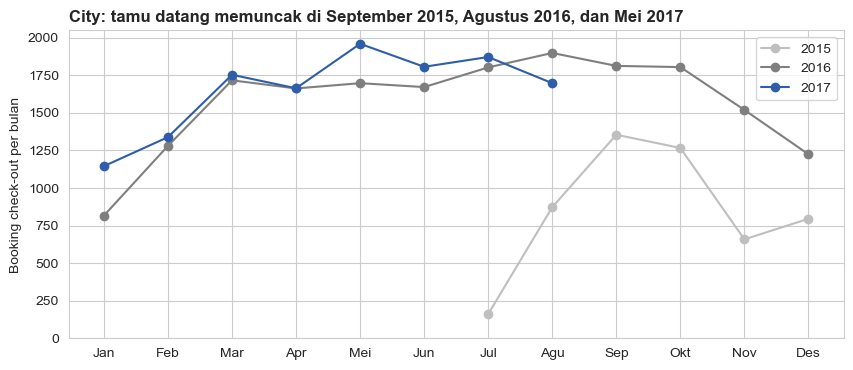

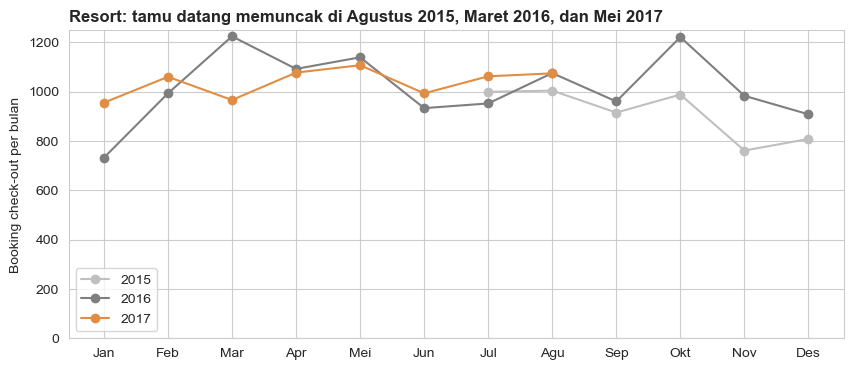

In [304]:
judul = {'City Hotel': 'City: tamu datang memuncak di September 2015, Agustus 2016, dan Mei 2017',
         'Resort Hotel': 'Resort: tamu datang memuncak di Agustus 2015, Maret 2016, dan Mei 2017'}

for hotel in ['City Hotel', 'Resort Hotel']:
    datang = df[(df['hotel'] == hotel) & (df['is_canceled'] == 0)].pivot_table(index='arrival_month', columns='arrival_date_year',
                                                                                values='adr', aggfunc='count')
    warna_tahun = {2015: ABU, 2016: '#7F7F7F', 2017: WARNA_HOTEL[hotel]}
    plt.figure(figsize=(10, 4))
    for tahun in [2015, 2016, 2017]:
        plt.plot(datang.index, datang[tahun], marker='o', color=warna_tahun[tahun], label=str(tahun))
    plt.xticks(range(1, 13), label_bulan)
    plt.ylim(0)
    plt.ylabel('Booking check-out per bulan')
    plt.title(judul[hotel], loc='left')
    plt.legend()
    plt.show()

- Bulan teramai berbeda tiap tahun dan tergantung ukurannya, tetapi Agustus tetap bulan dengan revenue masuk tertinggi di Resort
- City: September 2015 (1.354 tamu datang), Agustus 2016 (1.898), Mei 2017 (1.959), sama menurut jumlah booking. Revenue masuk tertinggi sama kecuali 2017 (Agustus, €783 ribu). Data City 2015 paling lemah (duplikat)
- Resort: menurut semua booking Agustus teramai di ketiga tahun (1.346, 1.607, 1.713). Menurut tamu yang datang hanya 2015, 2016 Maret (1.224), 2017 Mei (1.107). Agustus paling banyak dipesan dan paling banyak kehilangan nilai (36,0% di 2016, 41,3% di 2017), tetapi tetap revenue masuk tertinggi (€827 ribu, €982 ribu, €1,06 juta)
- Karena itu 4.E.1 dan 4.J.4 membaca pola bulanan dari 2016 dan per tahun (rata-rata kalender menunjuk Mei untuk City karena mencampur tahun)

#### **7. Tanggal 1 sampai akhir bulan di bulan teramai**
Untuk setiap bulan teramai di 4.L.6 (menurut kedua ukuran), kedatangan dihitung untuk setiap tanggal dari 1 sampai akhir bulan. Tabel mencatat tiga tanggal teramai dan tanggal tersepi, dan heatmap menampilkan semua tanggalnya. Kamar terisi per malam ikut ditampilkan untuk membandingkan kesibukan check-in dengan seberapa penuh hotel

In [305]:
# satu baris per hotel per tanggal kedatangan
per_tanggal = df.groupby(['hotel', 'arrival_date'])['is_canceled'].agg(['count', 'sum']).reset_index()
per_tanggal.columns = ['hotel', 'tanggal', 'booking', 'batal']
per_tanggal['datang'] = per_tanggal['booking'] - per_tanggal['batal']
per_tanggal['tahun'] = per_tanggal['tanggal'].dt.year
per_tanggal['bulan'] = per_tanggal['tanggal'].dt.month
per_tanggal['tgl'] = per_tanggal['tanggal'].dt.day
per_tanggal['hari'] = per_tanggal['tanggal'].dt.day_name().map(nama_hari)

# kamar terisi pada malam tanggal itu (okupansi dari 4.I.4)
malam = okupansi[['hotel', 'tanggal_inap', 'kamar_terisi', 'okupansi_%']].copy()
malam.columns = ['hotel', 'tanggal', 'kamar_terisi', 'okupansi_%']
per_tanggal = per_tanggal.merge(malam, on=['hotel', 'tanggal'], how='left')

# tandai tanggal libur Portugal (daftar libur dari 4.E.3)
per_tanggal['libur'] = '-'
for nama, mulai, selesai in libur:
    per_tanggal.loc[(per_tanggal['tanggal'] >= mulai) & (per_tanggal['tanggal'] <= selesai), 'libur'] = nama

# bulan yang dilihat: bulan teramai tiap tahun menurut kedua ukuran (tabel_teramai di 4.L.6), tanpa duplikat
dilihat = []
for i in tabel_teramai.index:
    hotel = tabel_teramai.loc[i, 'hotel']
    tahun = tabel_teramai.loc[i, 'tahun']
    for bulan in [tabel_teramai.loc[i, 'no_bulan_booking'], tabel_teramai.loc[i, 'no_bulan_datang']]:
        if [hotel, tahun, bulan] not in dilihat:
            dilihat.append([hotel, tahun, bulan])

baris = []
for hotel, tahun, bulan in dilihat:
    x = per_tanggal[(per_tanggal['hotel'] == hotel) & (per_tanggal['tahun'] == tahun) & (per_tanggal['bulan'] == bulan)]
    x = x.sort_values('datang', ascending=False)
    teratas = []
    for j in x.head(3).index:
        teratas.append(f"{x.loc[j, 'tgl']} {x.loc[j, 'hari']} ({x.loc[j, 'datang']})")
    j = x['datang'].idxmin()
    terendah = f"{x.loc[j, 'tgl']} {x.loc[j, 'hari']} ({x.loc[j, 'datang']})"
    mlm = okupansi[(okupansi['hotel'] == hotel) & (okupansi['tanggal_inap'].dt.year == tahun) & (okupansi['bulan'] == bulan)]
    tamu = df[(df['hotel'] == hotel) & (df['arrival_date_year'] == tahun) & (df['arrival_month'] == bulan) & (df['is_canceled'] == 0)]
    baris.append([hotel, tahun, label_bulan[bulan - 1], x['datang'].mean(), ', '.join(teratas), terendah,
                  tamu['total_nights'].mean(), mlm['okupansi_%'].mean(), (mlm['okupansi_%'] >= 95).mean() * 100])
ringkas_tanggal = pd.DataFrame(baris, columns=['hotel', 'tahun', 'bulan', 'kedatangan_per_tanggal', '3_tanggal_teramai (kedatangan)',
                                               'tanggal_tersepi', 'malam_rata2_tamu', 'okupansi_rata2_%', '%_malam_>=95%'])
print(ringkas_tanggal.round(1).to_string(index=False))

       hotel  tahun bulan  kedatangan_per_tanggal        3_tanggal_teramai (kedatangan) tanggal_tersepi  malam_rata2_tamu  okupansi_rata2_%  %_malam_>=95%
  City Hotel   2015   Sep                    45.1  25 Jum (78), 4 Jum (64), 21 Sen (63)     29 Sel (19)               2.9              61.0            0.0
  City Hotel   2016   Agu                    61.2  20 Sab (82), 28 Min (79), 8 Sen (79)     27 Sab (34)               3.2              91.3           29.0
  City Hotel   2017   Mei                    63.2    9 Sel (84), 2 Sel (78), 5 Jum (78)     27 Sab (37)               2.9              82.9            0.0
Resort Hotel   2015   Agu                    32.4  10 Sen (55), 3 Sen (48), 15 Sab (45)     12 Rab (16)               5.4              93.4           41.9
Resort Hotel   2016   Agu                    34.7   1 Sen (59), 8 Sen (52), 22 Sen (48)     24 Rab (22)               5.1              95.7           74.2
Resort Hotel   2016   Mar                    39.5 31 Kam (61), 24 Kam 

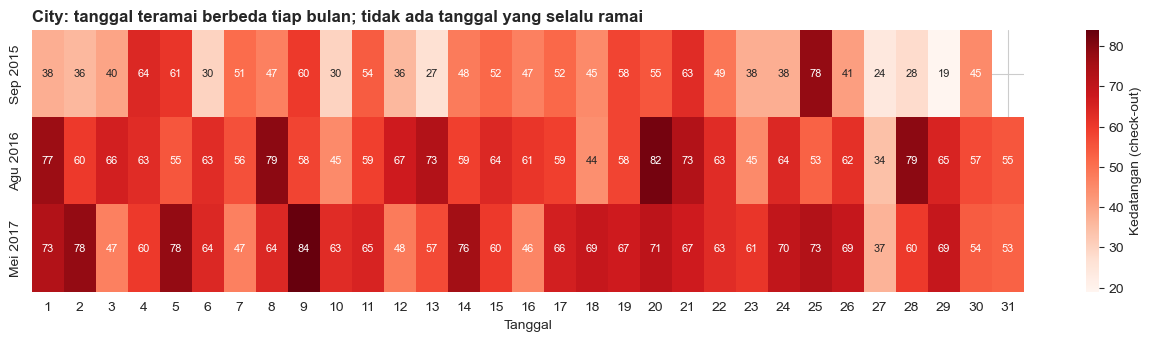

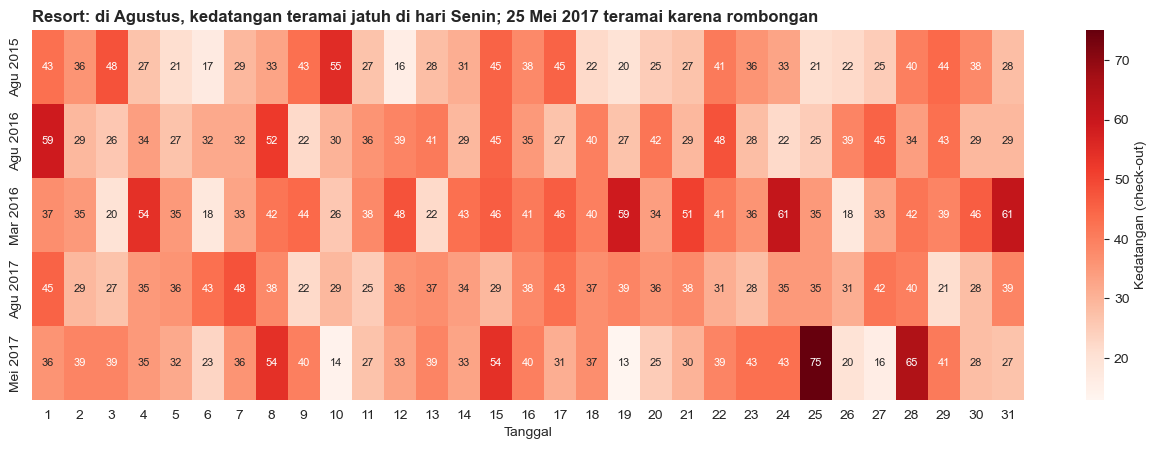

In [306]:
judul = {'City Hotel': 'City: tanggal teramai berbeda tiap bulan; tidak ada tanggal yang selalu ramai',
         'Resort Hotel': 'Resort: di Agustus, kedatangan teramai jatuh di hari Senin; 25 Mei 2017 teramai karena rombongan'}

# kedatangan (check-out) per tanggal 1 sampai akhir bulan, satu baris per bulan teramai
for hotel in ['City Hotel', 'Resort Hotel']:
    daftar = []
    nama_baris = []
    for h, tahun, bulan in dilihat:
        if h == hotel:
            x = per_tanggal[(per_tanggal['hotel'] == hotel) & (per_tanggal['tahun'] == tahun) & (per_tanggal['bulan'] == bulan)]
            daftar.append(x.set_index('tgl')['datang'])
            nama_baris.append(f"{label_bulan[bulan - 1]} {tahun}")
    peta = pd.DataFrame(daftar, index=nama_baris)

    plt.figure(figsize=(16, len(peta) * 0.7 + 1.3))
    sns.heatmap(peta, annot=True, fmt='.0f', annot_kws={'size': 8}, cmap='Reds', cbar_kws={'label': 'Kedatangan (check-out)'})
    plt.title(judul[hotel], loc='left')
    plt.xlabel('Tanggal'); plt.ylabel('')
    plt.show()

In [307]:
# siapa yang datang pada tanggal teramai di bulan-bulan teramai, per hotel
for hotel in ['City Hotel', 'Resort Hotel']:
    x = pd.DataFrame()
    for h, tahun, bulan in dilihat:
        if h == hotel:
            x = pd.concat([x, per_tanggal[(per_tanggal['hotel'] == hotel) & (per_tanggal['tahun'] == tahun) & (per_tanggal['bulan'] == bulan)]])
    i = x['datang'].idxmax()
    tanggal_puncak = x.loc[i, 'tanggal']
    tamu = df[(df['hotel'] == hotel) & (df['arrival_date'] == tanggal_puncak) & (df['is_canceled'] == 0)]

    print(f"{hotel} - {tanggal_puncak.date()} ({x.loc[i, 'hari']}): {len(tamu)} kedatangan, libur: {x.loc[i, 'libur']}, "
          f"kamar terisi malam itu {x.loc[i, 'kamar_terisi']:.0f}")
    print('   segmen    :', tamu['market_segment'].value_counts().head(3).to_dict())
    print('   negara    :', tamu['country'].value_counts().head(3).to_dict())
    print('   agent     :', tamu['agent'].value_counts().head(3).to_dict())
    print('   tipe tamu :', tamu['guest_type'].value_counts().head(2).to_dict())
    print(f"   median lead time {tamu['lead_time'].median():.0f} hari | rata-rata {tamu['total_nights'].mean():.1f} malam\n")

pd.reset_option('display.width')          # kembalikan lebar tampilan tabel ke default untuk bagian berikutnya

City Hotel - 2017-05-09 (Sel): 84 kedatangan, libur: -, kamar terisi malam itu 194
   segmen    : {'Online TA': 34, 'Offline TA/TO': 16, 'Direct': 13}
   negara    : {'PRT': 15, 'FRA': 13, 'DEU': 6}
   agent     : {9: 24, 0: 18, 39: 10}
   tipe tamu : {'Pasangan': 41, 'Solo': 40}
   median lead time 29 hari | rata-rata 2.4 malam

Resort Hotel - 2017-05-25 (Kam): 75 kedatangan, libur: -, kamar terisi malam itu 150
   segmen    : {'Groups': 42, 'Online TA': 15, 'Offline TA/TO': 14}
   negara    : {'GBR': 48, 'CHN': 8, 'PRT': 7}
   agent     : {0: 38, 240: 9, 96: 8}
   tipe tamu : {'Pasangan': 50, 'Keluarga': 14}
   median lead time 203 hari | rata-rata 4.5 malam



Berdasarkan data, check-in ramai tidak sama dengan hotel penuh. Resort paling penuh di Agustus karena tamunya menginap lama, bukan karena kedatangannya paling banyak

- City: tidak ada tanggal yang selalu ramai. Teramai: 25 September 2015 (78 kedatangan), 20 Agustus 2016 (82), 9 Mei 2017 (84). Tersepi dua kali di tanggal 27 yang jatuh Sabtu. Tamu 9 Mei 2017 campuran: 34 Online TA, 16 Offline TA/TO, 13 Direct
- Resort: di Agustus teramai selalu Senin (10 Agustus 2015, 1 Agustus 2016, 7 Agustus 2017). Teramai keseluruhan Kamis 25 Mei 2017 (75 kedatangan), pola rombongan: 42 Groups, 48 dari Inggris, 38 tanpa agent, median lead time 203 hari
- Kedatangan Resort di Agustus (32,4-34,7 per tanggal) lebih sedikit dari Maret 2016 dan Mei 2017 (35,7-39,5), tetapi okupansi Agustus 93,4-96,0% karena tamu menginap 5,1-5,4 malam (Maret 3,1, Mei 4,5). City Agustus 2016 juga paling penuh (91,3%)

**Apa artinya untuk rekomendasi?**

| Temuan 4.L | Dipakai untuk |
|---|---|
| Tidak ada negara Best, di Resort pasar yang menginap lama membayar lebih murah per malam, tiap negara punya pilihan hotel dan kamar | Promosi per negara: paket panjang untuk Inggris dan Irlandia, harga per malam untuk Spanyol dan Amerika |
| Portugal, Spanyol, Offline TA/TO, Corporate City menyusut | Dicek bersama Sales sebelum deposit diperketat (rekomendasi 1) |
| Agent 14 dan 241 Best, agent 9 dan 240 Stabil dengan loss rate tertinggi | Tolok ukur kontrak agent (rekomendasi 3) |
| Corporate Selasa-Rabu, Groups Oktober-November, keduanya hilang di Agustus | Mengisi bulan dan hari sepi, Online TA dan Direct mengisi Agustus (rekomendasi 7) |
| Bulan teramai beda per tahun, revenue masuk Resort tertinggi tetap Agustus | Staf check-in memakai kedatangan per tanggal, buffer overbooking untuk malam penuh Agustus (rekomendasi 4) |
| Tanggal teramai bisa berasal dari satu rombongan | Pickup menandai rombongan besar sejak jauh hari (rekomendasi 2) |

### **M. RFM per agent dan per perusahaan** (pertanyaan J)
Agent dan perusahaan punya ID sendiri, jadi R, F, dan M bisa dihitung per entitas (RFM D22). Perusahaan dibaca dari kolom company, booking Corporate tanpa ID perusahaan tidak bisa dikelompokkan

- **R**: hari dari check-out terakhir sampai 31 Agustus 2017. 0-30 hari = 5, 31-90 = 4, 91-180 = 3, 181-365 = 2, lebih dari 365 = 1
- **F** (jumlah check-out): agent 1 / 2-5 / 6-20 / 21-100 / lebih dari 100, perusahaan 1 / 2 / 3-5 / 6-15 / lebih dari 15
- **M** (revenue masuk): agent di bawah €500 / €500-2.000 / €2.000-10.000 / €10.000-50.000 / di atas €50.000, perusahaan di bawah €150 / €150-400 / €400-1.000 / €1.000-3.000 / di atas €3.000

Batas dipilih dari sebaran data (kira-kira kuintil). Revenue loss rate dan cancel rate ditampilkan di samping skor

| Label | Syarat |
|---|---|
| Best | R, F, M semua 4 atau lebih |
| Potential | R 4 atau lebih, F 3 atau lebih |
| New | R 4 atau lebih, F 2 atau kurang |
| At-Risk | R 2 atau kurang, F 3 atau lebih |
| Lost | R dan F 2 atau kurang |
| Stabil | sisanya |
| Hanya batal | semua booking-nya batal |

In [308]:
akhir_data = df['arrival_date'].max()          # tanggal kedatangan terakhir di data (31 Agustus 2017)
nomor_label = {'Best': 1, 'Potential': 2, 'New': 3, 'Stabil': 4, 'At-Risk': 5, 'Lost': 6, 'Hanya batal': 7}   # urutan tampil


def rfm_entitas(kolom, batas_f, batas_m):
    # RFM per entitas (agent atau perusahaan); ID 0 = tanpa agent / tanpa perusahaan, jadi tidak ikut
    semua = df[df[kolom] != 0]
    datang = semua[semua['is_canceled'] == 0]

    t = pd.DataFrame()
    t['booking'] = semua.groupby(kolom)['adr'].count()
    t['check_out'] = datang.groupby(kolom)['adr'].count()                  # F: jumlah booking yang menginap
    t['revenue_masuk'] = datang.groupby(kolom)['revenue'].sum()            # M: revenue masuk
    t['hari_sejak_terakhir'] = (akhir_data - datang.groupby(kolom)['arrival_date'].max()).dt.days   # R
    t['potensi_revenue'] = semua.groupby(kolom)['revenue'].sum()
    t['revenue_hilang'] = semua.groupby(kolom)['revenue_hilang'].sum()
    t['revenue_loss_rate'] = t['revenue_hilang'] / t['potensi_revenue'] * 100
    t['batal'] = semua.groupby(kolom)['is_canceled'].sum()
    t['cancel_rate'] = t['batal'] / t['booking'] * 100
    t['%_city'] = semua.groupby(kolom)['hotel'].apply(lambda x: (x == 'City Hotel').mean() * 100)
    t['check_out'] = t['check_out'].fillna(0)
    t['revenue_masuk'] = t['revenue_masuk'].fillna(0)

    # skor 1-5 dengan batas tetap (rule-based, D22); R dibalik: makin baru, makin tinggi
    pernah = t[t['check_out'] > 0].copy()
    pernah['R'] = pd.cut(pernah['hari_sejak_terakhir'], bins=[-1, 30, 90, 180, 365, 10000], labels=[5, 4, 3, 2, 1]).astype(int)
    pernah['F'] = pd.cut(pernah['check_out'], bins=batas_f, labels=[1, 2, 3, 4, 5]).astype(int)
    pernah['M'] = pd.cut(pernah['revenue_masuk'], bins=batas_m, labels=[1, 2, 3, 4, 5]).astype(int)
    pernah['skor_total'] = pernah['R'] + pernah['F'] + pernah['M']

    # label dari kombinasi skor (D22, aturan sama dengan 4.L tanpa L); aturan terakhir paling kuat
    pernah['label'] = 'Stabil'
    pernah.loc[(pernah['R'] >= 4) & (pernah['F'] <= 2), 'label'] = 'New'
    pernah.loc[(pernah['R'] >= 4) & (pernah['F'] >= 3), 'label'] = 'Potential'
    pernah.loc[(pernah['R'] <= 2) & (pernah['F'] >= 3), 'label'] = 'At-Risk'
    pernah.loc[(pernah['R'] <= 2) & (pernah['F'] <= 2), 'label'] = 'Lost'
    pernah.loc[(pernah['R'] >= 4) & (pernah['F'] >= 4) & (pernah['M'] >= 4), 'label'] = 'Best'

    # entitas yang semua booking-nya batal tidak punya R, F, dan M
    hanya_batal = t[t['check_out'] == 0].copy()
    hanya_batal['label'] = 'Hanya batal'
    return pd.concat([pernah, hanya_batal]).sort_values('revenue_masuk', ascending=False)


def ringkas_label(tabel):
    # per label: jumlah entitas, porsi revenue masuk, porsi revenue hilang, dan revenue loss rate
    r = pd.DataFrame()
    r['entitas'] = tabel.groupby('label')['booking'].count()
    r['%_revenue_masuk'] = tabel.groupby('label')['revenue_masuk'].sum() / tabel['revenue_masuk'].sum() * 100
    r['%_revenue_hilang'] = tabel.groupby('label')['revenue_hilang'].sum() / tabel['revenue_hilang'].sum() * 100
    r['revenue_loss_rate'] = tabel.groupby('label')['revenue_hilang'].sum() / tabel.groupby('label')['potensi_revenue'].sum() * 100
    r['cancel_rate'] = tabel.groupby('label')['batal'].sum() / tabel.groupby('label')['booking'].sum() * 100
    r['urutan'] = r.index.map(nomor_label)
    return r.sort_values('urutan').drop(columns='urutan')


kolom_rfm = ['booking', 'check_out', 'revenue_masuk', 'hari_sejak_terakhir', 'R', 'F', 'M', 'skor_total', 'label',
             'revenue_loss_rate', 'cancel_rate', '%_city']

In [309]:
judul_agent = 'Agent: 71 agent Best membawa 94% revenue masuk dan 98% revenue hilang'

# batas F dan M agent dipilih dari sebaran data (kira-kira kuintil): F 1 / 2-5 / 6-20 / 21-100 / >100 check-out,
# M di bawah €500 / €500-2.000 / €2.000-10.000 / €10.000-50.000 / di atas €50.000
rfm_agent = rfm_entitas('agent', batas_f=[0, 1, 5, 20, 100, 1000000], batas_m=[-1, 500, 2000, 10000, 50000, 1e9])
print('Jumlah agent:', len(rfm_agent), '| pernah menginap:', (rfm_agent['check_out'] > 0).sum(), '\n')
ringkas_agent = ringkas_label(rfm_agent)
print(f"Revenue loss rate semua agent: {rfm_agent['revenue_hilang'].sum() / rfm_agent['potensi_revenue'].sum():.1%}", '\n')
print(ringkas_agent.round(1), '\n')
print('10 agent dengan revenue masuk terbesar:')
print(rfm_agent[kolom_rfm].head(10).round(1), '\n')
print('Agent At-Risk dan Hanya batal dengan revenue hilang terbesar:')
print(rfm_agent[rfm_agent['label'].isin(['At-Risk', 'Hanya batal'])].sort_values('revenue_hilang', ascending=False)[kolom_rfm + ['revenue_hilang']].head(8).round(1))

Jumlah agent: 333 | pernah menginap: 314 

Revenue loss rate semua agent: 34.3% 

             entitas  %_revenue_masuk  %_revenue_hilang  revenue_loss_rate  \
label                                                                        
Best              71             94.4              97.8               35.2   
Potential         21              0.5               0.2               19.4   
New               13              0.0               0.0               14.1   
Stabil            45              2.3               0.9               14.6   
At-Risk           66              2.5               1.0               16.0   
Lost              98              0.3               0.1                9.1   
Hanya batal       19              0.0               0.1               30.8   

             cancel_rate  
label                     
Best                30.3  
Potential           15.8  
New                 20.5  
Stabil              29.3  
At-Risk             20.5  
Lost                18.7  

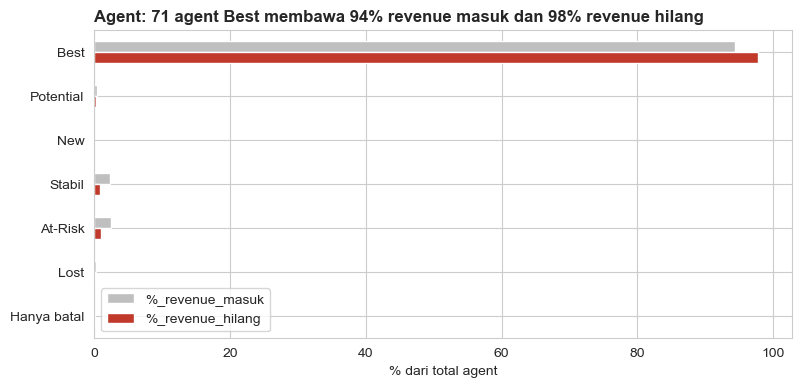

In [310]:
ringkas_agent[['%_revenue_masuk', '%_revenue_hilang']].plot.barh(color=[ABU, SOROT], figsize=(9, 4))
plt.gca().invert_yaxis()          # label pertama (Best) di paling atas
plt.title(judul_agent, loc='left')
plt.xlabel('% dari total agent'); plt.ylabel('')
plt.show()

Berdasarkan data di atas:
- Nilai dan kehilangan menumpuk di sedikit agent. Agent 9 dan 240 Best karena besar, sering, dan baru, tetapi kehilangan nilai paling banyak
- 333 agent, 314 pernah punya tamu menginap, revenue loss rate semua agent 34,3%
- Best: 71 agent membawa 94,4% revenue masuk dan 97,8% revenue hilang agent. Agent 9 dan 240 kehilangan 44,1% dan 48,1%, agent lain di Best jauh lebih rendah (28: 5,9%, 40: 9,4%, 7: 15,0%, 241: 18,1%, 250: 21,0%, 14: 22,3%)
- At-Risk: 66 agent tidak punya tamu menginap dalam 180 hari terakhir, nilainya kecil (2,5% revenue masuk), misalnya agent 142 dan 156 di Resort (€60 ribu dan €81 ribu)
- Hanya batal: 19 agent, loss rate 30,8% (sisanya Non Refund yang tetap membayar). Lost: 98 agent, 0,3% revenue masuk

In [311]:
judul_company = 'Perusahaan: kelompok At-Risk membawa 13% revenue masuk tetapi 24% revenue hilang'

# perusahaan lebih kecil dari agent, jadi batasnya lebih rendah: F 1 / 2 / 3-5 / 6-15 / >15 check-out,
# M di bawah €150 / €150-400 / €400-1.000 / €1.000-3.000 / di atas €3.000
rfm_company = rfm_entitas('company', batas_f=[0, 1, 2, 5, 15, 1000000], batas_m=[-1, 150, 400, 1000, 3000, 1e9])
print('Jumlah perusahaan:', len(rfm_company), '| pernah menginap:', (rfm_company['check_out'] > 0).sum())
print('% booking ber-ID perusahaan yang lewat segmen Corporate:',
      round((df[df['company'] != 0]['market_segment'] == 'Corporate').mean() * 100, 1), '\n')
ringkas_company = ringkas_label(rfm_company)
print(f"Revenue loss rate semua perusahaan: {rfm_company['revenue_hilang'].sum() / rfm_company['potensi_revenue'].sum():.1%}", '\n')
print(ringkas_company.round(1), '\n')
print('10 perusahaan dengan revenue masuk terbesar:')
print(rfm_company[kolom_rfm].head(10).round(1))

Jumlah perusahaan: 348 | pernah menginap: 329
% booking ber-ID perusahaan yang lewat segmen Corporate: 68.4 

Revenue loss rate semua perusahaan: 10.6% 

             entitas  %_revenue_masuk  %_revenue_hilang  revenue_loss_rate  \
label                                                                        
Best              38             42.8              41.5               10.5   
Potential         19              2.1               1.4                7.2   
New               16              0.7               0.0                0.9   
Stabil            78             36.8              23.8                7.1   
At-Risk           64             12.8              24.2               18.4   
Lost             114              4.9               4.1                9.3   
Hanya batal       19              0.0               5.0               51.9   

             cancel_rate  
label                     
Best                 9.9  
Potential            9.5  
New                  4.2  
Stabil  

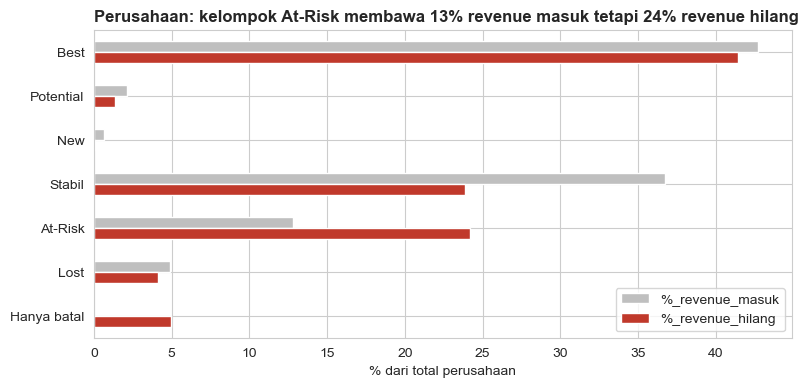

In [312]:
ringkas_company[['%_revenue_masuk', '%_revenue_hilang']].plot.barh(color=[ABU, SOROT], figsize=(9, 4))
plt.gca().invert_yaxis()          # label pertama (Best) di paling atas
plt.title(judul_company, loc='left')
plt.xlabel('% dari total perusahaan'); plt.ylabel('')
plt.show()

- Perusahaan lebih aman daripada agent (loss rate 10,6% vs 34,3%), tetapi 64 perusahaan At-Risk perlu dihubungi Sales.
- 348 perusahaan, 329 pernah menginap, 68,4% booking ber-ID perusahaan lewat Corporate. Revenue loss rate semua perusahaan 10,6%, sekitar sepertiga agent
- Best: 38 perusahaan, 42,8% revenue masuk, loss rate 10,5%. Stabil: 78 perusahaan, 36,8%, termasuk yang terbesar (223, sekitar €123 ribu)
- At-Risk: 64 perusahaan membawa 12,8% revenue masuk tetapi 24,2% revenue hilang (loss rate 18,4%)
- Hanya batal: 19 perusahaan, 5,0% revenue hilang (51,9%). Lost: 114 perusahaan, 4,9% revenue masuk

#### **Tindakan per label (agent dan perusahaan)**

- **Best:** syarat pembatalan agent 9 dan 240 dibedakan dengan agent Best yang sedikit kehilangan sebagai tolok ukur (rekomendasi 3), perusahaan: tarif kontrak dan alokasi hari kerja dipertahankan
- **Potential dan New** (21 dan 13 agent, 19 dan 16 perusahaan): Sales mendorong booking berikutnya
- **Stabil** (45 agent, 78 perusahaan): review rutin, akun besar yang belum menginap lebih dari 3 bulan dihubungi
- **At-Risk** (66 agent, 64 perusahaan): Sales mencari tahu kenapa berhenti, pembatalan perusahaan dicek sebelum kontrak diperbarui
- **Lost** (98 agent, 114 perusahaan): tidak diprioritaskan
- **Hanya batal** (19 agent, 19 perusahaan): deposit atau tarif non-refundable sebelum booking berikutnya dikonfirmasi

Label dihitung dari data sampai Agustus 2017, kalau dipakai, dihitung ulang tiap bulan.

> **Babak 6 dari 6: Bukti dan keputusan** (4.N, bagian 5, Simulasi, Batasan)
>
> Dua selisih dasar rekomendasi diuji dulu (4.N), lalu semua temuan disusun menjadi insight, rekomendasi, KPI, simulasi, dan kartu target.

### **N. Uji statistik: apakah selisihnya bisa terjadi karena kebetulan?** (pertanyaan K)
Rekomendasi 1 dan 6 bersandar pada dua selisih: segmen risiko tinggi lebih sering batal (4.F.2), dan Direct menghasilkan revenue masuk per booking lebih besar dari Online TA (4.I.2). Bagian ini mengecek apakah selisih itu lebih besar dari variasi acak (confidence interval D11, Welch t-test D12), per hotel. Booking tidak dibagi acak, jadi uji ini hanya menjawab apakah selisih bisa dijelaskan kebetulan, penyebabnya tetap harus dibuktikan lewat uji coba

#### **1. Cancel rate segmen risiko tinggi dengan 95% confidence interval**
**Uji 1:** cancel rate segmen risiko tinggi vs booking lain.

- **PICOT:** P booking City dan Resort Juli 2015-Agustus 2017, I segmen risiko tinggi (Online TA, lead time > 90 hari), C booking lain di hotel yang sama, O cancel rate, T sejak booking dibuat sampai kedatangan
- **H0:** cancel rate segmen risiko tinggi tidak lebih tinggi. **Ha:** lebih tinggi. α = 0,05 (95% CI), untuk City, Resort, dan kedua hotel
- CI proporsi (D11): p ± 1,96 × √(p × (1 − p) / n), syarat n × p dan n × (1 − p) minimal 15. H0 ditolak kalau batas bawah segmen risiko di atas batas atas booking lain
- CI hanya untuk cancel rate, karena revenue loss rate adalah rasio dua jumlah euro

In [313]:
judul_ci = 'Segmen risiko tinggi batal 45–50%, booking lain 18–26%; interval 95% tidak bersinggungan'

# 95% confidence interval cancel rate (rumus D11): p ± 1,96 × √(p × (1 − p) / n)
ci = []
for hotel in ['City Hotel', 'Resort Hotel', 'Kedua hotel']:
    if hotel == 'Kedua hotel':
        data_hotel = df
    else:
        data_hotel = df[df['hotel'] == hotel]
    for kelompok in ['Risiko tinggi', 'Lainnya']:
        x = data_hotel[data_hotel['segmen_risiko'] == kelompok]
        n = len(x)
        p = x['is_canceled'].mean()
        se = np.sqrt(p * (1 - p) / n)            # standard error proporsi
        ci.append([hotel, kelompok, n, n * p, n * (1 - p), p * 100, (p - 1.96 * se) * 100, (p + 1.96 * se) * 100])

ci = pd.DataFrame(ci, columns=['hotel', 'kelompok', 'jumlah_booking', 'n_x_p', 'n_x_(1-p)', 'cancel_rate', 'batas_bawah', 'batas_atas'])
# syarat rumus: n × p dan n × (1 − p) minimal 15
ci['syarat_terpenuhi'] = (ci['n_x_p'] >= 15) & (ci['n_x_(1-p)'] >= 15)
print(ci.round(2).to_string(index=False), '\n')

# Cek hasilnya: CI tidak bersinggungan kalau batas bawah risiko tinggi di atas batas atas booking lainnya
bawah = ci.pivot_table(index='hotel', columns='kelompok', values='batas_bawah')
atas = ci.pivot_table(index='hotel', columns='kelompok', values='batas_atas')
cek_ci = pd.DataFrame()
cek_ci['batas_bawah_risiko'] = bawah['Risiko tinggi']
cek_ci['batas_atas_lainnya'] = atas['Lainnya']
cek_ci['tidak_bersinggungan'] = cek_ci['batas_bawah_risiko'] > cek_ci['batas_atas_lainnya']
print(cek_ci.round(2))

ci['label'] = ci['hotel'].str.replace(' Hotel', '') + ' - ' + ci['kelompok']
ci['margin'] = ci['cancel_rate'] - ci['batas_bawah']          # setengah lebar interval
t = ci.sort_index(ascending=False)                            # baris pertama di paling atas
warna = np.where(t['kelompok'] == 'Risiko tinggi', SOROT, ABU)

       hotel      kelompok  jumlah_booking   n_x_p  n_x_(1-p)  cancel_rate  batas_bawah  batas_atas  syarat_terpenuhi
  City Hotel Risiko tinggi           12232  5469.0     6763.0        44.71        43.83       45.59              True
  City Hotel       Lainnya           41041 10565.0    30476.0        25.74        25.32       26.17              True
Resort Hotel Risiko tinggi            5872  2925.0     2947.0        49.81        48.53       51.09              True
Resort Hotel       Lainnya           28083  5049.0    23034.0        17.98        17.53       18.43              True
 Kedua hotel Risiko tinggi           18104  8394.0     9710.0        46.37        45.64       47.09              True
 Kedua hotel       Lainnya           69124 15614.0    53510.0        22.59        22.28       22.90              True 

              batas_bawah_risiko  batas_atas_lainnya  tidak_bersinggungan
hotel                                                                    
City Hotel              

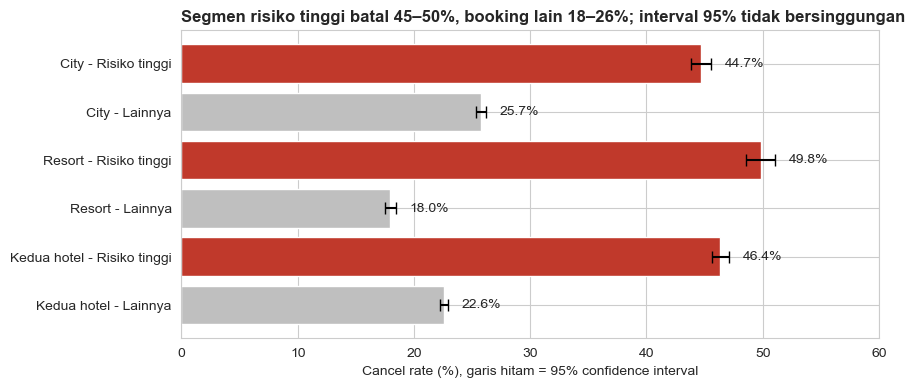

In [314]:
plt.figure(figsize=(9, 4))
# xerr = garis hitam selebar CI di ujung tiap bar; capsize = panjang garis kecil di kedua ujungnya
bar = plt.barh(t['label'], t['cancel_rate'], xerr=t['margin'], color=warna, capsize=4)
plt.bar_label(bar, fmt='%.1f%%', padding=10)
plt.title(judul_ci, loc='left')
plt.xlabel('Cancel rate (%), garis hitam = 95% confidence interval')
plt.xlim(0, 60)
plt.show()

- Segmen risiko tinggi batal jauh lebih sering di kedua hotel, dan selisihnya bukan kebetulan (H0 ditolak).
- City: segmen risiko tinggi 44,7% (95% CI 43,8%-45,6%) vs booking lain 25,7% (25,3%-26,2%)
- Resort: 49,8% (48,5%-51,1%) vs 18,0% (17,5%-18,4%)
- Kedua hotel: 46,4% (45,6%-47,1%) vs 22,6% (22,3%-22,9%)

#### **2. Welch t-test: revenue masuk per booking, Direct vs Online TA**
**Uji 2:** revenue masuk per booking, Direct vs Online TA. Selisihnya sekitar €45 (City) dan €92 (Resort) (4.I.2), dipakai sebagai dampak rekomendasi 6.

- **PICOT:** P booking tiap hotel Juli 2015-Agustus 2017, I Direct, C Online TA, O revenue masuk per booking (`adr × total_nights` untuk Check-Out, 0 untuk batal, Forfeited Deposit Revenue tidak dihitung), T booking sampai check-out
- **H0:** rata-rata Direct tidak lebih besar. **Ha:** lebih besar (satu sisi, p-value `ttest_ind` dibagi 2). α = 0,05, per hotel

Varians tidak sama, jadi dipakai Welch t-test (`equal_var=False`). Datanya tidak normal (banyak nilai 0 dari booking batal), jadi hasil bersandar pada jumlah data yang besar (CLT), dengan median sebagai pembanding. 95% CI selisih dihitung dengan standard error yang sama.

In [315]:
# revenue masuk per booking: revenue untuk booking check-out, 0 untuk booking batal (sama dengan 4.G.1 dan 4.I.2)
df['revenue_masuk_booking'] = 0.0
df.loc[df['is_canceled'] == 0, 'revenue_masuk_booking'] = df['revenue']

uji = []
for hotel in ['City Hotel', 'Resort Hotel']:
    data_hotel = df[df['hotel'] == hotel]
    direct = data_hotel[data_hotel['market_segment'] == 'Direct']['revenue_masuk_booking']
    ota = data_hotel[data_hotel['market_segment'] == 'Online TA']['revenue_masuk_booking']

    # Welch t-test (D12): varians kedua kelompok tidak dianggap sama
    # Ha satu sisi (Direct lebih besar), jadi p-value dibagi 2
    result = list(ttest_ind(direct, ota, equal_var=False))

    # 95% CI selisih rata-rata: selisih ± 1,96 × se, dengan se = √(s1²/n1 + s2²/n2) seperti di rumus Welch
    # jumlah data ribuan, jadi nilai t di tabel hampir sama dengan 1,96
    selisih = direct.mean() - ota.mean()
    se = np.sqrt(direct.var() / len(direct) + ota.var() / len(ota))
    uji.append([hotel, len(direct), len(ota), direct.mean(), ota.mean(), direct.median(), ota.median(),
                selisih, selisih - 1.96 * se, selisih + 1.96 * se, result[0], result[1] / 2])

uji = pd.DataFrame(uji, columns=['hotel', 'n_direct', 'n_online_ta', 'rata2_direct', 'rata2_online_ta',
                                 'median_direct', 'median_online_ta', 'selisih', 'ci_bawah', 'ci_atas', 't_stat', 'p_value'])
print(uji.drop(columns=['t_stat', 'p_value']).round(1).to_string(index=False), '\n')
# p-value ditulis dengan format e: 8.38e-29 = 8,38 × 10 pangkat −29, jauh di bawah 0,05
for i in uji.index:
    print(f"{uji.loc[i, 'hotel']} : t = {uji.loc[i, 't_stat']:.2f}, p-value satu sisi = {uji.loc[i, 'p_value']:.2e}")

       hotel  n_direct  n_online_ta  rata2_direct  rata2_online_ta  median_direct  median_online_ta  selisih  ci_bawah  ci_atas
  City Hotel      5538        34929         277.9            233.2          200.0             178.2     44.6      36.8     52.5
Resort Hotel      6242        16624         382.3            290.0          152.0             126.0     92.4      77.9    106.8 

City Hotel : t = 11.12, p-value satu sisi = 8.38e-29
Resort Hotel : t = 12.53, p-value satu sisi = 5.04e-36


- Direct menghasilkan revenue masuk per booking lebih besar dari Online TA di kedua hotel, dan selisihnya bukan kebetulan (H0 ditolak).
- City: Direct €277,9 vs Online TA €233,2, selisih €44,6 (95% CI €36,8-€52,5), t = 11,12, p-value di bawah 0,001
- Resort: Direct €382,3 vs €290,0, selisih €92,4 (95% CI €77,9-€106,8), t = 12,53, p-value di bawah 0,001
- Median juga lebih tinggi di Direct (City €200,0 vs €178,2, Resort €152,0 vs €126,0)

Kedua selisih terlalu besar untuk dijelaskan kebetulan. Yang belum terjawab: apakah booking yang pindah ke Direct berperilaku seperti Direct sekarang, dan apakah deposit benar-benar menurunkan pembatalan

## **5. INSIGHT & RECOMMENDATION**

### **Jawaban problem statement**
> Segmen booking dan periode kedatangan mana yang perlu kebijakan deposit, pembatalan, dan overbooking yang berbeda, agar revenue yang hilang karena pembatalan bisa ditekan?

- **Deposit:** Online TA dengan lead time lebih dari 90 hari (kedua hotel) dan booking lebih dari 7 malam. Offline TA/TO di Resort, Direct di City, dan tamu solo Senin-Rabu tetap fleksibel
- **Pembatalan:** agent 9 (City) dan 240 (Resort) perlu syarat sendiri, agent dan perusahaan Hanya batal perlu deposit sebelum booking berikutnya, Corporate, Direct, Aviation perlu konfirmasi menjelang kedatangan, Paskah serta Tahun Baru dan Natal di Resort perlu syarat lebih ketat
- **Overbooking:** hanya untuk malam yang diperkirakan penuh (Resort Mei-September, City Juli-Agustus). Di bulan lain kamar yang batal diisi lewat pickup dan penjualan ulang

### **Insight**

#### **1. Booking yang batal bernilai sepertiga potensi revenue, dan porsinya naik**

| Metrik | City Hotel | Resort Hotel | Total |
|---|---|---|---|
| Cancel rate | 30,1% | 23,5% | 27,5% |
| Revenue hilang (revenue loss rate) | €6,42 juta (34,2%) | €4,82 juta (30,7%) | €11,24 juta (32,6%) |
| Forfeited Deposit Revenue | €0,19 juta | €0,05 juta | €0,24 juta |
| Room-night hilang | 33,6% | 26,8% | 30,4% |

Nilai kotor 26 bulan, Non Refund yang batal tetap membayar. Januari-Agustus 2017 vs 2016, revenue loss rate naik 6-7 poin (City 32,2% ke 38,0%, Resort 29,6% ke 37,0%), potensi revenue City naik 38,6% tetapi revenue masuknya 26,0%.

---

#### **2. Naik-turunnya volume dan pembatalan digerakkan booking Online TA yang dibuat jauh hari**

- Volume: Online TA menyumbang 90% kenaikan potensi revenue City di Agustus 2016 dan 67% di Resort
- Loss rate rendah di musim sepi Resort datang dari komposisi (booking dekat kedatangan, porsi Direct + Corporate besar), tinggi di Juli-Agustus Resort dari komposisi dan perilaku, di Desember City dari perilaku
- Kenaikan 2017: sepertiga sampai dua perlima dari komposisi, sisanya perilaku
- Tahun Baru dan Paskah menaikkan kedatangan dan harga (ADR Resort saat Tahun Baru +162-171%), Paskah serta Tahun Baru dan Natal di Resort juga kehilangan nilai lebih besar. Hari booking dibuat dan tanggal kedatangan tidak berpengaruh

---

#### **3. Kerugian menumpuk di kelompok yang bisa dikenali saat booking dibuat**

Online TA dengan lead time lebih dari 90 hari: 20,8% booking dan 28,4% potensi revenue, tetapi 35,0% pembatalan dan 43,4% revenue hilang (€4,88 juta), cancel rate 46,4%. Berlaku di kedua hotel (40,0% revenue hilang City, 48,0% Resort). Syarat bulan dan special request tidak dipakai.

Booking lebih dari 7 malam menambah €1,12 juta (9,9%) di luar kelompok ini: 5,5% booking tetapi 19,5% revenue hilang, di City 61,0% nilainya hilang.

---

#### **4. Dua agent menanggung tiga perempat revenue yang hilang**

| Agent | Hotel | % booking | % revenue hilang | Revenue hilang | Revenue loss rate |
|---|---|---|---|---|---|
| 9 | City | 32,9% | 45,6% | €5,13 juta | 44,1% |
| 240 | Resort | 14,9% | 28,9% | €3,25 juta | 48,1% |

Keduanya 47,9% booking tetapi 74,5% revenue hilang. 6/7 agent besar lain hanya kehilangan 6-22%, agent 8 di City 37,0%. Di 4.M keduanya Best: hubungan paling aktif dan bernilai sekaligus sumber kehilangan terbesar.

---

#### **5. Direct dan tamu solo midweek adalah booking paling bernilai**

- Revenue masuk per booking: Direct €333 vs Online TA €252 (ADR hampir sama, tetapi Direct kehilangan 19,1% vs 41,7%). Per hotel selisih €45 (City) dan €92 (Resort), tidak bisa dijelaskan kebetulan (4.N)
- Tamu repeat hanya kehilangan 10,5% tetapi baru 3,9% booking
- Tamu solo Senin-Rabu (9.018 booking) kehilangan 23,6% (cancel rate 15,7%), 18,2% repeat
- Keluarga Resort bernilai €699 per booking menginap, tetapi kehilangan 43,1% dan 64,3% lewat Online TA

---

#### **6. Separuh kamar yang dilepas jauh hari jatuh pada malam yang masih kosong**

- 88,7% revenue hilang dilepas lebih dari 7 hari sebelum kedatangan, separuh room-night-nya (40.535) jatuh di malam yang masih kosong, senilai €4,13 juta
- Okupansi City 64,8%, Resort 74,4%, malam hampir penuh di Resort Mei-September dan City Juli-Agustus
- Pada H-30 hanya 84,7% (City) dan 89,2% (Resort) booking di buku yang datang, dan baru 52-57% kedatangan akhir tercatat

---

#### **7. Kehilangan di minggu terakhir tertinggi di awal tahun, tetapi overbooking hanya berguna di musim ramai**

- Dari booking aktif di H-7, City kehilangan 8,6% dan Resort 4,6% (€1,64 juta), tertinggi di Januari-Maret. Pada malam penuh hanya sekitar 10 dan 5 kamar (€0,14 juta), Januari-Februari dan Oktober-Desember tidak ada malam penuh
- No-show terbanyak: Aviation 4,87%, Corporate 1,64%, Direct 1,53% (Online TA 1,03%)
- Nilai tiap pembatalan terbesar di musim panas: Resort Agustus 2016 rata-rata €1.042, sekitar 4 kali Januari

---

#### **8. Harga tinggi tidak diikuti kehilangan yang lebih tinggi, dan beberapa kolom tidak bisa dipakai**

- Harga di bawah 80% median paling sedikit kehilangan (21,9%)
- Negara, parkir, dan tipe kamar pada booking batal tidak sebanding dengan booking yang datang (contoh: non-Portugal di Offline TA/TO hanya kehilangan 0,3%), jadi tidak dipakai sebagai syarat
- Non Refund batal 94,7% tetapi tetap membayar (loss rate 0%)
- 27% data mentah duplikat (cancel rate 37% per baris, 27,5% per booking unik), City 2015 52% duplikat. Kalau duplikat dipertahankan, buffer H-7 bergeser 0,5-0,8 poin, cancel rate City 11,7 poin

---

#### **9. Kebijakan harus menjaga booking yang bernilai**

- Segmen risiko tinggi bernilai lebih tinggi (€541 vs €357), jadi kebijakan terlalu keras bisa merugikan. 41,7% pembatalan dalam 7 hari setelah booking (median 43 hari sebelum kedatangan), jadi deposit tidak perlu ditarik saat booking
- Segmen terbaik: Offline TA/TO di Resort (€442, kehilangan 13,6%), Direct di City (€278, 21,4%)
- Musim sepi: Resort upgrade ke 43% tamu di Januari, nilai selisih €345 ribu per tahun

---

#### **10. Pemasukan per malam hampir rata yang berbeda antar hari adalah kedatangan**

- Pemasukan per malam: tertinggi hanya 9% (City, Selasa) dan 10% (Resort, Sabtu) di atas terendah (Minggu), mengikuti kamar terisi (4.J.1-4.J.2)
- Yang berbeda kedatangan: City ramai Senin (54,8 vs Selasa 42,9), Resort Senin dan Sabtu, tamu Senin menginap lebih lama (3,66 vs 3,17 malam). Dicatat di hari tiba, Senin tampak 1,23 kali rata-rata (4.J.3)
- Agustus tertinggi di Resort tiap tahun dan di City 2016-2017. "City memuncak di Mei" hanya efek rata-rata kalender (4.J.4)
- Online TA terbesar setiap malam, Corporate mengisi Selasa-Rabu tetapi nilainya kecil (€157 di City, €102 di Resort), Offline TA/TO paling bernilai di Resort (€502), tipe A paling laku (4.J.6-4.J.7)
- FM: frequency dan monetary tidak selalu searah, tanpa customer ID total belanja per tamu tidak diklaim (4.J.8)

---

#### **11. Nilai terbesar ada di tamu baru bernilai tinggi (new high-value)**

- New high-value 24,7% booking Check-Out tetapi 54,3% nilai returning high-value hanya 195 booking (1,0% nilai), cukup untuk uji coba pengenalan tamu saja
- Direct paling seimbang (26,6% high-value, 7,0% riwayat sukses). Corporate 44,1% riwayat sukses tetapi 2,6% high-value (nilai rata-rata €131)
- F > 0 kehilangan 5,7% vs 33,1% untuk F = 0: asosiasi, belum bukti sebab
- Offline TA/TO 20,0% nilai (rata-rata €390) dijaga, Groups 4,0% nilai (high-value 8,3%) mengisi okupansi

---

#### **12. RFM agent dan perusahaan: nilai dan kehilangan menumpuk di sedikit akun**

- 71 agent Best membawa 94,4% revenue masuk dan 97,8% revenue hilang agent, agent 9 dan 240 kehilangan 44-48%, dan agent 28, 40, 7 hanya 6-15%
- Perusahaan lebih aman (loss rate 10,6% vs 34,3% agent), tetapi 64 perusahaan At-Risk membawa 12,8% revenue masuk dan 24,2% revenue hilang perusahaan
- 19 agent dan 19 perusahaan tidak pernah punya tamu menginap

### **Recommendation**
#### **1. Deposit berbasis risiko untuk segmen risiko tinggi dan booking panjang**

Deposit sebagian (misalnya 1 malam) atau tarif non-refundable dengan diskon kecil, hanya untuk segmen risiko tinggi (Online TA, lead time > 90 hari, kedua hotel, sepanjang tahun) dan booking lebih dari 7 malam dan booking lain masih tetap fleksibel

- Waktu batal gratis 24 jam setelah booking (21,8% pembatalan terjadi dalam 1 hari)
- Deposit ditarik mendekati kedatangan (misalnya H-30), karena 41,7% pembatalan terjadi dalam seminggu setelah booking
- Di H-30, booking dengan special request bisa dibebaskan (kehilangan lebih sedikit di setiap segmen, 4.C.4), tetapi kolomnya baru lengkap belakangan, jadi diuji dulu
- Deposit ringan karena segmen ini bernilai tinggi (€541 per booking). Offline TA/TO di Resort dan tamu solo Senin-Rabu tidak termasuk

**Dampak:** menyasar €4,88 juta (43,4% revenue hilang) dan €1,12 juta booking panjang, sekitar 24,7% booking (lihat Simulasi).

---

#### **2. Pantau pickup dan jual ulang kamar yang dilepas**

Laporan harian per tanggal kedatangan 8-90 hari ke depan: booking di buku, booking × faktor realisasi (H-30: City 84,7%, Resort 89,2%, H-14: 89,3%, 93,1%), dan kamar yang baru dilepas. Untuk tanggal yang okupansinya rendah: buka kembali tarif yang ditutup, tambah alokasi OTA, buka tarif booking mendadak

- Sepanjang tahun (terbesar di Maret-Mei), diperbarui tiap hari kerja (pembatalan merata, median 32 per hari)
- Dibaca per tanggal kedatangan karena loss rate antarminggu bisa beda hingga 27 poin di Resort
- Prioritaskan kedatangan Jumat-Sabtu, terutama akhir pekan Resort

**Dampak:** €4,13 juta kamar batal jatuh di malam kosong (City €2,81 juta, Resort €1,31 juta) dan dapat dijual ulang dengan mendapatkan 10% atau sekitar €190 ribu per tahun

---

#### **3. Syarat pembatalan khusus untuk agent 9 dan 240** (bersama Sales & Distribution)

Cancellation deadline lebih awal atau batas kuota pembatalan untuk kedua agent, atau minta agent meneruskan deposit tamu untuk booking lead time panjang. Tolok ukur: agent 28 (5,9%) dan 7 (15,0%) di City, 241 (18,1%) di Resort, agent 8 (37,0%) dipantau. Tinjau agent besar tiap kuartal, agent At-Risk dihubungi Sales, 19 agent Hanya batal diminta deposit.

**Dampak:** dua agent ini menanggung €8,38 juta (74,5%) revenue hilang (70,3% kalau duplikat dipertahankan)

---

#### **4. Buffer overbooking hanya untuk malam yang diperkirakan penuh**

Buffer hanya untuk tanggal yang diperkirakan penuh (Resort Mei-September, City Juli-Agustus), berukuran sekitar separuh kamar yang hilang di 7 hari terakhir pada malam penuh (rata-rata 10 di City, 5 di Resort). Naikkan bertahap kalau satu musim tidak ada tamu yang harus dipindahkan. Turunkan kalau ada. Di Januari-Maret kehilangan H-7 tertinggi tetapi hotel hampir tidak pernah penuh (hanya 1 malam di City), jadi diisi lewat rekomendasi 2 dan 7.

**Dampak:** kecil (sekitar €0,14 juta dari 154 malam penuh), jadi dijalankan setelah rekomendasi 2

---

#### **5. Early-bird non-refundable dan tarif libur**

Booking 181-365 hari sebelum kedatangan membayar 11-14% di bawah harga kamar sejenis, padahal cancel rate 39,7% dan kehilangan nilai 40,2%. Diskon early-bird hanya untuk tarif non-refundable. Saat Paskah (kedua hotel) serta Tahun Baru dan Natal di Resort, ADR dan nilai hilang lebih tinggi, jadi tarif khusus tanggal itu disertai syarat pembatalan lebih ketat (di City cukup Paskah).

**Dampak:** diskon tidak jatuh ke booking yang paling banyak kehilangan nilai

---

#### **6. Beri alasan untuk booking langsung** (bersama Marketing)

Tarif atau keuntungan khusus untuk booking Direct (harga member, sarapan, early check-in) dan program tamu repeat. Sasaran awal:

- Tamu solo midweek di City: tarif korporat atau member Senin-Rabu (kehilangan 23,6%, cancel rate 15,7%, 18,2% repeat)
- Keluarga di Resort: paket mingguan tiba Sabtu dengan Half Board, dijual langsung dengan deposit kecil (€699 per booking, tetapi 64,3% lewat Online TA dan kehilangan 43,1%)

Harga tidak perlu turun karena harga tinggi tidak diikuti kehilangan tinggi (4.C.5). Porsi Direct baru 13,5% booking, jadi bisa dinaikkan bertahap

**Dampak:** Direct menghasilkan sekitar €45 (City) dan €92 (Resort) lebih besar per booking, belum termasuk komisi agent (95% CI €36,8-€52,5 dan €77,9-€106,8, p-value di bawah 0,001). Ini perbandingan antarsegmen booking yang pindah channel belum tentu sama

---

#### **7. Musim sepi: jual upgrade dan isi kamar kosong**

Resort memberi upgrade ke 42,6% tamu di bulan Januari, porsi upgrade berlawanan dengan okupansi (korelasi -0,93). Okupansi bulan Januari sekitar 41-43% dan booking dibuat 5-19 hari sebelumnya. Tawarkan upgrade berbayar saat konfirmasi dan tarif khusus booking mendadak di Januari-Maret dan November-Desember

**Dampak:** selisih nilai upgrade €345 ribu per tahun (City €142 ribu, Resort €203 ribu) dan data tidak mencatat apakah upgrade dibayar

### **Ringkasan: pemilik, prioritas, dan KPI**

Target di tabel ini adalah usulan awal untuk uji coba, bukan hasil perhitungan

| No | Rekomendasi | Pemilik | Prioritas | KPI | Angka sekarang | Target awal |
|---|---|---|---|---|---|---|
| 1 | Deposit segmen risiko + booking > 7 malam | Revenue Manager | Tinggi | Cancel rate segmen risiko tinggi, revenue hilang segmen ini | 46,4% (City 44,7%, Resort 49,8%), €4,88 juta dalam 26 bulan | cancel rate di bawah 35% |
| 2 | Pantau pickup dan jual ulang | Revenue Manager + Reservation | Tinggi | % room-night dilepas > 7 hari yang terjual lagi, RevPAR proxy | belum diukur, RevPAR City €70,8, Resort €73,6 | 10% di tahun pertama, RevPAR City €72,4, Resort €74,5 |
| 3 | Syarat agent 9 dan 240 | Revenue Manager + Sales | Tinggi | Revenue loss rate agent 9 / 240 | 44,1% / 48,1% | di bawah 30% |
| 4 | Buffer overbooking malam penuh | Revenue Manager | Sedang | Kamar kosong karena batal/no-show H-7 pada malam penuh | City 10, Resort 5 per malam | separuhnya, tanpa tamu yang dipindahkan |
| 5 | Early-bird non-refundable dan tarif libur | Revenue Manager | Sedang | Revenue loss rate booking 181-365 hari | 40,2% | di bawah 30% |
| 6 | Booking langsung | Revenue Manager + Marketing | Sedang | Porsi booking Direct | 13,5% | 15% |
| 7 | Upgrade berbayar musim sepi | Revenue Manager + Front Office | Rendah | Pendapatan upgrade berbayar | belum ada | mulai dicatat |

**Urutan pelaksanaan**
1. **Bulan 1-2:** laporan *pickup* dari rekomendasi 2. Tetapkan KPI di tabel atas sebelum uji coba dimulai
2. **Bulan 2-4:** rekomendasi 3, dan persiapan uji coba rekomendasi 1 untuk booking Online TA jauh hari
3. **Bulan 3-6:** penjualan ulang dari rekomendasi 2, dimulai di City yang kamar kosongnya paling banyak (76 per malam)
4. **Musim ramai berikutnya:** uji coba deposit (rekomendasi 1) dan buffer overbooking (rekomendasi 4) di Resort, mulai dari separuh angka
5. **Berjalan:** rekomendasi 5, 6, dan 7

## **SIMULASI DAMPAK**
(bila rekomendasi 1 berjalan)

Simulasi ini memakai asumsi, bukan hasil pengukuran, sehingga ditempatkan setelah rekomendasi:
- Kebijakan deposit/konfirmasi menurunkan pembatalan di segmen risiko tinggi sebesar 10%, 25%, atau 50%
- Booking yang tidak jadi batal menghasilkan revenue sesuai adr × total_nights-nya
- Tidak ada tamu yang pindah ke hotel lain karena kebijakan ini. Angka ini batas atas yang kasar

In [316]:
bulan_data = df['arrival_date'].dt.to_period('M').nunique()
total_hilang = df['revenue_hilang'].sum()
hilang_risiko = df.loc[df['segmen_risiko'] == 'Risiko tinggi', 'revenue_hilang'].sum()

print(f"Periode data                 : {bulan_data} bulan")
print(f"Revenue hilang total         : €{total_hilang:,.0f}")
print(f"Revenue hilang segmen risiko : €{hilang_risiko:,.0f}")
print()

for penurunan in [0.10, 0.25, 0.50]:
    selamat = hilang_risiko * penurunan
    per_tahun = selamat / bulan_data * 12
    print(f"Pembatalan turun {penurunan:.0%}: €{selamat:,.0f} terselamatkan (26 bulan), "
          f"€{per_tahun:,.0f} per tahun, {selamat / total_hilang:.1%} dari total revenue hilang")

Periode data                 : 26 bulan
Revenue hilang total         : €11,241,286
Revenue hilang segmen risiko : €4,881,562

Pembatalan turun 10%: €488,156 terselamatkan (26 bulan), €225,303 per tahun, 4.3% dari total revenue hilang
Pembatalan turun 25%: €1,220,391 terselamatkan (26 bulan), €563,257 per tahun, 10.9% dari total revenue hilang
Pembatalan turun 50%: €2,440,781 terselamatkan (26 bulan), €1,126,514 per tahun, 21.7% dari total revenue hilang


Berdasarkan simulasi di atas:

| Skenario | Terselamatkan (26 bulan) | Per tahun | % dari total revenue hilang |
|---|---|---|---|
| Pembatalan segmen risiko turun 10% | €0,49 juta | €0,23 juta | 4,3% |
| Turun 25% | €1,22 juta | €0,56 juta | 10,9% |
| Turun 50% | €2,44 juta | €1,13 juta | 21,7% |

Skenario terkecil (10%) menyelamatkan sekitar **€225 ribu** per tahun, dari perubahan kebijakan yang hanya menyentuh 20,8% booking

**Simulasi tambahan (rekomendasi 1 dan 2).** Asumsinya:
- kamar batal yang jatuh pada malam yang masih kosong terjual ulang dengan ADR booking yang batal itu,
- booking lebih dari 7 malam di luar segmen risiko ikut dikenai deposit, dengan penurunan pembatalan yang sama seperti simulasi di atas

Simulasi ini dan simulasi deposit di atas menyasar sebagian revenue hilang yang sama: satu booking batal bisa masuk segmen risiko dan sekaligus jatuh pada malam yang kosong. Karena itu hasilnya tidak dijumlahkan

In [317]:
nilai_celah = celah['nilai_peluang'].sum()
print(f"Nilai kamar batal pada malam yang masih kosong : €{nilai_celah:,.0f} ({bulan_data} bulan)")
for porsi in [0.10, 0.25, 0.50]:
    terjual = nilai_celah * porsi
    print(f"Berhasil dijual ulang {porsi:.0%}: €{terjual:,.0f} (26 bulan), €{terjual / bulan_data * 12:,.0f} per tahun")

print()
hilang_inap_luar = luar_risiko['revenue_hilang'].sum()
print(f"Revenue hilang inap > 7 malam di luar segmen risiko : €{hilang_inap_luar:,.0f}")
for penurunan in [0.10, 0.25, 0.50]:
    selamat = hilang_inap_luar * penurunan
    print(f"Pembatalan turun {penurunan:.0%}: €{selamat:,.0f} (26 bulan), €{selamat / bulan_data * 12:,.0f} per tahun")

Nilai kamar batal pada malam yang masih kosong : €4,127,254 (26 bulan)
Berhasil dijual ulang 10%: €412,725 (26 bulan), €190,489 per tahun
Berhasil dijual ulang 25%: €1,031,814 (26 bulan), €476,222 per tahun
Berhasil dijual ulang 50%: €2,063,627 (26 bulan), €952,443 per tahun

Revenue hilang inap > 7 malam di luar segmen risiko : €1,115,911
Pembatalan turun 10%: €111,591 (26 bulan), €51,504 per tahun
Pembatalan turun 25%: €278,978 (26 bulan), €128,759 per tahun
Pembatalan turun 50%: €557,956 (26 bulan), €257,518 per tahun


Berdasarkan simulasi di atas:

| Skenario | 26 bulan | Per tahun |
|---|---|---|
| Kamar yang dilepas berhasil dijual ulang 10% | €0,41 juta | €0,19 juta |
| Dijual ulang 25% | €1,03 juta | €0,48 juta |
| Dijual ulang 50% | €2,06 juta | €0,95 juta |
| Pembatalan booking > 7 malam di luar segmen risiko turun 10% | €0,11 juta | €0,05 juta |
| Turun 25% | €0,28 juta | €0,13 juta |
| Turun 50% | €0,56 juta | €0,26 juta |

Menjual ulang 10% kamar yang dilepas bernilai sekitar **€190 ribu** per tahun, sedangkan skenario deposit terkecil €225 ribu. Penjualan ulang tidak mengubah kebijakan untuk tamu, jadi bisa berjalan bersama deposit

**Ukuran kelompok FM (bukan proyeksi kenaikan revenue)**

Bagian ini hanya menunjukkan ukuran kelompok yang bisa diprioritaskan. Data tidak mendukung asumsi bahwa tindakan apa pun akan menaikkan nilai 5% atau 10%, kenaikannya baru bisa dihitung setelah uji coba per segmen punya kelompok pembanding

In [318]:
fm_opportunity = ringkasan_fm.loc[['New high-value', 'Returning high-value'],
                                  ['booking_check_out', 'booking_share_pct', 'estimated_value', 'value_share_pct', 'nilai_rata2']].copy()
fm_opportunity.columns = ['booking_check_out', 'booking_share_pct', 'estimated_completed_stay_value',
                          'value_share_pct', 'value_per_booking']
print(fm_opportunity.round(1), '\n')
print('Nilai ini adalah ukuran kelompok prioritas dari data historis, bukan perkiraan tambahan revenue.')

                      booking_check_out  booking_share_pct  \
fm_segment                                                   
New high-value                    15612               24.7   
Returning high-value                195                0.3   

                      estimated_completed_stay_value  value_share_pct  \
fm_segment                                                              
New high-value                            12460879.0             54.3   
Returning high-value                        238797.0              1.0   

                      value_per_booking  
fm_segment                               
New high-value                    798.2  
Returning high-value             1224.6   

Nilai ini adalah ukuran kelompok prioritas dari data historis, bukan perkiraan tambahan revenue.


New high-value adalah kelompok terbesar: sekitar seperempat booking Check-Out dan lebih dari separuh estimasi nilai menginap. Returning high-value jauh lebih kecil, jadi cocok untuk uji coba pengenalan tamu yang terarah. Notebook ini tidak mengklaim angka "potensi tambahan revenue" sebelum tingkat kunjungan ulang, biaya benefit, dan hasil kelompok pembanding bisa diukur

### **Peta peluang per hotel**
Simulasi di atas dihitung untuk kedua hotel sekaligus. Tabel berikut memecah nilai yang disasar tiap rekomendasi per hotel, dengan asumsi yang sama dengan skenario terkecil: 10% dari nilai itu berhasil diselamatkan atau dijual ulang. Nilai jual ulang dan buffer adalah nilai kamar kotor (ADR booking yang batal), sedangkan sasaran lain memakai revenue hilang

In [319]:
# Peta peluang per hotel: nilai yang disasar tiap rekomendasi (26 bulan), dan nilainya per tahun kalau 10% berhasil.
# Sasaran ini sebagian tumpang tindih (booking agent 9 bisa juga masuk segmen risiko), jadi barisnya tidak dijumlahkan.
peluang = []
for hotel in ['City Hotel', 'Resort Hotel']:
    data_hotel = df[df['hotel'] == hotel]
    if hotel == 'City Hotel':
        agent_hotel = 9
        nama_agent = 'Rek 3: syarat agent 9'
    else:
        agent_hotel = 240
        nama_agent = 'Rek 3: syarat agent 240'

    # Menghitung nilai yang disasar tiap rekomendasi di hotel ini
    risiko_hotel = data_hotel[data_hotel['segmen_risiko'] == 'Risiko tinggi']['revenue_hilang'].sum()
    inap_hotel = luar_risiko[luar_risiko['hotel'] == hotel]['revenue_hilang'].sum()           # dari 4.F.3
    jual_ulang_hotel = celah[celah['hotel'] == hotel]['nilai_peluang'].sum()                   # dari 4.I.4
    agent_hilang = data_hotel[data_hotel['agent'] == agent_hotel]['revenue_hilang'].sum()
    buffer_hotel = semua_malam[(semua_malam['hotel'] == hotel) & (semua_malam['penuh'] == 1)]['nilai_hilang'].sum()   # dari 4.I.4

    peluang.append([hotel, 'Rek 1: deposit segmen risiko tinggi', risiko_hotel])
    peluang.append([hotel, 'Rek 1: booking > 7 malam di luar segmen risiko', inap_hotel])
    peluang.append([hotel, 'Rek 2: jual ulang kamar batal di malam yang masih kosong', jual_ulang_hotel])
    peluang.append([hotel, nama_agent, agent_hilang])
    peluang.append([hotel, 'Rek 4: buffer overbooking di malam penuh', buffer_hotel])

peluang = pd.DataFrame(peluang, columns=['hotel', 'sasaran', 'nilai_euro'])

# Menghitung porsi dari revenue hilang hotel, dan nilai per tahun kalau 10% berhasil
hilang_per_hotel = df.groupby('hotel')['revenue_hilang'].sum().reset_index()
hilang_per_hotel.columns = ['hotel', 'revenue_hilang_hotel']
peluang = peluang.merge(hilang_per_hotel, on='hotel')
peluang['nilai_juta_euro'] = peluang['nilai_euro'] / 1000000
peluang['persen_revenue_hilang_hotel'] = peluang['nilai_euro'] / peluang['revenue_hilang_hotel'] * 100
peluang['per_tahun_bila_10persen_ribu_euro'] = peluang['nilai_euro'] * 0.10 / bulan_data * 12 / 1000

kolom = ['sasaran', 'nilai_juta_euro', 'persen_revenue_hilang_hotel', 'per_tahun_bila_10persen_ribu_euro']
for hotel in ['City Hotel', 'Resort Hotel']:
    print(hotel)
    print(peluang[peluang['hotel'] == hotel].sort_values('nilai_euro', ascending=False)[kolom].round(2).to_string(index=False), '\n')

City Hotel
                                                 sasaran  nilai_juta_euro  persen_revenue_hilang_hotel  per_tahun_bila_10persen_ribu_euro
                                   Rek 3: syarat agent 9             5.13                        79.88                             236.71
Rek 2: jual ulang kamar batal di malam yang masih kosong             2.81                        43.81                             129.81
                     Rek 1: deposit segmen risiko tinggi             2.57                        39.98                             118.48
          Rek 1: booking > 7 malam di luar segmen risiko             0.56                         8.79                              26.04
                Rek 4: buffer overbooking di malam penuh             0.04                         0.69                               2.03 

Resort Hotel
                                                 sasaran  nilai_juta_euro  persen_revenue_hilang_hotel  per_tahun_bila_10persen_ribu_euro
        

- **City:** agent 9 menanggung €5,13 juta (79,9% revenue hilang City), disusul kamar batal di malam yang masih kosong (€2,81 juta) dan segmen risiko tinggi (€2,57 juta, 40,0%). Kalau 10% berhasil, ketiganya bernilai sekitar €237 ribu, €130 ribu, dan €118 ribu per tahun
- **Resort:** agent 240 menanggung €3,25 juta (67,3%), disusul segmen risiko tinggi (€2,31 juta, 48,0%) dan penjualan ulang (€1,31 juta). Nilai 10% per tahun sekitar €150 ribu, €107 ribu, dan €61 ribu
- Buffer overbooking paling kecil di kedua hotel (€0,04 juta di City dan €0,10 juta di Resort selama 26 bulan), jadi rekomendasi 4 dijalankan setelah rekomendasi 2
- Satu booking bisa masuk lebih dari satu baris: booking agent 9 atau 240 bisa juga masuk segmen risiko tinggi dan jatuh di malam yang masih kosong. Setiap baris menunjukkan besar sasaran, jadi barisnya tidak dijumlahkan

### **Kartu target per hotel**
Kartu ini menyusun rekomendasi per hotel, diurutkan dari nilai yang disasar (peta peluang di atas). Urutan pelaksanaan tetap mengikuti tabel KPI, dan target awal masih berupa usulan untuk uji coba

**City Hotel** (revenue hilang €6,42 juta, 34,2% potensi revenue)

| No | Sasaran | Angka sekarang | Target awal | Rekomendasi |
|---|---|---|---|---|
| 1 | Syarat pembatalan agent 9 | Revenue loss rate 44,1%, €5,13 juta (79,9% revenue hilang City). Tolok ukur: agent 28 5,9%, agent 7 15,0% | di bawah 30% | 3 |
| 2 | Laporan *pickup* dan jual ulang | €2,81 juta kamar batal di malam yang masih kosong, RevPAR proxy €70,8, gap €16,4 | 10% terjual ulang di tahun pertama (RevPAR €72,4) | 2 |
| 3 | Deposit segmen risiko tinggi | 23,0% booking City, cancel rate 44,7% (95% CI 43,8-45,6%), €2,57 juta (40,0%) | cancel rate di bawah 35% | 1 |
| 4 | Deposit booking > 7 malam | Revenue loss rate 61,0%, €0,56 juta di luar segmen risiko | ikut uji coba deposit | 1 |
| 5 | Jaga Direct | €277,9 per booking (revenue loss rate 21,4%), €44,6 di atas Online TA (95% CI €36,8-€52,5) | porsi Direct naik bertahap | 6 |
| 6 | Buffer overbooking | 33 malam penuh, terutama Juli-Agustus, sekitar 10 kamar hilang di 7 hari terakhir | mulai dari 5 kamar | 4 |
| 7 | Tarif libur | Paskah, Tahun Baru di City tidak kehilangan nilai lebih besar | syarat batal lebih ketat saat Paskah | 5 |

**Resort Hotel** (revenue hilang €4,82 juta, 30,7% potensi revenue)

| No | Sasaran | Angka sekarang | Target awal | Rekomendasi |
|---|---|---|---|---|
| 1 | Syarat pembatalan agent 240 | Revenue loss rate 48,1%, €3,25 juta (67,3% revenue hilang Resort). Tolok ukur: agent 241 18,1% | di bawah 30% | 3 |
| 2 | Deposit segmen risiko tinggi | 17,3% booking Resort, cancel rate 49,8% (95% CI 48,5-51,1%), €2,31 juta (48,0%) | cancel rate di bawah 35% | 1 |
| 3 | Laporan *pickup* dan jual ulang | €1,31 juta kamar batal di malam yang masih kosong, RevPAR proxy €73,6, gap €9,0 | 10% terjual ulang di tahun pertama (RevPAR €74,5) | 2 |
| 4 | Deposit booking > 7 malam | Revenue loss rate 31,3%, €0,55 juta di luar segmen risiko | ikut uji coba deposit | 1 |
| 5 | Jaga Offline TA/TO dan Direct | Offline TA/TO €441,6 per booking (revenue loss rate 13,6%), Direct €382,3, €92,4 di atas Online TA (95% CI €77,9-€106,8) | tidak ikut diperketat | 1, 6 |
| 6 | Buffer overbooking | 121 malam penuh, Mei-September (65% malam Agustus), sekitar 5 kamar hilang di 7 hari terakhir | mulai dari 2-3 kamar | 4 |
| 7 | Tarif libur | Paskah, Tahun Baru, dan Natal | syarat batal lebih ketat | 5 |

## **EXPORT DATA UNTUK DASHBOARD**
Enam file CSV disimpan di folder `output/dashboard_latihan/` untuk dashboard Tableau atau Looker Studio. Datanya sama dengan yang dipakai notebook ini: duplikat sudah dihapus, revenue = adr × total_nights, dan booking Non Refund yang batal dicatat sebagai Forfeited Deposit Revenue

In [320]:
import os

folder = '../dashboard_latihan/'            # relatif dari folder notebook (output/AI) -> output/dashboard_latihan/
os.makedirs(folder, exist_ok=True)          # membuat folder kalau belum ada; exist_ok=True = tidak error kalau sudah ada

# 1. Data booking yang sudah bersih (duplikat dihapus), satu baris per booking, dengan kolom revenue
kolom_booking = ['hotel', 'arrival_date', 'arrival_date_year', 'arrival_month', 'arrival_weekday', 'booking_date',
                 'lead_time', 'lead_bin', 'market_segment', 'distribution_channel', 'customer_type', 'deposit_type',
                 'agent', 'company', 'country', 'is_repeated_guest', 'guest_type', 'segmen_risiko',
                 'reserved_room_type', 'assigned_room_type', 'room_tier', 'adults', 'children', 'babies', 'total_guests',
                 'meal', 'total_nights', 'inap_panjang', 'total_of_special_requests', 'booking_changes',
                 'required_car_parking_spaces', 'is_canceled', 'reservation_status', 'reservation_status_date',
                 'adr', 'revenue', 'revenue_masuk_booking', 'revenue_hilang', 'forfeited_deposit_revenue']
booking = df[kolom_booking].copy()
booking['agent'] = booking['agent'].astype(int)
booking['company'] = booking['company'].astype(int)
booking.to_csv(folder + 'booking_bersih.csv', index=False)

# 2. Ringkasan per hotel, tahun, dan bulan kedatangan
kunci = ['hotel', 'arrival_date_year', 'arrival_month']
bulanan = df.groupby(kunci)[['is_canceled', 'revenue', 'revenue_masuk_booking', 'revenue_hilang', 'forfeited_deposit_revenue']].sum().reset_index()
bulanan.columns = ['hotel', 'tahun', 'bulan', 'booking_batal', 'potensi_revenue', 'revenue_masuk', 'revenue_hilang', 'forfeited_deposit_revenue']
jumlah = df.groupby(kunci)['is_canceled'].count().reset_index()
jumlah.columns = ['hotel', 'tahun', 'bulan', 'jumlah_booking']
bulanan = bulanan.merge(jumlah, on=['hotel', 'tahun', 'bulan'])
bulanan['cancel_rate'] = (bulanan['booking_batal'] / bulanan['jumlah_booking'] * 100).round(2)
bulanan['revenue_loss_rate'] = (bulanan['revenue_hilang'] / bulanan['potensi_revenue'] * 100).round(2)
bulanan.to_csv(folder + 'ringkasan_bulanan_hotel.csv', index=False)

# 3. RFM agent dan perusahaan dari 4.M (ID dipindah dari index ke kolom)
# nama kolom '%_city' diganti 'persen_city', karena tanda % bisa ditolak sebagai nama field di Looker Studio
rfm_agent_csv = rfm_agent.reset_index()
rfm_agent_csv['agent'] = rfm_agent_csv['agent'].astype(int)
rfm_agent_csv['persen_city'] = rfm_agent_csv['%_city']
rfm_agent_csv = rfm_agent_csv.drop(columns='%_city')
rfm_agent_csv.to_csv(folder + 'rfm_agent.csv', index=False)
rfm_company_csv = rfm_company.reset_index()
rfm_company_csv['company'] = rfm_company_csv['company'].astype(int)
rfm_company_csv['persen_city'] = rfm_company_csv['%_city']
rfm_company_csv = rfm_company_csv.drop(columns='%_city')
rfm_company_csv.to_csv(folder + 'rfm_perusahaan.csv', index=False)

# 4. Peta peluang per hotel dari Simulasi
peluang[['hotel', 'sasaran', 'nilai_euro', 'persen_revenue_hilang_hotel', 'per_tahun_bila_10persen_ribu_euro']].to_csv(
    folder + 'peta_peluang_hotel.csv', index=False)

# 5. RevPAR proxy per hotel per bulan menginap dari 4.I.4 (kapasitas = estimated max rooms, jadi batas atas)
revpar_csv = revpar_bulanan.copy()
revpar_csv['okupansi_persen'] = revpar_csv['okupansi_%']
revpar_csv = revpar_csv.drop(columns='okupansi_%')
revpar_csv.round(2).to_csv(folder + 'revpar_bulanan_hotel.csv', index=False)

# Cek hasilnya: jumlah baris dan kolom tiap file, dan total revenue di ringkasan bulanan sama dengan data booking
for nama in ['booking_bersih', 'ringkasan_bulanan_hotel', 'rfm_agent', 'rfm_perusahaan', 'peta_peluang_hotel', 'revpar_bulanan_hotel']:
    cek = pd.read_csv(folder + nama + '.csv')
    print(f"{nama + '.csv':30s}: {cek.shape[0]:6d} baris, {cek.shape[1]:2d} kolom")
print()
print(f"Potensi revenue booking_bersih    : €{booking['revenue'].sum():,.0f}")
print(f"Potensi revenue ringkasan bulanan : €{bulanan['potensi_revenue'].sum():,.0f}")
print(f"Masuk + hilang + forfeited        : €{bulanan['revenue_masuk'].sum() + bulanan['revenue_hilang'].sum() + bulanan['forfeited_deposit_revenue'].sum():,.0f}")

booking_bersih.csv            :  87228 baris, 39 kolom
ringkasan_bulanan_hotel.csv   :     52 baris, 11 kolom
rfm_agent.csv                 :    333 baris, 16 kolom
rfm_perusahaan.csv            :    348 baris, 16 kolom
peta_peluang_hotel.csv        :     10 baris,  5 kolom
revpar_bulanan_hotel.csv      :     52 baris, 10 kolom

Potensi revenue booking_bersih    : €34,446,255
Potensi revenue ringkasan bulanan : €34,446,255
Masuk + hilang + forfeited        : €34,446,255


| File | Isi | Baris | Dipakai untuk |
|---|---|---|---|
| booking_bersih.csv | Satu baris per booking (39 kolom): waktu, segmen, kamar, status, dan kolom revenue (revenue, revenue_masuk_booking, revenue_hilang, forfeited_deposit_revenue) | 87.228 | Grafik dengan filter bebas: hotel, segmen, lead time, bulan |
| ringkasan_bulanan_hotel.csv | Per hotel, tahun, dan bulan kedatangan: jumlah booking, booking batal, potensi revenue, revenue masuk, revenue hilang, cancel rate, dan revenue loss rate | 52 | Tren bulanan dan KPI per hotel |
| rfm_agent.csv | Skor R, F, M dan label tiap agent (4.M), dengan revenue loss rate dan cancel rate | 333 | Daftar agent per label |
| rfm_perusahaan.csv | Isi yang sama untuk tiap ID perusahaan | 348 | Daftar akun perusahaan per label |
| peta_peluang_hotel.csv | Nilai yang disasar rekomendasi 1-4 di tiap hotel | 10 | Peta peluang per hotel |
| revpar_bulanan_hotel.csv | Per hotel dan bulan menginap: kamar tersedia, kamar terisi, okupansi, ADR, RevPAR proxy, dan RevPAR gap jual ulang (4.I.4) | 52 | Tren RevPAR dan okupansi per bulan |

Total potensi revenue di booking_bersih dan di ringkasan bulanan sama (€34.446.255), dan revenue masuk + revenue hilang + Forfeited Deposit Revenue menghasilkan angka yang sama

Revenue loss rate di dashboard dihitung dari jumlah revenue_hilang dibagi jumlah revenue di kelompok yang sama. Kolom revenue_loss_rate di ringkasan bulanan tidak boleh dirata-rata antarbulan, karena bulan dengan potensi revenue kecil akan ikut berbobot sama dengan bulan ramai

## **BATASAN ANALISIS**

- **Revenue adalah estimasi** (adr × total_nights). Dataset tidak memuat pembayaran aktual, komisi agent, biaya operasional, atau profit. Booking Non Refund yang batal tetap membayar (sesuai definisi kolom deposit_type), jadi nilainya dicatat sebagai Forfeited Deposit Revenue dan tidak dihitung sebagai revenue hilang
- **Revenue loss rate memberi bobot pada booking bernilai besar.** Kelompok kecil dengan beberapa booking mahal bisa punya angka tinggi (misalnya Refundable, 107 booking). Buffer overbooking tetap memakai jumlah booking karena diukur dalam kamar
- **Tidak ada ID booking maupun ID tamu.** Duplikat tidak bisa dipastikan, dan perilaku tamu antarbooking tidak bisa dilacak. Keputusan menghapus duplikat menggeser cancel rate City dari 41,8% ke 30,1%. Buffer H-7 hampir tidak berubah (0,5-0,8 poin, 4.E.4), tetapi angka lain ikut bergeser: okupansi, peluang jual ulang, porsi segmen risiko (dari 43,4% ke 41,9%), porsi agent 9 dan 240, dan kenaikan cancel rate 2016 ke 2017 (uji ketahanan di akhir 4.I.4)
- **Tidak ada data kapasitas kamar.** Okupansi di 4.I.4 memakai proksi, yaitu estimated max rooms: jumlah kamar terisi pada malam paling penuh (City 216, Resort 184, dalam satuan booking unik, keduanya tercapai di Agustus). Jumlah kamar kosong, peluang jual ulang, dan RevPAR adalah perkiraan berbasis proksi. Kapasitas asli bisa lebih besar, jadi okupansi dan RevPAR (City €70,8, Resort €73,6) adalah batas atas
- **Peluang jual ulang (€4,13 juta) menunjukkan kamar kosongnya ada.** Permintaan tambahan pada malam itu tidak terlihat di data, jadi simulasinya memakai porsi 10-50%
- **Faktor realisasi dan pickup memakai lead_time**, yang hanya mencatat satu tanggal booking. 18,1% booking pernah diubah, dan perubahan tanggalnya tidak terlihat
- **total_of_special_requests dan booking_changes dicatat sampai kedatangan atau pembatalan.** Booking yang batal di hari pemesanan rata-rata hanya punya 0,23 request, dibanding 0,76 untuk tamu yang menginap (4.C.2.f). Karena itu keduanya tidak dipakai sebagai ciri segmen risiko
- **Data tidak mencatat alasan pembatalan**, harga kompetitor, data promosi, atau kalender libur negara asal tamu. Notebook ini hanya menunjukkan *siapa*, *kapan*, dan *berapa*, dugaan tentang *mengapa* hanya ada di rekomendasi
- Nilai country, parkir, dan assigned_room_type pada booking batal tidak sebanding dengan booking yang datang (4.D), jadi tidak dipakai untuk menjelaskan pembatalan
- **Semua temuan adalah asosiasi, bukan sebab-akibat.** Dekomposisi di 4.E.2 memecah selisih secara aritmetika, tetapi tidak membuktikan penyebab. Efek kebijakan hanya bisa dibuktikan lewat uji coba (misalnya A/B test)
- **Efek libur** dihitung dari dua kemunculan tiap libur, dengan pembanding 3 minggu yang bisa memuat libur lain. Tanggal libur diambil dari kalender Portugal, bukan dari dataset
- **Data City Hotel 2015 didominasi duplikat (52%)**, jadi perbandingan antartahun hanya memakai Januari-Agustus 2016 vs 2017, dan dekomposisi bulanan memakai tahun 2016
- **Bulan rawan dipilih dari 2016**, satu-satunya tahun lengkap, 2015 dan 2017 hanya dipakai untuk mengecek arahnya. Aturan risiko akhirnya memakai lead time tanpa syarat bulan di kedua hotel. Beberapa tabel lain masih memakai rata-rata per bulan kalender (indeks negara di 4.E.3, peluang jual ulang per bulan dan okupansi per bulan di 4.I.4), sehingga Juli-Agustus di tabel itu ikut memuat 2015
- arrival_date_week_number tidak mengikuti minggu standar, dan kolom riwayat tamu tidak sepenuhnya konsisten
- **Upgrade dan downgrade adalah perkiraan**, karena kode tipe kamar disamarkan dan tingkat harganya disimpulkan dari median ADR. Data tidak mencatat apakah upgrade dibayar
- Dataset tidak menyebut mata uang adr, notebook menuliskannya dalam Euro (€) sebagai label
- Data berhenti di Agustus 2017, jadi pola setelah itu tidak tercakup
- **Pola hari di 4.J memakai pemasukan per malam menginap, per hotel**, dengan kedatangan per tanggal sebagai pendamping. Kalau seluruh nilai booking dicatat pada hari kedatangan, Senin tampak 1,23 kali rata-rata (4.J.3). Tiap sel bulan × hari hanya berisi 8-14 malam
- **Tidak ada biaya, jadi margin tidak bisa dihitung.** 4.J hanya membaca sisi pemasukan (booking Check-Out)
- **FM dihitung per booking, bukan RFM per pelanggan.** F memakai riwayat booking sukses yang tercatat saat booking dibuat, M hanya estimasi nilai booking Check-Out saat ini. Tanpa customer ID, total belanja tamu, jarak antarkunjungan, retensi, dan customer lifetime value belum bisa dihitung. Batas P75 adalah aturan prioritas yang dipilih di notebook ini dan bisa diganti
- **RFM di 4.M memakai ID agent dan perusahaan**, tetapi R dihitung sampai akhir data (Agustus 2017), batas skor F dan M dipilih dari sebaran data, dan perusahaan hanya mencakup booking yang punya ID perusahaan (sekitar 6% booking)
- **Uji di 4.N memakai data yang sama dengan data yang dipakai untuk memilih aturan segmen risiko**, jadi selisih di data baru bisa lebih kecil. CI hanya dihitung untuk cancel rate, karena revenue loss rate adalah rasio dua jumlah euro dan rumus CI proporsi di modul tidak berlaku untuknya. Revenue masuk per booking tidak normal (banyak nilai 0 dari booking batal), jadi Welch t-test bersandar pada jumlah data yang besar, dengan median sebagai pembanding
- **Uji ANOVA di 3.G mengasumsikan data normal**, sedangkan ADR miring ke kanan. Hasilnya bersandar pada jumlah data yang besar, dan median tiap tipe kamar ditampilkan sebagai pembanding. Beberapa tipe kamar hanya punya sedikit booking (kolom data_sedikit di 3.G), jadi tier-nya kurang pasti. Nama tier (Standard, Deluxe, Suite, Presidential) adalah label dari notebook ini karena kode kamar disamarkan. "Tipe kamar tidak laku" berarti jarang dipesan, jumlah kamar per tipe tidak tercatat
- **Kode negara CN** disatukan ke CHN mengikuti standar ISO, tetapi profilnya berbeda dari CHN dan kode CAN tidak ada di dataset (3.E). Kode lama TMP diganti TLS (3 booking)
- **Peringkat kelompok di 4.L adalah adaptasi LRFM, bukan LRFM per pelanggan.** L adalah lama menginap (bukan lama menjadi pelanggan), R adalah pertumbuhan Januari-Agustus 2016 ke 2017, dan batas skornya ditentukan di notebook ini. Hanya kelompok dengan minimal 100 check-out di Januari-Agustus 2016 yang dinilai. Kebiasaan segmen dan negara di 4.L.4 dan 4.L.5 adalah perbandingan porsi, jadi menunjukkan ciri, belum menunjukkan sebab. Bulan teramai di 4.L.6 dicari per tahun, tetapi 2015 dan 2017 tidak lengkap dan data City 2015 didominasi duplikat. Tanggal teramai adalah kejadian satu hari, jadi pola yang berulang (misalnya Senin di Agustus Resort) lebih bisa diandalkan daripada satu tanggal

## **PERTANYAAN YANG MUNGKIN MUNCUL**

Jawaban singkat untuk keputusan analisis yang paling mungkin ditanyakan saat presentasi

| Pertanyaan | Jawaban singkat | Bagian |
|---|---|---|
| Kenapa ukuran utamanya revenue loss rate, bukan cancel rate? | Booking yang batal tidak sama nilainya. Groups batal 27,1% tetapi hanya kehilangan 13,6% nilai, sedangkan Online TA batal 35,4% dan kehilangan 41,7%. Cancel rate tetap ditampilkan di kolom kedua. | 4.B, 4.C |
| Kenapa Non Refund yang batal tidak dihitung sebagai revenue hilang? | Tamunya sudah membayar penuh dan tidak bisa refund. Nilainya (€0,24 juta) dicatat sebagai Forfeited Deposit Revenue. | 3.G, 4.B.1 |
| Kenapa duplikat dihapus? | Tanpa ID booking, baris identik tidak bisa dibedakan dari data yang tercatat lebih dari sekali, satu baris bahkan muncul 180 kali. Buffer H-7 hanya bergeser 0,5-0,8 poin kalau duplikat dipertahankan, dan porsi segmen risiko hampir tidak berubah (43,4% ke 41,9%). | 3.B, 4.E.4, 4.I.4 |
| Kenapa CN digabung ke CHN, dan TMP diganti TLS? | CN adalah kode ISO 2 huruf untuk China, sedangkan kode negara lain memakai 3 huruf. TMP adalah kode lama Timor Timur, sejak 2002 ISO memakai TLS. | 3.E |
| Kenapa negara asal tidak dipakai untuk kebijakan? | Di Offline TA/TO, booking non-Portugal hanya kehilangan 0,3% nilai vs Portugal 45,8%. Nilai negara pada booking batal tidak sebanding dengan booking yang datang. | 4.D |
| Kenapa aturan segmen risiko sama untuk kedua hotel? | Diukur dengan potensi revenue, Online TA + lead time > 90 hari paling tepat sasaran di kedua hotel (rasio_revenue City 1,37, Resort 1,75). Juni-September di Resort hanya menang kalau diukur dengan jumlah booking, karena bulan itu juga bulan dengan booking paling mahal. | 4.F.2 |
| Kenapa pola bulanan memakai 2016, bukan rata-rata semua tahun? | Hanya 2016 yang lengkap. Rata-rata per bulan kalender mencampur tahun dan membuat City tampak memuncak di Mei, dihitung per tahun, pemasukan City tertinggi di Agustus 2016 dan 2017. | 4.E.1, 4.J.4 |
| Kenapa special request tidak dipakai di segmen risiko? | Kolomnya baru lengkap belakangan: booking yang batal di hari pemesanan rata-rata 0,23 request, tamu yang menginap 0,76. | 4.C.2.f |
| Kenapa deposit tidak untuk semua booking? | 20,8% booking (28,4% potensi revenue) menyumbang 43,4% revenue hilang. Booking lain lebih sedikit kehilangan nilai, dan beberapa kelompok (Offline TA/TO di Resort, tamu solo midweek) perlu dijaga. | 4.F, 4.G |
| Apa bedanya efek komposisi dan efek perilaku? | Komposisi: bulan itu berisi porsi nilai yang lebih besar dari kelompok yang memang banyak kehilangan nilai. Perilaku: kelompok yang sama kehilangan lebih banyak nilai di bulan itu. Jumlah keduanya sama persis dengan selisih revenue loss rate. | 4.E.2 |
| Kenapa overbooking tidak dipakai di Januari-Maret, padahal persen H-7 tertinggi? | Di tiga bulan itu hanya ada 1 malam penuh (City, Maret). Booking tambahan bisa diterima tanpa overbooking. | 4.I.4 |
| Dari mana angka kapasitas kamar? | Estimated max rooms: jumlah kamar terisi pada malam paling penuh, dari booking yang menginap. City 216 (13 Agustus 2016, 21-22 Agustus 2017), Resort 184 (18-19 Agustus 2017). Kalau duplikat dipertahankan, peluang jual ulang turun dari €4,1 juta ke €3,2 juta. | 4.I.4 |
| Berapa RevPAR-nya, dan kenapa tidak memakai "potential RevPAR" dari semua booking? | RevPAR proxy City €70,8 dan Resort €73,6, sebagai batas atas karena kapasitasnya proksi. Kalau semua booking termasuk yang batal dianggap menginap, jumlahnya melebihi kapasitas di 55-57% malam, jadi gap hanya dihitung dari kamar batal di malam yang masih kosong: €16,4 (City) dan €9,0 (Resort) per kamar tersedia per malam. | 4.I.4 |
| Apakah €4,13 juta pasti didapat? | Itu nilai kamar kosong yang ada pada malam itu. Simulasi hanya memakai 10-50%. | 4.I.4, Simulasi |
| Kenapa RFM bisa dihitung untuk agent dan perusahaan, tetapi tidak untuk tamu? | Agent dan perusahaan punya ID sendiri, jadi transaksinya bisa dikelompokkan per entitas. Tamu tidak punya ID, jadi 4.L memakai peringkat per kelompok. | 4.L, 4.M |
| Kenapa alasan pembatalan tidak dibahas? | Dataset tidak mencatatnya. Dugaan alasan hanya ditulis sebagai hipotesis yang perlu diuji, bukan sebagai fakta. | Rekomendasi 1, Batasan Analisis |
| Kenapa tidak memakai machine learning? | Segmen risiko memakai aturan transparan yang langsung dapat dijelaskan dan diuji. Model prediksi tidak diperlukan untuk menentukan prioritas segmen, dan termasuk di luar materi Modul 2. | 4.F.2, 4.J.8 |
| Hari apa yang pemasukannya tertinggi? | Per malam menginap, hampir rata (selisih 9-10%). Kedatangan teramai: City hari Senin, Resort Senin dan Sabtu. Kalau nilai booking dicatat pada hari tiba, Senin tampak 1,23 kali rata-rata. | 4.J.1, 4.J.3 |
| Agustus tertinggi di hari apa? | Per malam, semua malam Agustus hampir sama di kedua hotel. Kedatangan Agustus di Resort paling ramai hari Senin di ketiga tahun. | 4.J.5 |
| Kenapa kedatangan Senin ramai tetapi pemasukan malam Senin tidak lebih tinggi? | Kedatangan Senin 25% lebih banyak dari Rabu dan menginap lebih lama (3,66 vs 3,17 malam), jadi kamar malam Selasa-Rabu tetap terisi. Harga hanya beda 5% dan cancel rate hampir sama. | 4.J.2 |
| Segmen apa yang dominan di Senin, Selasa, dan Rabu? | Online TA terbesar setiap malam (City 60-62%, Resort 37-39% kamar terisi di malam Senin-Rabu). Yang menonjol di malam Selasa-Rabu adalah Corporate, 1,4-1,7 kali porsi normalnya. | 4.J.6 |
| Kamar apa yang paling laku di hari Senin? | Tipe A di kedua hotel (City 101, Resort 66 kamar terisi per malam Senin), sama seperti malam lain. Paling jarang dipesan: G di City dan H di Resort. | 4.J.7 |
| Kenapa pemasukan hanya dari booking Check-Out? | Booking yang batal tidak menghasilkan pemasukan. Nilai semua booking €34,45 juta, yang menjadi pemasukan €22,97 juta. | 4.J |
| Kenapa FM disebut proxy dan tidak memakai clustering? | Dataset tidak memiliki customer ID, jadi F dan M hanya bisa dibaca per booking. Hampir 95% booking punya F = 0, sehingga clustering akan menghasilkan kelompok yang tidak stabil. Karena itu dipakai empat kelompok dengan batas P75 per hotel. | 4.J.8 |
| Kenapa harga tipe kamar diuji dengan ANOVA? | ANOVA (f_oneway) diajarkan di Statistic Day 3, sedangkan Kruskal-Wallis tidak termasuk materi Modul 2. ADR miring ke kanan, jadi hasil ANOVA bersandar pada jumlah data yang besar (CLT), dan median tiap tipe kamar ditampilkan di sampingnya. | 3.G |
| Apakah selisih segmen risiko dan selisih Direct vs Online TA bisa kebetulan? | Tidak. 95% CI cancel rate segmen risiko tinggi (City 43,8-45,6%, Resort 48,5-51,1%) tidak bersinggungan dengan booking lain (25,3-26,2% dan 17,5-18,4%). Welch t-test Direct vs Online TA memberi p-value di bawah 0,001 di kedua hotel, dengan selisih €36,8-€52,5 (City) dan €77,9-€106,8 (Resort) per booking. Uji ini tidak membuktikan sebab. | 4.N |

## **REFERENSI**

- Antonio, N., de Almeida, A., & Nunes, L. (2019). Hotel booking demand datasets. *Data in Brief*, 22, 41-49. https://doi.org/10.1016/j.dib.2018.11.126. Dipakai untuk sumber dataset, satu baris per booking, periode data, dan penghapusan identitas hotel dan customer
- Antonio, N., de Almeida, A., & Nunes, L. (2020). A hotel's customers personal, behavioral, demographic, and geographic dataset from Lisbon, Portugal (2015-2018). *Data in Brief*, 33, 106583. https://doi.org/10.1016/j.dib.2020.106583. Contoh dataset yang unit analisisnya pelanggan, sehingga cocok untuk segmentasi pelanggan dan RFM, dipakai untuk menjelaskan batas FM proxy
- Kimes, S. E., & Chase, R. B. (1998). The strategic levers of yield management. *Journal of Service Research*, 1(2), 156-166. https://doi.org/10.1177/109467059800100205. Harga dan lama menginap sebagai tuas utama yield management, dipakai untuk membatasi tafsiran pola hari di 4.J.9
- ISO 3166 Maintenance Agency. (2002, 20 Mei). *ISO 3166-1 Newsletter V-5*. Perubahan nama dan kode East Timor menjadi Timor-Leste (TL / TLS), dipakai untuk mengganti kode TMP menjadi TLS di 3.E

Keempat referensi dicek di halaman penerbit, repositori institusi, atau situs ISO. Rekomendasi di notebook ini berasal dari data, referensi hanya dipakai untuk definisi dan batas tafsiran